In [9]:
pip install -U plotly kaleido

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 42.9 MB/s  0:00:00 eta 0:00:01
  Attempting uninstall: plotly
    Found existing installation: plotly 6.7.0
    Uninstalling plotly-6.7.0:
      Successfully uninstalled plotly-6.7.0
Note: you may need to restart the kernel to use updated packages.


In [14]:
pip install -U kaleido cairosvg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [cairosvg]
Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


Saved fig_temporal_asi.pdf / .png


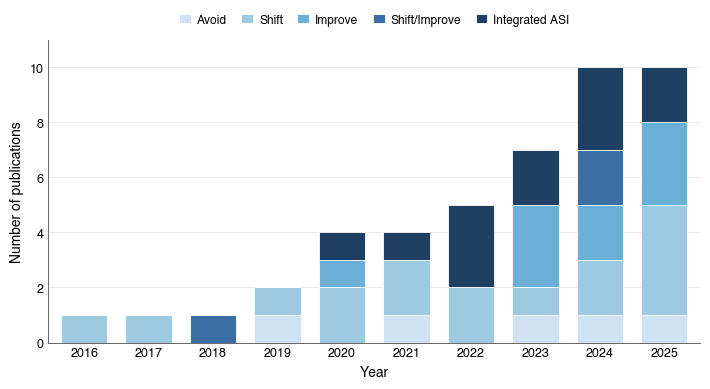

In [19]:
PILLARS = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]
BLUES   = ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#1f3f63"]

# ----------------------------------------------------------------------
# Temporal evolution of ASI passenger-transport publications, by pillar
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)
# Convertimos la columna a tipo numérico (los valores no válidos se convertirán a NaN)
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
# Ahora ya puedes calcular el mínimo y el máximo sin problema
yr0, yr1 = int(df["Year"].min()), int(df["Year"].max())
# Resto de tu código
M = (pd.crosstab(df["Year"], df["ASI focus"])
       .reindex(columns=PILLARS).fillna(0).astype(int)
       .reindex(range(yr0, yr1 + 1), fill_value=0))
years = M.index.tolist()


yr0, yr1 = int(df["Year"].min()), int(df["Year"].max())
M = (pd.crosstab(df["Year"], df["ASI focus"])
       .reindex(columns=PILLARS).fillna(0).astype(int)
       .reindex(range(yr0, yr1 + 1), fill_value=0))
years = M.index.tolist()

# Helvetica (falls back to Arial / sans if unavailable)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["axes.linewidth"] = 0.7

fig, ax = plt.subplots(figsize=(7.2, 4.0))

bottom = [0] * len(years)
for pillar, color in zip(PILLARS, BLUES):
    vals = M[pillar].values
    ax.bar(years, vals, bottom=bottom, width=0.72, label=pillar,
           color=color, edgecolor="white", linewidth=0.6)
    bottom = [b + v for b, v in zip(bottom, vals)]

ax.set_ylabel("Number of publications", fontsize=10)
ax.set_xlabel("Year", fontsize=10)
ax.set_xticks(years)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.tick_params(labelsize=9, length=0)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.spines["left"].set_color("0.4")
ax.spines["bottom"].set_color("0.4")
ax.grid(axis="y", color="0.90", linewidth=0.6)
ax.set_axisbelow(True)
ax.set_ylim(0, M.sum(axis=1).max() + 1)
ax.margins(x=0.02)

ax.legend(ncol=5, frameon=False, fontsize=8.6, handlelength=1.0,
          handletextpad=0.5, columnspacing=1.2,
          loc="lower center", bbox_to_anchor=(0.5, 1.01))

fig.tight_layout()
fig.savefig("fig_temporal_asi.pdf")           # vector, for submission
fig.savefig("fig_temporal_asi.png", dpi=300)  # raster preview
print("Saved fig_temporal_asi.pdf / .png")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Saved fig_temporal_asi.pdf / .png


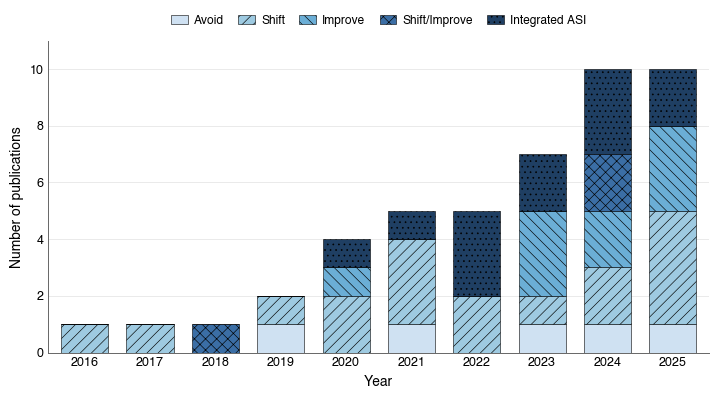

In [39]:
PILLARS = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]
BLUES   = ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#1f3f63"]
HATCHES = ["", "///", "\\\\\\", "xxx", "..."]   # densidad progresiva, un patrón por pilar

# ----------------------------------------------------------------------
# Temporal evolution of ASI passenger-transport publications, by pillar
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
yr0, yr1 = int(df["Year"].min()), int(df["Year"].max())

M = (pd.crosstab(df["Year"], df["ASI focus"])
       .reindex(columns=PILLARS).fillna(0).astype(int)
       .reindex(range(yr0, yr1 + 1), fill_value=0))
years = M.index.tolist()

# Helvetica (falls back to Arial / sans if unavailable)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["axes.linewidth"] = 0.7
plt.rcParams["hatch.linewidth"] = 0.45   # hatch fino, look editorial

fig, ax = plt.subplots(figsize=(7.2, 4.0))

bottom = [0] * len(years)
bars_for_legend = []
for pillar, color, hatch in zip(PILLARS, BLUES, HATCHES):
    vals = M[pillar].values
    bar = ax.bar(years, vals, bottom=bottom, width=0.72, label=pillar,
                 color=color, edgecolor="black", linewidth=0.4,
                 hatch=hatch)
    bars_for_legend.append(bar)
    bottom = [b + v for b, v in zip(bottom, vals)]

ax.set_ylabel("Number of publications", fontsize=10)
ax.set_xlabel("Year", fontsize=10)
ax.set_xticks(years)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.tick_params(labelsize=9, length=0)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.spines["left"].set_color("0.4")
ax.spines["bottom"].set_color("0.4")
ax.grid(axis="y", color="0.90", linewidth=0.6)
ax.set_axisbelow(True)
ax.set_ylim(0, M.sum(axis=1).max() + 1)
ax.margins(x=0.02)

leg = ax.legend(ncol=5, frameon=False, fontsize=8.6, handlelength=1.4,
                 handletextpad=0.5, columnspacing=1.2,
                 loc="lower center", bbox_to_anchor=(0.5, 1.01))
for patch in leg.get_patches():
    patch.set_linewidth(0.4)

fig.tight_layout()
fig.savefig("fig_temporal_asi.pdf")           # vector, for submission
fig.savefig("fig_temporal_asi.png", dpi=300)  # raster preview
print("Saved fig_temporal_asi.pdf / .png")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Saved fig_boundary_overview.pdf / .png con paleta semántica (gris/ámbar/azul)


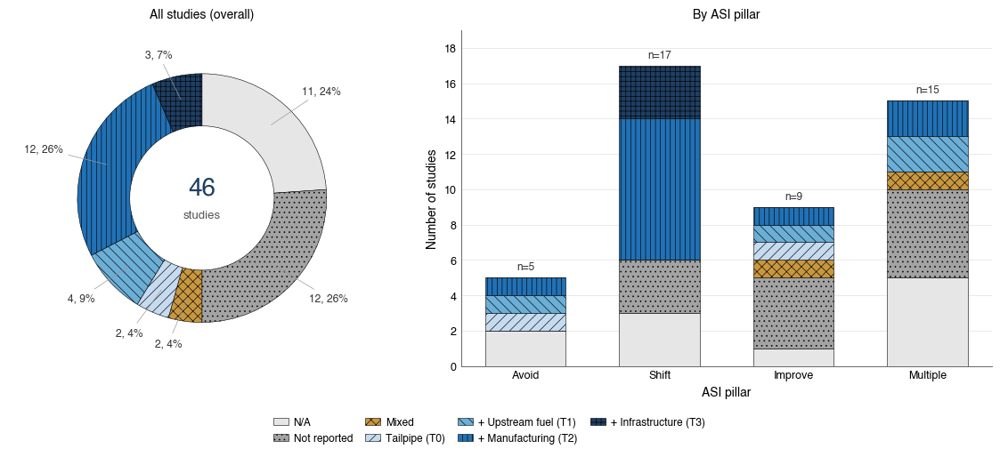

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import paper_style

# ---------------------------------------------------------------------------
# Configuración de estilo -- importada de paper_style.py para que sea
# IDÉNTICA, byte a byte, a la de fig_temporal_asi.pdf y fig_sankey_*.pdf
# (un único punto de verdad en vez de repetir el bloque en cada script)
# ---------------------------------------------------------------------------
paper_style.apply()
FIGSIZE = (11.5, 4.6)

# ---------------------------------------------------------------------------
# Paleta semántica (en vez de un único degradado "Blues" para las 7 tiers):
#
#   - N/A y NR (Not reported)  -> gris: son ausencias de información, no un
#     valor dentro de una escala. Meterlas en el mismo degradado azul que
#     T0-T3 sugeriría falsamente que "N/A" es "menos" que T0.
#   - Mixed                     -> acento ámbar mate: es la única categoría
#     que no encaja en el orden T0->T3 (el alcance varía dentro del propio
#     estudio). Azul-ámbar es además una combinación segura para
#     daltonismo rojo-verde (verificado con simulación deuteranopia/
#     protanopía: sigue siendo distinguible).
#   - T0 -> T3                 -> rampa azul secuencial real, porque esto SÍ
#     es un orden genuino (alcance creciente de la frontera del sistema).
#     El extremo más oscuro (#1f3f63) es el mismo azul "ancla" que ya usas
#     para "Integrated ASI" en el resto del paper, así que el lector asocia
#     "azul muy oscuro = máxima comprehensividad" de forma consistente en
#     todas las figuras.
#
# Los hatches se mantienen como canal redundante: incluso si dos colores
# quedan próximos bajo daltonismo o en fotocopia B/N, la trama los separa.
# ---------------------------------------------------------------------------
TIER_COLORS = {
    "N/A":   "#e6e6e6",   # gris muy claro -- no aplica
    "NR":    "#a3a3a3",   # gris medio -- no reportado
    "Mixed": "#c8973f",   # ámbar mate -- categoría atípica / no ordinal
    "T0":    "#c6dbef",   # alcance mínimo (tailpipe)
    "T1":    "#6baed6",
    "T2":    "#2171b5",
    "T3":    "#1f3f63",   # alcance máximo -- ancla cromática del paper
}

hatch_patterns = {
    "N/A":   "",
    "NR":    "...",
    "Mixed": "xxx",
    "T0":    "///",
    "T1":    "\\\\\\",
    "T2":    "|||",
    "T3":    "+++",
}

# ---------------------------------------------------------------------------
# Datos -- Supplementary Table S5
# ---------------------------------------------------------------------------
pillars = ["Avoid", "Shift", "Improve", "Multiple"]
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

data = {
    "Avoid":    {"N/A": 2, "NR": 0, "Mixed": 0, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Shift":    {"N/A": 3, "NR": 3, "Mixed": 0, "T0": 0, "T1": 0, "T2": 8, "T3": 3},
    "Improve":  {"N/A": 1, "NR": 4, "Mixed": 1, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Multiple": {"N/A": 5, "NR": 5, "Mixed": 1, "T0": 0, "T1": 2, "T2": 2, "T3": 0},
}

tier_labels = {
    "N/A": "N/A",
    "NR": "Not reported",
    "Mixed": "Mixed",
    "T0": "Tailpipe (T0)",
    "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)",
    "T3": "+ Infrastructure (T3)",
}

colors = [TIER_COLORS[t] for t in tiers]

totals = {t: sum(data[p][t] for p in pillars) for t in tiers}
grand_total = sum(totals.values())

# ---------------------------------------------------------------------------
# Gráfico
# ---------------------------------------------------------------------------
fig, (ax_donut, ax_bar) = plt.subplots(
    1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.3, 1.6]}
)

# --- Panel Izquierdo: Donut Overall ----------------------------------------
sizes = [totals[t] for t in tiers]
wedges, _ = ax_donut.pie(
    sizes,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.42, edgecolor="black", linewidth=0.4),
)
for wedge, tier in zip(wedges, tiers):
    wedge.set_hatch(hatch_patterns[tier])

# Anotaciones con porcentajes
for wedge, tier in zip(wedges, tiers):
    n = totals[tier]
    pct = 100 * n / grand_total
    ang = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    x_out, y_out = np.cos(ang), np.sin(ang)
    r_label = 1.18
    ha = "left" if x_out >= 0 else "right"
    ax_donut.annotate(
        f"{n}, {pct:.0f}%",
        xy=(0.79 * x_out, 0.79 * y_out),
        xytext=(r_label * x_out, r_label * y_out),
        ha=ha, va="center", fontsize=8.6, color="#333333",
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.5),
    )

ax_donut.text(0, 0.08, f"{grand_total}", ha="center", va="center",
              fontsize=20, fontweight="bold", color="#1F3F63")
ax_donut.text(0, -0.14, "studies", ha="center", va="center",
              fontsize=9.5, color="#555555")
ax_donut.set_title("All studies (overall)", fontsize=10, pad=10)
ax_donut.set_xlim(-1.55, 1.55)
ax_donut.set_ylim(-1.35, 1.35)
ax_donut.set_aspect("equal")

# --- Panel Derecho: Barras Apiladas por ASI pillar ------------------------
x = np.arange(len(pillars))
bottom = np.zeros(len(pillars))

for tier, color in zip(tiers, colors):
    values = np.array([data[p][tier] for p in pillars])
    ax_bar.bar(
        x, values, bottom=bottom, width=0.6,
        color=color, edgecolor="black", linewidth=0.4,
        hatch=hatch_patterns[tier],
        label=tier_labels[tier], zorder=3,
    )
    bottom += values

for xi, p in enumerate(pillars):
    total = sum(data[p].values())
    ax_bar.text(xi, bottom[xi] + 0.3, f"n={total}", ha="center", va="bottom",
                fontsize=8.6, color="#333333")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(pillars)
ax_bar.set_xlabel("ASI pillar", fontsize=10)
ax_bar.set_ylabel("Number of studies", fontsize=10)
ax_bar.set_ylim(0, max(bottom) + 2)
ax_bar.yaxis.set_major_locator(MaxNLocator(integer=True))

# Estilo de spines y grid coincidente con la figura temporal
for s in ["top", "right"]:
    ax_bar.spines[s].set_visible(False)
ax_bar.spines["left"].set_color("0.4")
ax_bar.spines["bottom"].set_color("0.4")

ax_bar.yaxis.grid(True, color="0.90", linewidth=0.6, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.tick_params(labelsize=9, length=0)
ax_bar.set_title("By ASI pillar", fontsize=10, pad=10)

# --- Leyenda compartida (Mismo tamaño y jerarquía) -----------------------
handles, labels = ax_bar.get_legend_handles_labels()
leg = fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 0.00),
    ncol=4, frameon=False, fontsize=8.6, handlelength=1.4,
    columnspacing=1.2, handletextpad=0.5,
)

for patch in leg.get_patches():
    patch.set_linewidth(0.4)

fig.tight_layout()
fig.savefig("fig_boundary_overview.pdf", bbox_inches="tight")
fig.savefig("fig_boundary_overview.png", dpi=300, bbox_inches="tight")
print("Saved fig_boundary_overview.pdf / .png con paleta semántica (gris/ámbar/azul)")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Saved fig_boundary_overview.pdf / .png con paleta semántica (gris/ámbar/azul)


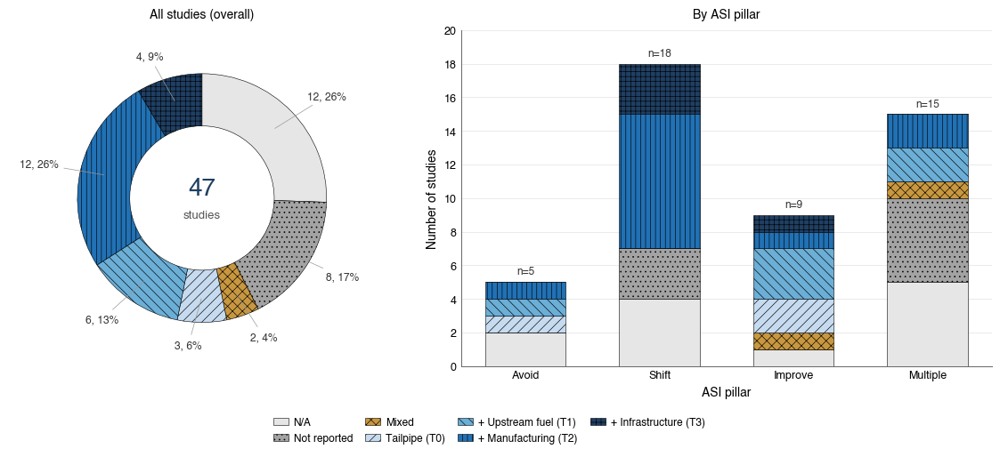

In [23]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import paper_style

# ---------------------------------------------------------------------------
# Configuración de estilo -- importada de paper_style.py para que sea
# IDÉNTICA, byte a byte, a la de fig_temporal_asi.pdf y fig_sankey_*.pdf
# (un único punto de verdad en vez de repetir el bloque en cada script)
# ---------------------------------------------------------------------------
paper_style.apply()
FIGSIZE = (11.5, 4.6)

# ---------------------------------------------------------------------------
# Paleta semántica (en vez de un único degradado "Blues" para las 7 tiers):
#
#   - N/A y NR (Not reported)  -> gris: son ausencias de información, no un
#     valor dentro de una escala. Meterlas en el mismo degradado azul que
#     T0-T3 sugeriría falsamente que "N/A" es "menos" que T0.
#   - Mixed                     -> acento ámbar mate: es la única categoría
#     que no encaja en el orden T0->T3 (el alcance varía dentro del propio
#     estudio). Azul-ámbar es además una combinación segura para
#     daltonismo rojo-verde (verificado con simulación deuteranopia/
#     protanopía: sigue siendo distinguible).
#   - T0 -> T3                 -> rampa azul secuencial real, porque esto SÍ
#     es un orden genuino (alcance creciente de la frontera del sistema).
#     El extremo más oscuro (#1f3f63) es el mismo azul "ancla" que ya usas
#     para "Integrated ASI" en el resto del paper, así que el lector asocia
#     "azul muy oscuro = máxima comprehensividad" de forma consistente en
#     todas las figuras.
#
# Los hatches se mantienen como canal redundante: incluso si dos colores
# quedan próximos bajo daltonismo o en fotocopia B/N, la trama los separa.
# ---------------------------------------------------------------------------
TIER_COLORS = {
    "N/A":   "#e6e6e6",   # gris muy claro -- no aplica
    "NR":    "#a3a3a3",   # gris medio -- no reportado
    "Mixed": "#c8973f",   # ámbar mate -- categoría atípica / no ordinal
    "T0":    "#c6dbef",   # alcance mínimo (tailpipe)
    "T1":    "#6baed6",
    "T2":    "#2171b5",
    "T3":    "#1f3f63",   # alcance máximo -- ancla cromática del paper
}

hatch_patterns = {
    "N/A":   "",
    "NR":    "...",
    "Mixed": "xxx",
    "T0":    "///",
    "T1":    "\\\\\\",
    "T2":    "|||",
    "T3":    "+++",
}

# ---------------------------------------------------------------------------
# Datos -- Supplementary Table S5 (recuento actualizado tras la revisión
# metodológica de las carpetas Avoid / Shift / Improve / Multiple)
# ---------------------------------------------------------------------------
pillars = ["Avoid", "Shift", "Improve", "Multiple"]
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

data = {
    # Avoid (5): plaza-herrera N/A, Jarboui2024 T0, costa_decarbonisation T2,
    # arnz_sufficiency T1, GOSSLING N/A
    "Avoid":    {"N/A": 2, "NR": 0, "Mixed": 0, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    # Shift (18): 3xT3, 8xT2, 3xNR (Rerat2021, zhu_data-driven, fatorachian),
    # 4xN/A (sifuentes-munoz, katar_promoting, yang_navigating, militao)
    "Shift":    {"N/A": 4, "NR": 3, "Mixed": 0, "T0": 0, "T1": 0, "T2": 8, "T3": 3},
    # Improve (10): alarfaj T1, winkler T3, muessel T1, vallarta-serrano T0,
    # rogge N/A, steininger T0, lee Mixed, hossain T1, luo T2, de_rosa N/A
    "Improve":  {"N/A": 1, "NR": 0, "Mixed": 1, "T0": 2, "T1": 3, "T2": 1, "T3": 1},
    # Multiple (15): 5xN/A, 5xNR, 1xMixed (creutzig), 2xT1, 2xT2
    "Multiple": {"N/A": 5, "NR": 5, "Mixed": 1, "T0": 0, "T1": 2, "T2": 2, "T3": 0},
}

tier_labels = {
    "N/A": "N/A",
    "NR": "Not reported",
    "Mixed": "Mixed",
    "T0": "Tailpipe (T0)",
    "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)",
    "T3": "+ Infrastructure (T3)",
}

colors = [TIER_COLORS[t] for t in tiers]

totals = {t: sum(data[p][t] for p in pillars) for t in tiers}
grand_total = sum(totals.values())

# ---------------------------------------------------------------------------
# Gráfico
# ---------------------------------------------------------------------------
fig, (ax_donut, ax_bar) = plt.subplots(
    1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.3, 1.6]}
)

# --- Panel Izquierdo: Donut Overall ----------------------------------------
sizes = [totals[t] for t in tiers]
wedges, _ = ax_donut.pie(
    sizes,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.42, edgecolor="black", linewidth=0.4),
)
for wedge, tier in zip(wedges, tiers):
    wedge.set_hatch(hatch_patterns[tier])

# Anotaciones con porcentajes
for wedge, tier in zip(wedges, tiers):
    n = totals[tier]
    pct = 100 * n / grand_total
    ang = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    x_out, y_out = np.cos(ang), np.sin(ang)
    r_label = 1.18
    ha = "left" if x_out >= 0 else "right"
    ax_donut.annotate(
        f"{n}, {pct:.0f}%",
        xy=(0.79 * x_out, 0.79 * y_out),
        xytext=(r_label * x_out, r_label * y_out),
        ha=ha, va="center", fontsize=8.6, color="#333333",
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.5),
    )

ax_donut.text(0, 0.08, f"{grand_total}", ha="center", va="center",
              fontsize=20, fontweight="bold", color="#1F3F63")
ax_donut.text(0, -0.14, "studies", ha="center", va="center",
              fontsize=9.5, color="#555555")
ax_donut.set_title("All studies (overall)", fontsize=10, pad=10)
ax_donut.set_xlim(-1.55, 1.55)
ax_donut.set_ylim(-1.35, 1.35)
ax_donut.set_aspect("equal")

# --- Panel Derecho: Barras Apiladas por ASI pillar ------------------------
x = np.arange(len(pillars))
bottom = np.zeros(len(pillars))

for tier, color in zip(tiers, colors):
    values = np.array([data[p][tier] for p in pillars])
    ax_bar.bar(
        x, values, bottom=bottom, width=0.6,
        color=color, edgecolor="black", linewidth=0.4,
        hatch=hatch_patterns[tier],
        label=tier_labels[tier], zorder=3,
    )
    bottom += values

for xi, p in enumerate(pillars):
    total = sum(data[p].values())
    ax_bar.text(xi, bottom[xi] + 0.3, f"n={total}", ha="center", va="bottom",
                fontsize=8.6, color="#333333")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(pillars)
ax_bar.set_xlabel("ASI pillar", fontsize=10)
ax_bar.set_ylabel("Number of studies", fontsize=10)
ax_bar.set_ylim(0, max(bottom) + 2)
ax_bar.yaxis.set_major_locator(MaxNLocator(integer=True))

# Estilo de spines y grid coincidente con la figura temporal
for s in ["top", "right"]:
    ax_bar.spines[s].set_visible(False)
ax_bar.spines["left"].set_color("0.4")
ax_bar.spines["bottom"].set_color("0.4")

ax_bar.yaxis.grid(True, color="0.90", linewidth=0.6, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.tick_params(labelsize=9, length=0)
ax_bar.set_title("By ASI pillar", fontsize=10, pad=10)

# --- Leyenda compartida (Mismo tamaño y jerarquía) -----------------------
handles, labels = ax_bar.get_legend_handles_labels()
leg = fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 0.00),
    ncol=4, frameon=False, fontsize=8.6, handlelength=1.4,
    columnspacing=1.2, handletextpad=0.5,
)

for patch in leg.get_patches():
    patch.set_linewidth(0.4)

fig.tight_layout()
fig.savefig("fig_boundary_overview.pdf", bbox_inches="tight")
fig.savefig("fig_boundary_overview.png", dpi=300, bbox_inches="tight")
print("Saved fig_boundary_overview.pdf / .png con paleta semántica (gris/ámbar/azul)")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Saved fig_boundary_overview.pdf / .png con paleta semántica (gris/ámbar/azul)


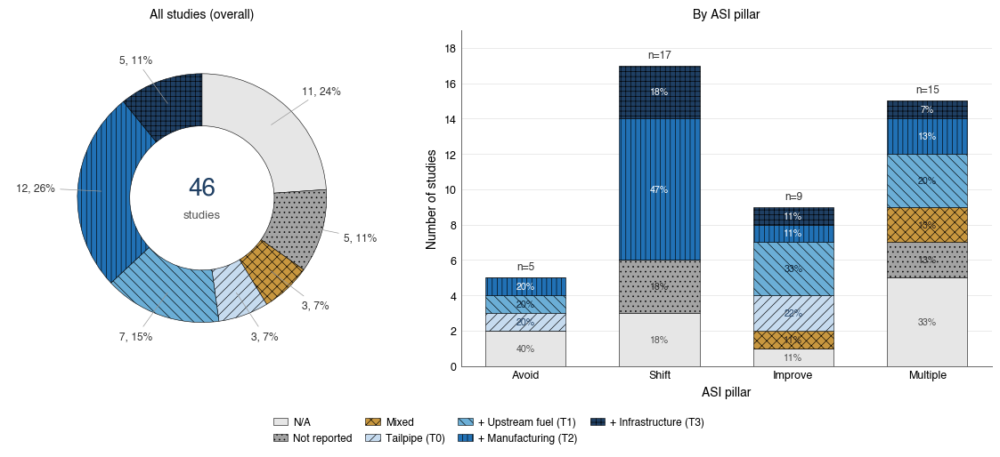

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import paper_style

# ---------------------------------------------------------------------------
# Configuración de estilo -- importada de paper_style.py para que sea
# IDÉNTICA, byte a byte, a la de fig_temporal_asi.pdf y fig_sankey_*.pdf
# (un único punto de verdad en vez de repetir el bloque en cada script)
# ---------------------------------------------------------------------------
paper_style.apply()
FIGSIZE = (11.5, 4.6)

# ---------------------------------------------------------------------------
# Paleta semántica (en vez de un único degradado "Blues" para las 7 tiers):
#
#   - N/A y NR (Not reported)  -> gris: son ausencias de información, no un
#     valor dentro de una escala. Meterlas en el mismo degradado azul que
#     T0-T3 sugeriría falsamente que "N/A" es "menos" que T0.
#   - Mixed                     -> acento ámbar mate: es la única categoría
#     que no encaja en el orden T0->T3 (el alcance varía dentro del propio
#     estudio). Azul-ámbar es además una combinación segura para
#     daltonismo rojo-verde (verificado con simulación deuteranopia/
#     protanopía: sigue siendo distinguible).
#   - T0 -> T3                 -> rampa azul secuencial real, porque esto SÍ
#     es un orden genuino (alcance creciente de la frontera del sistema).
#     El extremo más oscuro (#1f3f63) es el mismo azul "ancla" que ya usas
#     para "Integrated ASI" en el resto del paper, así que el lector asocia
#     "azul muy oscuro = máxima comprehensividad" de forma consistente en
#     todas las figuras.
#
# Los hatches se mantienen como canal redundante: incluso si dos colores
# quedan próximos bajo daltonismo o en fotocopia B/N, la trama los separa.
# ---------------------------------------------------------------------------
TIER_COLORS = {
    "N/A":   "#e6e6e6",   # gris muy claro -- no aplica
    "NR":    "#a3a3a3",   # gris medio -- no reportado
    "Mixed": "#c8973f",   # ámbar mate -- categoría atípica / no ordinal
    "T0":    "#c6dbef",   # alcance mínimo (tailpipe)
    "T1":    "#6baed6",
    "T2":    "#2171b5",
    "T3":    "#1f3f63",   # alcance máximo -- ancla cromática del paper
}

hatch_patterns = {
    "N/A":   "",
    "NR":    "...",
    "Mixed": "xxx",
    "T0":    "///",
    "T1":    "\\\\\\",
    "T2":    "|||",
    "T3":    "+++",
}

# ---------------------------------------------------------------------------
# Datos -- Supplementary Table S5 (recuento actualizado tras la revisión
# metodológica de las carpetas Avoid / Shift / Improve / Multiple)
# ---------------------------------------------------------------------------
pillars = ["Avoid", "Shift", "Improve", "Multiple"]
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

data = {
    # Avoid (5): plaza-herrera N/A, Jarboui2024 T0, costa_decarbonisation T2,
    # arnz_sufficiency T1, GOSSLING N/A
    "Avoid":    {"N/A": 2, "NR": 0, "Mixed": 0, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    # Shift (18): 3xT3, 8xT2, 3xNR (Rerat2021, zhu_data-driven, fatorachian),
    # 4xN/A (sifuentes-munoz, katar_promoting, yang_navigating, militao)
    "Shift":    {"N/A": 3, "NR": 3, "Mixed": 0, "T0": 0, "T1": 0, "T2": 8, "T3": 3},
    # Improve (10): alarfaj T1, winkler T3, muessel T1, vallarta-serrano T0,
    # rogge N/A, steininger T0, lee Mixed, hossain T1, luo T2, de_rosa N/A
    "Improve":  {"N/A": 1, "NR": 0, "Mixed": 1, "T0": 2, "T1": 3, "T2": 1, "T3": 1},
    # Multiple (15): 5xN/A, 5xNR, 1xMixed (creutzig), 2xT1, 2xT2
    "Multiple": {"N/A": 5, "NR": 2, "Mixed": 2, "T0": 0, "T1": 3, "T2": 2, "T3": 1},
}

tier_labels = {
    "N/A": "N/A",
    "NR": "Not reported",
    "Mixed": "Mixed",
    "T0": "Tailpipe (T0)",
    "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)",
    "T3": "+ Infrastructure (T3)",
}

# Color de texto por tier, elegido para contraste legible sobre cada color
# de fondo (blanco sobre los azules oscuros T2/T3, gris oscuro en el resto).
TEXT_ON_TIER = {
    "N/A":   "#4d4d4d",
    "NR":    "#2b2b2b",
    "Mixed": "#2b2321",
    "T0":    "#1f3f63",
    "T1":    "#0d2438",
    "T2":    "#ffffff",
    "T3":    "#ffffff",
}

# Umbral mínimo (en nº de estudios) por debajo del cual no se dibuja la
# etiqueta de porcentaje dentro del segmento, para evitar texto ilegible
# amontonado en franjas casi invisibles.
MIN_SEGMENT_FOR_LABEL = 1

colors = [TIER_COLORS[t] for t in tiers]

totals = {t: sum(data[p][t] for p in pillars) for t in tiers}
grand_total = sum(totals.values())

# ---------------------------------------------------------------------------
# Gráfico
# ---------------------------------------------------------------------------
fig, (ax_donut, ax_bar) = plt.subplots(
    1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.3, 1.6]}
)

# --- Panel Izquierdo: Donut Overall ----------------------------------------
sizes = [totals[t] for t in tiers]
wedges, _ = ax_donut.pie(
    sizes,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.42, edgecolor="black", linewidth=0.4),
)
for wedge, tier in zip(wedges, tiers):
    wedge.set_hatch(hatch_patterns[tier])

# Anotaciones con porcentajes
for wedge, tier in zip(wedges, tiers):
    n = totals[tier]
    pct = 100 * n / grand_total
    ang = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    x_out, y_out = np.cos(ang), np.sin(ang)
    r_label = 1.18
    ha = "left" if x_out >= 0 else "right"
    ax_donut.annotate(
        f"{n}, {pct:.0f}%",
        xy=(0.79 * x_out, 0.79 * y_out),
        xytext=(r_label * x_out, r_label * y_out),
        ha=ha, va="center", fontsize=8.6, color="#333333",
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.5),
    )

ax_donut.text(0, 0.08, f"{grand_total}", ha="center", va="center",
              fontsize=20, fontweight="bold", color="#1F3F63")
ax_donut.text(0, -0.14, "studies", ha="center", va="center",
              fontsize=9.5, color="#555555")
ax_donut.set_title("All studies (overall)", fontsize=10, pad=10)
ax_donut.set_xlim(-1.55, 1.55)
ax_donut.set_ylim(-1.35, 1.35)
ax_donut.set_aspect("equal")

# --- Panel Derecho: Barras Apiladas por ASI pillar ------------------------
x = np.arange(len(pillars))
bottom = np.zeros(len(pillars))
pillar_totals = np.array([sum(data[p].values()) for p in pillars])

for tier, color in zip(tiers, colors):
    values = np.array([data[p][tier] for p in pillars])
    ax_bar.bar(
        x, values, bottom=bottom, width=0.6,
        color=color, edgecolor="black", linewidth=0.4,
        hatch=hatch_patterns[tier],
        label=tier_labels[tier], zorder=3,
    )

    # Etiqueta de % dentro de cada segmento, calculado sobre el total de
    # ESE pillar (Avoid/Shift/Improve/Multiple), no sobre el total general.
    for xi, value in enumerate(values):
        if value >= MIN_SEGMENT_FOR_LABEL:
            pct = 100 * value / pillar_totals[xi]
            seg_center = bottom[xi] + value / 2
            ax_bar.text(
                xi, seg_center, f"{pct:.0f}%",
                ha="center", va="center",
                fontsize=7.6, color=TEXT_ON_TIER[tier],
                zorder=4,
            )

    bottom += values

for xi, p in enumerate(pillars):
    total = sum(data[p].values())
    ax_bar.text(xi, bottom[xi] + 0.3, f"n={total}", ha="center", va="bottom",
                fontsize=8.6, color="#333333")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(pillars)
ax_bar.set_xlabel("ASI pillar", fontsize=10)
ax_bar.set_ylabel("Number of studies", fontsize=10)
ax_bar.set_ylim(0, max(bottom) + 2)
ax_bar.yaxis.set_major_locator(MaxNLocator(integer=True))

# Estilo de spines y grid coincidente con la figura temporal
for s in ["top", "right"]:
    ax_bar.spines[s].set_visible(False)
ax_bar.spines["left"].set_color("0.4")
ax_bar.spines["bottom"].set_color("0.4")

ax_bar.yaxis.grid(True, color="0.90", linewidth=0.6, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.tick_params(labelsize=9, length=0)
ax_bar.set_title("By ASI pillar", fontsize=10, pad=10)

# --- Leyenda compartida (Mismo tamaño y jerarquía) -----------------------
handles, labels = ax_bar.get_legend_handles_labels()
leg = fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 0.00),
    ncol=4, frameon=False, fontsize=8.6, handlelength=1.4,
    columnspacing=1.2, handletextpad=0.5,
)

for patch in leg.get_patches():
    patch.set_linewidth(0.4)

fig.tight_layout()
fig.savefig("fig_boundary_overview.pdf", bbox_inches="tight")
fig.savefig("fig_boundary_overview.png", dpi=300, bbox_inches="tight")
print("Saved fig_boundary_overview.pdf / .png con paleta semántica (gris/ámbar/azul)")

In [1]:

blue_shades = [cmap(0.15 + 0.75 * i / (N_TIERS - 1)) for i in range(N_TIERS)]

# Nature-portfolio-style hatch patterns, one per boundary tier, layered on top of
# the color fill so categories remain distinguishable in grayscale/B&W print and
# for colorblind readers, not only through hue.
hatch_patterns = {
    "N/A":   "",
    "NR":    "...",
    "Mixed": "xxx",
    "T0":    "///",
    "T1":    "\\\\\\",
    "T2":    "|||",
    "T3":    "+++",
}
HATCH_COLOR = "#404040"  # dark gray hatch/edge color for contrast on both light and dark fills

# ---------------------------------------------------------------------------
# Data -- from Supplementary Table S5, cross-tabulated by primary ASI pillar
# ---------------------------------------------------------------------------
pillars = ["Avoid", "Shift", "Improve", "Multiple"]
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

data = {
    "Avoid":    {"N/A": 2, "NR": 0, "Mixed": 0, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Shift":    {"N/A": 3, "NR": 3, "Mixed": 0, "T0": 0, "T1": 0, "T2": 8, "T3": 3},
    "Improve":  {"N/A": 1, "NR": 4, "Mixed": 1, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Multiple": {"N/A": 5, "NR": 5, "Mixed": 1, "T0": 0, "T1": 2, "T2": 2, "T3": 0},
}

tier_labels = {
    "N/A": "N/A",
    "NR": "Not reported",
    "Mixed": "Mixed",
    "T0": "Tailpipe (T0)",
    "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)",
    "T3": "+ Infrastructure (T3)",
}

# Overall totals across the whole corpus (for the donut panel)
totals = {t: sum(data[p][t] for p in pillars) for t in tiers}
grand_total = sum(totals.values())

# ---------------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------------
fig, (ax_donut, ax_bar) = plt.subplots(
    1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.3, 1.6]}
)

# --- Left panel: donut of overall boundary-tier distribution -----------------
sizes = [totals[t] for t in tiers]
wedges, _ = ax_donut.pie(
    sizes,
    colors=blue_shades,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.42, edgecolor=HATCH_COLOR, linewidth=0.8),
)
for wedge, tier in zip(wedges, tiers):
    wedge.set_hatch(hatch_patterns[tier])

# count + % label for each wedge, placed just outside the donut ring with a leader line
for wedge, tier in zip(wedges, tiers):
    n = totals[tier]
    pct = 100 * n / grand_total
    ang = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    x_out, y_out = np.cos(ang), np.sin(ang)
    # anchor point on the outer edge of the ring, label placed further out
    r_label = 1.18
    ha = "left" if x_out >= 0 else "right"
    ax_donut.annotate(
        f"{n}, {pct:.0f}%",
        xy=(0.79 * x_out, 0.79 * y_out),
        xytext=(r_label * x_out, r_label * y_out),
        ha=ha, va="center", fontsize=8.5, color="#333333",
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.6),
    )

ax_donut.text(0, 0.08, f"{grand_total}", ha="center", va="center",
              fontsize=22, fontweight="bold", color="#1F3F63")
ax_donut.text(0, -0.14, "studies", ha="center", va="center",
              fontsize=10.5, color="#555555")
ax_donut.set_title("All studies (overall)", fontsize=11, pad=10)
ax_donut.set_xlim(-1.55, 1.55)
ax_donut.set_ylim(-1.35, 1.35)
ax_donut.set_aspect("equal")

# --- Right panel: stacked bars by ASI pillar --------------------------------
x = np.arange(len(pillars))
bottom = np.zeros(len(pillars))

for tier, color in zip(tiers, blue_shades):
    values = np.array([data[p][tier] for p in pillars])
    ax_bar.bar(
        x, values, bottom=bottom, width=0.6,
        color=color, edgecolor=HATCH_COLOR, linewidth=0.6,
        hatch=hatch_patterns[tier],
        label=tier_labels[tier], zorder=3,
    )
    bottom += values

for xi, p in enumerate(pillars):
    total = sum(data[p].values())
    ax_bar.text(xi, bottom[xi] + 0.3, f"n={total}", ha="center", va="bottom",
                fontsize=9, color="#333333")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(pillars)
ax_bar.set_xlabel("ASI pillar")
ax_bar.set_ylabel("Number of studies")
ax_bar.set_ylim(0, max(bottom) + 2)
ax_bar.yaxis.set_major_locator(MaxNLocator(integer=True))

ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.yaxis.grid(True, color="#e5e5e5", linewidth=0.8, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.tick_params(axis="both", which="both", length=3, color="#666666")
ax_bar.set_title("By ASI pillar", fontsize=11, pad=10)

# --- Shared legend, one row set above both panels ---------------------------
handles, labels = ax_bar.get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 1.14),
    ncol=4, frameon=False, fontsize=9, handlelength=1.3,
    columnspacing=1.0, handletextpad=0.4,
)

fig.tight_layout()
fig.savefig("fig_boundary_overview.pdf", bbox_inches="tight")
fig.savefig("fig_boundary_overview.png", dpi=200, bbox_inches="tight")
print("Saved fig_boundary_overview.pdf / .png")

NameError: name 'N_TIERS' is not defined

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Guardado: fig_sankey_hatched.pdf / fig_sankey_hatched.png


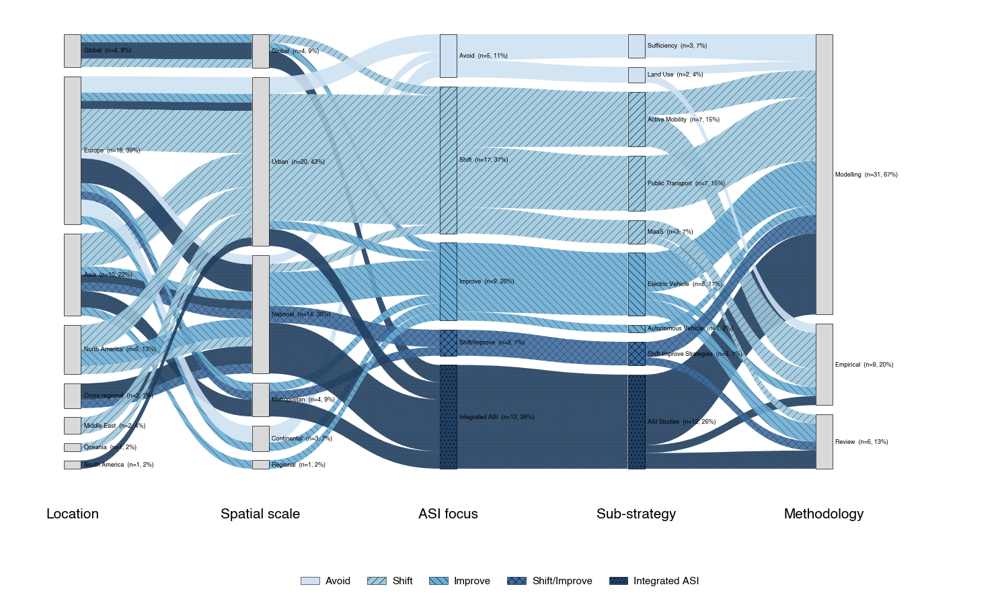

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
import matplotlib.patches as mpatches
from collections import defaultdict

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta y hatches -- IDÉNTICOS al gráfico de barras temporal
# ----------------------------------------------------------------------
PILLARS = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]
PILLAR_COLORS = dict(zip(PILLARS, ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#1f3f63"]))
PILLAR_HATCHES = dict(zip(PILLARS, ["", "///", "\\\\\\", "xxx", "..."]))
NEUTRAL_NODE_COLOR = "#d9d9d9"

SUBSTRATEGY_TO_STRATEGY = {
    "Sufficiency": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI",
}

# ----------------------------------------------------------------------
# 3. Orden estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

order_col2 = PILLARS

order_col3 = [
    "Sufficiency", "Land Use", "Active Mobility", "Public Transport", "MaaS",
    "Electric Vehicle", "Autonomous Vehicle", "Shift-Improve Strategies", "ASI Studies",
]

order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")

# ----------------------------------------------------------------------
# 4. Geometría de nodos (y=0 arriba, y=1 abajo; se invierte el eje al graficar)
# ----------------------------------------------------------------------
node_label, node_x, node_top, node_bot = [], [], [], []
node_color, node_hatch, node_id = [], [], {}
GAP, Y_PAD = 0.02, 0.03

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD

    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        top, bot = y_cursor, y_cursor + height

        node_id[(stage_i, cat)] = len(node_label)
        node_label.append(f"{cat}  (n={cnt}, {pct}%)")
        node_x.append(stage_i)
        node_top.append(top)
        node_bot.append(bot)

        if stage_i == ASI_STAGE_INDEX:
            pillar = cat
        elif stage_i == THEME_STAGE_INDEX:
            pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)
        else:
            pillar = None

        node_color.append(PILLAR_COLORS.get(pillar, NEUTRAL_NODE_COLOR))
        node_hatch.append(PILLAR_HATCHES.get(pillar, ""))

        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados/hatcheados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_pillar = [], [], [], []

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    # dict.fromkeys evita duplicar la columna cuando col_a o col_b ya ES "ASI focus"
    group_cols = list(dict.fromkeys([col_a, col_b, "ASI focus"]))
    grouped = df_complete.groupby(group_cols).size().reset_index(name="count")

    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["ASI focus"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_pillar.append(pillar)

# ----------------------------------------------------------------------
# 6. Sub-alturas de flujos dentro de cada nodo (evita solapes)
# ----------------------------------------------------------------------
node_out, node_in = defaultdict(list), defaultdict(list)
for li, (s, t) in enumerate(zip(link_source, link_target)):
    node_out[s].append(li)
    node_in[t].append(li)

node_y_center = [(top + bot) / 2 for top, bot in zip(node_top, node_bot)]
for idx in node_out:
    node_out[idx].sort(key=lambda li: node_y_center[link_target[li]])
for idx in node_in:
    node_in[idx].sort(key=lambda li: node_y_center[link_source[li]])

link_src_range, link_tgt_range = {}, {}
for idx in range(len(node_label)):
    top, bot = node_top[idx], node_bot[idx]
    height = bot - top

    outs = node_out.get(idx, [])
    tot_out = sum(link_value[li] for li in outs) or 1
    cur = top
    for li in outs:
        h = (link_value[li] / tot_out) * height
        link_src_range[li] = (cur, cur + h)
        cur += h

    ins = node_in.get(idx, [])
    tot_in = sum(link_value[li] for li in ins) or 1
    cur = top
    for li in ins:
        h = (link_value[li] / tot_in) * height
        link_tgt_range[li] = (cur, cur + h)
        cur += h

# ----------------------------------------------------------------------
# 7. Dibujo (Sankey 100% matplotlib: mismo motor de hatch que las barras)
# ----------------------------------------------------------------------
def sankey_ribbon(x0, x1, y0_top, y0_bot, y1_top, y1_bot, **kw):
    """Cinta de flujo con curvas Bezier cúbicas (estilo D3/Plotly Sankey)."""
    xm = (x0 + x1) / 2.0
    verts = [
        (x0, y0_top),
        (xm, y0_top), (xm, y1_top), (x1, y1_top),
        (x1, y1_bot),
        (xm, y1_bot), (xm, y0_bot), (x0, y0_bot),
        (x0, y0_top),
    ]
    codes = [Path.MOVETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.LINETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.CLOSEPOLY]
    return PathPatch(Path(verts, codes), **kw)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["hatch.linewidth"] = 0.45
plt.rcParams["pdf.fonttype"] = 42   # fuentes embebidas correctamente en el PDF

N_STAGES = len(STAGE_COL)
fig, ax = plt.subplots(figsize=(15, 9))
NODE_W = 0.09

# 7.1 Flujos primero (quedan debajo de los nodos)
for li in range(len(link_source)):
    s, t = link_source[li], link_target[li]
    pillar = link_pillar[li]
    y0_top, y0_bot = link_src_range[li]
    y1_top, y1_bot = link_tgt_range[li]
    x0 = node_x[s] + NODE_W / 2
    x1 = node_x[t] - NODE_W / 2
    patch = sankey_ribbon(
        x0, x1, y0_top, y0_bot, y1_top, y1_bot,
        facecolor=PILLAR_COLORS[pillar], edgecolor="0.25", linewidth=0.0,
        hatch=PILLAR_HATCHES[pillar], alpha=0.9, zorder=1,
        
    )
    ax.add_patch(patch)

# 7.2 Nodos encima
for idx in range(len(node_label)):
    x = node_x[idx]
    rect = Rectangle(
        (x - NODE_W / 2, node_top[idx]), NODE_W, node_bot[idx] - node_top[idx],
        facecolor=node_color[idx], edgecolor="black", linewidth=0.5,
        hatch=node_hatch[idx], zorder=2,
    )
    ax.add_patch(rect)
    ax.text(x + NODE_W / 2 + 0.015, (node_top[idx] + node_bot[idx]) / 2, node_label[idx],
            fontsize=6.5, va="center", ha="left", zorder=3)

# 7.3 Titulos de columna -- Helvetica bold, en la parte inferior del diagrama
TITLE_Y = 1.055
for i, title in enumerate(STAGE_TITLES):
    ax.text(i, TITLE_Y, title, fontsize=FS_TITLE,
            fontweight="bold", ha="center", va="top")

ax.set_xlim(-0.35, N_STAGES - 1 + 0.9)
ax.set_ylim(-0.03, 1.16)
ax.invert_yaxis()
ax.axis("off")

# 7.4 Leyenda de pilares -- misma intensidad de color/hatch, debajo de los titulos
legend_handles = [
    mpatches.Patch(facecolor=PILLAR_COLORS[p], edgecolor="black", linewidth=0.4,
                   hatch=PILLAR_HATCHES[p], label=p)
    for p in PILLARS
]
ax.legend(handles=legend_handles, ncol=5, frameon=False, fontsize=FS_LEGEND,
          loc="upper center", bbox_to_anchor=(0.5, -0.02), handlelength=1.8,
          handletextpad=0.6, columnspacing=1.6)

fig.tight_layout()
fig.savefig("fig_sankey_hatched.pdf")
fig.savefig("fig_sankey_hatched.png", dpi=300)
print("Guardado: fig_sankey_hatched.pdf / fig_sankey_hatched.png")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Guardado: fig_sankey_hatched.pdf / fig_sankey_hatched.png


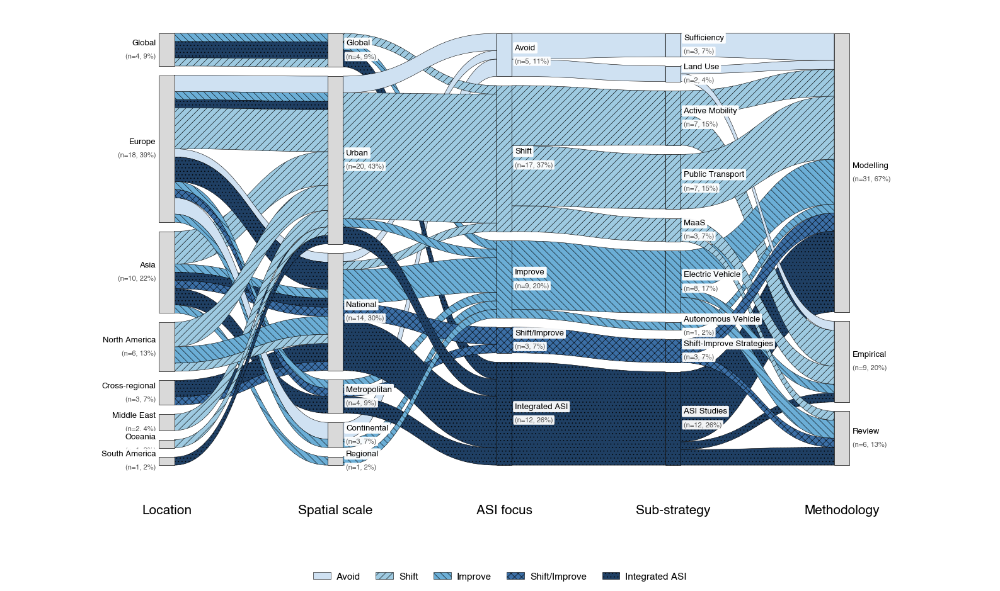

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
import matplotlib.patches as mpatches
from collections import defaultdict

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
    "Germany, California (USA)": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta y hatches -- IDÉNTICOS al gráfico de barras temporal
# ----------------------------------------------------------------------
PILLARS = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]
PILLAR_COLORS = dict(zip(PILLARS, ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#1f3f63"]))
PILLAR_HATCHES = dict(zip(PILLARS, ["", "///", "\\\\\\", "xxx", "..."]))
NEUTRAL_NODE_COLOR = "#d9d9d9"

SUBSTRATEGY_TO_STRATEGY = {
    "Sufficiency": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI",
}

# ----------------------------------------------------------------------
# 3. Orden estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

order_col2 = PILLARS

order_col3 = [
    "Sufficiency", "Land Use", "Active Mobility", "Public Transport", "MaaS",
    "Electric Vehicle", "Autonomous Vehicle", "Shift-Improve Strategies", "ASI Studies",
]

order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")

# ----------------------------------------------------------------------
# 4. Geometría de nodos (y=0 arriba, y=1 abajo; se invierte el eje al graficar)
# ----------------------------------------------------------------------
node_label, node_sub, node_x, node_top, node_bot = [], [], [], [], []
node_color, node_hatch, node_id = [], [], {}
GAP, Y_PAD = 0.02, 0.03

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD

    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        top, bot = y_cursor, y_cursor + height

        node_id[(stage_i, cat)] = len(node_label)
        node_label.append(cat)
        node_sub.append(f"(n={cnt}, {pct}%)")
        node_x.append(stage_i)
        node_top.append(top)
        node_bot.append(bot)

        if stage_i == ASI_STAGE_INDEX:
            pillar = cat
        elif stage_i == THEME_STAGE_INDEX:
            pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)
        else:
            pillar = None

        node_color.append(PILLAR_COLORS.get(pillar, NEUTRAL_NODE_COLOR))
        node_hatch.append(PILLAR_HATCHES.get(pillar, ""))

        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados/hatcheados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_pillar = [], [], [], []

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    # dict.fromkeys evita duplicar la columna cuando col_a o col_b ya ES "ASI focus"
    group_cols = list(dict.fromkeys([col_a, col_b, "ASI focus"]))
    grouped = df_complete.groupby(group_cols).size().reset_index(name="count")

    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["ASI focus"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_pillar.append(pillar)

# ----------------------------------------------------------------------
# 6. Sub-alturas de flujos dentro de cada nodo (evita solapes)
# ----------------------------------------------------------------------
node_out, node_in = defaultdict(list), defaultdict(list)
for li, (s, t) in enumerate(zip(link_source, link_target)):
    node_out[s].append(li)
    node_in[t].append(li)

node_y_center = [(top + bot) / 2 for top, bot in zip(node_top, node_bot)]
for idx in node_out:
    node_out[idx].sort(key=lambda li: node_y_center[link_target[li]])
for idx in node_in:
    node_in[idx].sort(key=lambda li: node_y_center[link_source[li]])

link_src_range, link_tgt_range = {}, {}
for idx in range(len(node_label)):
    top, bot = node_top[idx], node_bot[idx]
    height = bot - top

    outs = node_out.get(idx, [])
    tot_out = sum(link_value[li] for li in outs) or 1
    cur = top
    for li in outs:
        h = (link_value[li] / tot_out) * height
        link_src_range[li] = (cur, cur + h)
        cur += h

    ins = node_in.get(idx, [])
    tot_in = sum(link_value[li] for li in ins) or 1
    cur = top
    for li in ins:
        h = (link_value[li] / tot_in) * height
        link_tgt_range[li] = (cur, cur + h)
        cur += h

# ----------------------------------------------------------------------
# 7. Dibujo (Sankey 100% matplotlib: mismo motor de hatch que las barras)
# ----------------------------------------------------------------------
def sankey_ribbon(x0, x1, y0_top, y0_bot, y1_top, y1_bot, **kw):
    """Cinta de flujo con curvas Bezier cúbicas (estilo D3/Plotly Sankey)."""
    xm = (x0 + x1) / 2.0
    verts = [
        (x0, y0_top),
        (xm, y0_top), (xm, y1_top), (x1, y1_top),
        (x1, y1_bot),
        (xm, y1_bot), (xm, y0_bot), (x0, y0_bot),
        (x0, y0_top),
    ]
    codes = [Path.MOVETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.LINETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.CLOSEPOLY]
    return PathPatch(Path(verts, codes), **kw)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["hatch.linewidth"] = 0.45
plt.rcParams["pdf.fonttype"] = 42   # fuentes embebidas correctamente en el PDF

FS_LABEL = 9.5      # nombre de categoria
FS_SUB = 8          # (n=.., ..%) -- debajo del nombre
FS_TITLE = 15       # titulos de columna (Helvetica bold)
FS_LEGEND = 11

N_STAGES = len(STAGE_COL)
fig, ax = plt.subplots(figsize=(16, 9.5))
NODE_W = 0.09

# 7.1 Flujos primero (quedan debajo de los nodos) -- colores 100% opacos,
#     misma intensidad que las barras (sin alpha de atenuacion)
for li in range(len(link_source)):
    s, t = link_source[li], link_target[li]
    pillar = link_pillar[li]
    y0_top, y0_bot = link_src_range[li]
    y1_top, y1_bot = link_tgt_range[li]
    x0 = node_x[s] + NODE_W / 2
    x1 = node_x[t] - NODE_W / 2
    patch = sankey_ribbon(
        x0, x1, y0_top, y0_bot, y1_top, y1_bot,
        facecolor=PILLAR_COLORS[pillar], edgecolor="black", linewidth=0.4,
        hatch=PILLAR_HATCHES[pillar], zorder=1,
    )
    ax.add_patch(patch)

# 7.2 Nodos encima
LABEL_BOX = dict(boxstyle="round,pad=0.22,rounding_size=0.15",
                  facecolor="white", edgecolor="none", alpha=0.95)

for idx in range(len(node_label)):
    x = node_x[idx]
    y0, y1 = node_top[idx], node_bot[idx]
    rect = Rectangle(
        (x - NODE_W / 2, y0), NODE_W, y1 - y0,
        facecolor=node_color[idx], edgecolor="black", linewidth=0.5,
        hatch=node_hatch[idx], zorder=2,
    )
    ax.add_patch(rect)

    y_center = (y0 + y1) / 2
    # Primera columna (Location): etiqueta al margen vacio de la izquierda,
    # para no chocar con el abanico de flujos que sale hacia la derecha.
    if node_x[idx] == 0:
        x_text, ha = x - NODE_W / 2 - 0.018, "right"
    else:
        x_text, ha = x + NODE_W / 2 + 0.018, "left"

    # Halo blanco opaco detras del texto -> legible encima de cualquier hatch/flujo
    ax.text(x_text, y_center - 0.007, node_label[idx],
            fontsize=FS_LABEL, va="bottom", ha=ha, zorder=10, bbox=LABEL_BOX)
    ax.text(x_text, y_center + 0.007, node_sub[idx],
            fontsize=FS_SUB, color="0.30", va="top", ha=ha, zorder=10, bbox=LABEL_BOX)

ax.set_xlim(-0.95, N_STAGES - 1 + 0.9)
ax.set_ylim(-0.03, 1.16)
ax.invert_yaxis()
ax.axis("off")

# 7.3 Titulos de columna -- Helvetica bold, en la parte inferior del diagrama
TITLE_Y = 1.055
for i, title in enumerate(STAGE_TITLES):
    ax.text(i, TITLE_Y, title, fontsize=FS_TITLE,
            fontweight="bold", ha="center", va="top")

# 7.4 Leyenda de pilares -- misma intensidad de color/hatch, debajo de los titulos
legend_handles = [
    mpatches.Patch(facecolor=PILLAR_COLORS[p], edgecolor="black", linewidth=0.4,
                   hatch=PILLAR_HATCHES[p], label=p)
    for p in PILLARS
]
ax.legend(handles=legend_handles, ncol=5, frameon=False, fontsize=FS_LEGEND,
          loc="upper center", bbox_to_anchor=(0.5, -0.02), handlelength=1.8,
          handletextpad=0.6, columnspacing=1.6)

fig.tight_layout()
fig.savefig("fig_sankey_hatched.pdf", bbox_inches="tight")
fig.savefig("fig_sankey_hatched.png", dpi=300, bbox_inches="tight")
print("Guardado: fig_sankey_hatched.pdf / fig_sankey_hatched.png")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Guardado: fig_sankey_hatched.pdf / fig_sankey_hatched.png


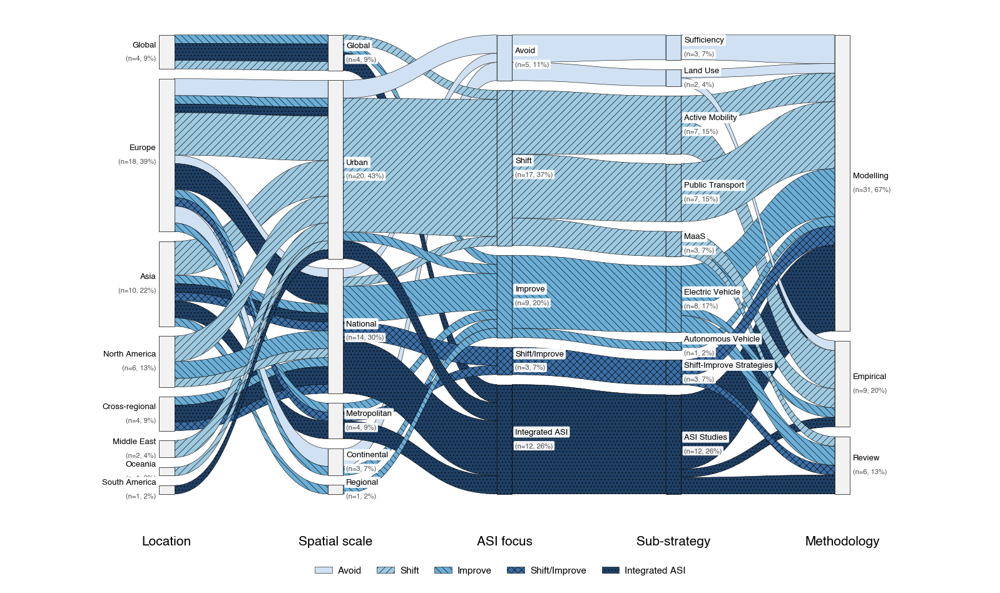

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
import matplotlib.patches as mpatches
from collections import defaultdict

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
    "Germany, California (USA)": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta y hatches -- IDÉNTICOS al gráfico de barras temporal
# ----------------------------------------------------------------------
PILLARS = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]
PILLAR_COLORS = dict(zip(PILLARS, ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#1f3f63"]))
PILLAR_HATCHES = dict(zip(PILLARS, ["", "///", "\\\\\\", "xxx", "..."]))

# CAMBIO AQUÍ: Gris mucho más claro (#f2f2f2 o #f5f5f5)
NEUTRAL_NODE_COLOR = "#f2f2f2"

SUBSTRATEGY_TO_STRATEGY = {
    "Sufficiency": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI",
}

# ----------------------------------------------------------------------
# 3. Orden estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

order_col2 = PILLARS

order_col3 = [
    "Sufficiency", "Land Use", "Active Mobility", "Public Transport", "MaaS",
    "Electric Vehicle", "Autonomous Vehicle", "Shift-Improve Strategies", "ASI Studies",
]

order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")

# ----------------------------------------------------------------------
# 4. Geometría de nodos (y=0 arriba, y=1 abajo; se invierte el eje al graficar)
# ----------------------------------------------------------------------
node_label, node_sub, node_x, node_top, node_bot = [], [], [], [], []
node_color, node_hatch, node_id = [], [], {}
GAP, Y_PAD = 0.02, 0.03

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD

    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        top, bot = y_cursor, y_cursor + height

        node_id[(stage_i, cat)] = len(node_label)
        node_label.append(cat)
        node_sub.append(f"(n={cnt}, {pct}%)")
        node_x.append(stage_i)
        node_top.append(top)
        node_bot.append(bot)

        if stage_i == ASI_STAGE_INDEX:
            pillar = cat
        elif stage_i == THEME_STAGE_INDEX:
            pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)
        else:
            pillar = None

        node_color.append(PILLAR_COLORS.get(pillar, NEUTRAL_NODE_COLOR))
        node_hatch.append(PILLAR_HATCHES.get(pillar, ""))

        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados/hatcheados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_pillar = [], [], [], []

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    group_cols = list(dict.fromkeys([col_a, col_b, "ASI focus"]))
    grouped = df_complete.groupby(group_cols).size().reset_index(name="count")

    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["ASI focus"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_pillar.append(pillar)

# ----------------------------------------------------------------------
# 6. Sub-alturas de flujos dentro de cada nodo (evita solapes)
# ----------------------------------------------------------------------
node_out, node_in = defaultdict(list), defaultdict(list)
for li, (s, t) in enumerate(zip(link_source, link_target)):
    node_out[s].append(li)
    node_in[t].append(li)

node_y_center = [(top + bot) / 2 for top, bot in zip(node_top, node_bot)]
for idx in node_out:
    node_out[idx].sort(key=lambda li: node_y_center[link_target[li]])
for idx in node_in:
    node_in[idx].sort(key=lambda li: node_y_center[link_source[li]])

link_src_range, link_tgt_range = {}, {}
for idx in range(len(node_label)):
    top, bot = node_top[idx], node_bot[idx]
    height = bot - top

    outs = node_out.get(idx, [])
    tot_out = sum(link_value[li] for li in outs) or 1
    cur = top
    for li in outs:
        h = (link_value[li] / tot_out) * height
        link_src_range[li] = (cur, cur + h)
        cur += h

    ins = node_in.get(idx, [])
    tot_in = sum(link_value[li] for li in ins) or 1
    cur = top
    for li in ins:
        h = (link_value[li] / tot_in) * height
        link_tgt_range[li] = (cur, cur + h)
        cur += h

# ----------------------------------------------------------------------
# 7. Dibujo (Sankey 100% matplotlib: mismo motor de hatch que las barras)
# ----------------------------------------------------------------------
def sankey_ribbon(x0, x1, y0_top, y0_bot, y1_top, y1_bot, **kw):
    """Cinta de flujo con curvas Bezier cúbicas (estilo D3/Plotly Sankey)."""
    xm = (x0 + x1) / 2.0
    verts = [
        (x0, y0_top),
        (xm, y0_top), (xm, y1_top), (x1, y1_top),
        (x1, y1_bot),
        (xm, y1_bot), (xm, y0_bot), (x0, y0_bot),
        (x0, y0_top),
    ]
    codes = [Path.MOVETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.LINETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.CLOSEPOLY]
    return PathPatch(Path(verts, codes), **kw)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["hatch.linewidth"] = 0.45
plt.rcParams["pdf.fonttype"] = 42

FS_LABEL = 9.5
FS_SUB = 8
FS_TITLE = 15
FS_LEGEND = 11

N_STAGES = len(STAGE_COL)
fig, ax = plt.subplots(figsize=(16, 9.5))
NODE_W = 0.09

# 7.1 Flujos primero
for li in range(len(link_source)):
    s, t = link_source[li], link_target[li]
    pillar = link_pillar[li]
    y0_top, y0_bot = link_src_range[li]
    y1_top, y1_bot = link_tgt_range[li]
    x0 = node_x[s] + NODE_W / 2
    x1 = node_x[t] - NODE_W / 2
    patch = sankey_ribbon(
        x0, x1, y0_top, y0_bot, y1_top, y1_bot,
        facecolor=PILLAR_COLORS[pillar], edgecolor="black", linewidth=0.4,
        hatch=PILLAR_HATCHES[pillar], zorder=1,
    )
    ax.add_patch(patch)

# 7.2 Nodos encima
LABEL_BOX = dict(boxstyle="round,pad=0.22,rounding_size=0.15",
                  facecolor="white", edgecolor="none", alpha=0.95)

for idx in range(len(node_label)):
    x = node_x[idx]
    y0, y1 = node_top[idx], node_bot[idx]
    rect = Rectangle(
        (x - NODE_W / 2, y0), NODE_W, y1 - y0,
        facecolor=node_color[idx], edgecolor="black", linewidth=0.5,
        hatch=node_hatch[idx], zorder=2,
    )
    ax.add_patch(rect)

    y_center = (y0 + y1) / 2
    if node_x[idx] == 0:
        x_text, ha = x - NODE_W / 2 - 0.018, "right"
    else:
        x_text, ha = x + NODE_W / 2 + 0.018, "left"

    ax.text(x_text, y_center - 0.007, node_label[idx],
            fontsize=FS_LABEL, va="bottom", ha=ha, zorder=10, bbox=LABEL_BOX)
    ax.text(x_text, y_center + 0.007, node_sub[idx],
            fontsize=FS_SUB, color="0.30", va="top", ha=ha, zorder=10, bbox=LABEL_BOX)

ax.set_xlim(-0.95, N_STAGES - 1 + 0.9)
ax.set_ylim(-0.03, 1.16)
ax.invert_yaxis()
ax.axis("off")

# 7.3 Titulos de columna
TITLE_Y = 1.055
for i, title in enumerate(STAGE_TITLES):
    ax.text(i, TITLE_Y, title, fontsize=FS_TITLE,
            fontweight="bold", ha="center", va="top")

# 7.4 Leyenda de pilares
legend_handles = [
    mpatches.Patch(facecolor=PILLAR_COLORS[p], edgecolor="black", linewidth=0.4,
                   hatch=PILLAR_HATCHES[p], label=p)
    for p in PILLARS
]
ax.legend(handles=legend_handles, ncol=5, frameon=False, fontsize=FS_LEGEND,
          loc="upper center", bbox_to_anchor=(0.5, 0.05), handlelength=1.8,
          handletextpad=0.6, columnspacing=1.6)

fig.tight_layout()
fig.savefig("fig_sankey_hatched.pdf", bbox_inches="tight")
fig.savefig("fig_sankey_hatched.png", dpi=300, bbox_inches="tight")
print("Guardado: fig_sankey_hatched.pdf / fig_sankey_hatched.png")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Guardado: Lit_Review_Sankey.pdf / Lit_Review_Sankey.png


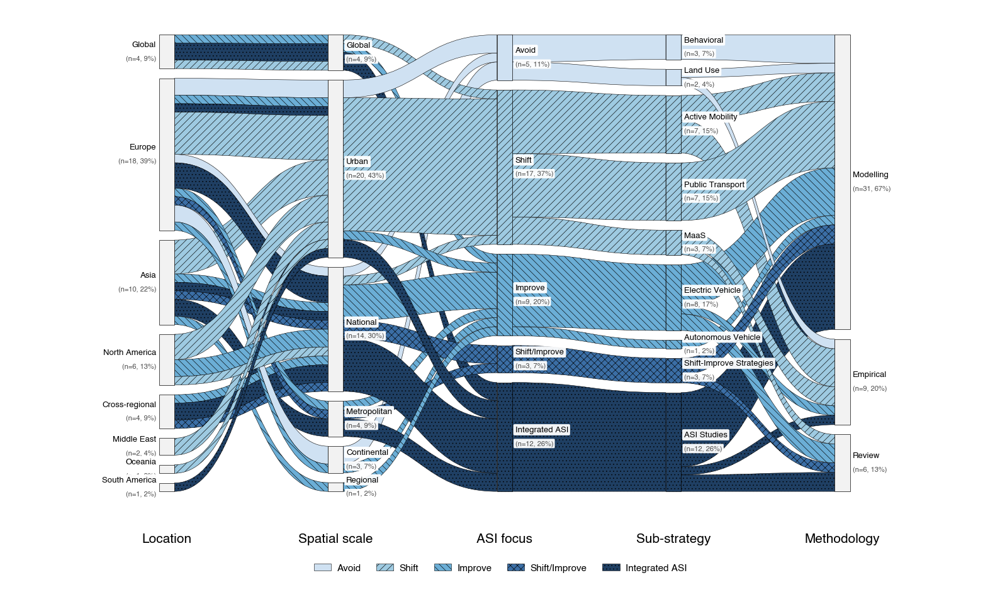

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
import matplotlib.patches as mpatches
from collections import defaultdict

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
    "Germany, California (USA)": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical",
    "Empirical analysis (Regression)": "Empirical",
    "Case study": "Empirical",
    "LCA study": "Modelling",
    "Modelling (IAM)": "Modelling",
    "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling",
    "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling",
    "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling",
    "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review",
    "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Behavioral",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"] = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta y hatches -- IDÉNTICOS al gráfico de barras temporal
# ----------------------------------------------------------------------
PILLARS = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

PILLAR_COLORS = dict(zip(
    PILLARS,
    ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#1f3f63"]
))

PILLAR_HATCHES = dict(zip(
    PILLARS,
    ["", "///", "\\\\\\", "xxx", "..."]
))

# Gris mucho más claro
NEUTRAL_NODE_COLOR = "#f2f2f2"

SUBSTRATEGY_TO_STRATEGY = {
    "Behavioral": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI",
}

# ----------------------------------------------------------------------
# 3. Orden estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = [
    "Region_grp",
    "Spatial scale",
    "ASI focus",
    "Theme_grp",
    "Method_grp"
]

STAGE_TITLES = [
    "Location",
    "Spatial scale",
    "ASI focus",
    "Sub-strategy",
    "Methodology"
]

c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [
    cat for cat in c0.index if cat != "Global"
]

c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [
    cat for cat in c1.index if cat != "Global"
]

order_col2 = PILLARS

order_col3 = [
    "Behavioral",
    "Land Use",
    "Active Mobility",
    "Public Transport",
    "MaaS",
    "Electric Vehicle",
    "Autonomous Vehicle",
    "Shift-Improve Strategies",
    "ASI Studies",
]

order_col4 = list(
    df_complete["Method_grp"].value_counts().index
)

STAGE_ORDER = [
    order_col0,
    order_col1,
    order_col2,
    order_col3,
    order_col4
]

ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")

# ----------------------------------------------------------------------
# 4. Geometría de nodos
#    (y=0 arriba, y=1 abajo; se invierte el eje al graficar)
# ----------------------------------------------------------------------
node_label = []
node_sub = []
node_x = []
node_top = []
node_bot = []

node_color = []
node_hatch = []
node_id = {}

GAP, Y_PAD = 0.02, 0.03

for stage_i, (col, order) in enumerate(
    zip(STAGE_COL, STAGE_ORDER)
):
    counts = df_complete[col].value_counts()

    present = [
        c for c in order
        if c in counts.index
    ]

    total = counts[present].sum()
    n_nodes = len(present)

    avail_h = (
        (1 - 2 * Y_PAD)
        - GAP * (n_nodes - 1)
    )

    y_cursor = Y_PAD

    for cat in present:

        cnt = int(counts[cat])
        pct = round(
            100 * cnt / N_FULL_CORPUS
        )

        height = (
            cnt / total
        ) * avail_h

        top = y_cursor
        bot = y_cursor + height

        node_id[(stage_i, cat)] = len(node_label)

        node_label.append(cat)
        node_sub.append(
            f"(n={cnt}, {pct}%)"
        )

        node_x.append(stage_i)
        node_top.append(top)
        node_bot.append(bot)

        if stage_i == ASI_STAGE_INDEX:
            pillar = cat

        elif stage_i == THEME_STAGE_INDEX:
            pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)

        else:
            pillar = None

        node_color.append(
            PILLAR_COLORS.get(
                pillar,
                NEUTRAL_NODE_COLOR
            )
        )

        node_hatch.append(
            PILLAR_HATCHES.get(
                pillar,
                ""
            )
        )

        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados/hatcheados por pilar ASI
# ----------------------------------------------------------------------
link_source = []
link_target = []
link_value = []
link_pillar = []

for stage_i in range(
    len(STAGE_COL) - 1
):

    col_a = STAGE_COL[stage_i]
    col_b = STAGE_COL[stage_i + 1]

    group_cols = list(
        dict.fromkeys(
            [col_a, col_b, "ASI focus"]
        )
    )

    grouped = (
        df_complete
        .groupby(group_cols)
        .size()
        .reset_index(name="count")
    )

    for _, row in grouped.iterrows():

        cat_a = row[col_a]
        cat_b = row[col_b]
        pillar = row["ASI focus"]
        cnt = row["count"]

        if (
            (stage_i, cat_a) not in node_id
            or
            (stage_i + 1, cat_b) not in node_id
        ):
            continue

        link_source.append(
            node_id[(stage_i, cat_a)]
        )

        link_target.append(
            node_id[(stage_i + 1, cat_b)]
        )

        link_value.append(
            int(cnt)
        )

        link_pillar.append(
            pillar
        )

# ----------------------------------------------------------------------
# 6. Sub-alturas de flujos dentro de cada nodo
#    (evita solapes)
# ----------------------------------------------------------------------
node_out = defaultdict(list)
node_in = defaultdict(list)

for li, (s, t) in enumerate(
    zip(link_source, link_target)
):
    node_out[s].append(li)
    node_in[t].append(li)

node_y_center = [
    (top + bot) / 2
    for top, bot
    in zip(node_top, node_bot)
]

for idx in node_out:
    node_out[idx].sort(
        key=lambda li:
        node_y_center[link_target[li]]
    )

for idx in node_in:
    node_in[idx].sort(
        key=lambda li:
        node_y_center[link_source[li]]
    )

link_src_range = {}
link_tgt_range = {}

for idx in range(
    len(node_label)
):

    top = node_top[idx]
    bot = node_bot[idx]

    height = bot - top

    # Flujos salientes
    outs = node_out.get(
        idx, []
    )

    tot_out = sum(
        link_value[li]
        for li in outs
    ) or 1

    cur = top

    for li in outs:

        h = (
            link_value[li]
            / tot_out
        ) * height

        link_src_range[li] = (
            cur,
            cur + h
        )

        cur += h

    # Flujos entrantes
    ins = node_in.get(
        idx, []
    )

    tot_in = sum(
        link_value[li]
        for li in ins
    ) or 1

    cur = top

    for li in ins:

        h = (
            link_value[li]
            / tot_in
        ) * height

        link_tgt_range[li] = (
            cur,
            cur + h
        )

        cur += h

# ----------------------------------------------------------------------
# 7. Dibujo
#    Sankey 100% matplotlib:
#    mismo motor de hatch que las barras
# ----------------------------------------------------------------------
def sankey_ribbon(
    x0,
    x1,
    y0_top,
    y0_bot,
    y1_top,
    y1_bot,
    **kw
):
    """
    Cinta de flujo con curvas Bezier cúbicas
    (estilo D3/Plotly Sankey).
    """

    xm = (
        x0 + x1
    ) / 2.0

    verts = [
        (x0, y0_top),

        (xm, y0_top),
        (xm, y1_top),
        (x1, y1_top),

        (x1, y1_bot),

        (xm, y1_bot),
        (xm, y0_bot),
        (x0, y0_bot),

        (x0, y0_top),
    ]

    codes = [
        Path.MOVETO,

        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,

        Path.LINETO,

        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,

        Path.CLOSEPOLY
    ]

    return PathPatch(
        Path(verts, codes),
        **kw
    )


plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = [
    "Helvetica",
    "Arial",
    "DejaVu Sans"
]

plt.rcParams["hatch.linewidth"] = 0.45
plt.rcParams["pdf.fonttype"] = 42

FS_LABEL = 9.5
FS_SUB = 8
FS_TITLE = 15
FS_LEGEND = 11

N_STAGES = len(STAGE_COL)

fig, ax = plt.subplots(
    figsize=(16, 9.5)
)

NODE_W = 0.09

# ----------------------------------------------------------------------
# 7.1 Flujos primero
# ----------------------------------------------------------------------
for li in range(
    len(link_source)
):

    s = link_source[li]
    t = link_target[li]

    pillar = link_pillar[li]

    y0_top, y0_bot = (
        link_src_range[li]
    )

    y1_top, y1_bot = (
        link_tgt_range[li]
    )

    x0 = (
        node_x[s]
        + NODE_W / 2
    )

    x1 = (
        node_x[t]
        - NODE_W / 2
    )

    patch = sankey_ribbon(
        x0,
        x1,
        y0_top,
        y0_bot,
        y1_top,
        y1_bot,

        facecolor=PILLAR_COLORS[pillar],
        edgecolor="black",
        linewidth=0.4,
        hatch=PILLAR_HATCHES[pillar],
        zorder=1,
    )

    ax.add_patch(
        patch
    )

# ----------------------------------------------------------------------
# 7.2 Nodos encima
# ----------------------------------------------------------------------
LABEL_BOX = dict(
    boxstyle=(
        "round,pad=0.22,"
        "rounding_size=0.15"
    ),
    facecolor="white",
    edgecolor="none",
    alpha=0.95
)

for idx in range(
    len(node_label)
):

    x = node_x[idx]

    y0 = node_top[idx]
    y1 = node_bot[idx]

    rect = Rectangle(
        (
            x - NODE_W / 2,
            y0
        ),
        NODE_W,
        y1 - y0,

        facecolor=node_color[idx],
        edgecolor="black",
        linewidth=0.5,
        hatch=node_hatch[idx],
        zorder=2,
    )

    ax.add_patch(
        rect
    )

    y_center = (
        y0 + y1
    ) / 2

    if node_x[idx] == 0:

        x_text = (
            x
            - NODE_W / 2
            - 0.018
        )

        ha = "right"

    else:

        x_text = (
            x
            + NODE_W / 2
            + 0.018
        )

        ha = "left"

    ax.text(
        x_text,
        y_center - 0.007,
        node_label[idx],
        fontsize=FS_LABEL,
        va="bottom",
        ha=ha,
        zorder=10,
        bbox=LABEL_BOX
    )

    ax.text(
        x_text,
        y_center + 0.007,
        node_sub[idx],
        fontsize=FS_SUB,
        color="0.30",
        va="top",
        ha=ha,
        zorder=10,
        bbox=LABEL_BOX
    )

# ----------------------------------------------------------------------
# 7.3 Límites y formato
# ----------------------------------------------------------------------
ax.set_xlim(
    -0.95,
    N_STAGES - 1 + 0.9
)

ax.set_ylim(
    -0.03,
    1.16
)

ax.invert_yaxis()
ax.axis("off")

# ----------------------------------------------------------------------
# 7.4 Títulos de columna
# ----------------------------------------------------------------------
TITLE_Y = 1.055

for i, title in enumerate(
    STAGE_TITLES
):

    ax.text(
        i,
        TITLE_Y,
        title,
        fontsize=FS_TITLE,
        fontweight="bold",
        ha="center",
        va="top"
    )

# ----------------------------------------------------------------------
# 7.5 Leyenda de pilares
# ----------------------------------------------------------------------
legend_handles = [
    mpatches.Patch(
        facecolor=PILLAR_COLORS[p],
        edgecolor="black",
        linewidth=0.4,
        hatch=PILLAR_HATCHES[p],
        label=p
    )
    for p in PILLARS
]

ax.legend(
    handles=legend_handles,
    ncol=5,
    frameon=False,
    fontsize=FS_LEGEND,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.05),
    handlelength=1.8,
    handletextpad=0.6,
    columnspacing=1.6
)

# ----------------------------------------------------------------------
# 8. Guardado
# ----------------------------------------------------------------------
fig.tight_layout()

fig.savefig(
    "Lit_Review_Sankey.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "Lit_Review_Sankey.png",
    dpi=300,
    bbox_inches="tight"
)

print(
    "Guardado: "
    "Lit_Review_Sankey.pdf / "
    "Lit_Review_Sankey.png"
)

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Guardado: Lit_Review_Sankey.pdf / Lit_Review_Sankey.png


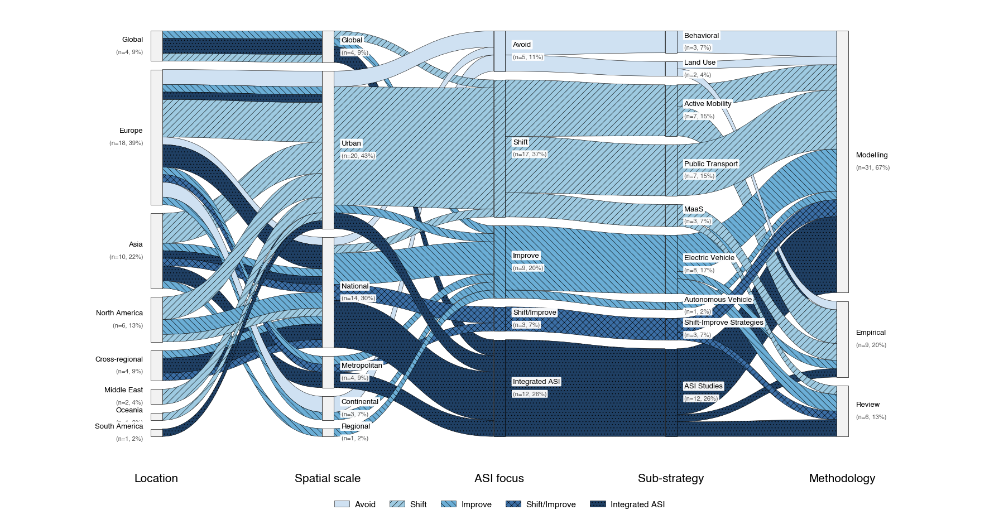

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
import matplotlib.patches as mpatches
from collections import defaultdict
# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)
DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)
df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)
REGION_MAP = {
    "Global": "Global",
    "Global (78 studies)": "Global",
    "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe",
    "London, UK": "Europe",
    "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe",
    "Germany": "Europe",
    "Poland": "Europe",
    "Switzerland": "Europe",
    "Hamburg, Germany": "Europe",
    "Europe (EU)": "Europe",
    "European cities": "Europe",
    "Warsaw, Poland": "Europe",
    "UK": "Europe",
    "Lyon , France": "Europe",
    "Malta": "Europe",
    "Austria": "Europe",
    "USA": "North America",
    "Toronto, Canada": "North America",
    "Los Angeles, USA": "North America",
    "Portland, USA": "North America",
    "Mexico": "North America",
    "China": "Asia",
    "Xiamen, China": "Asia",
    "Beijing, China": "Asia",
    "China (provincial)": "Asia",
    "Tokyo, Japan": "Asia",
    "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East",
    "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional",
    "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional",
    "JP / UK / MX / FR": "Cross-regional",
    "Germany, California (USA)": "Cross-regional",
}
METHOD_MAP = {
    "Empirical": "Empirical",
    "Empirical analysis (Regression)": "Empirical",
    "Case study": "Empirical",
    "LCA study": "Modelling",
    "Modelling (IAM)": "Modelling",
    "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling",
    "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling",
    "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling",
    "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review",
    "Systematic review": "Review",
}
THEME_MAP = {
    "Sufficiency / behavioural": "Behavioral",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}
df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"] = df_complete["Sub-strategy"].map(THEME_MAP)
# ----------------------------------------------------------------------
# 2. Paleta y hatches
# ----------------------------------------------------------------------
PILLARS = [
    "Avoid",
    "Shift",
    "Improve",
    "Shift/Improve",
    "Integrated ASI"
]
PILLAR_COLORS = dict(zip(
    PILLARS,
    [
        "#cfe1f2",
        "#9ecae1",
        "#6baed6",
        "#3b6ea5",
        "#1f3f63"
    ]
))
PILLAR_HATCHES = dict(zip(
    PILLARS,
    [
        "",
        "///",
        "\\\\\\",
        "xxx",
        "..."
    ]
))
NEUTRAL_NODE_COLOR = "#f2f2f2"
SUBSTRATEGY_TO_STRATEGY = {
    "Behavioral": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI",
}
# ----------------------------------------------------------------------
# 3. Orden estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = [
    "Region_grp",
    "Spatial scale",
    "ASI focus",
    "Theme_grp",
    "Method_grp"
]
STAGE_TITLES = [
    "Location",
    "Spatial scale",
    "ASI focus",
    "Sub-strategy",
    "Methodology"
]
c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [
    cat for cat in c0.index
    if cat != "Global"
]
c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [
    cat for cat in c1.index
    if cat != "Global"
]
order_col2 = PILLARS
order_col3 = [
    "Behavioral",
    "Land Use",
    "Active Mobility",
    "Public Transport",
    "MaaS",
    "Electric Vehicle",
    "Autonomous Vehicle",
    "Shift-Improve Strategies",
    "ASI Studies",
]
order_col4 = list(
    df_complete["Method_grp"].value_counts().index
)
STAGE_ORDER = [
    order_col0,
    order_col1,
    order_col2,
    order_col3,
    order_col4
]
ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")
# ----------------------------------------------------------------------
# 4. Geometría de nodos
# ----------------------------------------------------------------------
node_label = []
node_sub = []
node_x = []
node_top = []
node_bot = []
node_color = []
node_hatch = []
node_id = {}
GAP = 0.02
Y_PAD = 0.03
for stage_i, (col, order) in enumerate(
    zip(STAGE_COL, STAGE_ORDER)
):
    counts = df_complete[col].value_counts()
    present = [
        c for c in order
        if c in counts.index
    ]
    total = counts[present].sum()
    n_nodes = len(present)
    avail_h = (
        (1 - 2 * Y_PAD)
        - GAP * (n_nodes - 1)
    )
    y_cursor = Y_PAD
    for cat in present:
        cnt = int(counts[cat])
        pct = round(
            100 * cnt / N_FULL_CORPUS
        )
        height = (
            cnt / total
        ) * avail_h
        top = y_cursor
        bot = y_cursor + height
        node_id[(stage_i, cat)] = len(node_label)
        node_label.append(cat)
        node_sub.append(
            f"(n={cnt}, {pct}%)"
        )
        node_x.append(stage_i)
        node_top.append(top)
        node_bot.append(bot)
        if stage_i == ASI_STAGE_INDEX:
            pillar = cat
        elif stage_i == THEME_STAGE_INDEX:
            pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)
        else:
            pillar = None
        node_color.append(
            PILLAR_COLORS.get(
                pillar,
                NEUTRAL_NODE_COLOR
            )
        )
        node_hatch.append(
            PILLAR_HATCHES.get(
                pillar,
                ""
            )
        )
        y_cursor += height + GAP
# ----------------------------------------------------------------------
# 5. Enlaces
# ----------------------------------------------------------------------
link_source = []
link_target = []
link_value = []
link_pillar = []
for stage_i in range(
    len(STAGE_COL) - 1
):
    col_a = STAGE_COL[stage_i]
    col_b = STAGE_COL[stage_i + 1]
    group_cols = list(
        dict.fromkeys(
            [col_a, col_b, "ASI focus"]
        )
    )
    grouped = (
        df_complete
        .groupby(group_cols)
        .size()
        .reset_index(name="count")
    )
    for _, row in grouped.iterrows():
        cat_a = row[col_a]
        cat_b = row[col_b]
        pillar = row["ASI focus"]
        cnt = row["count"]
        if (
            (stage_i, cat_a) not in node_id
            or
            (stage_i + 1, cat_b) not in node_id
        ):
            continue
        link_source.append(
            node_id[(stage_i, cat_a)]
        )
        link_target.append(
            node_id[(stage_i + 1, cat_b)]
        )
        link_value.append(
            int(cnt)
        )
        link_pillar.append(
            pillar
        )
# ----------------------------------------------------------------------
# 6. Sub-alturas de flujos
# ----------------------------------------------------------------------
node_out = defaultdict(list)
node_in = defaultdict(list)
for li, (s, t) in enumerate(
    zip(link_source, link_target)
):
    node_out[s].append(li)
    node_in[t].append(li)
node_y_center = [
    (top + bot) / 2
    for top, bot
    in zip(node_top, node_bot)
]
for idx in node_out:
    node_out[idx].sort(
        key=lambda li:
        node_y_center[link_target[li]]
    )
for idx in node_in:
    node_in[idx].sort(
        key=lambda li:
        node_y_center[link_source[li]]
    )
link_src_range = {}
link_tgt_range = {}
for idx in range(
    len(node_label)
):
    top = node_top[idx]
    bot = node_bot[idx]
    height = bot - top
    # Salidas
    outs = node_out.get(
        idx,
        []
    )
    tot_out = sum(
        link_value[li]
        for li in outs
    ) or 1
    cur = top
    for li in outs:
        h = (
            link_value[li]
            / tot_out
        ) * height
        link_src_range[li] = (
            cur,
            cur + h
        )
        cur += h
    # Entradas
    ins = node_in.get(
        idx,
        []
    )
    tot_in = sum(
        link_value[li]
        for li in ins
    ) or 1
    cur = top
    for li in ins:
        h = (
            link_value[li]
            / tot_in
        ) * height
        link_tgt_range[li] = (
            cur,
            cur + h
        )
        cur += h
# ----------------------------------------------------------------------
# 7. Función Sankey
# ----------------------------------------------------------------------
def sankey_ribbon(
    x0,
    x1,
    y0_top,
    y0_bot,
    y1_top,
    y1_bot,
    **kw
):
    xm = (
        x0 + x1
    ) / 2.0
    verts = [
        (x0, y0_top),
        (xm, y0_top),
        (xm, y1_top),
        (x1, y1_top),
        (x1, y1_bot),
        (xm, y1_bot),
        (xm, y0_bot),
        (x0, y0_bot),
        (x0, y0_top),
    ]
    codes = [
        Path.MOVETO,
        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,
        Path.LINETO,
        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,
        Path.CLOSEPOLY
    ]
    return PathPatch(
        Path(verts, codes),
        **kw
    )
# ----------------------------------------------------------------------
# 8. Configuración gráfica
# ----------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = [
    "Helvetica",
    "Arial",
    "DejaVu Sans"
]
plt.rcParams["hatch.linewidth"] = 0.45
plt.rcParams["pdf.fonttype"] = 42
FS_LABEL = 9.5
FS_SUB = 8
FS_TITLE = 15
FS_LEGEND = 11
N_STAGES = len(STAGE_COL)
# ----------------------------------------------------------------------
# 9. Figura
#
# IMPORTANTE:
# Se aumenta el ancho de la figura y el espacio horizontal entre
# columnas para evitar que etiquetas como "Oceania" se solapen.
# ----------------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(18, 9.5)
)
NODE_W = 0.085
# Posiciones horizontales personalizadas.
#
# Antes:
# 0, 1, 2, 3, 4
#
# Ahora dejamos más espacio entre columnas:
STAGE_X = [
    0.0,
    1.25,
    2.50,
    3.75,
    5.00
]
# ----------------------------------------------------------------------
# 9.1 Flujos primero
# ----------------------------------------------------------------------
for li in range(
    len(link_source)
):
    s = link_source[li]
    t = link_target[li]
    pillar = link_pillar[li]
    y0_top, y0_bot = (
        link_src_range[li]
    )
    y1_top, y1_bot = (
        link_tgt_range[li]
    )
    x0 = (
        STAGE_X[node_x[s]]
        + NODE_W / 2
    )
    x1 = (
        STAGE_X[node_x[t]]
        - NODE_W / 2
    )
    patch = sankey_ribbon(
        x0,
        x1,
        y0_top,
        y0_bot,
        y1_top,
        y1_bot,
        facecolor=PILLAR_COLORS[pillar],
        edgecolor="black",
        linewidth=0.4,
        hatch=PILLAR_HATCHES[pillar],
        zorder=1,
    )
    ax.add_patch(
        patch
    )
# ----------------------------------------------------------------------
# 9.2 Nodos encima
# ----------------------------------------------------------------------
LABEL_BOX = dict(
    boxstyle=(
        "round,pad=0.18,"
        "rounding_size=0.12"
    ),
    facecolor="white",
    edgecolor="none",
    alpha=0.96
)
# Distancia de las etiquetas respecto al nodo.
# Se aumenta para que "Oceania" tenga espacio suficiente.
LABEL_OFFSET = 0.055
for idx in range(
    len(node_label)
):
    stage_idx = node_x[idx]
    x = STAGE_X[stage_idx]
    y0 = node_top[idx]
    y1 = node_bot[idx]
    rect = Rectangle(
        (
            x - NODE_W / 2,
            y0
        ),
        NODE_W,
        y1 - y0,
        facecolor=node_color[idx],
        edgecolor="black",
        linewidth=0.5,
        hatch=node_hatch[idx],
        zorder=2,
    )
    ax.add_patch(
        rect
    )
    y_center = (
        y0 + y1
    ) / 2
    # --------------------------------------------------------------
    # Primera columna:
    # etiquetas hacia la izquierda
    # --------------------------------------------------------------
    if stage_idx == 0:
        x_text = (
            x
            - NODE_W / 2
            - LABEL_OFFSET
        )
        ha = "right"
    # --------------------------------------------------------------
    # Última columna:
    # etiquetas hacia la derecha
    # --------------------------------------------------------------
    elif stage_idx == N_STAGES - 1:
        x_text = (
            x
            + NODE_W / 2
            + LABEL_OFFSET
        )
        ha = "left"
    # --------------------------------------------------------------
    # Columnas intermedias:
    # etiquetas hacia la derecha
    # --------------------------------------------------------------
    else:
        x_text = (
            x
            + NODE_W / 2
            + LABEL_OFFSET
        )
        ha = "left"
    # Nombre del nodo
    ax.text(
        x_text,
        y_center - 0.007,
        node_label[idx],
        fontsize=FS_LABEL,
        va="bottom",
        ha=ha,
        zorder=10,
        bbox=LABEL_BOX,
        clip_on=False
    )
    # n y porcentaje
    ax.text(
        x_text,
        y_center + 0.007,
        node_sub[idx],
        fontsize=FS_SUB,
        color="0.30",
        va="top",
        ha=ha,
        zorder=10,
        bbox=LABEL_BOX,
        clip_on=False
    )
# ----------------------------------------------------------------------
# 9.3 Límites
# ----------------------------------------------------------------------
ax.set_xlim(
    -1.10,
    STAGE_X[-1] + 1.10
)
ax.set_ylim(
    -0.03,
    1.16
)
ax.invert_yaxis()
ax.axis("off")
# ----------------------------------------------------------------------
# 9.4 Títulos de columna
# ----------------------------------------------------------------------
TITLE_Y = 1.055
for i, title in enumerate(
    STAGE_TITLES
):
    ax.text(
        STAGE_X[i],
        TITLE_Y,
        title,
        fontsize=FS_TITLE,
        fontweight="bold",
        ha="center",
        va="top",
        clip_on=False
    )
# ----------------------------------------------------------------------
# 9.5 Leyenda
# ----------------------------------------------------------------------
legend_handles = [
    mpatches.Patch(
        facecolor=PILLAR_COLORS[p],
        edgecolor="black",
        linewidth=0.4,
        hatch=PILLAR_HATCHES[p],
        label=p
    )
    for p in PILLARS
]
ax.legend(
    handles=legend_handles,
    ncol=5,
    frameon=False,
    fontsize=FS_LEGEND,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.05
    ),
    handlelength=1.8,
    handletextpad=0.6,
    columnspacing=1.6
)
# ----------------------------------------------------------------------
# 10. Guardado

# ----------------------------------------------------------------------
fig.tight_layout()

fig.savefig(
    "Lit_Review_Sankey.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "Lit_Review_Sankey.png",
    dpi=300,
    bbox_inches="tight"
)

print(
    "Guardado: "
    "Lit_Review_Sankey.pdf / "
    "Lit_Review_Sankey.png"
)

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
import matplotlib.patches as mpatches
from collections import defaultdict

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "/sessions/charming-vigilant-wright/mnt/uploads/DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
    "Germany, California (USA)": "Cross-regional",  # FIX: estudio 44 (Rogge et al. 2024) no estaba mapeado
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta y hatches -- IDÉNTICOS al gráfico de barras temporal
# ----------------------------------------------------------------------
PILLARS = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]
PILLAR_COLORS = dict(zip(PILLARS, ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#1f3f63"]))
PILLAR_HATCHES = dict(zip(PILLARS, ["", "///", "\\\\\\", "xxx", "..."]))
NEUTRAL_NODE_COLOR = "#d9d9d9"

SUBSTRATEGY_TO_STRATEGY = {
    "Sufficiency": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI",
}

# ----------------------------------------------------------------------
# 3. Orden estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

order_col2 = PILLARS

order_col3 = [
    "Sufficiency", "Land Use", "Active Mobility", "Public Transport", "MaaS",
    "Electric Vehicle", "Autonomous Vehicle", "Shift-Improve Strategies", "ASI Studies",
]

order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")

# ----------------------------------------------------------------------
# 4. Geometría de nodos (y=0 arriba, y=1 abajo; se invierte el eje al graficar)
# ----------------------------------------------------------------------
node_label, node_sub, node_x, node_top, node_bot = [], [], [], [], []
node_color, node_hatch, node_id = [], [], {}
GAP, Y_PAD = 0.02, 0.03

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD

    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        top, bot = y_cursor, y_cursor + height

        node_id[(stage_i, cat)] = len(node_label)
        node_label.append(cat)
        node_sub.append(f"(n={cnt}, {pct}%)")
        node_x.append(stage_i)
        node_top.append(top)
        node_bot.append(bot)

        if stage_i == ASI_STAGE_INDEX:
            pillar = cat
        elif stage_i == THEME_STAGE_INDEX:
            pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)
        else:
            pillar = None

        node_color.append(PILLAR_COLORS.get(pillar, NEUTRAL_NODE_COLOR))
        node_hatch.append(PILLAR_HATCHES.get(pillar, ""))

        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados/hatcheados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_pillar = [], [], [], []

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    group_cols = list(dict.fromkeys([col_a, col_b, "ASI focus"]))
    grouped = df_complete.groupby(group_cols).size().reset_index(name="count")

    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["ASI focus"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_pillar.append(pillar)

# ----------------------------------------------------------------------
# 6. Sub-alturas de flujos dentro de cada nodo (evita solapes)
# ----------------------------------------------------------------------
node_out, node_in = defaultdict(list), defaultdict(list)
for li, (s, t) in enumerate(zip(link_source, link_target)):
    node_out[s].append(li)
    node_in[t].append(li)

node_y_center = [(top + bot) / 2 for top, bot in zip(node_top, node_bot)]
for idx in node_out:
    node_out[idx].sort(key=lambda li: node_y_center[link_target[li]])
for idx in node_in:
    node_in[idx].sort(key=lambda li: node_y_center[link_source[li]])

link_src_range, link_tgt_range = {}, {}
for idx in range(len(node_label)):
    top, bot = node_top[idx], node_bot[idx]
    height = bot - top

    outs = node_out.get(idx, [])
    tot_out = sum(link_value[li] for li in outs) or 1
    cur = top
    for li in outs:
        h = (link_value[li] / tot_out) * height
        link_src_range[li] = (cur, cur + h)
        cur += h

    ins = node_in.get(idx, [])
    tot_in = sum(link_value[li] for li in ins) or 1
    cur = top
    for li in ins:
        h = (link_value[li] / tot_in) * height
        link_tgt_range[li] = (cur, cur + h)
        cur += h

# ----------------------------------------------------------------------
# 7. Dibujo (Sankey 100% matplotlib: mismo motor de hatch que las barras)
# ----------------------------------------------------------------------
def sankey_ribbon(x0, x1, y0_top, y0_bot, y1_top, y1_bot, **kw):
    xm = (x0 + x1) / 2.0
    verts = [
        (x0, y0_top),
        (xm, y0_top), (xm, y1_top), (x1, y1_top),
        (x1, y1_bot),
        (xm, y1_bot), (xm, y0_bot), (x0, y0_bot),
        (x0, y0_top),
    ]
    codes = [Path.MOVETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.LINETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.CLOSEPOLY]
    return PathPatch(Path(verts, codes), **kw)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["hatch.linewidth"] = 0.45
plt.rcParams["pdf.fonttype"] = 42

FS_LABEL = 9.5
FS_SUB = 8
FS_TITLE = 15
FS_LEGEND = 11

N_STAGES = len(STAGE_COL)
fig, ax = plt.subplots(figsize=(16, 9.5))
NODE_W = 0.09

# 7.1 Flujos primero
for li in range(len(link_source)):
    s, t = link_source[li], link_target[li]
    pillar = link_pillar[li]
    y0_top, y0_bot = link_src_range[li]
    y1_top, y1_bot = link_tgt_range[li]
    x0 = node_x[s] + NODE_W / 2
    x1 = node_x[t] - NODE_W / 2
    patch = sankey_ribbon(
        x0, x1, y0_top, y0_bot, y1_top, y1_bot,
        facecolor=PILLAR_COLORS[pillar], edgecolor="black", linewidth=0.4,
        hatch=PILLAR_HATCHES[pillar], zorder=1,
    )
    ax.add_patch(patch)

# 7.2 Nodos + etiquetas (con anti-solape para nodos pequeños contiguos)
LABEL_BOX = dict(boxstyle="round,pad=0.22,rounding_size=0.15",
                  facecolor="white", edgecolor="none", alpha=0.95)

label_items = []  # info por etiqueta, para el paso de anti-solape

for idx in range(len(node_label)):
    x = node_x[idx]
    y0, y1 = node_top[idx], node_bot[idx]
    rect = Rectangle(
        (x - NODE_W / 2, y0), NODE_W, y1 - y0,
        facecolor=node_color[idx], edgecolor="black", linewidth=0.5,
        hatch=node_hatch[idx], zorder=2,
    )
    ax.add_patch(rect)

    y_center = (y0 + y1) / 2
    if node_x[idx] == 0:
        x_text, ha = x - NODE_W / 2 - 0.018, "right"
    else:
        x_text, ha = x + NODE_W / 2 + 0.018, "left"

    t_label = ax.text(x_text, y_center - 0.007, node_label[idx],
            fontsize=FS_LABEL, va="bottom", ha=ha, zorder=10, bbox=LABEL_BOX)
    t_sub = ax.text(x_text, y_center + 0.007, node_sub[idx],
            fontsize=FS_SUB, color="0.30", va="top", ha=ha, zorder=10, bbox=LABEL_BOX)

    label_items.append(dict(idx=idx, stage=node_x[idx], x_text=x_text, ha=ha,
                             t_label=t_label, t_sub=t_sub,
                             orig_y=y_center, y=y_center))

ax.set_xlim(-0.95, N_STAGES - 1 + 0.9)
ax.set_ylim(-0.03, 1.16)
ax.invert_yaxis()
ax.axis("off")

# ---- Anti-solape de etiquetas -----------------------------------------
# Cuando dos nodos contiguos son muy pequeños (p.ej. Oceania n=1 y South
# America n=1 en la columna Location), sus bloques de texto (2 líneas cada
# uno) se superponen porque el tamaño de fuente no escala con la altura del
# nodo. Este paso mide el tamaño real renderizado de cada bloque y separa
# los centros de texto lo mínimo necesario para que no se toquen, dibujando
# una fina línea guía cuando el texto se ha desplazado del nodo.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
inv = ax.transData.inverted()
MIN_GAP_DATA = 0.004

for stage_i in range(N_STAGES):
    items = [d for d in label_items if d["stage"] == stage_i]
    items.sort(key=lambda d: d["y"])

    prev_bottom = None
    for d in items:
        bb1 = d["t_label"].get_window_extent(renderer=renderer)
        bb2 = d["t_sub"].get_window_extent(renderer=renderer)
        pts = [[bb1.x0, bb1.y0], [bb1.x1, bb1.y1], [bb2.x0, bb2.y0], [bb2.x1, bb2.y1]]
        data_pts = inv.transform(pts)
        ys = data_pts[:, 1]
        half_h = (ys.max() - ys.min()) / 2
        d["half_h"] = half_h

        if prev_bottom is not None and (d["y"] - half_h) < prev_bottom + MIN_GAP_DATA:
            d["y"] += (prev_bottom + MIN_GAP_DATA) - (d["y"] - half_h)

        prev_bottom = d["y"] + half_h

    for d in items:
        d["t_label"].set_position((d["x_text"], d["y"] - 0.007))
        d["t_sub"].set_position((d["x_text"], d["y"] + 0.007))
        if abs(d["y"] - d["orig_y"]) > 1e-4:
            x_edge = node_x[d["idx"]] + (NODE_W / 2 if d["ha"] == "left" else -NODE_W / 2)
            x_near = d["x_text"] - (0.006 if d["ha"] == "left" else -0.006)
            ax.plot([x_edge, x_near], [d["orig_y"], d["y"]],
                     color="0.55", lw=0.6, zorder=9, solid_capstyle="round")

# 7.3 Titulos de columna
TITLE_Y = 1.055
for i, title in enumerate(STAGE_TITLES):
    ax.text(i, TITLE_Y, title, fontsize=FS_TITLE,
            fontweight="bold", ha="center", va="top")

# 7.4 Leyenda de pilares
legend_handles = [
    mpatches.Patch(facecolor=PILLAR_COLORS[p], edgecolor="black", linewidth=0.4,
                   hatch=PILLAR_HATCHES[p], label=p)
    for p in PILLARS
]
ax.legend(handles=legend_handles, ncol=5, frameon=False, fontsize=FS_LEGEND,
          loc="upper center", bbox_to_anchor=(0.5, -0.02), handlelength=1.8,
          handletextpad=0.6, columnspacing=1.6)

fig.tight_layout()
fig.savefig("fig_sankey_hatched.pdf", bbox_inches="tight")
fig.savefig("fig_sankey_hatched.png", dpi=300, bbox_inches="tight")
print("Guardado: fig_sankey_hatched.pdf / fig_sankey_hatched.png")
print("Location value_counts:")
print(df_complete["Region_grp"].value_counts(), df_complete["Region_grp"].value_counts().sum())

FileNotFoundError: [Errno 2] No such file or directory: '/sessions/charming-vigilant-wright/mnt/uploads/DATASET_SLR.xlsx'

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Saved fig_boundary_overview.pdf / .png con tipografía unificada


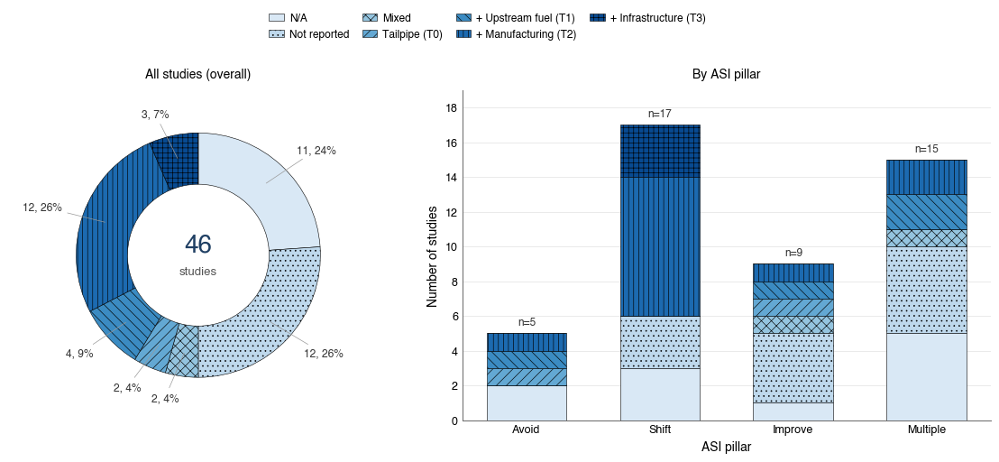

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np

# ---------------------------------------------------------------------------
# Configuración de estilo -- Alineado rigurosamente a fig_temporal_asi.pdf
# ---------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["axes.linewidth"] = 0.7
plt.rcParams["hatch.linewidth"] = 0.45  # Hatch fino, acabado editorial
N_TIERS = 7
FIGSIZE = (11.5, 4.6)

# Paleta secuencial azul (matplotlib 'Blues')
cmap = plt.get_cmap("Blues")
N_TIERS = 7
blue_shades = [cmap(0.15 + 0.75 * i / (N_TIERS - 1)) for i in range(N_TIERS)]

# Patrones de tramas por categoría de boundary
hatch_patterns = {
    "N/A":   "",
    "NR":    "...",
    "Mixed": "xxx",
    "T0":    "///",
    "T1":    "\\\\\\",
    "T2":    "|||",
    "T3":    "+++",
}
HATCH_COLOR = "#404040"

# ---------------------------------------------------------------------------
# Datos -- Supplementary Table S5
# ---------------------------------------------------------------------------
pillars = ["Avoid", "Shift", "Improve", "Multiple"]
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

data = {
    "Avoid":    {"N/A": 2, "NR": 0, "Mixed": 0, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Shift":    {"N/A": 3, "NR": 3, "Mixed": 0, "T0": 0, "T1": 0, "T2": 8, "T3": 3},
    "Improve":  {"N/A": 1, "NR": 4, "Mixed": 1, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Multiple": {"N/A": 5, "NR": 5, "Mixed": 1, "T0": 0, "T1": 2, "T2": 2, "T3": 0},
}

tier_labels = {
    "N/A": "N/A",
    "NR": "Not reported",
    "Mixed": "Mixed",
    "T0": "Tailpipe (T0)",
    "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)",
    "T3": "+ Infrastructure (T3)",
}

totals = {t: sum(data[p][t] for p in pillars) for t in tiers}
grand_total = sum(totals.values())

# ---------------------------------------------------------------------------
# Gráfico
# ---------------------------------------------------------------------------
fig, (ax_donut, ax_bar) = plt.subplots(
    1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.3, 1.6]}
)

# --- Panel Izquierdo: Donut Overall ----------------------------------------
sizes = [totals[t] for t in tiers]
wedges, _ = ax_donut.pie(
    sizes,
    colors=blue_shades,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.42, edgecolor="black", linewidth=0.4),
)
for wedge, tier in zip(wedges, tiers):
    wedge.set_hatch(hatch_patterns[tier])

# Anotaciones con porcentajes
for wedge, tier in zip(wedges, tiers):
    n = totals[tier]
    pct = 100 * n / grand_total
    ang = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    x_out, y_out = np.cos(ang), np.sin(ang)
    r_label = 1.18
    ha = "left" if x_out >= 0 else "right"
    ax_donut.annotate(
        f"{n}, {pct:.0f}%",
        xy=(0.79 * x_out, 0.79 * y_out),
        xytext=(r_label * x_out, r_label * y_out),
        ha=ha, va="center", fontsize=8.6, color="#333333",
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.5),
    )

ax_donut.text(0, 0.08, f"{grand_total}", ha="center", va="center",
              fontsize=20, fontweight="bold", color="#1F3F63")
ax_donut.text(0, -0.14, "studies", ha="center", va="center",
              fontsize=9.5, color="#555555")
ax_donut.set_title("All studies (overall)", fontsize=10, pad=10)
ax_donut.set_xlim(-1.55, 1.55)
ax_donut.set_ylim(-1.35, 1.35)
ax_donut.set_aspect("equal")

# --- Panel Derecho: Barras Apiladas por ASI pillar ------------------------
x = np.arange(len(pillars))
bottom = np.zeros(len(pillars))

for tier, color in zip(tiers, blue_shades):
    values = np.array([data[p][tier] for p in pillars])
    ax_bar.bar(
        x, values, bottom=bottom, width=0.6,
        color=color, edgecolor="black", linewidth=0.4,
        hatch=hatch_patterns[tier],
        label=tier_labels[tier], zorder=3,
    )
    bottom += values

for xi, p in enumerate(pillars):
    total = sum(data[p].values())
    ax_bar.text(xi, bottom[xi] + 0.3, f"n={total}", ha="center", va="bottom",
                fontsize=8.6, color="#333333")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(pillars)
ax_bar.set_xlabel("ASI pillar", fontsize=10)
ax_bar.set_ylabel("Number of studies", fontsize=10)
ax_bar.set_ylim(0, max(bottom) + 2)
ax_bar.yaxis.set_major_locator(MaxNLocator(integer=True))

# Estilo de spines y grid coincidente con la figura temporal
for s in ["top", "right"]:
    ax_bar.spines[s].set_visible(False)
ax_bar.spines["left"].set_color("0.4")
ax_bar.spines["bottom"].set_color("0.4")

ax_bar.yaxis.grid(True, color="0.90", linewidth=0.6, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.tick_params(labelsize=9, length=0)
ax_bar.set_title("By ASI pillar", fontsize=10, pad=10)

# --- Leyenda compartida (Mismo tamaño y jerarquía) -----------------------
handles, labels = ax_bar.get_legend_handles_labels()
leg = fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 1.12),
    ncol=4, frameon=False, fontsize=8.6, handlelength=1.4,
    columnspacing=1.2, handletextpad=0.5,
)

for patch in leg.get_patches():
    patch.set_linewidth(0.4)

fig.tight_layout()
fig.savefig("fig_boundary_overview.pdf", bbox_inches="tight")
fig.savefig("fig_boundary_overview.png", dpi=300, bbox_inches="tight")
print("Saved fig_boundary_overview.pdf / .png con tipografía unificada")

In [ ]:
"""
Figure: Accounting boundary -- overall distribution (donut, left) and by ASI pillar
(stacked bars, right). Supplementary Table S5 -> main text figure.
Style matched to fig_temporal_asi.pdf (matplotlib, sequential blue palette, clean spines).

Data: derived from Supplementary Table S5 (life-cycle component coding), cross-tabulated
against each study's PRIMARY ASI pillar (its unmarked / non-asterisked appearance across
Supplementary Tables S1-S4).

NOTE ON COUNTS: these tallies (Shift=18, Multiple=15) are 1 higher each than the "17" and
"14" currently stated in the main-text prose (Section "Descriptive Overview"). Re-run this
script after that reconciliation to regenerate the figure with final numbers -- only the
`data` dictionary below needs updating.
"""

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np

# ---------------------------------------------------------------------------
# Style setup -- matched to fig_temporal_asi.pdf
# ---------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 11
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["xtick.major.width"] = 0.8
plt.rcParams["ytick.major.width"] = 0.8

FIGSIZE = (11.5, 4.6)

# Sequential blue palette sampled from the existing figure (hex, light -> dark):
#   Avoid #D3E1F2, Shift #9ECAE1, Improve #6BAED6, Shift/Improve #3B6EA5, Integrated ASI #1F3F63
# Extended to 7 steps (matplotlib 'Blues' colormap) to keep both figures visually one family.
cmap = plt.get_cmap("Blues")
N_TIERS = 7
blue_shades = [cmap(0.15 + 0.75 * i / (N_TIERS - 1)) for i in range(N_TIERS)]

# ---------------------------------------------------------------------------
# Data -- from Supplementary Table S5, cross-tabulated by primary ASI pillar
# ---------------------------------------------------------------------------
pillars = ["Avoid", "Shift", "Improve", "Multiple"]
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

data = {
    "Avoid":    {"N/A": 2, "NR": 0, "Mixed": 0, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Shift":    {"N/A": 4, "NR": 3, "Mixed": 0, "T0": 0, "T1": 0, "T2": 8, "T3": 3},
    "Improve":  {"N/A": 1, "NR": 4, "Mixed": 1, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Multiple": {"N/A": 4, "NR": 5, "Mixed": 1, "T0": 0, "T1": 2, "T2": 2, "T3": 0},
}

tier_labels = {
    "N/A": "N/A",
    "NR": "Not reported",
    "Mixed": "Mixed",
    "T0": "Tailpipe (T0)",
    "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)",
    "T3": "+ Infrastructure (T3)",
}

# Overall totals across the whole corpus (for the donut panel)
totals = {t: sum(data[p][t] for p in pillars) for t in tiers}
grand_total = sum(totals.values())

# ---------------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------------
fig, (ax_donut, ax_bar) = plt.subplots(
    1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.3, 1.6]}
)

# --- Left panel: donut of overall boundary-tier distribution -----------------
sizes = [totals[t] for t in tiers]
wedges, _ = ax_donut.pie(
    sizes,
    colors=blue_shades,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=1.2),
)

# count + % label for each wedge, placed just outside the donut ring with a leader line
for wedge, tier in zip(wedges, tiers):
    n = totals[tier]
    pct = 100 * n / grand_total
    ang = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    x_out, y_out = np.cos(ang), np.sin(ang)
    # anchor point on the outer edge of the ring, label placed further out
    r_label = 1.18
    ha = "left" if x_out >= 0 else "right"
    ax_donut.annotate(
        f"{n}, {pct:.0f}%",
        xy=(0.79 * x_out, 0.79 * y_out),
        xytext=(r_label * x_out, r_label * y_out),
        ha=ha, va="center", fontsize=8.5, color="#333333",
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.6),
    )

ax_donut.text(0, 0.08, f"{grand_total}", ha="center", va="center",
              fontsize=22, fontweight="bold", color="#1F3F63")
ax_donut.text(0, -0.14, "studies", ha="center", va="center",
              fontsize=10.5, color="#555555")
ax_donut.set_title("All studies (overall)", fontsize=11, pad=10)
ax_donut.set_xlim(-1.55, 1.55)
ax_donut.set_ylim(-1.35, 1.35)
ax_donut.set_aspect("equal")

# --- Right panel: stacked bars by ASI pillar --------------------------------
x = np.arange(len(pillars))
bottom = np.zeros(len(pillars))

for tier, color in zip(tiers, blue_shades):
    values = np.array([data[p][tier] for p in pillars])
    ax_bar.bar(
        x, values, bottom=bottom, width=0.6,
        color=color, edgecolor="white", linewidth=0.6,
        label=tier_labels[tier], zorder=3,
    )
    bottom += values

for xi, p in enumerate(pillars):
    total = sum(data[p].values())
    ax_bar.text(xi, bottom[xi] + 0.3, f"n={total}", ha="center", va="bottom",
                fontsize=9, color="#333333")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(pillars)
ax_bar.set_xlabel("ASI pillar")
ax_bar.set_ylabel("Number of studies")
ax_bar.set_ylim(0, max(bottom) + 2)
ax_bar.yaxis.set_major_locator(MaxNLocator(integer=True))

ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.yaxis.grid(True, color="#e5e5e5", linewidth=0.8, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.tick_params(axis="both", which="both", length=3, color="#666666")
ax_bar.set_title("By ASI pillar", fontsize=11, pad=10)

# --- Shared legend, one row set above both panels ---------------------------
handles, labels = ax_bar.get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 1.14),
    ncol=4, frameon=False, fontsize=9, handlelength=1.3,
    columnspacing=1.0, handletextpad=0.4,
)

fig.tight_layout()
fig.savefig("fig_boundary_overview.pdf", bbox_inches="tight")
fig.savefig("fig_boundary_overview.png", dpi=200, bbox_inches="tight")
print("Saved fig_boundary_overview.pdf / .png")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Guardado: fig_sankey_hatched.pdf / fig_sankey_hatched.png


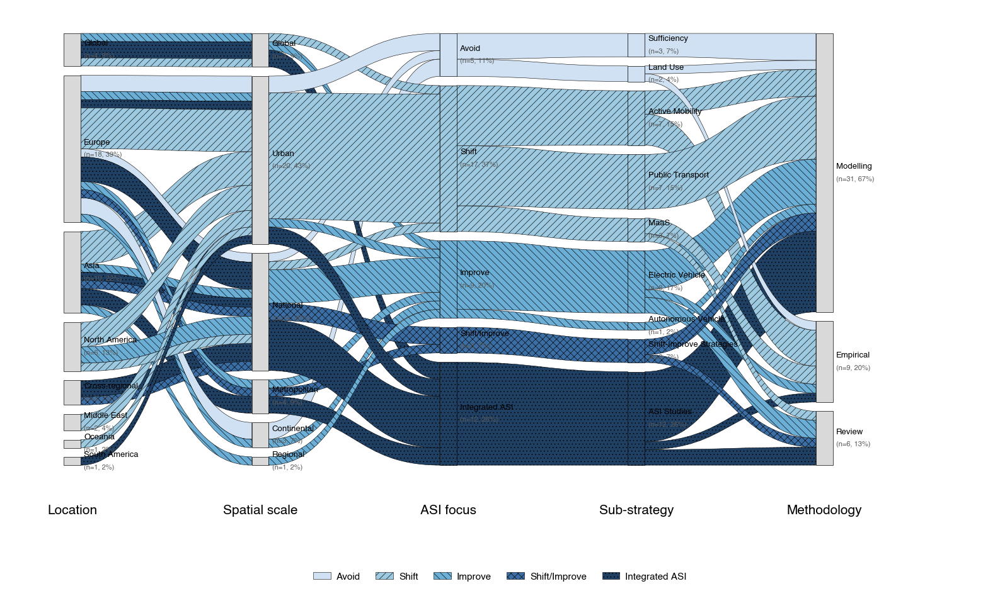

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
import matplotlib.patches as mpatches
from collections import defaultdict

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta y hatches -- IDÉNTICOS al gráfico de barras temporal
# ----------------------------------------------------------------------
PILLARS = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]
PILLAR_COLORS = dict(zip(PILLARS, ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#1f3f63"]))
PILLAR_HATCHES = dict(zip(PILLARS, ["", "///", "\\\\\\", "xxx", "..."]))
NEUTRAL_NODE_COLOR = "#d9d9d9"

SUBSTRATEGY_TO_STRATEGY = {
    "Sufficiency": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI",
}

# ----------------------------------------------------------------------
# 3. Orden estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

order_col2 = PILLARS

order_col3 = [
    "Sufficiency", "Land Use", "Active Mobility", "Public Transport", "MaaS",
    "Electric Vehicle", "Autonomous Vehicle", "Shift-Improve Strategies", "ASI Studies",
]

order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")

# ----------------------------------------------------------------------
# 4. Geometría de nodos (y=0 arriba, y=1 abajo; se invierte el eje al graficar)
# ----------------------------------------------------------------------
node_label, node_sub, node_x, node_top, node_bot = [], [], [], [], []
node_color, node_hatch, node_id = [], [], {}
GAP, Y_PAD = 0.02, 0.03

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD

    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        top, bot = y_cursor, y_cursor + height

        node_id[(stage_i, cat)] = len(node_label)
        node_label.append(cat)
        node_sub.append(f"(n={cnt}, {pct}%)")
        node_x.append(stage_i)
        node_top.append(top)
        node_bot.append(bot)

        if stage_i == ASI_STAGE_INDEX:
            pillar = cat
        elif stage_i == THEME_STAGE_INDEX:
            pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)
        else:
            pillar = None

        node_color.append(PILLAR_COLORS.get(pillar, NEUTRAL_NODE_COLOR))
        node_hatch.append(PILLAR_HATCHES.get(pillar, ""))

        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados/hatcheados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_pillar = [], [], [], []

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    # dict.fromkeys evita duplicar la columna cuando col_a o col_b ya ES "ASI focus"
    group_cols = list(dict.fromkeys([col_a, col_b, "ASI focus"]))
    grouped = df_complete.groupby(group_cols).size().reset_index(name="count")

    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["ASI focus"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_pillar.append(pillar)

# ----------------------------------------------------------------------
# 6. Sub-alturas de flujos dentro de cada nodo (evita solapes)
# ----------------------------------------------------------------------
node_out, node_in = defaultdict(list), defaultdict(list)
for li, (s, t) in enumerate(zip(link_source, link_target)):
    node_out[s].append(li)
    node_in[t].append(li)

node_y_center = [(top + bot) / 2 for top, bot in zip(node_top, node_bot)]
for idx in node_out:
    node_out[idx].sort(key=lambda li: node_y_center[link_target[li]])
for idx in node_in:
    node_in[idx].sort(key=lambda li: node_y_center[link_source[li]])

link_src_range, link_tgt_range = {}, {}
for idx in range(len(node_label)):
    top, bot = node_top[idx], node_bot[idx]
    height = bot - top

    outs = node_out.get(idx, [])
    tot_out = sum(link_value[li] for li in outs) or 1
    cur = top
    for li in outs:
        h = (link_value[li] / tot_out) * height
        link_src_range[li] = (cur, cur + h)
        cur += h

    ins = node_in.get(idx, [])
    tot_in = sum(link_value[li] for li in ins) or 1
    cur = top
    for li in ins:
        h = (link_value[li] / tot_in) * height
        link_tgt_range[li] = (cur, cur + h)
        cur += h

# ----------------------------------------------------------------------
# 7. Dibujo (Sankey 100% matplotlib: mismo motor de hatch que las barras)
# ----------------------------------------------------------------------
def sankey_ribbon(x0, x1, y0_top, y0_bot, y1_top, y1_bot, **kw):
    """Cinta de flujo con curvas Bezier cúbicas (estilo D3/Plotly Sankey)."""
    xm = (x0 + x1) / 2.0
    verts = [
        (x0, y0_top),
        (xm, y0_top), (xm, y1_top), (x1, y1_top),
        (x1, y1_bot),
        (xm, y1_bot), (xm, y0_bot), (x0, y0_bot),
        (x0, y0_top),
    ]
    codes = [Path.MOVETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.LINETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.CLOSEPOLY]
    return PathPatch(Path(verts, codes), **kw)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["hatch.linewidth"] = 0.45
plt.rcParams["pdf.fonttype"] = 42   # fuentes embebidas correctamente en el PDF

FS_LABEL = 9.5      # nombre de categoria
FS_SUB = 8          # (n=.., ..%) -- debajo del nombre
FS_TITLE = 15       # titulos de columna (Helvetica bold)
FS_LEGEND = 11

N_STAGES = len(STAGE_COL)
fig, ax = plt.subplots(figsize=(16, 9.5))
NODE_W = 0.09

# 7.1 Flujos primero (quedan debajo de los nodos) -- colores 100% opacos,
#     misma intensidad que las barras (sin alpha de atenuacion)
for li in range(len(link_source)):
    s, t = link_source[li], link_target[li]
    pillar = link_pillar[li]
    y0_top, y0_bot = link_src_range[li]
    y1_top, y1_bot = link_tgt_range[li]
    x0 = node_x[s] + NODE_W / 2
    x1 = node_x[t] - NODE_W / 2
    patch = sankey_ribbon(
        x0, x1, y0_top, y0_bot, y1_top, y1_bot,
        facecolor=PILLAR_COLORS[pillar], edgecolor="black", linewidth=0.4,
        hatch=PILLAR_HATCHES[pillar], zorder=1,
    )
    ax.add_patch(patch)

# 7.2 Nodos encima
for idx in range(len(node_label)):
    x = node_x[idx]
    y0, y1 = node_top[idx], node_bot[idx]
    rect = Rectangle(
        (x - NODE_W / 2, y0), NODE_W, y1 - y0,
        facecolor=node_color[idx], edgecolor="black", linewidth=0.5,
        hatch=node_hatch[idx], zorder=2,
    )
    ax.add_patch(rect)

    y_center = (y0 + y1) / 2
    x_text = x + NODE_W / 2 + 0.018
    # nombre de la categoria (arriba) y n/% debajo, separados verticalmente
    ax.text(x_text, y_center - 0.006, node_label[idx],
            fontsize=FS_LABEL, va="bottom", ha="left", zorder=3)
    ax.text(x_text, y_center + 0.006, node_sub[idx],
            fontsize=FS_SUB, color="0.35", va="top", ha="left", zorder=3)

# 7.3 Titulos de columna -- Helvetica bold, en la parte inferior del diagrama
TITLE_Y = 1.055
for i, title in enumerate(STAGE_TITLES):
    ax.text(i, TITLE_Y, title, fontsize=FS_TITLE,
            fontweight="bold", ha="center", va="top")

ax.set_xlim(-0.35, N_STAGES - 1 + 0.9)
ax.set_ylim(-0.03, 1.16)
ax.invert_yaxis()
ax.axis("off")

# 7.4 Leyenda de pilares -- misma intensidad de color/hatch, debajo de los titulos
legend_handles = [
    mpatches.Patch(facecolor=PILLAR_COLORS[p], edgecolor="black", linewidth=0.4,
                   hatch=PILLAR_HATCHES[p], label=p)
    for p in PILLARS
]
ax.legend(handles=legend_handles, ncol=5, frameon=False, fontsize=FS_LEGEND,
          loc="upper center", bbox_to_anchor=(0.5, -0.02), handlelength=1.8,
          handletextpad=0.6, columnspacing=1.6)

fig.tight_layout()
fig.savefig("fig_sankey_hatched.pdf", bbox_inches="tight")
fig.savefig("fig_sankey_hatched.png", dpi=300, bbox_inches="tight")
print("Guardado: fig_sankey_hatched.pdf / fig_sankey_hatched.png")

In [13]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ----------------------------------------------------------------------
# Load & prepare data
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)  # 46 -> percentages are reported as a share of this

# Studies missing any of the 5 dimensions can't form a complete flow path;
# drop them from the diagram itself (2 of 46) but keep percentages relative
# to the full corpus, as requested.
df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

# ----------------------------------------------------------------------
# Category mappings (raw values -> the grouping levels shown in the figure)
# ----------------------------------------------------------------------
REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "EV": "Electric Vehicle", "smart charging": "Electric Vehicle",
    "Active mobility (cycling / walking)": "Active mobility (cycling/walking)",
    "Full ASI": "ASI integrated studies",
    "Public transport / rail": "Public transport",
    "Sufficiency / behavioural": "Sufficiency / behavioural",
    "MaaS / shared mobility": "MaaS / shared mobility",
    "Shift-Improve combined": "Shift-Improve combined",
    "Land use / accessibility": "Land use / accessibility",
    "Modal shift (general)": "Modal shift (general)",
    "Autonomous vehicle": "Autonomous vehicle",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)
assert df_complete["Region_grp"].isna().sum() == 0, df_complete[df_complete["Region_grp"].isna()]
assert df_complete["Method_grp"].isna().sum() == 0
assert df_complete["Theme_grp"].isna().sum() == 0

STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_ORDER = [
    ["Global", "Europe", "North America", "Oceania", "Asia", "Middle East", "Cross-regional", "South America"],
    ["Global", "Continental", "National", "Regional", "Metropolitan", "Urban"],
    ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"],
    ["Sufficiency / behavioural", "Land use / accessibility", "Active mobility (cycling/walking)",
     "Public transport", "MaaS / shared mobility", "Electric Vehicle", "Autonomous vehicle",
     "Shift-Improve combined", "ASI integrated studies", "Modal shift (general)"],
    ["Empirical", "Modelling", "Review"],
]

PILLAR_COLORS = {
    "Avoid": "#deebf7", "Shift": "#9ecae1", "Improve": "#4292c6",
    "Shift/Improve": "#2171b5", "Integrated ASI": "#08306b",
}
NODE_COLOR = "#d9d9d9"

def hex_to_rgba(h, alpha):
    h = h.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"

# ----------------------------------------------------------------------
# Build node list (id, label, x, y) for all 5 stages
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
GAP = 0.036
Y_PAD = 0.06     # reserved top/bottom margin (fraction) so labels never touch the edge
ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n = len(present)
    avail = (1 - 2 * Y_PAD) - GAP * (n - 1)
    y_cursor = Y_PAD
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail
        y_center = y_cursor + height / 2
        node_id[(stage_i, cat)] = len(node_labels)
        node_labels.append(f"<b>{cat}<br>(n = {cnt}, {pct}%)</b>")
        node_x.append(0.001 + stage_i * (0.998 / (len(STAGE_COL) - 1)))
        node_y.append(min(max(y_center, Y_PAD * 0.3), 1 - Y_PAD * 0.3))
        node_colors.append(PILLAR_COLORS[cat] if stage_i == ASI_STAGE_INDEX else NODE_COLOR)
        y_cursor += height + GAP

# ----------------------------------------------------------------------
# Build links for each consecutive stage pair, colored by ASI pillar
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []

df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.8))

# ----------------------------------------------------------------------
# Assemble figure
# ----------------------------------------------------------------------
fig = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(
        label=node_labels, x=node_x, y=node_y,
        pad=25, thickness=16,
        color=node_colors,
        line=dict(width=0),
    ),
    link=dict(
        source=link_source, target=link_target, value=link_value, color=link_color,
    ),
    textfont=dict(family="Helvetica, Arial", size=42, color="black"),
))

fig.update_layout(
    font=dict(family="Helvetica, Arial", size=42, color="black"),
    plot_bgcolor="white", paper_bgcolor="white",
    margin=dict(l=80, r=80, t=80, b=120),
    width=4200, height=2600,
)

fig.write_image("fig_sankey.png", scale=2)
fig.write_image("fig_sankey.pdf")
n_excluded = N_FULL_CORPUS - N_FLOW
print(f"N in flow diagram: {N_FLOW} / {N_FULL_CORPUS} "
      f"({n_excluded} study excluded: incomplete cross-classification)"
      if n_excluded == 1 else
      f"N in flow diagram: {N_FLOW} / {N_FULL_CORPUS} "
      f"({n_excluded} studies excluded: incomplete cross-classification)")
print("Saved fig_sankey.png / .pdf")

N in flow diagram: 46 / 46 (0 studies excluded: incomplete cross-classification)
Saved fig_sankey.png / .pdf


In [15]:
# Modifica el arrangement a "freeform" o "snap" para permitir arrastrar nodos libremente
fig.update_traces(arrangement="freeform")

# Opción A: Abrir directamente en tu navegador web por defecto
fig.show()

fig.write_html("sankey_interactivo.html")


In [ ]:
# --------- -------------------------------------------------------------
# Assemble figure (Optimizado para evitar solapamientos)
# ----------------------------------------------------------------------
FONT_SIZE = 20  # Reducido de 36 a 20 para evitar colisión de texto

fig = go.Figure(go.Sankey(
    # 'snap' reordena verticalmente para minimizar cruces de líneas y evitar solapamientos
    arrangement="snap",
    node=dict(
        label=node_labels, 
        x=node_x, 
        y=node_y,
        pad=28,        # Aumentado para dar espacio entre bloques
        thickness=20,  # Ancho de las barras
        color=node_colors,
        line=dict(width=0.5, color="rgba(0,0,0,0.3)"),
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Helvetica, Arial", size=FONT_SIZE, color="black"),
))

fig.update_layout(
    font=dict(family="Helvetica, Arial", size=FONT_SIZE, color="black"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=100, r=100, t=60, b=80),
    width=3800, 
    height=2200,
)

fig.write_image("fig_sankey_test.png", scale=2)
fig.write_image("fig_sankey_test.pdf")


In [17]:
# ----------------------------------------------------------------------
# Build node list (id, label, x) - SIN node_y para activar auto-layout
# ----------------------------------------------------------------------
node_labels, node_x, node_colors, node_id = [], [], [], {}
ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        node_id[(stage_i, cat)] = len(node_labels)
        
        # Formato de etiqueta limpio para Nature (en una sola línea corta o 2 bien balanceadas)
        node_labels.append(f"<b>{cat}</b><br>({cnt}, {pct}%)")
        
        # Fijamos solo la columna X (de 0.0 a 1.0)
        node_x.append(0.001 + stage_i * (0.998 / (len(STAGE_COL) - 1)))
        node_colors.append(PILLAR_COLORS[cat] if stage_i == ASI_STAGE_INDEX else NODE_COLOR)

# ----------------------------------------------------------------------
# Build links
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        # Reducimos opacidad a 0.45 para transparencia profesional tipo Nature
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 1))

# ----------------------------------------------------------------------
# Assemble figure with Automatic Optimization
# ----------------------------------------------------------------------
fig = go.Figure(go.Sankey(
    # "snap" o "perpendicular" le permite al algoritmo D3 ordenar los nodos en Y
    arrangement="snap",
    node=dict(
        label=node_labels, 
        x=node_x,
        # NO pasamos node_y aquí -> Activa la auto-optimización
        pad=22,           # Separación vertical mínima entre bloques
        thickness=16,     # Ancho elegante de las barras
        color=node_colors,
        line=dict(width=0.5, color="#444444"), # Borde fino para definición
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica, sans-serif", size=14, color="#111111"),
))

fig.update_layout(
    font=dict(family="Arial, Helvetica, sans-serif", size=14, color="#111111"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=60, r=60, t=40, b=40),
    width=2400,  # Proporción limpia para exportación vectorial
    height=1300,
)

# Exportación vectorial (SVG/PDF es lo exigido por Nature)
fig.write_image("fig_sankey_nature.pdf")
fig.write_image("fig_sankey_nature.svg")
fig.write_image("fig_sankey_nature.png", scale=3)

print("Diagrama optimizado guardado exitosamente en PDF/SVG/PNG.")

Diagrama optimizado guardado exitosamente en PDF/SVG/PNG.


In [20]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ... (Mantén tu carga de datos y mapeos iniciales igual) ...

# ----------------------------------------------------------------------
# Definición dinámica de STAGE_ORDER según tus reglas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]

# Columna 1 (Region_grp): "Global" primero, luego de mayor a menor frecuencia
counts_col0 = df_complete["Region_grp"].value_counts()  # value_counts ya ordena de mayor a menor
order_col0 = ["Global"] + [cat for cat in counts_col0.index if cat != "Global"]

# Columna 2 (Spatial scale): "Global" primero, luego de mayor a menor frecuencia
counts_col1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in counts_col1.index if cat != "Global"]

# Columna 3 (ASI focus): Orden específico solicitado
order_col2 = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

# Columna 4 y 5: Mantener orden predeterminado o por frecuencia
order_col3 = [
    "Sufficiency / behavioural", "Land use / accessibility", "Active mobility (cycling/walking)",
    "Public transport", "MaaS / shared mobility", "Electric Vehicle", "Autonomous vehicle",
    "Shift-Improve combined", "ASI integrated studies", "Modal shift (general)"
]
order_col4 = ["Empirical", "Modelling", "Review"]

# Unimos todos los órdenes
STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

# ----------------------------------------------------------------------
# Build node list (id, label, x, y) respetando el nuevo orden estricto
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
GAP = 0.025      # Espaciado vertical entre nodos
Y_PAD = 0.05    # Margen superior/inferior
ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n = len(present)
    avail = (1 - 2 * Y_PAD) - GAP * (n - 1)
    y_cursor = Y_PAD
    
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail
        y_center = y_cursor + height / 2
        
        node_id[(stage_i, cat)] = len(node_labels)
        # Etiqueta compacta en 2 líneas para evitar solapamientos tipográficos
        node_labels.append(f"<b>{cat}</b><br>({cnt}, {pct}%)")
        
        node_x.append(0.001 + stage_i * (0.998 / (len(STAGE_COL) - 1)))
        node_y.append(min(max(y_center, Y_PAD * 0.3), 1 - Y_PAD * 0.3))
        node_colors.append(PILLAR_COLORS[cat] if stage_i == ASI_STAGE_INDEX else NODE_COLOR)
        
        y_cursor += height + GAP

# ----------------------------------------------------------------------
# Build links
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.75)) # Transparencia elegante

# ----------------------------------------------------------------------
# Assemble figure
# ----------------------------------------------------------------------
FONT_SIZE = 20  # Tamaños de letra óptimos para publicaciones científicas en lienzo 2500px

fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
        label=node_labels, 
        x=node_x, 
        y=node_y,
        pad=20, 
        thickness=18,
        color=node_colors,
        #line=dict(width=0.5, color="#333333"),
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica", size=FONT_SIZE, color="black"),
))

fig.update_layout(
    font=dict(family="Arial, Helvetica", size=FONT_SIZE, color="black"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=80, r=80, t=50, b=50),
    width=2600, 
    height=1400,
)

fig.write_image("fig_sankey.png", scale=2)
fig.write_image("fig_sankey.pdf")
print("Guardado correctamente con el orden personalizado.")

Guardado correctamente con el orden personalizado.


In [21]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

# Mapeos
REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "EV": "Electric Vehicle", "smart charging": "Electric Vehicle",
    "Active mobility (cycling / walking)": "Active mobility (cycling/walking)",
    "Full ASI": "ASI integrated studies",
    "Public transport / rail": "Public transport",
    "Sufficiency / behavioural": "Sufficiency / behavioural",
    "MaaS / shared mobility": "MaaS / shared mobility",
    "Shift-Improve combined": "Shift-Improve combined",
    "Land use / accessibility": "Land use / accessibility",
    "Modal shift (general)": "Modal shift (general)",
    "Autonomous vehicle": "Autonomous vehicle",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Ordenamiento científico y personalizado de las columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Region / Location", "Spatial Scale", "ASI Focus", "Sub-strategy", "Methodology"]

# Columna 1: "Global" primero, luego orden descendente por frecuencia (n)
c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

# Columna 2: "Global" primero, luego orden descendente por frecuencia (n)
c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

# Columna 3: Orden estricto solicitado
order_col2 = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

# Columnas 4 y 5: Ordenadas automáticamente por frecuencia (n) para mantener limpieza
c3 = df_complete["Theme_grp"].value_counts()
order_col3 = list(c3.index)

c4 = df_complete["Method_grp"].value_counts()
order_col4 = list(c4.index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

# ----------------------------------------------------------------------
# 3. Paleta de colores profesional (Nature Style)
# ----------------------------------------------------------------------
PILLAR_COLORS = {
    "Avoid": "#43A047",           # Verde ambiental suave
    "Shift": "#1E88E5",           # Azul primario
    "Improve": "#FB8C00",         # Naranja cálido
    "Shift/Improve": "#8E24AA",   # Púrpura
    "Integrated ASI": "#3949AB",  # Índigo profundo
}
NEUTRAL_NODE_COLOR = "#CFD8DC"  # Gris neutro pub-ready (Cool Gray)

def hex_to_rgba(h, alpha):
    h = h.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"

# ----------------------------------------------------------------------
# 4. Cálculo geométrico estricto sin solapamientos
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
GAP = 0.028      # Espaciado proporcional entre nodos
Y_PAD = 0.04    # Margen superior/inferior interno
ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD
    
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        y_center = y_cursor + height / 2.0
        
        node_id[(stage_i, cat)] = len(node_labels)
        
        # Formato de etiqueta científico: Cursiva para 'n' (estándar Nature/APA)
        node_labels.append(f"<b>{cat}</b><br><i>n</i> = {cnt} ({pct}%)")
        
        node_x.append(stage_i / (len(STAGE_COL) - 1))
        node_y.append(min(max(y_center, Y_PAD * 0.2), 1 - Y_PAD * 0.2))
        node_colors.append(PILLAR_COLORS[cat] if stage_i == ASI_STAGE_INDEX else NEUTRAL_NODE_COLOR)
        
        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Generación de enlaces con opacidad balanceada
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        # 0.35 de alfa para una visualización cristalina de flujos complejos
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.35))

# ----------------------------------------------------------------------
# 6. Encabezados científicos (Anotaciones)
# ----------------------------------------------------------------------
annotations = []
for i, title in enumerate(STAGE_TITLES):
    x_pos = i / (len(STAGE_TITLES) - 1)
    annotations.append(dict(
        x=x_pos, y=1.02,
        xref="paper", yref="paper",
        text=f"<b>{title}</b>",
        showarrow=False,
        font=dict(family="Arial, Helvetica", size=16, color="#111111"),
        xanchor="center"
    ))

# ----------------------------------------------------------------------
# 7. Ensamblado de la Figura
# ----------------------------------------------------------------------
fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
        label=node_labels,
        x=node_x,
        y=node_y,
        pad=18,
        thickness=16,
        color=node_colors,
        line=dict(width=0.6, color="#374151"), # Borde fino para definición gráfica
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica", size=12, color="#111827"),
))

fig.update_layout(
    annotations=annotations,
    font=dict(family="Arial, Helvetica", size=12, color="#111827"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=140, r=140, t=80, b=50), # Margen amplio para evitar corte de textos externos
    width=2200, 
    height=1200,
)

# Exportación doble vectorial + PNG alta resolución (300 DPI equivalente)
fig.write_image("fig_sankey_nature.pdf")
fig.write_image("fig_sankey_nature.svg")
fig.write_image("fig_sankey_nature.png", scale=3)

print("Figura científica exportada exitosamente en PDF, SVG y PNG (300 DPI).")

Figura científica exportada exitosamente en PDF, SVG y PNG (300 DPI).


In [2]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

# Mapeos
REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "EV": "Electric Vehicle", "smart charging": "Electric Vehicle",
    "Active mobility (cycling / walking)": "Active mobility (cycling/walking)",
    "Full ASI": "ASI integrated studies",
    "Public transport / rail": "Public transport",
    "Sufficiency / behavioural": "Sufficiency / behavioural",
    "MaaS / shared mobility": "MaaS / shared mobility",
    "Shift-Improve combined": "Shift-Improve combined",
    "Land use / accessibility": "Land use / accessibility",
    "Modal shift (general)": "Modal shift (general)",
    "Autonomous vehicle": "Autonomous vehicle",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta cromática idéntica a la Figura 1 (Sequential Blues)
# ----------------------------------------------------------------------
PILLAR_COLORS = {
    "Avoid": "#deebf7",          # Azul muy claro (idéntico a Fig 1)
    "Shift": "#9ecae1",          # Azul claro
    "Improve": "#4292c6",        # Azul medio
    "Shift/Improve": "#2171b5",  # Azul oscuro
    "Integrated ASI": "#08306b", # Azul marino profundo
}
NEUTRAL_NODE_COLOR = "#d9d9d9"  # Gris neutro limpio para las demás columnas

def hex_to_rgba(h, alpha):
    h = h.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"

# ----------------------------------------------------------------------
# 3. Ordenamiento estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

# Columna 1: "Global" primero, el resto ordenado por frecuencia descendente
c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

# Columna 2: "Global" primero, el resto ordenado por frecuencia descendente
c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

# Columna 3: Orden temático estricto del paper
order_col2 = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

# Columnas 4 y 5: Orden por frecuencia descendente para mayor cohesión visual
order_col3 = list(df_complete["Theme_grp"].value_counts().index)
order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

# ----------------------------------------------------------------------
# 4. Geometría libre de solapamientos
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
GAP = 0.025      # Espaciado vertical entre bloques
Y_PAD = 0.04    # Margen superior/inferior interno
ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD
    
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        y_center = y_cursor + height / 2.0
        
        node_id[(stage_i, cat)] = len(node_labels)
        
        # Formato de etiqueta científico estándar
        node_labels.append(f"<b>{cat}</b><br><i>n</i> = {cnt} ({pct}%)")
        
        node_x.append(stage_i / (len(STAGE_COL) - 1))
        node_y.append(min(max(y_center, Y_PAD * 0.2), 1 - Y_PAD * 0.2))
        node_colors.append(PILLAR_COLORS[cat] if stage_i == ASI_STAGE_INDEX else NEUTRAL_NODE_COLOR)
        
        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        # Alfa de 0.45 para una mezcla limpia de los tonos azules
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.9))

# ----------------------------------------------------------------------
# 6. Encabezados superiores (Titulares de columna)
# ----------------------------------------------------------------------
annotations = []
for i, title in enumerate(STAGE_TITLES):
    annotations.append(dict(
        x=i / (len(STAGE_TITLES) - 1), y=1.03,
        xref="paper", yref="paper",
        text=f"<b>{title}</b>",
        showarrow=False,
        font=dict(family="Arial, Helvetica", size=15, color="#111111"),
        xanchor="center"
    ))

# ----------------------------------------------------------------------
# 7. Ensamblado y Exportación
# ----------------------------------------------------------------------
fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
        label=node_labels,
        x=node_x,
        y=node_y,
        pad=18,
        thickness=16,
        color=node_colors,
        line=dict(width=0.5, color="#555555"),
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica", size=24, color="#111111"),
))

fig.update_layout(
    annotations=annotations,
    font=dict(family="Arial, Helvetica", size=24, color="#111111"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=120, r=120, t=70, b=50),
    width=2400, 
    height=1300,
)

# Exportación en formatos vectoriales e imagen
fig.write_image("fig_sankey_consistent.pdf")
fig.write_image("fig_sankey_consistent.svg")
fig.write_image("fig_sankey_consistent.png", scale=3)

print("Diagrama guardado con éxito y paleta idéntica a la Figura 1.")

Diagrama guardado con éxito y paleta idéntica a la Figura 1.


In [9]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

# Mapeos
REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta cromática idéntica a la Figura 1 (Sequential Blues)
# ----------------------------------------------------------------------
PILLAR_COLORS = {
    "Avoid": "#deebf7",          # Azul muy claro
    "Shift": "#9ecae1",          # Azul claro
    "Improve": "#4292c6",        # Azul medio
    "Shift/Improve": "#2171b5",  # Azul oscuro
    "Integrated ASI": "#08306b", # Azul marino profundo
}
NEUTRAL_NODE_COLOR = "#d9d9d9"  # Gris neutro limpio

def hex_to_rgba(h, alpha):
    h = h.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"



# ----------------------------------------------------------------------
# 3. Ordenamiento estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

# Columna 1: "Global" primero, el resto ordenado por frecuencia descendente
c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

# Columna 2: "Global" primero, el resto ordenado por frecuencia descendente
c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

# Columna 3: Orden temático estricto del paper
order_col2 = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

# Columna 4: Orden temático estricto personalizado para Sub-strategies
order_col3 = [
    "Sufficiency",
    "Land Use",
    "Active Mobility",
    "Public Transport",
    "MaaS",
    "Electric Vehicle",
    "Autonomous Vehicle",
    "Shift-Improve Strategies",
    "ASI Studies"
]



# Columna 5: Orden por frecuencia descendente
order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

# ----------------------------------------------------------------------
# 4. Geometría libre de solapamientos
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
GAP = 0.025      # Espaciado vertical entre bloques
Y_PAD = 0.04    # Margen superior/inferior interno
ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD
    
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        y_center = y_cursor + height / 2.0
        
        node_id[(stage_i, cat)] = len(node_labels)
        
        # Formato de etiqueta científico estándar
        node_labels.append(f"<b>{cat}</b><br><i>n</i> = {cnt} ({pct}%)")
        
        node_x.append(stage_i / (len(STAGE_COL) - 1))
        node_y.append(min(max(y_center, Y_PAD * 0.2), 1 - Y_PAD * 0.2))
        node_colors.append(PILLAR_COLORS[cat] if stage_i == ASI_STAGE_INDEX else NEUTRAL_NODE_COLOR)
        
        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.9))

# ----------------------------------------------------------------------
# 6. Encabezados superiores
# ----------------------------------------------------------------------
annotations = []
for i, title in enumerate(STAGE_TITLES):
    annotations.append(dict(
        x=i / (len(STAGE_TITLES) - 1), y=1.03,
        xref="paper", yref="paper",
        text=f"<b>{title}</b>",
        showarrow=False,
        font=dict(family="Arial, Helvetica", size=30, color="#111111"),
        xanchor="center"
    ))

# ----------------------------------------------------------------------
# 7. Ensamblado y Exportación
# ----------------------------------------------------------------------
fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
        label=node_labels,
        x=node_x,
        y=node_y,
        pad=18,
        thickness=16,
        color=node_colors,
        line=dict(width=0.5, color="#555555"),
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica", size=24, color="#111111"),
))

fig.update_layout(
    annotations=annotations,
    font=dict(family="Arial, Helvetica", size=24, color="#111111"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=120, r=120, t=70, b=50),
    width=2400, 
    height=1300,
)

# Exportación de imágenes
fig.write_image("fig_sankey_consistent.pdf")
fig.write_image("fig_sankey_consistent.svg")
fig.write_image("fig_sankey_consistent.png", scale=3)

print("Diagrama guardado con éxito y el orden de 'Sub-strategy' actualizado.")

Diagrama guardado con éxito y el orden de 'Sub-strategy' actualizado.


In [6]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

# Mapeos
REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta cromática idéntica a la Figura 1 (Sequential Blues)
# ----------------------------------------------------------------------
PILLAR_COLORS = {
    "Avoid": "#deebf7",          # Azul muy claro
    "Shift": "#9ecae1",          # Azul claro
    "Improve": "#4292c6",        # Azul medio
    "Shift/Improve": "#2171b5",  # Azul oscuro
    "Integrated ASI": "#08306b", # Azul marino profundo
}
NEUTRAL_NODE_COLOR = "#d9d9d9"  # Gris neutro limpio

def hex_to_rgba(h, alpha):
    h = h.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"

# ----------------------------------------------------------------------
# 3. Ordenamiento de columnas (Sin forzar 'Global' al inicio)
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

# Columna 1: Frecuencia descendente natural
order_col0 = list(df_complete["Region_grp"].value_counts().index)

# Columna 2: Frecuencia descendente natural
order_col1 = list(df_complete["Spatial scale"].value_counts().index)

# Columna 3: Orden temático estricto
order_col2 = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

# Columna 4: Orden temático estricto para Sub-strategies
order_col3 = [
    "Sufficiency",
    "Land Use",
    "Active Mobility",
    "Public Transport",
    "MaaS",
    "Electric Vehicle",
    "Autonomous Vehicle",
    "Shift-Improve Strategies",
    "ASI Studies"
]

# Columna 5: Frecuencia descendente natural
order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

# ----------------------------------------------------------------------
# 4. Geometría libre de solapamientos
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
GAP = 0.025      # Espaciado vertical entre bloques
Y_PAD = 0.04    # Margen superior/inferior interno
ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD
    
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        y_center = y_cursor + height / 2.0
        
        node_id[(stage_i, cat)] = len(node_labels)
        
        # Formato de etiqueta
        node_labels.append(f"<b>{cat}</b><br><i>n</i> = {cnt} ({pct}%)")
        
        node_x.append(stage_i / (len(STAGE_COL) - 1))
        node_y.append(min(max(y_center, Y_PAD * 0.2), 1 - Y_PAD * 0.2))
        node_colors.append(PILLAR_COLORS[cat] if stage_i == ASI_STAGE_INDEX else NEUTRAL_NODE_COLOR)
        
        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.9))

# ----------------------------------------------------------------------
# 6. Encabezados superiores
# ----------------------------------------------------------------------
annotations = []
for i, title in enumerate(STAGE_TITLES):
    annotations.append(dict(
        x=i / (len(STAGE_TITLES) - 1), y=1.03,
        xref="paper", yref="paper",
        text=f"<b>{title}</b>",
        showarrow=False,
        font=dict(family="Arial, Helvetica", size=30, color="#111111"),
        xanchor="center"
    ))

# ----------------------------------------------------------------------
# 7. Ensamblado y Exportación
# ----------------------------------------------------------------------
fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
        label=node_labels,
        x=node_x,
        y=node_y,
        pad=18,
        thickness=16,
        color=node_colors,
        line=dict(width=0.5, color="#555555"),
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica", size=24, color="#111111"),
))

fig.update_layout(
    annotations=annotations,
    font=dict(family="Arial, Helvetica", size=24, color="#111111"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=120, r=120, t=70, b=50),
    width=2400, 
    height=1300,
)

# Exportación de imágenes
fig.write_image("fig_sankey_consistent_new.pdf")
fig.write_image("fig_sankey_consistent_new.svg")
fig.write_image("fig_sankey_consistent_new.png", scale=3)

print("Diagrama guardado con éxito con las dos primeras columnas sin forzar orden especial.")

Diagrama guardado con éxito con las dos primeras columnas sin forzar orden especial.


In [7]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

# Mapeos
REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta cromática idéntica a la Figura 1 (Sequential Blues)
# ----------------------------------------------------------------------
PILLAR_COLORS = {
    "Avoid": "#deebf7",          # Azul muy claro
    "Shift": "#9ecae1",          # Azul claro
    "Improve": "#4292c6",        # Azul medio
    "Shift/Improve": "#2171b5",  # Azul oscuro
    "Integrated ASI": "#08306b", # Azul marino profundo
}
NEUTRAL_NODE_COLOR = "#d9d9d9"  # Gris neutro limpio

def hex_to_rgba(h, alpha):
    h = h.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"

# ----------------------------------------------------------------------
# 3. Ordenamiento por Algoritmo de Baricentro (Minimizar cruces de flujos)
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

# Columna 0: Ordenada por frecuencia descendente
order_col0 = list(df_complete["Region_grp"].value_counts().index)
pos_col0 = {cat: idx for idx, cat in enumerate(order_col0)}

# Columna 1: Calculamos el baricentro con respecto a la Columna 0
crosstab_01 = pd.crosstab(df_complete["Spatial scale"], df_complete["Region_grp"])

barycenters_col1 = {}
for scale in crosstab_01.index:
    counts = crosstab_01.loc[scale]
    total_flow = counts.sum()
    if total_flow > 0:
        weighted_sum = sum(counts[reg] * pos_col0[reg] for reg in counts.index if reg in pos_col0)
        barycenters_col1[scale] = weighted_sum / total_flow
    else:
        barycenters_col1[scale] = 999

order_col1 = sorted(barycenters_col1.keys(), key=lambda x: barycenters_col1[x])

# Columna 3: Orden temático estricto del paper
order_col2 = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

# Columna 4: Orden temático estricto para Sub-strategies
order_col3 = [
    "Sufficiency",
    "Land Use",
    "Active Mobility",
    "Public Transport",
    "MaaS",
    "Electric Vehicle",
    "Autonomous Vehicle",
    "Shift-Improve Strategies",
    "ASI Studies"
]

# Columna 5: Frecuencia descendente
order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

# ----------------------------------------------------------------------
# 4. Geometría libre de solapamientos
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
GAP = 0.025      # Espaciado vertical entre bloques
Y_PAD = 0.04    # Margen superior/inferior interno
ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD
    
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        y_center = y_cursor + height / 2.0
        
        node_id[(stage_i, cat)] = len(node_labels)
        
        node_labels.append(f"<b>{cat}</b><br><i>n</i> = {cnt} ({pct}%)")
        
        node_x.append(stage_i / (len(STAGE_COL) - 1))
        node_y.append(min(max(y_center, Y_PAD * 0.2), 1 - Y_PAD * 0.2))
        node_colors.append(PILLAR_COLORS[cat] if stage_i == ASI_STAGE_INDEX else NEUTRAL_NODE_COLOR)
        
        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.9))

# ----------------------------------------------------------------------
# 6. Encabezados superiores
# ----------------------------------------------------------------------
annotations = []
for i, title in enumerate(STAGE_TITLES):
    annotations.append(dict(
        x=i / (len(STAGE_TITLES) - 1), y=1.03,
        xref="paper", yref="paper",
        text=f"<b>{title}</b>",
        showarrow=False,
        font=dict(family="Arial, Helvetica", size=30, color="#111111"),
        xanchor="center"
    ))

# ----------------------------------------------------------------------
# 7. Ensamblado y Exportación
# ----------------------------------------------------------------------
fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
        label=node_labels,
        x=node_x,
        y=node_y,
        pad=18,
        thickness=16,
        color=node_colors,
        line=dict(width=0.5, color="#555555"),
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica", size=24, color="#111111"),
))

fig.update_layout(
    annotations=annotations,
    font=dict(family="Arial, Helvetica", size=24, color="#111111"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=120, r=120, t=70, b=50),
    width=2400, 
    height=1300,
)

# Exportación de imágenes
fig.write_image("fig_sankey_consistent_test.pdf")
fig.write_image("fig_sankey_consistent_test.svg")
fig.write_image("fig_sankey_consistent_test.png", scale=3)

print("Diagrama generado minimizando cruces de flujos mediante algoritmo de baricentro.")

Diagrama generado minimizando cruces de flujos mediante algoritmo de baricentro.


In [8]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

# Selección de las 4 columnas objetivo
DIM_COLS = ["Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()

# Mapeos
METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta cromática
# ----------------------------------------------------------------------
PILLAR_COLORS = {
    "Avoid": "#deebf7",          # Azul muy claro
    "Shift": "#9ecae1",          # Azul claro
    "Improve": "#4292c6",        # Azul medio
    "Shift/Improve": "#2171b5",  # Azul oscuro
    "Integrated ASI": "#08306b", # Azul marino profundo
}
NEUTRAL_NODE_COLOR = "#d9d9d9"  # Gris neutro limpio

def hex_to_rgba(h, alpha):
    h = h.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"

# ----------------------------------------------------------------------
# 3. Definición de 4 Columnas y su Orden
# ----------------------------------------------------------------------
STAGE_COL = ["Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

# Columna 1: Spatial scale (Frecuencia descendente)
order_col0 = list(df_complete["Spatial scale"].value_counts().index)

# Columna 2: ASI focus (Orden temático estricto)
order_col1 = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

# Columna 3: Sub-strategy (Orden temático estricto)
order_col2 = [
    "Sufficiency",
    "Land Use",
    "Active Mobility",
    "Public Transport",
    "MaaS",
    "Electric Vehicle",
    "Autonomous Vehicle",
    "Shift-Improve Strategies",
    "ASI Studies"
]

# Columna 4: Methodology (Frecuencia descendente)
order_col3 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3]

# ----------------------------------------------------------------------
# 4. Geometría y Posicionamiento de Nodos
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
GAP = 0.025      # Espaciado vertical entre bloques
Y_PAD = 0.04    # Margen interno
ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD
    
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        y_center = y_cursor + height / 2.0
        
        node_id[(stage_i, cat)] = len(node_labels)
        
        node_labels.append(f"<b>{cat}</b><br><i>n</i> = {cnt} ({pct}%)")
        
        # Posición horizontal distribuida en 4 columnas
        node_x.append(stage_i / (len(STAGE_COL) - 1))
        node_y.append(min(max(y_center, Y_PAD * 0.2), 1 - Y_PAD * 0.2))
        node_colors.append(PILLAR_COLORS[cat] if stage_i == ASI_STAGE_INDEX else NEUTRAL_NODE_COLOR)
        
        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Generación de Enlaces
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.9))

# ----------------------------------------------------------------------
# 6. Encabezados de las 4 Columnas
# ----------------------------------------------------------------------
annotations = []
for i, title in enumerate(STAGE_TITLES):
    annotations.append(dict(
        x=i / (len(STAGE_TITLES) - 1), y=1.03,
        xref="paper", yref="paper",
        text=f"<b>{title}</b>",
        showarrow=False,
        font=dict(family="Arial, Helvetica", size=30, color="#111111"),
        xanchor="center"
    ))

# ----------------------------------------------------------------------
# 7. Construcción y Exportación de la Figura
# ----------------------------------------------------------------------
fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
        label=node_labels,
        x=node_x,
        y=node_y,
        pad=18,
        thickness=16,
        color=node_colors,
        line=dict(width=0.5, color="#555555"),
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica", size=24, color="#111111"),
))

fig.update_layout(
    annotations=annotations,
    font=dict(family="Arial, Helvetica", size=24, color="#111111"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=120, r=120, t=70, b=50),
    width=2000, 
    height=1200,
)

# Renderizar en pantalla o exportar
fig.write_image("fig_sankey_4col.png", scale=3)
fig.show()

In [21]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

# Mapeos
REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta cromática y mapeo Sub-strategy -> Strategy (ASI Focus)
# ----------------------------------------------------------------------
PILLAR_COLORS = {
    "Avoid": "#deebf7",          # Azul muy claro
    "Shift": "#9ecae1",          # Azul claro
    "Improve": "#4292c6",        # Azul medio
    "Shift/Improve": "#2171b5",  # Azul oscuro
    "Integrated ASI": "#08306b", # Azul marino profundo
}
NEUTRAL_NODE_COLOR = "#d9d9d9"  # Gris neutro limpio

# Mapeo directo para asociar cada sub-estrategia a su pilar principal
SUBSTRATEGY_TO_STRATEGY = {
    "Sufficiency": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI"
}

def hex_to_rgba(h, alpha):
    h = h.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"

# ----------------------------------------------------------------------
# 3. Ordenamiento estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

# Columna 1: "Global" primero, el resto por frecuencia descendente
c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

# Columna 2: "Global" primero, el resto por frecuencia descendente
c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

# Columna 3: Orden temático estricto del paper
order_col2 = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

# Columna 4: Orden temático estricto para Sub-strategies
order_col3 = [
    "Sufficiency",
    "Land Use",
    "Active Mobility",
    "Public Transport",
    "MaaS",
    "Electric Vehicle",
    "Autonomous Vehicle",
    "Shift-Improve Strategies",
    "ASI Studies"
]

# Columna 5: Orden por frecuencia descendente
order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

# ----------------------------------------------------------------------
# 4. Geometría libre de solapamientos y coloración de nodos
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
GAP = 0.025      # Espaciado vertical entre bloques
Y_PAD = 0.04    # Margen superior/inferior interno

ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD
    
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        y_center = y_cursor + height / 2.0
        
        node_id[(stage_i, cat)] = len(node_labels)
        
        # Formato de etiqueta científico estándar
        node_labels.append(f"<b>{cat}</b><br><i>n</i> = {cnt} ({pct}%)")
        
        node_x.append(stage_i / (len(STAGE_COL) - 1))
        node_y.append(min(max(y_center, Y_PAD * 0.2), 1 - Y_PAD * 0.2))
        
        # Asignación de color: ASI Focus o Sub-strategy mediante su pilar
        if stage_i == ASI_STAGE_INDEX:
            node_colors.append(PILLAR_COLORS[cat])
        elif stage_i == THEME_STAGE_INDEX:
            strategy_pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)
            node_colors.append(PILLAR_COLORS.get(strategy_pillar, NEUTRAL_NODE_COLOR))
        else:
            node_colors.append(NEUTRAL_NODE_COLOR)
        
        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.9))

# ----------------------------------------------------------------------
# 6. Encabezados superiores
# ----------------------------------------------------------------------
annotations = []
for i, title in enumerate(STAGE_TITLES):
    annotations.append(dict(
        x=i / (len(STAGE_TITLES) - 1), y=1.03,
        xref="paper", yref="paper",
        text=f"<b>{title}</b>",
        showarrow=False,
        font=dict(family="Arial, Helvetica", size=30, color="#111111"),
        xanchor="center"
    ))

# ----------------------------------------------------------------------
# 7. Ensamblado y Exportación
# ----------------------------------------------------------------------
fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
        label=node_labels,
        x=node_x,
        y=node_y,
        pad=18,
        thickness=16,
        color=node_colors,
        line=dict(width=0.5, color="#555555"),
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica", size=24, color="#111111"),
))

fig.update_layout(
    annotations=annotations,
    font=dict(family="Arial, Helvetica", size=24, color="#111111"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=120, r=120, t=70, b=50),
    width=2400, 
    height=1300,
)

# Exportación de imágenes
fig.write_image("fig_sankey_consistent.pdf")
fig.write_image("fig_sankey_consistent.svg")
fig.write_image("fig_sankey_consistent.png", scale=3)

print("Diagrama guardado con éxito con colores asignados a las sub-estrategias.")

Diagrama guardado con éxito con colores asignados a las sub-estrategias.


In [22]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

# Mapeos
REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta cromática y mapeo Sub-strategy -> Strategy (ASI Focus)
# ----------------------------------------------------------------------
PILLAR_COLORS = {
    "Avoid": "#deebf7",          # Azul muy claro
    "Shift": "#9ecae1",          # Azul claro
    "Improve": "#4292c6",        # Azul medio
    "Shift/Improve": "#2171b5",  # Azul oscuro
    "Integrated ASI": "#08306b", # Azul marino profundo
}
NEUTRAL_NODE_COLOR = "#d9d9d9"  # Gris neutro limpio

SUBSTRATEGY_TO_STRATEGY = {
    "Sufficiency": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI"
}

def hex_to_rgba(h, alpha):
    h = h.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"

# ----------------------------------------------------------------------
# 3. Ordenamiento estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

order_col2 = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

order_col3 = [
    "Sufficiency",
    "Land Use",
    "Active Mobility",
    "Public Transport",
    "MaaS",
    "Electric Vehicle",
    "Autonomous Vehicle",
    "Shift-Improve Strategies",
    "ASI Studies"
]

order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

# ----------------------------------------------------------------------
# 4. Geometría libre de solapamientos y coloración de nodos
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
GAP = 0.025      
Y_PAD = 0.04    

ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD
    
    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        y_center = y_cursor + height / 2.0
        
        node_id[(stage_i, cat)] = len(node_labels)
        
        node_labels.append(f"<b>{cat}</b><br><i>n</i> = {cnt} ({pct}%)")
        
        node_x.append(stage_i / (len(STAGE_COL) - 1))
        node_y.append(min(max(y_center, Y_PAD * 0.2), 1 - Y_PAD * 0.2))
        
        if stage_i == ASI_STAGE_INDEX:
            node_colors.append(PILLAR_COLORS[cat])
        elif stage_i == THEME_STAGE_INDEX:
            strategy_pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)
            node_colors.append(PILLAR_COLORS.get(strategy_pillar, NEUTRAL_NODE_COLOR))
        else:
            node_colors.append(NEUTRAL_NODE_COLOR)
        
        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.9))

# ----------------------------------------------------------------------
# 6. Títulos en la parte inferior (Anotaciones)
# ----------------------------------------------------------------------
annotations = []
for i, title in enumerate(STAGE_TITLES):
    annotations.append(dict(
        x=i / (len(STAGE_TITLES) - 1),
        y=-0.05,                   # Posicionado debajo de la figura
        xref="paper", 
        yref="paper",
        text=f"<b>{title}</b>",
        showarrow=False,
        font=dict(family="Arial, Helvetica", size=28, color="#111111"),
        xanchor="center",
        yanchor="top"              # Anclaje superior para expandir hacia abajo
    ))

# ----------------------------------------------------------------------
# 7. Ensamblado y Exportación
# ----------------------------------------------------------------------
fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
        label=node_labels,
        x=node_x,
        y=node_y,
        pad=18,
        thickness=16,
        color=node_colors,
        line=dict(width=0.5, color="#555555"),
    ),
    link=dict(
        source=link_source, 
        target=link_target, 
        value=link_value, 
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica", size=22, color="#111111"),
))

fig.update_layout(
    annotations=annotations,
    font=dict(family="Arial, Helvetica", size=22, color="#111111"),
    plot_bgcolor="white", 
    paper_bgcolor="white",
    margin=dict(l=120, r=120, t=40, b=100),  # Margen superior reducido y margen inferior ampliado
    width=2400, 
    height=1300,
)

# Exportación de imágenes
fig.write_image("fig_sankey_consistent.pdf")
fig.write_image("fig_sankey_consistent.svg")
fig.write_image("fig_sankey_consistent.png", scale=3)

print("Diagrama guardado con éxito con los títulos situados en la parte inferior.")

Diagrama guardado con éxito con los títulos situados en la parte inferior.


In [15]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta cromática, mapeo Sub-strategy -> Strategy, y HATCHES por pilar
# ----------------------------------------------------------------------
PILLAR_COLORS = {
    "Avoid": "#deebf7",
    "Shift": "#9ecae1",
    "Improve": "#4292c6",
    "Shift/Improve": "#2171b5",
    "Integrated ASI": "#08306b",
}
NEUTRAL_NODE_COLOR = "#d9d9d9"

# Mismos patrones que en el gráfico de barras (densidad progresiva)
PILLAR_HATCHES = {
    "Avoid": "",      # sólido, sin patrón (categoría base)
    "Shift": "/",
    "Improve": "\\",
    "Shift/Improve": "x",
    "Integrated ASI": ".",
}

SUBSTRATEGY_TO_STRATEGY = {
    "Sufficiency": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI"
}

def hex_to_rgba(h, alpha):
    h = h.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"

# ----------------------------------------------------------------------
# 3. Ordenamiento estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

order_col2 = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]

order_col3 = [
    "Sufficiency", "Land Use", "Active Mobility", "Public Transport", "MaaS",
    "Electric Vehicle", "Autonomous Vehicle", "Shift-Improve Strategies", "ASI Studies"
]

order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

# ----------------------------------------------------------------------
# 4. Geometría de nodos — ahora guardamos también top/bottom y pilar
# ----------------------------------------------------------------------
node_labels, node_x, node_y, node_colors, node_id = [], [], [], [], {}
node_top, node_bottom, node_pillar = [], [], []   # <-- NUEVO: para las formas de hatch
GAP = 0.025
Y_PAD = 0.04

ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)

    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD

    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        y_center = y_cursor + height / 2.0
        y_top = y_cursor
        y_bot = y_cursor + height

        node_id[(stage_i, cat)] = len(node_labels)
        node_labels.append(f"<b>{cat}</b><br><i>n</i> = {cnt} ({pct}%)")
        node_x.append(stage_i / (len(STAGE_COL) - 1))
        node_y.append(min(max(y_center, Y_PAD * 0.2), 1 - Y_PAD * 0.2))
        node_top.append(y_top)
        node_bottom.append(y_bot)

        if stage_i == ASI_STAGE_INDEX:
            node_colors.append(PILLAR_COLORS[cat])
            node_pillar.append(cat)
        elif stage_i == THEME_STAGE_INDEX:
            strategy_pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)
            node_colors.append(PILLAR_COLORS.get(strategy_pillar, NEUTRAL_NODE_COLOR))
            node_pillar.append(strategy_pillar)
        else:
            node_colors.append(NEUTRAL_NODE_COLOR)
            node_pillar.append(None)   # sin pilar -> sin hatch

        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados por pilar ASI (sin cambios)
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_color = [], [], [], []
df_complete["_pillar"] = df_complete["ASI focus"]

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    grouped = (df_complete.groupby([col_a, col_b, "_pillar"]).size()
               .reset_index(name="count"))
    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["_pillar"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_color.append(hex_to_rgba(PILLAR_COLORS[pillar], 0.9))

# ----------------------------------------------------------------------
# 6. Títulos inferiores
# ----------------------------------------------------------------------
annotations = []
for i, title in enumerate(STAGE_TITLES):
    annotations.append(dict(
        x=i / (len(STAGE_TITLES) - 1), y=-0.05,
        xref="paper", yref="paper",
        text=f"<b>{title}</b>", showarrow=False,
        font=dict(family="Arial, Helvetica", size=28, color="#111111"),
        xanchor="center", yanchor="top"
    ))

# ----------------------------------------------------------------------
# 7. Ensamblado del Sankey
# ----------------------------------------------------------------------
NODE_THICKNESS = 16   # px — misma variable usada abajo para alinear las formas de hatch
FIG_W, FIG_H = 2400, 1300
MARGIN_L, MARGIN_R = 120, 120

fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
        label=node_labels,
        x=node_x,
        y=node_y,
        pad=18,
        thickness=NODE_THICKNESS,
        color=node_colors,
        line=dict(width=0.5, color="#555555"),
    ),
    link=dict(
        source=link_source,
        target=link_target,
        value=link_value,
        color=link_color,
    ),
    textfont=dict(family="Arial, Helvetica", size=22, color="#111111"),
))

fig.update_layout(
    annotations=annotations,
    font=dict(family="Arial, Helvetica", size=22, color="#111111"),
    plot_bgcolor="white",
    paper_bgcolor="white",
    margin=dict(l=MARGIN_L, r=MARGIN_R, t=40, b=100),
    width=FIG_W,
    height=FIG_H,
)
# ----------------------------------------------------------------------
# 8. Post-procesado SVG: hatch real en nodos Y en flujos (curvas incluidas)
# ----------------------------------------------------------------------
import re

# 8.1 Exporta primero la versión "limpia" (sin overlays) a SVG
fig.write_image("fig_sankey_base.svg")

def hex_to_rgb_tuple(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) for i in (0, 2, 4))

PATTERN_DEFS = []
COLOR_TO_PATTERN_ID = {}

def register_pattern(pillar, hex_color, alpha):
    """Crea un <pattern> con color base + hatch, y registra todas las
    variantes de string de color que Kaleido podría usar en el SVG."""
    r, g, b = hex_to_rgb_tuple(hex_color)
    hatch = PILLAR_HATCHES.get(pillar, "")
    pattern_id = f"hatch_{pillar.replace('/', '').replace(' ', '')}_{int(alpha*100)}"
    bg = f"rgb({r},{g},{b})"
    fg, fg_op, size = "#1a1a1a", 0.55, 8

    base = f'<rect width="{size}" height="{size}" fill="{bg}"/>'
    if hatch == "/":
        tile = base + f'<line x1="0" y1="{size}" x2="{size}" y2="0" stroke="{fg}" stroke-opacity="{fg_op}" stroke-width="1"/>'
    elif hatch == "\\":
        tile = base + f'<line x1="0" y1="0" x2="{size}" y2="{size}" stroke="{fg}" stroke-opacity="{fg_op}" stroke-width="1"/>'
    elif hatch == "x":
        tile = (base
                 + f'<line x1="0" y1="{size}" x2="{size}" y2="0" stroke="{fg}" stroke-opacity="{fg_op}" stroke-width="1"/>'
                 + f'<line x1="0" y1="0" x2="{size}" y2="{size}" stroke="{fg}" stroke-opacity="{fg_op}" stroke-width="1"/>')
    elif hatch == ".":
        tile = base + f'<circle cx="{size/2}" cy="{size/2}" r="1.1" fill="{fg}" fill-opacity="{fg_op}"/>'
    else:
        tile = base   # "Avoid": sólido

    PATTERN_DEFS.append(
        f'<pattern id="{pattern_id}" width="{size}" height="{size}" '
        f'patternUnits="userSpaceOnUse">{tile}</pattern>'
    )

    for key in (hex_color.lower(), f"rgb({r},{g},{b})", f"rgba({r},{g},{b},{alpha})"):
        COLOR_TO_PATTERN_ID[key] = pattern_id
    return pattern_id

for pillar, hexcol in PILLAR_COLORS.items():
    register_pattern(pillar, hexcol, alpha=1.0)   # nodos (opacidad plena)
    register_pattern(pillar, hexcol, alpha=0.9)   # links (misma alpha que hex_to_rgba(...,0.9))

# 8.2 Carga el SVG y sustituye los fills que coincidan con un color de pilar
with open("fig_sankey_base.svg", "r", encoding="utf-8") as f:
    svg_text = f.read()

defs_block = "<defs>" + "".join(PATTERN_DEFS) + "</defs>"
svg_text = re.sub(r"(<svg[^>]*>)", r"\1" + defs_block, svg_text, count=1)

def repl_fill(match):
    color_str = match.group(1).lower().replace(" ", "")
    pattern_id = COLOR_TO_PATTERN_ID.get(color_str)
    return f'fill="url(#{pattern_id})"' if pattern_id else match.group(0)

svg_text = re.sub(r'fill="([^"]+)"', repl_fill, svg_text)

with open("fig_sankey_hatched.svg", "w", encoding="utf-8") as f:
    f.write(svg_text)

print("SVG con hatches en nodos y flujos: fig_sankey_hatched.svg")

# ----------------------------------------------------------------------
# 9. Exportación a PDF/PNG del SVG ya parcheado (kaleido no puede
#    re-renderizar un SVG editado a mano, así que usamos cairosvg)
# ----------------------------------------------------------------------
import cairosvg
cairosvg.svg2pdf(url="fig_sankey_hatched.svg", write_to="fig_sankey_hatched.pdf")
cairosvg.svg2png(url="fig_sankey_hatched.svg", write_to="fig_sankey_hatched.png", scale=3)
print("Exportado: fig_sankey_hatched.pdf / .png")

SVG con hatches en nodos y flujos: fig_sankey_hatched.svg
Exportado: fig_sankey_hatched.pdf / .png


Saved fig_boundary_overview.pdf / .png


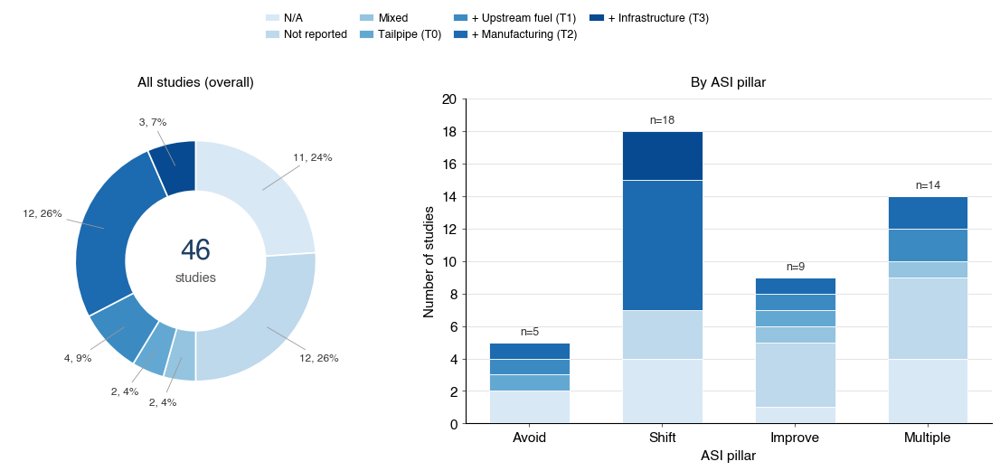

In [2]:
"""
Figure: Accounting boundary -- overall distribution (donut, left) and by ASI pillar
(stacked bars, right). Supplementary Table S5 -> main text figure.
Style matched to fig_temporal_asi.pdf (matplotlib, sequential blue palette, clean spines).

Data: derived from Supplementary Table S5 (life-cycle component coding), cross-tabulated
against each study's PRIMARY ASI pillar (its unmarked / non-asterisked appearance across
Supplementary Tables S1-S4).

NOTE ON COUNTS: these tallies (Shift=18, Multiple=15) are 1 higher each than the "17" and
"14" currently stated in the main-text prose (Section "Descriptive Overview"). Re-run this
script after that reconciliation to regenerate the figure with final numbers -- only the
`data` dictionary below needs updating.
"""

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np

# ---------------------------------------------------------------------------
# Style setup -- matched to fig_temporal_asi.pdf
# ---------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 11
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["xtick.major.width"] = 0.8
plt.rcParams["ytick.major.width"] = 0.8

FIGSIZE = (11.5, 4.6)

# Sequential blue palette sampled from the existing figure (hex, light -> dark):
#   Avoid #D3E1F2, Shift #9ECAE1, Improve #6BAED6, Shift/Improve #3B6EA5, Integrated ASI #1F3F63
# Extended to 7 steps (matplotlib 'Blues' colormap) to keep both figures visually one family.
cmap = plt.get_cmap("Blues")
N_TIERS = 7
blue_shades = [cmap(0.15 + 0.75 * i / (N_TIERS - 1)) for i in range(N_TIERS)]

# ---------------------------------------------------------------------------
# Data -- from Supplementary Table S5, cross-tabulated by primary ASI pillar
# ---------------------------------------------------------------------------
pillars = ["Avoid", "Shift", "Improve", "Multiple"]
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

data = {
    "Avoid":    {"N/A": 2, "NR": 0, "Mixed": 0, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Shift":    {"N/A": 4, "NR": 3, "Mixed": 0, "T0": 0, "T1": 0, "T2": 8, "T3": 3},
    "Improve":  {"N/A": 1, "NR": 4, "Mixed": 1, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Multiple": {"N/A": 4, "NR": 5, "Mixed": 1, "T0": 0, "T1": 2, "T2": 2, "T3": 0},
}

tier_labels = {
    "N/A": "N/A",
    "NR": "Not reported",
    "Mixed": "Mixed",
    "T0": "Tailpipe (T0)",
    "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)",
    "T3": "+ Infrastructure (T3)",
}

# Overall totals across the whole corpus (for the donut panel)
totals = {t: sum(data[p][t] for p in pillars) for t in tiers}
grand_total = sum(totals.values())

# ---------------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------------
fig, (ax_donut, ax_bar) = plt.subplots(
    1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.3, 1.6]}
)

# --- Left panel: donut of overall boundary-tier distribution -----------------
sizes = [totals[t] for t in tiers]
wedges, _ = ax_donut.pie(
    sizes,
    colors=blue_shades,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=1.2),
)

# count + % label for each wedge, placed just outside the donut ring with a leader line
for wedge, tier in zip(wedges, tiers):
    n = totals[tier]
    pct = 100 * n / grand_total
    ang = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    x_out, y_out = np.cos(ang), np.sin(ang)
    # anchor point on the outer edge of the ring, label placed further out
    r_label = 1.18
    ha = "left" if x_out >= 0 else "right"
    ax_donut.annotate(
        f"{n}, {pct:.0f}%",
        xy=(0.79 * x_out, 0.79 * y_out),
        xytext=(r_label * x_out, r_label * y_out),
        ha=ha, va="center", fontsize=8.5, color="#333333",
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.6),
    )

ax_donut.text(0, 0.08, f"{grand_total}", ha="center", va="center",
              fontsize=22, fontweight="bold", color="#1F3F63")
ax_donut.text(0, -0.14, "studies", ha="center", va="center",
              fontsize=10.5, color="#555555")
ax_donut.set_title("All studies (overall)", fontsize=11, pad=10)
ax_donut.set_xlim(-1.55, 1.55)
ax_donut.set_ylim(-1.35, 1.35)
ax_donut.set_aspect("equal")

# --- Right panel: stacked bars by ASI pillar --------------------------------
x = np.arange(len(pillars))
bottom = np.zeros(len(pillars))

for tier, color in zip(tiers, blue_shades):
    values = np.array([data[p][tier] for p in pillars])
    ax_bar.bar(
        x, values, bottom=bottom, width=0.6,
        color=color, edgecolor="white", linewidth=0.6,
        label=tier_labels[tier], zorder=3,
    )
    bottom += values

for xi, p in enumerate(pillars):
    total = sum(data[p].values())
    ax_bar.text(xi, bottom[xi] + 0.3, f"n={total}", ha="center", va="bottom",
                fontsize=9, color="#333333")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(pillars)
ax_bar.set_xlabel("ASI pillar")
ax_bar.set_ylabel("Number of studies")
ax_bar.set_ylim(0, max(bottom) + 2)
ax_bar.yaxis.set_major_locator(MaxNLocator(integer=True))

ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.yaxis.grid(True, color="#e5e5e5", linewidth=0.8, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.tick_params(axis="both", which="both", length=3, color="#666666")
ax_bar.set_title("By ASI pillar", fontsize=11, pad=10)

# --- Shared legend, one row set above both panels ---------------------------
handles, labels = ax_bar.get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 1.14),
    ncol=4, frameon=False, fontsize=9, handlelength=1.3,
    columnspacing=1.0, handletextpad=0.4,
)

fig.tight_layout()
fig.savefig("fig_boundary_overview.pdf", bbox_inches="tight")
fig.savefig("fig_boundary_overview.png", dpi=200, bbox_inches="tight")
print("Saved fig_boundary_overview.pdf / .png")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
import matplotlib.patches as mpatches
from collections import defaultdict

# ----------------------------------------------------------------------
# 1. Carga y preparación de datos
# ----------------------------------------------------------------------
INFILE, SHEET = "DATASET_SLR.xlsx", "Master coding"
df = pd.read_excel(INFILE, sheet_name=SHEET)

DIM_COLS = ["Region / Location", "Spatial scale", "ASI focus", "Sub-strategy", "Method"]
N_FULL_CORPUS = len(df)

df_complete = df.dropna(subset=DIM_COLS).copy()
N_FLOW = len(df_complete)

REGION_MAP = {
    "Global": "Global", "Global (78 studies)": "Global", "Global (optimisation lit.)": "Global",
    "Barcelona, Spain": "Europe", "London, UK": "Europe", "EU28": "Europe",
    "EU27/UK/Switzerland": "Europe", "Germany": "Europe", "Poland": "Europe",
    "Switzerland": "Europe", "Hamburg, Germany": "Europe", "Europe (EU)": "Europe",
    "European cities": "Europe", "Warsaw, Poland": "Europe", "UK": "Europe",
    "Lyon , France": "Europe", "Malta": "Europe", "Austria": "Europe",
    "USA": "North America", "Toronto, Canada": "North America", "Los Angeles, USA": "North America",
    "Portland, USA": "North America", "Mexico": "North America",
    "China": "Asia", "Xiamen, China": "Asia", "Beijing, China": "Asia",
    "China (provincial)": "Asia", "Tokyo, Japan": "Asia", "Singapore": "Asia",
    "Gunma Prefecture, Japan": "Asia",
    "India (sub-national / 31 states and union territories)": "Asia",
    "Qatar": "Middle East", "Riyadh, Saudi Arabia": "Middle East",
    "Sydney, Australia": "Oceania",
    "Ibagué, Colombia": "South America",
    "Emerging economies": "Cross-regional", "NL / SE / US": "Cross-regional",
    "BR / IN / ID / ZA": "Cross-regional", "JP / UK / MX / FR": "Cross-regional",
}

METHOD_MAP = {
    "Empirical": "Empirical", "Empirical analysis (Regression)": "Empirical", "Case study": "Empirical",
    "LCA study": "Modelling", "Modelling (IAM)": "Modelling", "Modelling (simulation)": "Modelling",
    "Modelling (Scenario / Backcasting)": "Modelling", "Modelling": "Modelling",
    "Modelling (scenario)": "Modelling", "Modelling (GIS)": "Modelling",
    "Modelling (LCA-based)": "Modelling", "Modelling (Energy-system optimization)": "Modelling",
    "Literature review": "Review", "Systematic review": "Review",
}

THEME_MAP = {
    "Sufficiency / behavioural": "Sufficiency",
    "Land use / accessibility": "Land Use",
    "Active mobility (cycling / walking)": "Active Mobility",
    "Public transport / rail": "Public Transport",
    "MaaS / shared mobility": "MaaS",
    "EV": "Electric Vehicle",
    "smart charging": "Electric Vehicle",
    "Autonomous vehicle": "Autonomous Vehicle",
    "Shift-Improve combined": "Shift-Improve Strategies",
    "Modal shift (general)": "Shift-Improve Strategies",
    "Full ASI": "ASI Studies",
}

df_complete["Region_grp"] = df_complete["Region / Location"].map(REGION_MAP)
df_complete["Method_grp"] = df_complete["Method"].map(METHOD_MAP)
df_complete["Theme_grp"]  = df_complete["Sub-strategy"].map(THEME_MAP)

# ----------------------------------------------------------------------
# 2. Paleta y hatches -- IDÉNTICOS al gráfico de barras temporal
# ----------------------------------------------------------------------
PILLARS = ["Avoid", "Shift", "Improve", "Shift/Improve", "Integrated ASI"]
PILLAR_COLORS = dict(zip(PILLARS, ["#cfe1f2", "#9ecae1", "#6baed6", "#3b6ea5", "#1f3f63"]))
PILLAR_HATCHES = dict(zip(PILLARS, ["", "///", "\\\\\\", "xxx", "..."]))
NEUTRAL_NODE_COLOR = "#d9d9d9"

SUBSTRATEGY_TO_STRATEGY = {
    "Sufficiency": "Avoid",
    "Land Use": "Avoid",
    "Active Mobility": "Shift",
    "Public Transport": "Shift",
    "MaaS": "Shift",
    "Electric Vehicle": "Improve",
    "Autonomous Vehicle": "Improve",
    "Shift-Improve Strategies": "Shift/Improve",
    "ASI Studies": "Integrated ASI",
}

# ----------------------------------------------------------------------
# 3. Orden estricto de columnas
# ----------------------------------------------------------------------
STAGE_COL = ["Region_grp", "Spatial scale", "ASI focus", "Theme_grp", "Method_grp"]
STAGE_TITLES = ["Location", "Spatial scale", "ASI focus", "Sub-strategy", "Methodology"]

c0 = df_complete["Region_grp"].value_counts()
order_col0 = ["Global"] + [cat for cat in c0.index if cat != "Global"]

c1 = df_complete["Spatial scale"].value_counts()
order_col1 = ["Global"] + [cat for cat in c1.index if cat != "Global"]

order_col2 = PILLARS

order_col3 = [
    "Sufficiency", "Land Use", "Active Mobility", "Public Transport", "MaaS",
    "Electric Vehicle", "Autonomous Vehicle", "Shift-Improve Strategies", "ASI Studies",
]

order_col4 = list(df_complete["Method_grp"].value_counts().index)

STAGE_ORDER = [order_col0, order_col1, order_col2, order_col3, order_col4]

ASI_STAGE_INDEX = STAGE_COL.index("ASI focus")
THEME_STAGE_INDEX = STAGE_COL.index("Theme_grp")

# ----------------------------------------------------------------------
# 4. Geometría de nodos (y=0 arriba, y=1 abajo; se invierte el eje al graficar)
# ----------------------------------------------------------------------
node_label, node_sub, node_x, node_top, node_bot = [], [], [], [], []
node_color, node_hatch, node_id = [], [], {}
GAP, Y_PAD = 0.02, 0.03

for stage_i, (col, order) in enumerate(zip(STAGE_COL, STAGE_ORDER)):
    counts = df_complete[col].value_counts()
    present = [c for c in order if c in counts.index]
    total = counts[present].sum()
    n_nodes = len(present)
    avail_h = (1 - 2 * Y_PAD) - GAP * (n_nodes - 1)
    y_cursor = Y_PAD

    for cat in present:
        cnt = int(counts[cat])
        pct = round(100 * cnt / N_FULL_CORPUS)
        height = (cnt / total) * avail_h
        top, bot = y_cursor, y_cursor + height

        node_id[(stage_i, cat)] = len(node_label)
        node_label.append(cat)
        node_sub.append(f"(n={cnt}, {pct}%)")
        node_x.append(stage_i)
        node_top.append(top)
        node_bot.append(bot)

        if stage_i == ASI_STAGE_INDEX:
            pillar = cat
        elif stage_i == THEME_STAGE_INDEX:
            pillar = SUBSTRATEGY_TO_STRATEGY.get(cat)
        else:
            pillar = None

        node_color.append(PILLAR_COLORS.get(pillar, NEUTRAL_NODE_COLOR))
        node_hatch.append(PILLAR_HATCHES.get(pillar, ""))

        y_cursor += height + GAP

# ----------------------------------------------------------------------
# 5. Enlaces coloreados/hatcheados por pilar ASI
# ----------------------------------------------------------------------
link_source, link_target, link_value, link_pillar = [], [], [], []

for stage_i in range(len(STAGE_COL) - 1):
    col_a, col_b = STAGE_COL[stage_i], STAGE_COL[stage_i + 1]
    # dict.fromkeys evita duplicar la columna cuando col_a o col_b ya ES "ASI focus"
    group_cols = list(dict.fromkeys([col_a, col_b, "ASI focus"]))
    grouped = df_complete.groupby(group_cols).size().reset_index(name="count")

    for _, row in grouped.iterrows():
        cat_a, cat_b, pillar, cnt = row[col_a], row[col_b], row["ASI focus"], row["count"]
        if (stage_i, cat_a) not in node_id or (stage_i + 1, cat_b) not in node_id:
            continue
        link_source.append(node_id[(stage_i, cat_a)])
        link_target.append(node_id[(stage_i + 1, cat_b)])
        link_value.append(int(cnt))
        link_pillar.append(pillar)

# ----------------------------------------------------------------------
# 6. Sub-alturas de flujos dentro de cada nodo (evita solapes)
# ----------------------------------------------------------------------
node_out, node_in = defaultdict(list), defaultdict(list)
for li, (s, t) in enumerate(zip(link_source, link_target)):
    node_out[s].append(li)
    node_in[t].append(li)

node_y_center = [(top + bot) / 2 for top, bot in zip(node_top, node_bot)]
for idx in node_out:
    node_out[idx].sort(key=lambda li: node_y_center[link_target[li]])
for idx in node_in:
    node_in[idx].sort(key=lambda li: node_y_center[link_source[li]])

link_src_range, link_tgt_range = {}, {}
for idx in range(len(node_label)):
    top, bot = node_top[idx], node_bot[idx]
    height = bot - top

    outs = node_out.get(idx, [])
    tot_out = sum(link_value[li] for li in outs) or 1
    cur = top
    for li in outs:
        h = (link_value[li] / tot_out) * height
        link_src_range[li] = (cur, cur + h)
        cur += h

    ins = node_in.get(idx, [])
    tot_in = sum(link_value[li] for li in ins) or 1
    cur = top
    for li in ins:
        h = (link_value[li] / tot_in) * height
        link_tgt_range[li] = (cur, cur + h)
        cur += h

# ----------------------------------------------------------------------
# 7. Dibujo (Sankey 100% matplotlib: mismo motor de hatch que las barras)
# ----------------------------------------------------------------------
def sankey_ribbon(x0, x1, y0_top, y0_bot, y1_top, y1_bot, **kw):
    """Cinta de flujo con curvas Bezier cúbicas (estilo D3/Plotly Sankey)."""
    xm = (x0 + x1) / 2.0
    verts = [
        (x0, y0_top),
        (xm, y0_top), (xm, y1_top), (x1, y1_top),
        (x1, y1_bot),
        (xm, y1_bot), (xm, y0_bot), (x0, y0_bot),
        (x0, y0_top),
    ]
    codes = [Path.MOVETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.LINETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.CLOSEPOLY]
    return PathPatch(Path(verts, codes), **kw)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["hatch.linewidth"] = 0.45
plt.rcParams["pdf.fonttype"] = 42   # fuentes embebidas correctamente en el PDF

FS_LABEL = 9.5      # nombre de categoria
FS_SUB = 8          # (n=.., ..%) -- debajo del nombre
FS_TITLE = 15       # titulos de columna (Helvetica bold)
FS_LEGEND = 11

N_STAGES = len(STAGE_COL)
fig, ax = plt.subplots(figsize=(16, 9.5))
NODE_W = 0.09

# 7.1 Flujos primero (quedan debajo de los nodos) -- colores 100% opacos,
#     misma intensidad que las barras (sin alpha de atenuacion)
for li in range(len(link_source)):
    s, t = link_source[li], link_target[li]
    pillar = link_pillar[li]
    y0_top, y0_bot = link_src_range[li]
    y1_top, y1_bot = link_tgt_range[li]
    x0 = node_x[s] + NODE_W / 2
    x1 = node_x[t] - NODE_W / 2
    patch = sankey_ribbon(
        x0, x1, y0_top, y0_bot, y1_top, y1_bot,
        facecolor=PILLAR_COLORS[pillar], edgecolor="black", linewidth=0.4,
        hatch=PILLAR_HATCHES[pillar], zorder=1,
    )
    ax.add_patch(patch)

# 7.2 Nodos encima
LABEL_BOX = dict(boxstyle="round,pad=0.22,rounding_size=0.15",
                  facecolor="white", edgecolor="none", alpha=0.95)

for idx in range(len(node_label)):
    x = node_x[idx]
    y0, y1 = node_top[idx], node_bot[idx]
    rect = Rectangle(
        (x - NODE_W / 2, y0), NODE_W, y1 - y0,
        facecolor=node_color[idx], edgecolor="black", linewidth=0.5,
        hatch=node_hatch[idx], zorder=2,
    )
    ax.add_patch(rect)

    y_center = (y0 + y1) / 2
    # Primera columna (Location): etiqueta al margen vacio de la izquierda,
    # para no chocar con el abanico de flujos que sale hacia la derecha.
    if node_x[idx] == 0:
        x_text, ha = x - NODE_W / 2 - 0.018, "right"
    else:
        x_text, ha = x + NODE_W / 2 + 0.018, "left"

    # Halo blanco opaco detras del texto -> legible encima de cualquier hatch/flujo
    ax.text(x_text, y_center - 0.007, node_label[idx],
            fontsize=FS_LABEL, va="bottom", ha=ha, zorder=10, bbox=LABEL_BOX)
    ax.text(x_text, y_center + 0.007, node_sub[idx],
            fontsize=FS_SUB, color="0.30", va="top", ha=ha, zorder=10, bbox=LABEL_BOX)

ax.set_xlim(-0.95, N_STAGES - 1 + 0.9)
ax.set_ylim(-0.03, 1.16)
ax.invert_yaxis()
ax.axis("off")

# 7.3 Titulos de columna -- Helvetica bold, en la parte inferior del diagrama
TITLE_Y = 1.055
for i, title in enumerate(STAGE_TITLES):
    ax.text(i, TITLE_Y, title, fontsize=FS_TITLE,
            fontweight="bold", ha="center", va="top")

# 7.4 Leyenda de pilares -- misma intensidad de color/hatch, debajo de los titulos
legend_handles = [
    mpatches.Patch(facecolor=PILLAR_COLORS[p], edgecolor="black", linewidth=0.4,
                   hatch=PILLAR_HATCHES[p], label=p)
    for p in PILLARS
]
ax.legend(handles=legend_handles, ncol=5, frameon=False, fontsize=FS_LEGEND,
          loc="upper center", bbox_to_anchor=(0.5, -0.02), handlelength=1.8,
          handletextpad=0.6, columnspacing=1.6)

fig.tight_layout()
fig.savefig("fig_sankey_hatched.pdf", bbox_inches="tight")
fig.savefig("fig_sankey_hatched.png", dpi=300, bbox_inches="tight")
print("Guardado: fig_sankey_hatched.pdf / fig_sankey_hatched.png")
Figure: Accounting boundary -- overall distribution (donut, left) and by ASI pillar
(stacked bars, right). Supplementary Table S5 -> main text figure.
Style matched to fig_temporal_asi.pdf (matplotlib, sequential blue palette, clean spines).

Data: derived from Supplementary Table S5 (life-cycle component coding), cross-tabulated
against each study's PRIMARY ASI pillar (its unmarked / non-asterisked appearance across
Supplementary Tables S1-S4).

NOTE ON COUNTS: these tallies (Shift=18, Multiple=15) are 1 higher each than the "17" and
"14" currently stated in the main-text prose (Section "Descriptive Overview"). Re-run this
script after that reconciliation to regenerate the figure with final numbers -- only the
`data` dictionary below needs updating.
"""

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np

# ---------------------------------------------------------------------------
# Style setup -- matched to fig_temporal_asi.pdf
# ---------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 11
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["xtick.major.width"] = 0.8
plt.rcParams["ytick.major.width"] = 0.8
plt.rcParams["hatch.linewidth"] = 0.7

FIGSIZE = (11.5, 4.6)

# Sequential blue palette sampled from the existing figure (hex, light -> dark):
#   Avoid #D3E1F2, Shift #9ECAE1, Improve #6BAED6, Shift/Improve #3B6EA5, Integrated ASI #1F3F63
# Extended to 7 steps (matplotlib 'Blues' colormap) to keep both figures visually one family.
cmap = plt.get_cmap("Blues")
N_TIERS = 7
blue_shades = [cmap(0.15 + 0.75 * i / (N_TIERS - 1)) for i in range(N_TIERS)]

# Nature-portfolio-style hatch patterns, one per boundary tier, layered on top of
# the color fill so categories remain distinguishable in grayscale/B&W print and
# for colorblind readers, not only through hue.
hatch_patterns = {
    "N/A":   "",
    "NR":    "...",
    "Mixed": "xxx",
    "T0":    "///",
    "T1":    "\\\\\\",
    "T2":    "|||",
    "T3":    "+++",
}
HATCH_COLOR = "#404040"  # dark gray hatch/edge color for contrast on both light and dark fills

# ---------------------------------------------------------------------------
# Data -- from Supplementary Table S5, cross-tabulated by primary ASI pillar
# ---------------------------------------------------------------------------
pillars = ["Avoid", "Shift", "Improve", "Multiple"]
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

data = {
    "Avoid":    {"N/A": 2, "NR": 0, "Mixed": 0, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Shift":    {"N/A": 3, "NR": 3, "Mixed": 0, "T0": 0, "T1": 0, "T2": 8, "T3": 3},
    "Improve":  {"N/A": 1, "NR": 4, "Mixed": 1, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Multiple": {"N/A": 5, "NR": 5, "Mixed": 1, "T0": 0, "T1": 2, "T2": 2, "T3": 0},
}

tier_labels = {
    "N/A": "N/A",
    "NR": "Not reported",
    "Mixed": "Mixed",
    "T0": "Tailpipe (T0)",
    "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)",
    "T3": "+ Infrastructure (T3)",
}

# Overall totals across the whole corpus (for the donut panel)
totals = {t: sum(data[p][t] for p in pillars) for t in tiers}
grand_total = sum(totals.values())

# ---------------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------------
fig, (ax_donut, ax_bar) = plt.subplots(
    1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.3, 1.6]}
)

# --- Left panel: donut of overall boundary-tier distribution -----------------
sizes = [totals[t] for t in tiers]
wedges, _ = ax_donut.pie(
    sizes,
    colors=blue_shades,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.42, edgecolor=HATCH_COLOR, linewidth=0.8),
)
for wedge, tier in zip(wedges, tiers):
    wedge.set_hatch(hatch_patterns[tier])

# count + % label for each wedge, placed just outside the donut ring with a leader line
for wedge, tier in zip(wedges, tiers):
    n = totals[tier]
    pct = 100 * n / grand_total
    ang = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    x_out, y_out = np.cos(ang), np.sin(ang)
    # anchor point on the outer edge of the ring, label placed further out
    r_label = 1.18
    ha = "left" if x_out >= 0 else "right"
    ax_donut.annotate(
        f"{n}, {pct:.0f}%",
        xy=(0.79 * x_out, 0.79 * y_out),
        xytext=(r_label * x_out, r_label * y_out),
        ha=ha, va="center", fontsize=8.5, color="#333333",
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.6),
    )

ax_donut.text(0, 0.08, f"{grand_total}", ha="center", va="center",
              fontsize=22, fontweight="bold", color="#1F3F63")
ax_donut.text(0, -0.14, "studies", ha="center", va="center",
              fontsize=10.5, color="#555555")
ax_donut.set_title("All studies (overall)", fontsize=11, pad=10)
ax_donut.set_xlim(-1.55, 1.55)
ax_donut.set_ylim(-1.35, 1.35)
ax_donut.set_aspect("equal")

# --- Right panel: stacked bars by ASI pillar --------------------------------
x = np.arange(len(pillars))
bottom = np.zeros(len(pillars))

for tier, color in zip(tiers, blue_shades):
    values = np.array([data[p][tier] for p in pillars])
    ax_bar.bar(
        x, values, bottom=bottom, width=0.6,
        color=color, edgecolor=HATCH_COLOR, linewidth=0.6,
        hatch=hatch_patterns[tier],
        label=tier_labels[tier], zorder=3,
    )
    bottom += values

for xi, p in enumerate(pillars):
    total = sum(data[p].values())
    ax_bar.text(xi, bottom[xi] + 0.3, f"n={total}", ha="center", va="bottom",
                fontsize=9, color="#333333")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(pillars)
ax_bar.set_xlabel("ASI pillar")
ax_bar.set_ylabel("Number of studies")
ax_bar.set_ylim(0, max(bottom) + 2)
ax_bar.yaxis.set_major_locator(MaxNLocator(integer=True))

ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.yaxis.grid(True, color="#e5e5e5", linewidth=0.8, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.tick_params(axis="both", which="both", length=3, color="#666666")
ax_bar.set_title("By ASI pillar", fontsize=11, pad=10)

# --- Shared legend, one row set above both panels ---------------------------
handles, labels = ax_bar.get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 1.14),
    ncol=4, frameon=False, fontsize=9, handlelength=1.3,
    columnspacing=1.0, handletextpad=0.4,
)

fig.tight_layout()
fig.savefig("fig_boundary_overview.pdf", bbox_inches="tight")
fig.savefig("fig_boundary_overview.png", dpi=200, bbox_inches="tight")
print("Saved fig_boundary_overview.pdf / .png")

Saved fig_final_range.pdf / .png


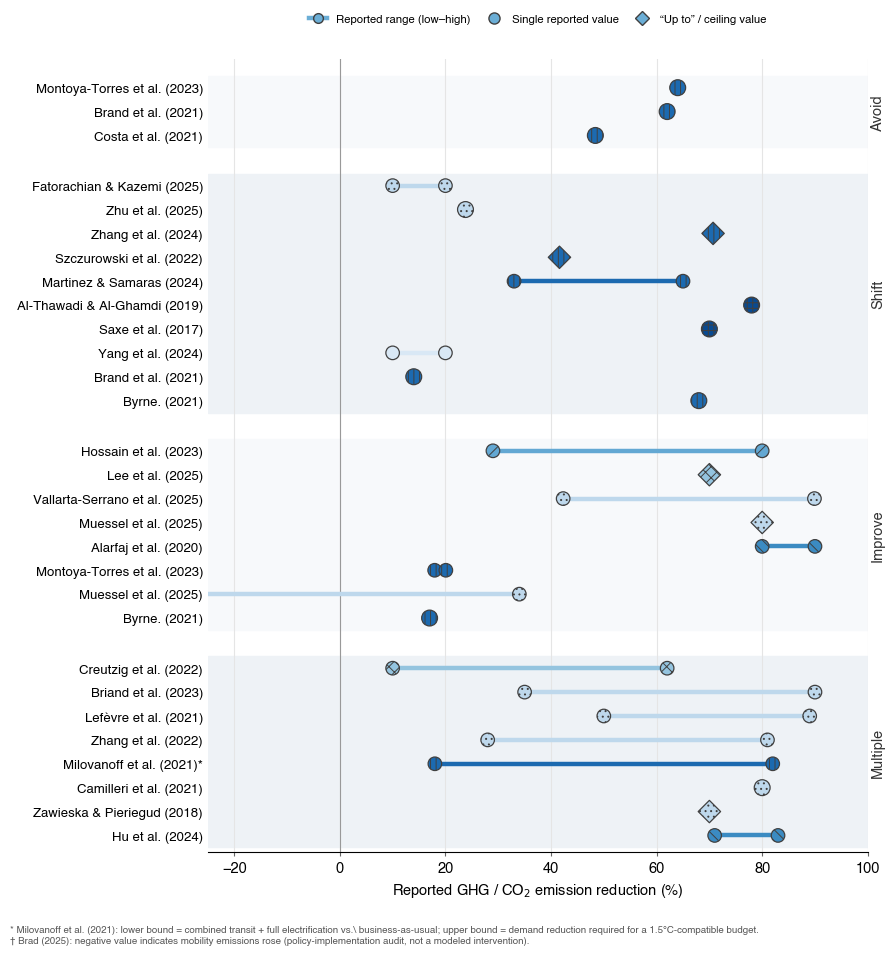

In [28]:
"""
Final figure: Reported GHG/CO2 emission reduction (%) by study, colored/hatched by
accounting-boundary tier, grouped by ASI pillar. Style matched to fig_boundary_overview.py
(same blue sequential palette + Nature-portfolio-style hatch patterns per tier).

Inclusion rule: only studies whose PRIMARY (unmarked) row in Supplementary Tables S1-S4
reports a directly comparable overall emissions-reduction percentage (single value, an
"up to" ceiling, or a low-high range) are included. Studies whose primary metric is not a
comparable percentage (e.g., external cost per pkm, accessibility index, g CO2/pkm ratios,
modal-choice probabilities, breakeven years, qualitative-only findings) are excluded; see
Supplementary Tables S1-S5 for the full set of 46 studies and their reported outcomes.

Data verified against the "Reported Reduction" field of each study's primary row (see
supplementary.tex) as of the current, reconciled 46-study corpus (Avoid=5, Shift=17,
Improve=9, Multiple=15).
"""

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# ---------------------------------------------------------------------------
# Style setup -- matched to fig_boundary_overview.py / fig_temporal_asi.pdf
# ---------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 10.5
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["xtick.major.width"] = 0.8
plt.rcParams["ytick.major.width"] = 0.8
plt.rcParams["hatch.linewidth"] = 0.7

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.15 + 0.75 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}
hatch_patterns = {
    "N/A":   "",
    "NR":    "...",
    "Mixed": "xxx",
    "T0":    "///",
    "T1":    "\\\\\\",
    "T2":    "|||",
    "T3":    "+++",
}
tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)",
}

# ---------------------------------------------------------------------------
# Data: label, pillar, tier, low, high (low==high -> single/point value)
# ---------------------------------------------------------------------------
# fmt: off
studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne. (2021)",                  pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",            pillar="Shift",    tier="N/A",  low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",              pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",   pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",       pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",       pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",             pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",                pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",     pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne. (2021)",                  pillar="Improve",    tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",           pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Improve",    tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",           pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",           pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)",  pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",                pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",           pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple (Shift/Improve + Integrated ASI) ---
    dict(label="Hu et al. (2024)",                 pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",     pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    #dict(label="Montoya-Torres et al. (2023)",    pillar="Multiple", tier="T2",  low=18.0, high=56.92),
    dict(label="Camilleri et al. (2021)",          pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",       pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    #dict(label="Zhang et al. (2025)",              pillar="Multiple", tier="T1",  low=2.75, high=52.74),
    dict(label="Zhang et al. (2022)",              pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",            pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",             pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",           pillar="Multiple", tier="Mixed", low=10.0, high=62.0),

]
# fmt: on

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]
pillar_gap = 1.1  # extra vertical spacing between pillar groups

# Assign y-positions, grouping by pillar (reversed so Avoid appears at top)
y_positions = []
y_labels = []
group_bounds = {}  # pillar -> (ymin, ymax) for background shading
y = 0.0
for pillar in reversed(pillar_order):
    group = [s for s in studies if s["pillar"] == pillar]
    y_start = y
    for s in group:
        y_positions.append(y)
        y_labels.append(s["label"])
        s["y"] = y
        y += 1.0
    group_bounds[pillar] = (y_start - 0.5, y - 0.5)
    y += pillar_gap

fig, ax = plt.subplots(figsize=(9, 9.5))

# Alternating subtle background bands per pillar group
band_colors = ["#f7f9fb", "#eef2f6"]
for i, pillar in enumerate(pillar_order):
    ymin, ymax = group_bounds[pillar]
    ax.axhspan(ymin, ymax, color=band_colors[i % 2], zorder=0)

# zero-reference line (0% = no change)
ax.axvline(0, color="#999999", linewidth=0.8, zorder=1, linestyle="-")

for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    if s["low"] != s["high"]:
        # range: line with circular caps at both ends
        ax.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=3.2,
                 solid_capstyle="round", zorder=2, path_effects=None)
        for xv in (s["low"], s["high"]):
            ax.scatter(xv, yv, s=95, color=color, edgecolor="#404040", linewidth=0.9,
                       zorder=3, hatch=hatch)
    else:
        marker = "D" if s.get("upto") else "o"
        ax.scatter(s["low"], yv, s=130, color=color, edgecolor="#404040", linewidth=0.9,
                   zorder=3, marker=marker, hatch=hatch)

ax.set_yticks(y_positions)
ax.set_yticklabels(y_labels, fontsize=9.5)
ax.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)")
ax.set_xlim(-25, 100)
ax.set_ylim(-0.7, y - pillar_gap + 0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.xaxis.grid(True, color="#e5e5e5", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, color="#666666")

# Pillar group labels on the right margin
for pillar in pillar_order:
    ymin, ymax = group_bounds[pillar]
    ax.text(1.005, (ymin + ymax) / 2, pillar,
            transform=ax.get_yaxis_transform(), rotation=90,
            va="center", ha="left", fontsize=10.5, fontweight="bold", color="#333333")

# --- Legends ---------------------------------------------------------------
# 1) boundary tier (color+hatch), matching fig_boundary_overview.py -- one row
tier_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor=blue_shades[t], edgecolor="#404040",
                  hatch=hatch_patterns[t], linewidth=0.8)
    for t in tiers
]
leg1 = ax.legend(
    tier_handles, [tier_full_label[t] for t in tiers],
    loc="upper center", bbox_to_anchor=(0.5, 1.13),
    ncol=7, frameon=False, fontsize=8.2, handlelength=1.2,
    columnspacing=0.8, handletextpad=0.35,
)
ax.add_artist(leg1)

# 2) marker meaning (range vs point vs "up to") -- second row, below the first
marker_handles = [
    Line2D([0], [0], color="#6BAED6", lw=3.2, marker="o", markersize=7,
           markeredgecolor="#404040", label="Reported range (low\u2013high)"),
    Line2D([0], [0], color="none", marker="o", markersize=8,
           markerfacecolor="#6BAED6", markeredgecolor="#404040", label="Single reported value"),
    Line2D([0], [0], color="none", marker="D", markersize=7.5,
           markerfacecolor="#6BAED6", markeredgecolor="#404040", label="\u201cUp to\u201d / ceiling value"),
]
ax.legend(
    handles=marker_handles, loc="upper center", bbox_to_anchor=(0.5, 1.07),
    ncol=3, frameon=False, fontsize=8.2, handlelength=1.6, columnspacing=1.2,
)

fig.text(0.01, 0.005,
         "* Milovanoff et al. (2021): lower bound = combined transit + full electrification vs.\\ business-as-usual; "
         "upper bound = demand reduction required for a 1.5\u00b0C-compatible budget.\n"
         "\u2020 Brad (2025): negative value indicates mobility emissions rose (policy-implementation audit, not a modeled intervention).",
         fontsize=7, color="#555555", ha="left")

fig.tight_layout(rect=[0, 0.035, 1, 1])
fig.savefig("fig_final_range.pdf", bbox_inches="tight")
fig.savefig("fig_final_range.png", dpi=200, bbox_inches="tight")
print("Saved fig_final_range.pdf / .png")

Saved fig_final_range.pdf / .png (Nature Portfolio style)


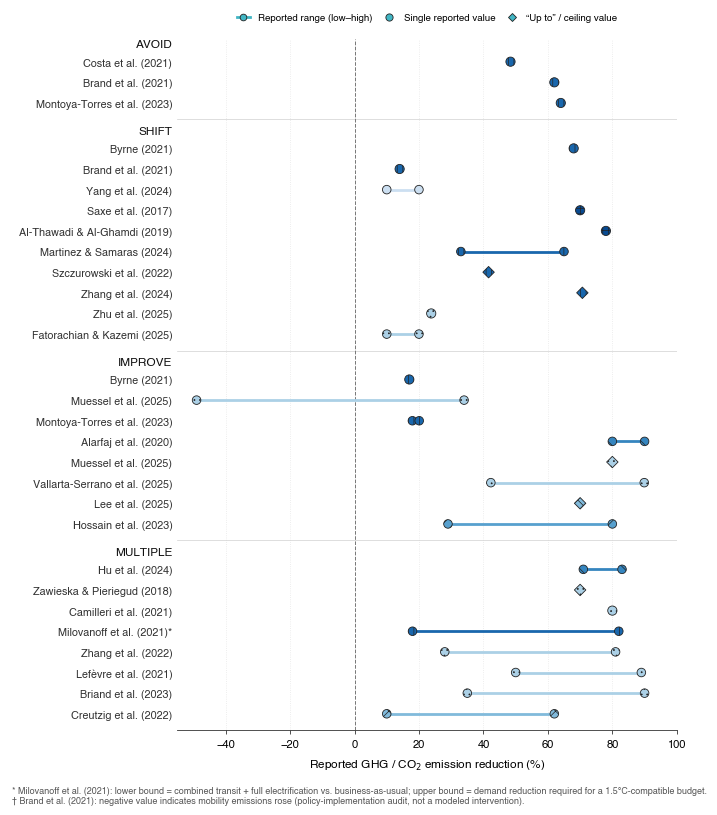

In [29]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# ---------------------------------------------------------------------------
# Configuración de estilo -- Estándar Nature Portfolio
# ---------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

# ---------------------------------------------------------------------------
# Colores y Tramas (Hatches) por Tier
# ---------------------------------------------------------------------------
cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

# Inicio desde 0.22 para evitar tonos extremadamente claros/blancos en N/A
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A":   "",
    "NR":    "...",
    "Mixed": "xxx",
    "T0":    "///",
    "T1":    "\\\\\\",
    "T2":    "|||",
    "T3":    "+++",
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)",
}

# ---------------------------------------------------------------------------
# Datos
# ---------------------------------------------------------------------------
# fmt: off
studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]
# fmt: on

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

# ---------------------------------------------------------------------------
# Construcción de posiciones Y (Forest Plot jerárquico de arriba a abajo)
# ---------------------------------------------------------------------------
y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    
    # Estudios dentro del grupo
    for s in reversed(group):
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])  # Indentación
        is_header_tick.append(False)
        s["y"] = y
        y += 1.0
        
    # Encabezado del pilar justo encima del grupo
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    # Espaciado y línea divisora entre pilares
    if i < len(pillar_order) - 1:
        y += 0.4
        group_separators.append(y)
        y += 0.8
    else:
        y += 0.3

# ---------------------------------------------------------------------------
# Renderizado de la figura
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.0, 8.5))

# Líneas divisoras horizontales entre pilares (en reemplazo de los sombreados)
for y_sep in group_separators:
    ax.axhline(y_sep, color="#d0d0d0", linestyle="-", linewidth=0.5, zorder=1)

# Línea vertical de referencia en 0%
ax.axvline(0, color="#777777", linestyle="--", linewidth=0.7, zorder=1)

# Renderizado de datos (rangos y puntos)
for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    if s["low"] != s["high"]:
        # Rango
        ax.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.0,
                solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax.scatter(xv, yv, s=38, facecolor=color, edgecolor="#222222",
                       linewidth=0.6, zorder=3, hatch=hatch)
    else:
        # Valor único
        marker = "D" if s.get("upto") else "o"
        size = 34 if marker == "D" else 44
        ax.scatter(s["low"], yv, s=size, facecolor=color, edgecolor="#222222",
                   linewidth=0.6, zorder=3, marker=marker, hatch=hatch)

# Ajuste fino de ejes
ax.set_yticks(y_positions)
labels = ax.set_yticklabels(y_tick_labels)

# Aplicar estilo al eje Y (encabezados en negrita, estudios normales)
for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontweight("bold")
        label.set_fontsize(8.5)
        label.set_color("#111111")
    else:
        label.set_fontsize(7.8)
        label.set_color("#333333")

ax.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=6)
ax.set_xlim(-55, 100)
ax.set_ylim(-0.8, y - 0.2)

# Spines y rejilla
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(0.6)

ax.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.6, color="#333333")

# ---------------------------------------------------------------------------
# Leyendas (Formato de 2 niveles superior)
# ---------------------------------------------------------------------------
# 1) Tiers de contabilidad (Color + Hatch)
tier_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor=blue_shades[t], edgecolor="#222222",
                  hatch=hatch_patterns[t], linewidth=0.6)
    for t in tiers
]
leg1 = ax.legend(
    tier_handles, [tier_full_label[t] for t in tiers],
    loc="lower center", bbox_to_anchor=(0.5, 1.065),
    ncol=7, frameon=False, fontsize=7.0, handlelength=1.1, handleheight=0.9,
    columnspacing=0.6, handletextpad=0.35
)
ax.add_artist(leg1)

# 2) Significado de los marcadores
marker_handles = [
    Line2D([0], [0], color="#41b6c4", lw=2.0, marker="o", markersize=4.8,
           markeredgecolor="#222222", markeredgewidth=0.6, label="Reported range (low–high)"),
    Line2D([0], [0], color="none", marker="o", markersize=5.2,
           markerfacecolor="#41b6c4", markeredgecolor="#222222", markeredgewidth=0.6, label="Single reported value"),
    Line2D([0], [0], color="none", marker="D", markersize=4.5,
           markerfacecolor="#41b6c4", markeredgecolor="#222222", markeredgewidth=0.6, label="“Up to” / ceiling value"),
]
ax.legend(
    handles=marker_handles, loc="lower center", bbox_to_anchor=(0.5, 1.012),
    ncol=3, frameon=False, fontsize=7.0, handlelength=1.4, columnspacing=1.0
)

# Pie de figura (Footnotes)
fig.text(
    0.02, 0.01,
    "* Milovanoff et al. (2021): lower bound = combined transit + full electrification vs. business-as-usual; "
    "upper bound = demand reduction required for a 1.5°C-compatible budget.\n"
    "† Brand et al. (2021): negative value indicates mobility emissions rose (policy-implementation audit, not a modeled intervention).",
    fontsize=6.5, color="#555555", ha="left", va="bottom", multialignment="left"
)

# Guardar figura
fig.tight_layout(rect=[0, 0.035, 1, 0.96])
fig.savefig("fig_final_range.pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_final_range.png", bbox_inches="tight", dpi=300)
print("Saved fig_final_range.pdf / .png (Nature Portfolio style)")

Saved fig_final_range.pdf / .png (Helvetica Bold pillar headings applied)


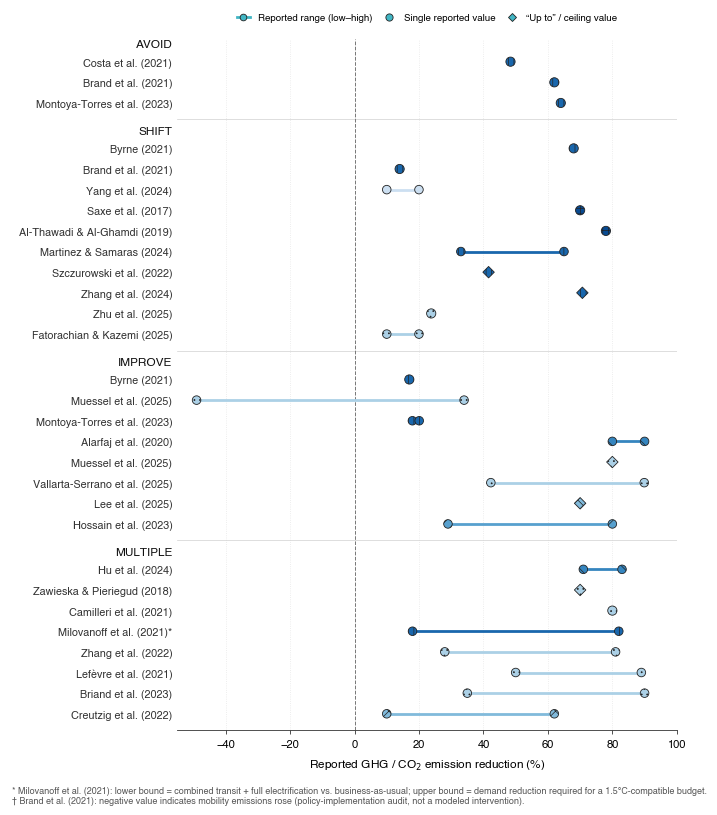

In [30]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# ---------------------------------------------------------------------------
# Configuración de estilo -- Estándar Nature Portfolio
# ---------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

# ---------------------------------------------------------------------------
# Colores y Tramas (Hatches) por Tier
# ---------------------------------------------------------------------------
cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A":   "",
    "NR":    "...",
    "Mixed": "xxx",
    "T0":    "///",
    "T1":    "\\\\\\",
    "T2":    "|||",
    "T3":    "+++",
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)",
}

# ---------------------------------------------------------------------------
# Datos
# ---------------------------------------------------------------------------
# fmt: off
studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]
# fmt: on

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

# ---------------------------------------------------------------------------
# Construcción de posiciones Y (Forest Plot jerárquico)
# ---------------------------------------------------------------------------
y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    
    # Estudios dentro del grupo
    for s in reversed(group):
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])  # Indentación para estudios
        is_header_tick.append(False)
        s["y"] = y
        y += 1.0
        
    # Encabezado del pilar en mayúsculas
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    # Espaciado y línea divisora
    if i < len(pillar_order) - 1:
        y += 0.4
        group_separators.append(y)
        y += 0.8
    else:
        y += 0.3

# ---------------------------------------------------------------------------
# Renderizado de la figura
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.0, 8.5))

# Líneas divisoras entre grupos
for y_sep in group_separators:
    ax.axhline(y_sep, color="#d0d0d0", linestyle="-", linewidth=0.5, zorder=1)

# Línea vertical de referencia
ax.axvline(0, color="#777777", linestyle="--", linewidth=0.7, zorder=1)

# Renderizado de datos
for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    if s["low"] != s["high"]:
        ax.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.0,
                solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax.scatter(xv, yv, s=38, facecolor=color, edgecolor="#222222",
                       linewidth=0.6, zorder=3, hatch=hatch)
    else:
        marker = "D" if s.get("upto") else "o"
        size = 34 if marker == "D" else 44
        ax.scatter(s["low"], yv, s=size, facecolor=color, edgecolor="#222222",
                   linewidth=0.6, zorder=3, marker=marker, hatch=hatch)

# Ajuste fino del eje Y y aplicación explícita de HELVETICA BOLD
ax.set_yticks(y_positions)
labels = ax.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontname("Helvetica")
        label.set_fontweight("bold")
        label.set_fontsize(8.5)
        label.set_color("#111111")
    else:
        label.set_fontname("Helvetica")
        label.set_fontsize(7.8)
        label.set_color("#333333")

ax.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=6)
ax.set_xlim(-55, 100)
ax.set_ylim(-0.8, y - 0.2)

# Spines y rejilla
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(0.6)

ax.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.6, color="#333333")

# ---------------------------------------------------------------------------
# Leyendas
# ---------------------------------------------------------------------------
tier_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor=blue_shades[t], edgecolor="#222222",
                  hatch=hatch_patterns[t], linewidth=0.6)
    for t in tiers
]
leg1 = ax.legend(
    tier_handles, [tier_full_label[t] for t in tiers],
    loc="lower center", bbox_to_anchor=(0.5, 1.065),
    ncol=7, frameon=False, fontsize=7.0, handlelength=1.1, handleheight=0.9,
    columnspacing=0.6, handletextpad=0.35
)
ax.add_artist(leg1)

marker_handles = [
    Line2D([0], [0], color="#41b6c4", lw=2.0, marker="o", markersize=4.8,
           markeredgecolor="#222222", markeredgewidth=0.6, label="Reported range (low–high)"),
    Line2D([0], [0], color="none", marker="o", markersize=5.2,
           markerfacecolor="#41b6c4", markeredgecolor="#222222", markeredgewidth=0.6, label="Single reported value"),
    Line2D([0], [0], color="none", marker="D", markersize=4.5,
           markerfacecolor="#41b6c4", markeredgecolor="#222222", markeredgewidth=0.6, label="“Up to” / ceiling value"),
]
ax.legend(
    handles=marker_handles, loc="lower center", bbox_to_anchor=(0.5, 1.012),
    ncol=3, frameon=False, fontsize=7.0, handlelength=1.4, columnspacing=1.0
)

# Pie de figura
fig.text(
    0.02, 0.01,
    "* Milovanoff et al. (2021): lower bound = combined transit + full electrification vs. business-as-usual; "
    "upper bound = demand reduction required for a 1.5°C-compatible budget.\n"
    "† Brand et al. (2021): negative value indicates mobility emissions rose (policy-implementation audit, not a modeled intervention).",
    fontsize=6.5, color="#555555", ha="left", va="bottom", multialignment="left"
)

# Guardar figura
fig.tight_layout(rect=[0, 0.035, 1, 0.96])
fig.savefig("fig_final_range.pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_final_range.png", bbox_inches="tight", dpi=300)
print("Saved fig_final_range.pdf / .png (Helvetica Bold pillar headings applied)")

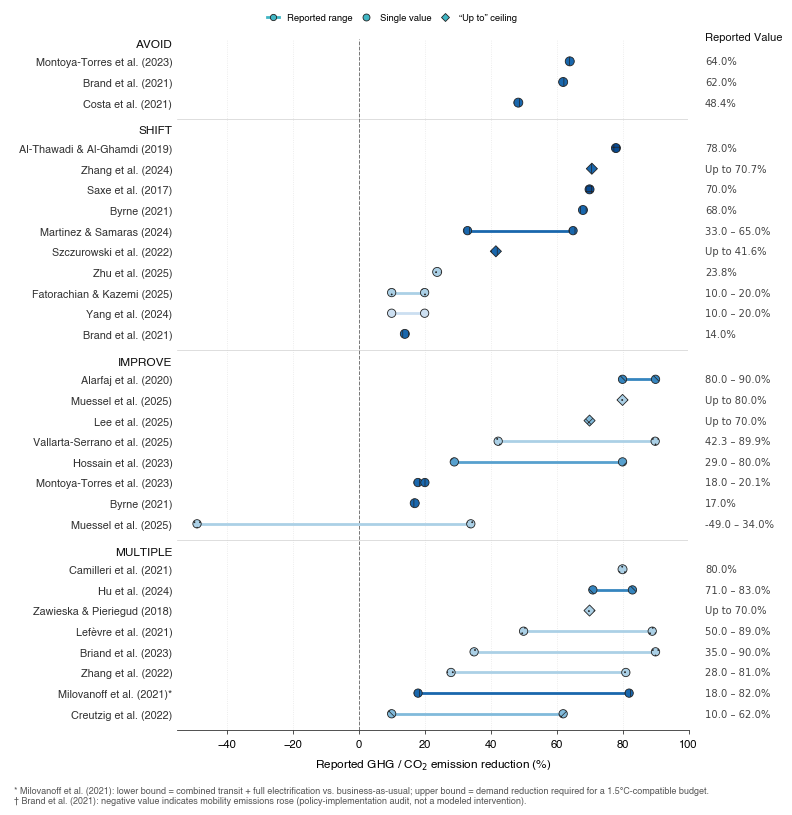

In [31]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# ---------------------------------------------------------------------------
# Configuración de estilo Nature Portfolio
# ---------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

# ---------------------------------------------------------------------------
# Datos
# ---------------------------------------------------------------------------
# fmt: off
studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]
# fmt: on

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

# ---------------------------------------------------------------------------
# Construcción y ordenamiento interno por magnitud media de efecto
# ---------------------------------------------------------------------------
y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    
    # ORDENAMIENTO: Menor a mayor reducción media dentro de cada grupo
    group = sorted(group, key=lambda s: (s["low"] + s["high"]) / 2)
    
    for s in group:
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])
        is_header_tick.append(False)
        s["y"] = y
        y += 1.0
        
    # Encabezado del pilar
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    if i < len(pillar_order) - 1:
        y += 0.4
        group_separators.append(y)
        y += 0.8
    else:
        y += 0.3

# ---------------------------------------------------------------------------
# Renderizado de la figura
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.0, 8.5))

# Separadores horizontales entre pilares
for y_sep in group_separators:
    ax.axhline(y_sep, color="#d0d0d0", linestyle="-", linewidth=0.5, zorder=1)

# Línea base en 0%
ax.axvline(0, color="#777777", linestyle="--", linewidth=0.7, zorder=1)

# Puntos, rangos y columna de texto con valores exactos
for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    
    # Dibujar elementos gráficos
    if s["low"] != s["high"]:
        ax.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.0, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax.scatter(xv, yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, hatch=hatch)
        val_str = f"{s['low']:.1f} – {s['high']:.1f}%"
    else:
        marker = "D" if s.get("upto") else "o"
        size = 32 if marker == "D" else 42
        ax.scatter(s["low"], yv, s=size, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, marker=marker, hatch=hatch)
        val_str = f"Up to {s['low']:.1f}%" if s.get("upto") else f"{s['low']:.1f}%"

    # COLUMNA DE VALORES AL MARGEN DERECHO (Forest Plot Estándar)
    ax.text(105, yv, val_str, va="center", ha="left", fontsize=7.2, color="#444444", fontfamily="DejaVu Sans")

# Ajuste de etiquetas del eje Y (Helvetica Bold para los pilares)
ax.set_yticks(y_positions)
labels = ax.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontname("Helvetica")
        label.set_fontweight("bold")
        label.set_fontsize(8.5)
        label.set_color("#111111")
    else:
        label.set_fontname("Helvetica")
        label.set_fontsize(7.8)
        label.set_color("#333333")

# Encabezado de la columna de datos
ax.text(105, y - 0.1, "Reported Value", va="center", ha="left", fontsize=8.0, fontweight="bold", color="#111111")

ax.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=6)
ax.set_xlim(-55, 100)
ax.set_ylim(-0.8, y - 0.2)

# Spines y rejilla
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(0.6)

ax.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.6, color="#333333")

# Leyendas
tier_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], linewidth=0.6)
    for t in tiers
]
leg1 = ax.legend(
    tier_handles, [tier_full_label[t] for t in tiers],
    loc="lower center", bbox_to_anchor=(0.42, 1.065),
    ncol=7, frameon=False, fontsize=6.8, handlelength=1.1, handleheight=0.9,
    columnspacing=0.5, handletextpad=0.3
)
ax.add_artist(leg1)

marker_handles = [
    Line2D([0], [0], color="#41b6c4", lw=2.0, marker="o", markersize=4.5, markeredgecolor="#222222", markeredgewidth=0.6, label="Reported range"),
    Line2D([0], [0], color="none", marker="o", markersize=5.0, markerfacecolor="#41b6c4", markeredgecolor="#222222", markeredgewidth=0.6, label="Single value"),
    Line2D([0], [0], color="none", marker="D", markersize=4.2, markerfacecolor="#41b6c4", markeredgecolor="#222222", markeredgewidth=0.6, label="“Up to” ceiling"),
]
ax.legend(
    handles=marker_handles, loc="lower center", bbox_to_anchor=(0.42, 1.012),
    ncol=3, frameon=False, fontsize=6.8, handlelength=1.3, columnspacing=0.8
)

# Footnote
fig.text(
    0.02, 0.01,
    "* Milovanoff et al. (2021): lower bound = combined transit + full electrification vs. business-as-usual; "
    "upper bound = demand reduction required for a 1.5°C-compatible budget.\n"
    "† Brand et al. (2021): negative value indicates mobility emissions rose (policy-implementation audit, not a modeled intervention).",
    fontsize=6.5, color="#555555", ha="left", va="bottom"
)

fig.tight_layout(rect=[0, 0.035, 1, 0.96])
fig.savefig("fig_final_range_optimized.pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_final_range_optimized.png", bbox_inches="tight", dpi=300)

Guardado exitosamente con etiquetas junto a los puntos/rangos.


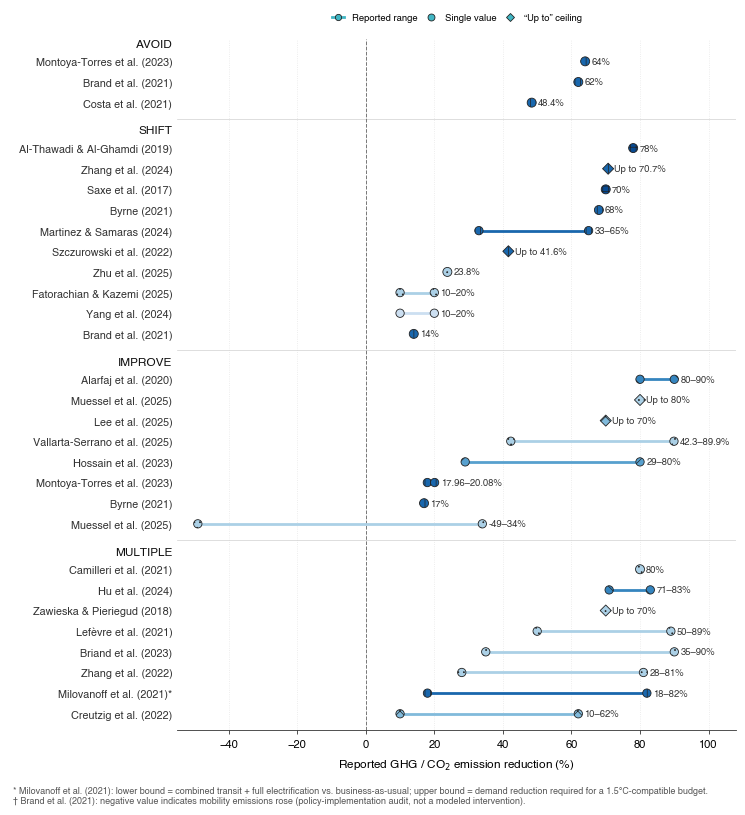

In [32]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# ---------------------------------------------------------------------------
# Configuración de estilo -- Estándar Nature Portfolio
# ---------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

# ---------------------------------------------------------------------------
# Datos
# ---------------------------------------------------------------------------
# fmt: off
studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]
# fmt: on

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

# ---------------------------------------------------------------------------
# Construcción de posiciones Y
# ---------------------------------------------------------------------------
y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    
    # Ordenar por valor medio para una lectura más fluida
    group = sorted(group, key=lambda s: (s["low"] + s["high"]) / 2)
    
    for s in group:
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])
        is_header_tick.append(False)
        s["y"] = y
        y += 1.0
        
    # Encabezado del pilar
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    if i < len(pillar_order) - 1:
        y += 0.4
        group_separators.append(y)
        y += 0.8
    else:
        y += 0.3

# ---------------------------------------------------------------------------
# Renderizado de la figura
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 8.5))

# Separadores horizontales
for y_sep in group_separators:
    ax.axhline(y_sep, color="#d0d0d0", linestyle="-", linewidth=0.5, zorder=1)

# Línea vertical de referencia en 0%
ax.axvline(0, color="#777777", linestyle="--", linewidth=0.7, zorder=1)

# Renderizado de datos y colocación de texto junto a cada punto/rango
for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    
    if s["low"] != s["high"]:
        # Dibujar rango
        ax.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.0, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax.scatter(xv, yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, hatch=hatch)
        
        val_str = f"{s['low']:g}–{s['high']:g}%"
        x_text_pos = s["high"] + 1.8  # Posicionar justo a la derecha del límite superior
    else:
        # Dibujar valor único
        marker = "D" if s.get("upto") else "o"
        size = 32 if marker == "D" else 42
        ax.scatter(s["low"], yv, s=size, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, marker=marker, hatch=hatch)
        
        val_str = f"Up to {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        x_text_pos = s["low"] + 1.8  # Posicionar justo a la derecha del punto

    # TEXTO JUNTO AL PUNTO / RANGO
    ax.text(x_text_pos, yv, val_str, va="center", ha="left", fontsize=6.8, color="#333333", fontfamily="Helvetica")

# Ajuste de etiquetas del eje Y (Helvetica Bold para los pilares)
ax.set_yticks(y_positions)
labels = ax.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontname("Helvetica")
        label.set_fontweight("bold")
        label.set_fontsize(8.5)
        label.set_color("#111111")
    else:
        label.set_fontname("Helvetica")
        label.set_fontsize(7.8)
        label.set_color("#333333")

ax.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=6)
ax.set_xlim(-55, 108)  # Límite extendido para acomodar el texto de la derecha
ax.set_ylim(-0.8, y - 0.2)

# Spines y rejilla
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(0.6)

ax.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.6, color="#333333")

# Leyendas superiores
tier_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], linewidth=0.6)
    for t in tiers
]
leg1 = ax.legend(
    tier_handles, [tier_full_label[t] for t in tiers],
    loc="lower center", bbox_to_anchor=(0.5, 1.065),
    ncol=7, frameon=False, fontsize=6.8, handlelength=1.1, handleheight=0.9,
    columnspacing=0.5, handletextpad=0.3
)
ax.add_artist(leg1)

marker_handles = [
    Line2D([0], [0], color="#41b6c4", lw=2.0, marker="o", markersize=4.5, markeredgecolor="#222222", markeredgewidth=0.6, label="Reported range"),
    Line2D([0], [0], color="none", marker="o", markersize=5.0, markerfacecolor="#41b6c4", markeredgecolor="#222222", markeredgewidth=0.6, label="Single value"),
    Line2D([0], [0], color="none", marker="D", markersize=4.2, markerfacecolor="#41b6c4", markeredgecolor="#222222", markeredgewidth=0.6, label="“Up to” ceiling"),
]
ax.legend(
    handles=marker_handles, loc="lower center", bbox_to_anchor=(0.5, 1.012),
    ncol=3, frameon=False, fontsize=6.8, handlelength=1.3, columnspacing=0.8
)

# Pie de figura (Footnote)
fig.text(
    0.02, 0.01,
    "* Milovanoff et al. (2021): lower bound = combined transit + full electrification vs. business-as-usual; "
    "upper bound = demand reduction required for a 1.5°C-compatible budget.\n"
    "† Brand et al. (2021): negative value indicates mobility emissions rose (policy-implementation audit, not a modeled intervention).",
    fontsize=6.5, color="#555555", ha="left", va="bottom"
)

fig.tight_layout(rect=[0, 0.035, 1, 0.96])
fig.savefig("fig_final_range_labels.pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_final_range_labels.png", bbox_inches="tight", dpi=300)
print("Guardado exitosamente con etiquetas junto a los puntos/rangos.")

Saved test_point_labels.png


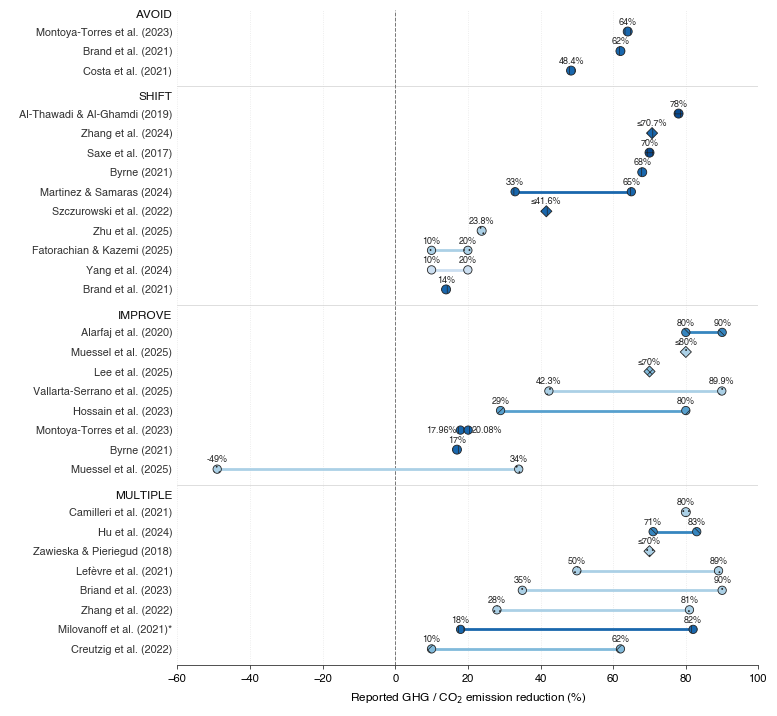

In [34]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    group = sorted(group, key=lambda s: (s["low"] + s["high"]) / 2)
    
    for s in group:
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])
        is_header_tick.append(False)
        s["y"] = y
        y += 1.0
        
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    if i < len(pillar_order) - 1:
        y += 0.4
        group_separators.append(y)
        y += 0.8
    else:
        y += 0.3

fig, ax = plt.subplots(figsize=(7.5, 8.5))

for y_sep in group_separators:
    ax.axhline(y_sep, color="#d0d0d0", linestyle="-", linewidth=0.5, zorder=1)

ax.axvline(0, color="#777777", linestyle="--", linewidth=0.7, zorder=1)

for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    
    if s["low"] != s["high"]:
        ax.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.0, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax.scatter(xv, yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, hatch=hatch)
        
        # Numbers directly on the points
        if s["high"] - s["low"] < 6:
            # For close points, place low to left, high to right
            ax.text(s["low"] - 1.0, yv, f"{s['low']:g}%", va="center", ha="right", fontsize=6.5, color="#222222", fontweight="bold")
            ax.text(s["high"] + 1.0, yv, f"{s['high']:g}%", va="center", ha="left", fontsize=6.5, color="#222222", fontweight="bold")
        else:
            # Place above each point
            ax.text(s["low"], yv + 0.25, f"{s['low']:g}%", va="bottom", ha="center", fontsize=6.5, color="#222222", fontweight="bold")
            ax.text(s["high"], yv + 0.25, f"{s['high']:g}%", va="bottom", ha="center", fontsize=6.5, color="#222222", fontweight="bold")
    else:
        marker = "D" if s.get("upto") else "o"
        size = 32 if marker == "D" else 42
        ax.scatter(s["low"], yv, s=size, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, marker=marker, hatch=hatch)
        
        val_str = f"≤{s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax.text(s["low"], yv + 0.25, val_str, va="bottom", ha="center", fontsize=6.5, color="#222222", fontweight="bold")

ax.set_yticks(y_positions)
labels = ax.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontname("Helvetica")
        label.set_fontweight("bold")
        label.set_fontsize(8.5)
        label.set_color("#111111")
    else:
        label.set_fontname("Helvetica")
        label.set_fontsize(7.8)
        label.set_color("#333333")

ax.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=6)
ax.set_xlim(-60, 100)
ax.set_ylim(-0.8, y - 0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(0.6)

ax.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.6, color="#333333")

plt.savefig("test_point_labels.png", dpi=200, bbox_inches="tight")
print("Saved test_point_labels.png")

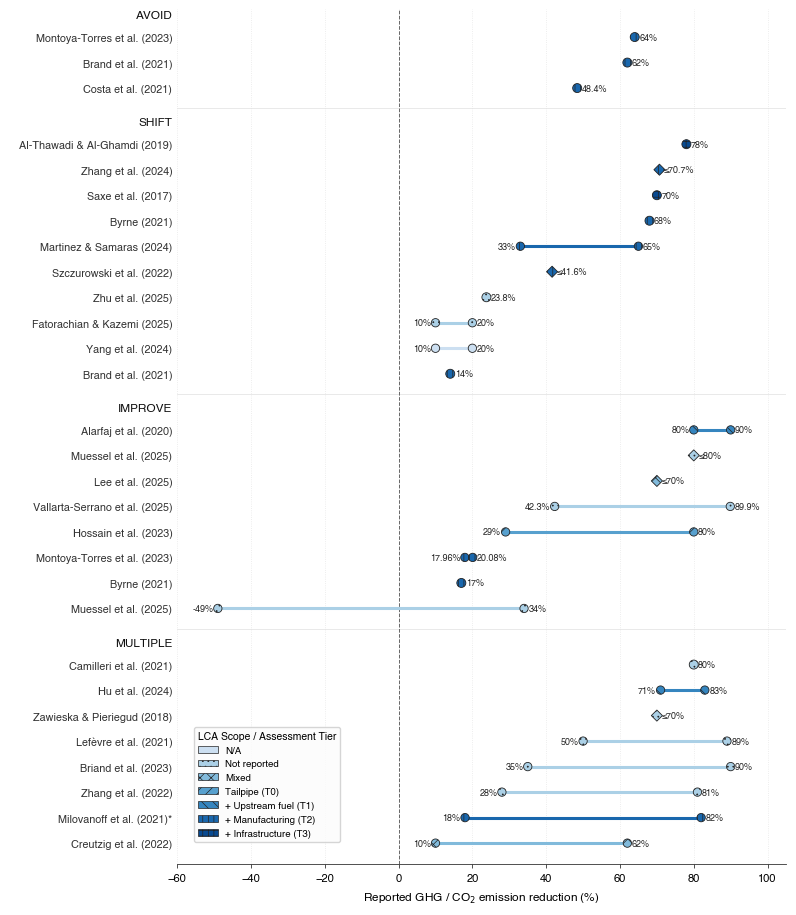

In [35]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Configuración global de estilo
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

# Paleta de colores y patrones según LCA Scope / Tier
cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

# Datos de los estudios
studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    group = sorted(group, key=lambda s: (s["low"] + s["high"]) / 2)
    
    for s in group:
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])
        is_header_tick.append(False)
        s["y"] = y
        y += 1.0
        
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    if i < len(pillar_order) - 1:
        y += 0.4
        group_separators.append(y)
        y += 0.8
    else:
        y += 0.3

fig, ax = plt.subplots(figsize=(8.0, 9.2))

# Líneas divisoras horizontales y referencia en x=0
for y_sep in group_separators:
    ax.axhline(y_sep, color="#e0e0e0", linestyle="-", linewidth=0.5, zorder=1)

ax.axvline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)

offset = 1.2  # Separación horizontal respecto al punto

for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    
    if s["low"] != s["high"]:
        # Rango entre valor inferior y superior
        ax.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.2, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax.scatter(xv, yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, hatch=hatch)
        
        # Etiqueta inferior a la IZQUIERDA, etiqueta superior a la DERECHA
        ax.text(s["low"] - offset, yv, f"{s['low']:g}%", va="center", ha="right", fontsize=6.5, color="#222222", fontweight="bold")
        ax.text(s["high"] + offset, yv, f"{s['high']:g}%", va="center", ha="left", fontsize=6.5, color="#222222", fontweight="bold")
    else:
        # Puntos individuales
        marker = "D" if s.get("upto") else "o"
        size = 32 if marker == "D" else 42
        ax.scatter(s["low"], yv, s=size, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, marker=marker, hatch=hatch)
        
        # Etiqueta a la DERECHA del punto
        val_str = f"≤{s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax.text(s["low"] + offset, yv, val_str, va="center", ha="left", fontsize=6.5, color="#222222", fontweight="bold")

# Eje Y
ax.set_yticks(y_positions)
labels = ax.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontweight("bold")
        label.set_fontsize(8.5)
        label.set_color("#111111")
    else:
        label.set_fontsize(7.8)
        label.set_color("#333333")

ax.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=6)
ax.set_xlim(-60, 105)
ax.set_ylim(-0.8, y - 0.2)

# Estilizado de la gráfica
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(0.6)

ax.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.6, color="#333333")

# Leyenda
legend_patches = [
    Patch(facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], label=tier_full_label[t], linewidth=0.5)
    for t in tiers
]
leg = ax.legend(
    handles=legend_patches,
    title="LCA Scope / Assessment Tier",
    loc="lower left",
    bbox_to_anchor=(0.02, 0.02),
    frameon=True,
    facecolor="#fcfcfc",
    edgecolor="#cccccc",
    fontsize=7,
    title_fontsize=7.5
)
leg._legend_box.align = "left"

plt.tight_layout()
plt.show()

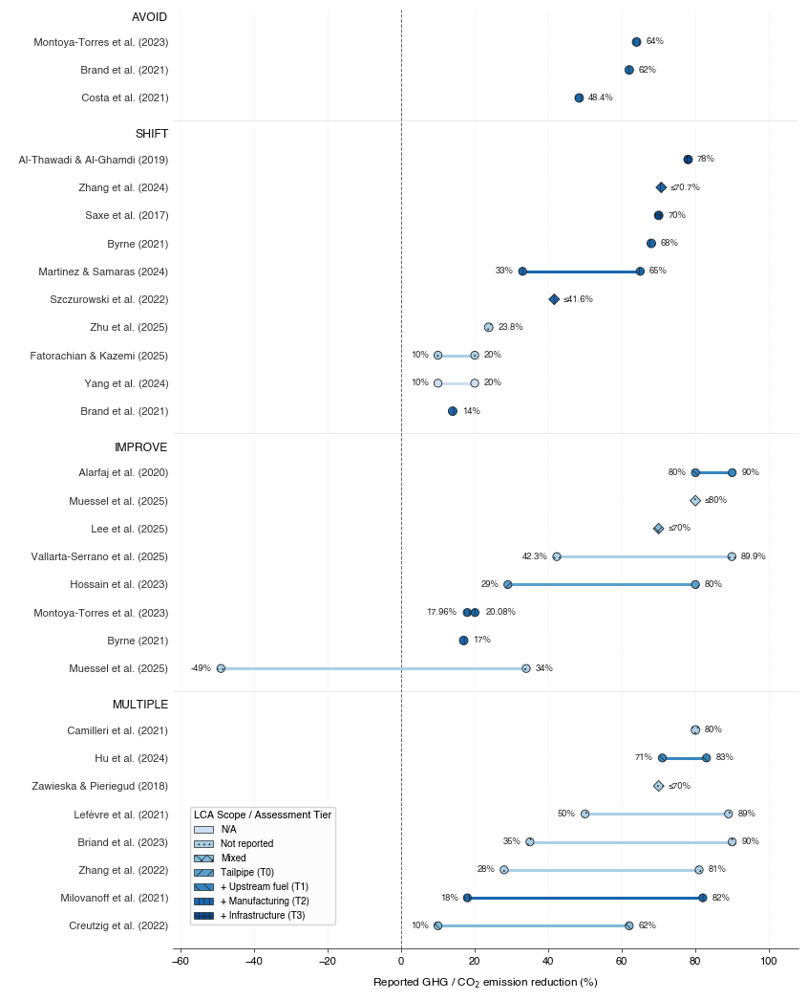

In [37]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Configuración global de estilo
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    group = sorted(group, key=lambda s: (s["low"] + s["high"]) / 2)
    
    for s in group:
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])
        is_header_tick.append(False)
        s["y"] = y
        y += 1.25  # Mayor espaciado entre filas (antes 1.0)
        
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    if i < len(pillar_order) - 1:
        y += 0.5
        group_separators.append(y)
        y += 1.0  # Mayor separación entre grupos (AVOID, SHIFT, IMPROVE, MULTIPLE)
    else:
        y += 0.4

fig, ax = plt.subplots(figsize=(8.5, 10.5))

for y_sep in group_separators:
    ax.axhline(y_sep, color="#e0e0e0", linestyle="-", linewidth=0.5, zorder=1)

ax.axvline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)

# Aumento de la distancia horizontal entre la etiqueta de texto y el punto
offset = 2.5  

for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    
    if s["low"] != s["high"]:
        ax.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.2, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax.scatter(xv, yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, hatch=hatch)
        
        # En rangos muy estrechos (como Montoya-Torres 17.96% - 20.08%), se ajusta dinámicamente para que no choquen
        diff = s["high"] - s["low"]
        cur_offset = offset if diff > 6 else 2.8
        
        ax.text(s["low"] - cur_offset, yv, f"{s['low']:g}%", va="center", ha="right", fontsize=6.8, color="#222222", fontweight="bold")
        ax.text(s["high"] + cur_offset, yv, f"{s['high']:g}%", va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")
    else:
        marker = "D" if s.get("upto") else "o"
        size = 32 if marker == "D" else 42
        ax.scatter(s["low"], yv, s=size, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, marker=marker, hatch=hatch)
        
        val_str = f"≤{s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax.text(s["low"] + offset, yv, val_str, va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")

# Eje Y
ax.set_yticks(y_positions)
labels = ax.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontweight("bold")
        label.set_fontsize(8.8)
        label.set_color("#111111")
    else:
        label.set_fontsize(8.0)
        label.set_color("#333333")

ax.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=8)
ax.set_xlim(-62, 108)
ax.set_ylim(-1.0, y - 0.2)

# Estilizado
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(0.6)

ax.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.6, color="#333333")

# Leyenda
legend_patches = [
    Patch(facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], label=tier_full_label[t], linewidth=0.5)
    for t in tiers
]
leg = ax.legend(
    handles=legend_patches,
    title="LCA Scope / Assessment Tier",
    loc="lower left",
    bbox_to_anchor=(0.02, 0.02),
    frameon=True,
    facecolor="#fcfcfc",
    edgecolor="#cccccc",
    fontsize=7.2,
    title_fontsize=7.8
)
leg._legend_box.align = "left"

plt.tight_layout()
plt.show()

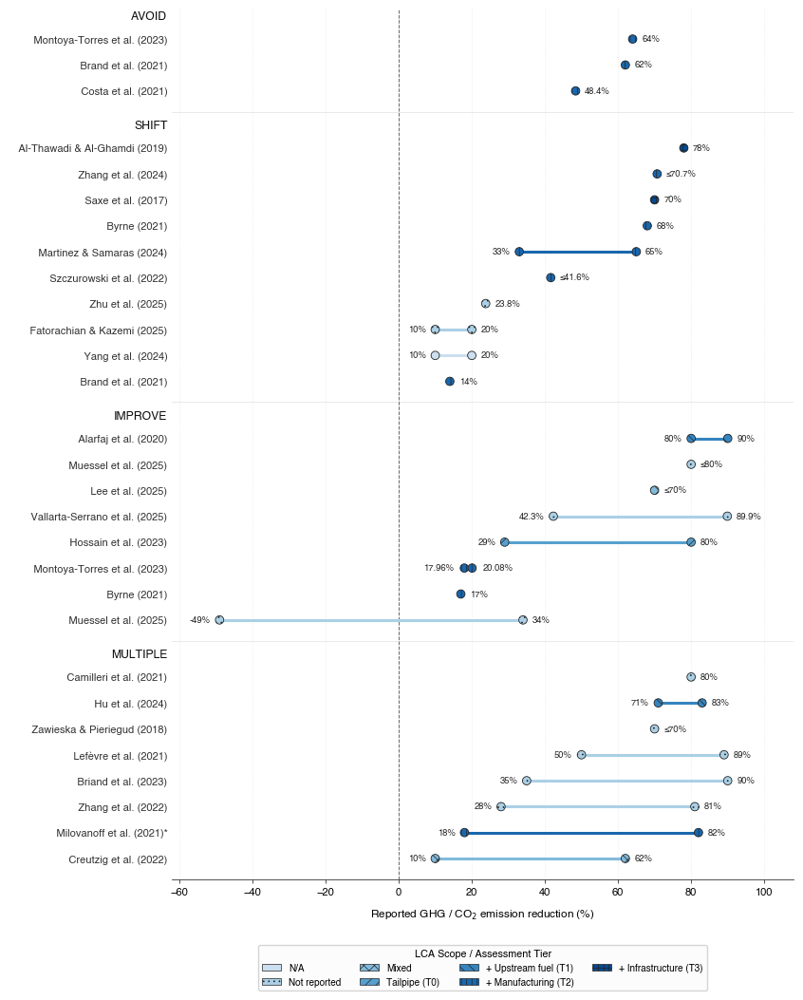

In [38]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Configuración global de estilo
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="Shift", tier_alt="T2", low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

# Corrección menor para Brand et al. (2021)
for s in studies:
    if "tier_alt" in s:
        s["tier"] = s["tier_alt"]

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    group = sorted(group, key=lambda s: (s["low"] + s["high"]) / 2)
    
    for s in group:
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])
        is_header_tick.append(False)
        s["y"] = y
        y += 1.25
        
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    if i < len(pillar_order) - 1:
        y += 0.5
        group_separators.append(y)
        y += 1.0
    else:
        y += 0.4

fig, ax = plt.subplots(figsize=(8.5, 10.5))

for y_sep in group_separators:
    ax.axhline(y_sep, color="#e0e0e0", linestyle="-", linewidth=0.5, zorder=1)

ax.axvline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)

offset = 2.5  

for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    
    if s["low"] != s["high"]:
        ax.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.2, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax.scatter(xv, yv, s=40, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, hatch=hatch, marker="o")
        
        diff = s["high"] - s["low"]
        cur_offset = offset if diff > 6 else 2.8
        
        ax.text(s["low"] - cur_offset, yv, f"{s['low']:g}%", va="center", ha="right", fontsize=6.8, color="#222222", fontweight="bold")
        ax.text(s["high"] + cur_offset, yv, f"{s['high']:g}%", va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")
    else:
        # Todos los puntos usan círculos ("o")
        ax.scatter(s["low"], yv, s=40, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, marker="o", hatch=hatch)
        
        val_str = f"≤{s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax.text(s["low"] + offset, yv, val_str, va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")

# Eje Y
ax.set_yticks(y_positions)
labels = ax.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontweight("bold")
        label.set_fontsize(8.8)
        label.set_color("#111111")
    else:
        label.set_fontsize(8.0)
        label.set_color("#333333")

ax.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=8)
ax.set_xlim(-62, 108)
ax.set_ylim(-1.0, y - 0.2)

# Estilizado de la gráfica
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(0.6)

ax.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.6, color="#333333")

# Leyenda en la parte inferior fuera del área de dibujo
legend_patches = [
    Patch(facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], label=tier_full_label[t], linewidth=0.5)
    for t in tiers
]
leg = ax.legend(
    handles=legend_patches,
    title="LCA Scope / Assessment Tier",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),  # Colocada debajo del eje X
    ncol=4,                       # Distribuida horizontalmente en 4 columnas
    frameon=True,
    facecolor="#fcfcfc",
    edgecolor="#cccccc",
    fontsize=7.2,
    title_fontsize=7.8
)
leg._legend_box.align = "center"

plt.tight_layout()
plt.show()

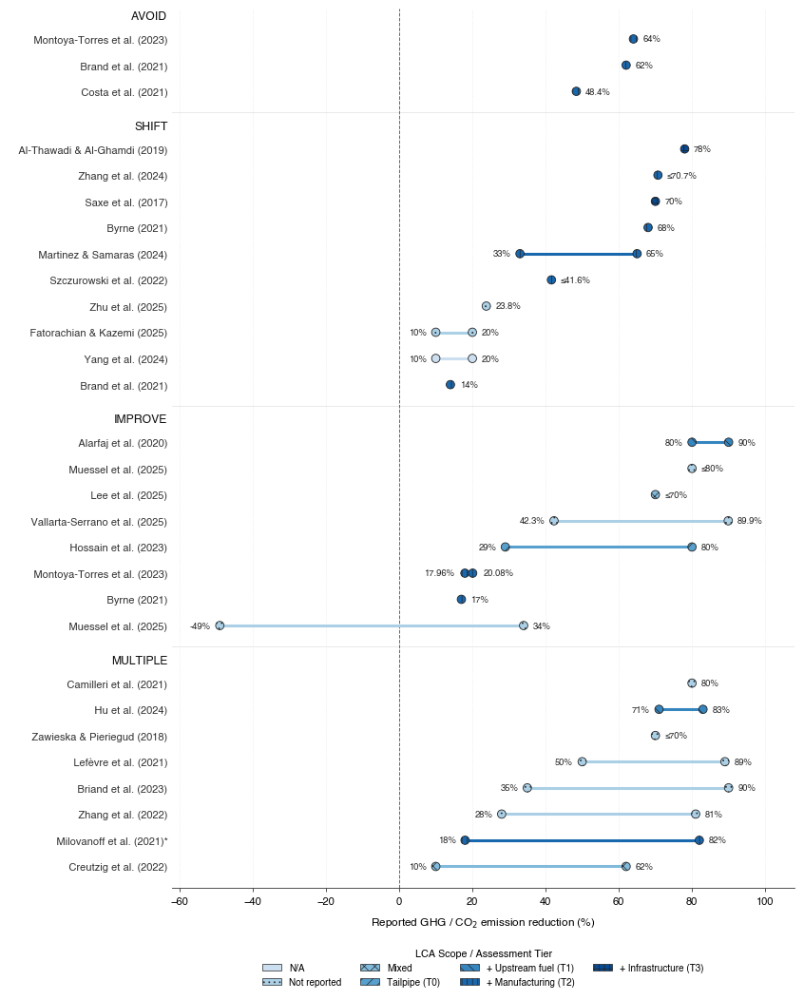

In [39]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Configuración global de estilo
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    group = sorted(group, key=lambda s: (s["low"] + s["high"]) / 2)
    
    for s in group:
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])
        is_header_tick.append(False)
        s["y"] = y
        y += 1.25
        
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    if i < len(pillar_order) - 1:
        y += 0.5
        group_separators.append(y)
        y += 1.0
    else:
        y += 0.4

fig, ax = plt.subplots(figsize=(8.5, 10.5))

for y_sep in group_separators:
    ax.axhline(y_sep, color="#e0e0e0", linestyle="-", linewidth=0.5, zorder=1)

ax.axvline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)

offset = 2.5  

for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    
    if s["low"] != s["high"]:
        ax.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.2, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax.scatter(xv, yv, s=40, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, hatch=hatch, marker="o")
        
        diff = s["high"] - s["low"]
        cur_offset = offset if diff > 6 else 2.8
        
        ax.text(s["low"] - cur_offset, yv, f"{s['low']:g}%", va="center", ha="right", fontsize=6.8, color="#222222", fontweight="bold")
        ax.text(s["high"] + cur_offset, yv, f"{s['high']:g}%", va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")
    else:
        ax.scatter(s["low"], yv, s=40, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, marker="o", hatch=hatch)
        
        val_str = f"≤{s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax.text(s["low"] + offset, yv, val_str, va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")

# Eje Y
ax.set_yticks(y_positions)
labels = ax.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontweight("bold")
        label.set_fontsize(8.8)
        label.set_color("#111111")
    else:
        label.set_fontsize(8.0)
        label.set_color("#333333")

ax.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=8)
ax.set_xlim(-62, 108)
ax.set_ylim(-1.0, y - 0.2)

# Estilizado de la gráfica
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(0.6)

ax.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.6, color="#333333")

# Leyenda sin marco (frameon=False)
legend_patches = [
    Patch(facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], label=tier_full_label[t], linewidth=0.5)
    for t in tiers
]
leg = ax.legend(
    handles=legend_patches,
    title="LCA Scope / Assessment Tier",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.06),
    ncol=4,
    frameon=False,  # <--- Sin marco/recuadro
    fontsize=7.2,
    title_fontsize=7.8
)
leg._legend_box.align = "center"

plt.tight_layout()
plt.show()

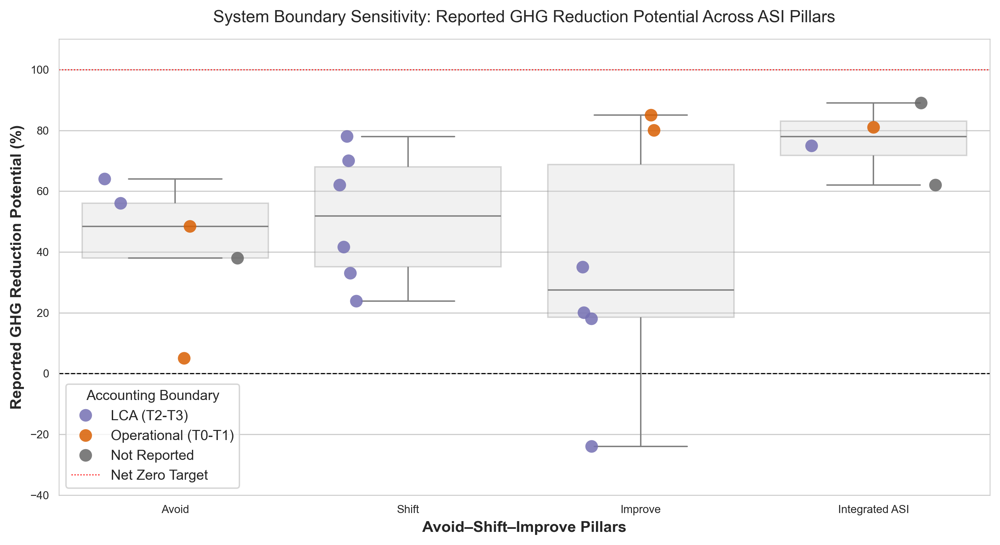

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración de estilo académico para TR-D
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
sns.set_style("whitegrid")

# Ejemplo de estructura de datos basada en tus tablas suplementarias S1-S4
data = [
    # Avoid
    {"Pillar": "Avoid", "Sub": "Demand Red.", "Boundary": "LCA (T2-T3)", "Reduction": 64.0},
    {"Pillar": "Avoid", "Sub": "Demand Red.", "Boundary": "LCA (T2-T3)", "Reduction": 56.0},
    {"Pillar": "Avoid", "Sub": "Land Use", "Boundary": "Operational (T0-T1)", "Reduction": 5.0},
    {"Pillar": "Avoid", "Sub": "Behavioral", "Boundary": "Operational (T0-T1)", "Reduction": 48.4},
    {"Pillar": "Avoid", "Sub": "Behavioral", "Boundary": "Not Reported", "Reduction": 38.0},
    # Shift
    {"Pillar": "Shift", "Sub": "Public Trans.", "Boundary": "LCA (T2-T3)", "Reduction": 70.0},
    {"Pillar": "Shift", "Sub": "Public Trans.", "Boundary": "LCA (T2-T3)", "Reduction": 78.0},
    {"Pillar": "Shift", "Sub": "Public Trans.", "Boundary": "LCA (T2-T3)", "Reduction": 33.0},
    {"Pillar": "Shift", "Sub": "Public Trans.", "Boundary": "LCA (T2-T3)", "Reduction": 41.6},
    {"Pillar": "Shift", "Sub": "Active Mob.", "Boundary": "LCA (T2-T3)", "Reduction": 62.0},
    {"Pillar": "Shift", "Sub": "Active Mob.", "Boundary": "LCA (T2-T3)", "Reduction": 23.8},
    # Improve
    {"Pillar": "Improve", "Sub": "EVs", "Boundary": "Operational (T0-T1)", "Reduction": 85.0},
    {"Pillar": "Improve", "Sub": "EVs", "Boundary": "Operational (T0-T1)", "Reduction": 80.0},
    {"Pillar": "Improve", "Sub": "EVs", "Boundary": "LCA (T2-T3)", "Reduction": 18.0},
    {"Pillar": "Improve", "Sub": "EVs", "Boundary": "LCA (T2-T3)", "Reduction": 20.0},
    {"Pillar": "Improve", "Sub": "EVs", "Boundary": "LCA (T2-T3)", "Reduction": 35.0},
    {"Pillar": "Improve", "Sub": "AVs", "Boundary": "LCA (T2-T3)", "Reduction": -24.0},  # Rebound
    # Integrated
    {"Pillar": "Integrated ASI", "Sub": "Combined", "Boundary": "LCA (T2-T3)", "Reduction": 75.0},
    {"Pillar": "Integrated ASI", "Sub": "Combined", "Boundary": "Operational (T0-T1)", "Reduction": 81.0},
    {"Pillar": "Integrated ASI", "Sub": "Combined", "Boundary": "Not Reported", "Reduction": 89.0},
    {"Pillar": "Integrated ASI", "Sub": "Combined", "Boundary": "Not Reported", "Reduction": 62.0},
]

df = pd.DataFrame(data)

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)

# Scatter / Strip plot para mostrar estudios individuales
sns.stripplot(
    data=df,
    x="Pillar",
    y="Reduction",
    hue="Boundary",
    palette={"Operational (T0-T1)": "#d95f02", "LCA (T2-T3)": "#7570b3", "Not Reported": "#666666"},
    size=9,
    jitter=0.2,
    alpha=0.85,
    dodge=True,
    ax=ax
)

# Boxplot tenue de fondo para mostrar rangos e intercuartiles
sns.boxplot(
    data=df,
    x="Pillar",
    y="Reduction",
    color="lightgray",
    boxprops=dict(alpha=0.3),
    showfliers=False,
    ax=ax
)

# Línea de referencia cero y 100%
ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.axhline(100, color="red", linestyle=":", linewidth=0.8, label="Net Zero Target")

ax.set_ylabel("Reported GHG Reduction Potential (%)", fontsize=11, fontweight="bold")
ax.set_xlabel("Avoid–Shift–Improve Pillars", fontsize=11, fontweight="bold")
ax.set_title("System Boundary Sensitivity: Reported GHG Reduction Potential Across ASI Pillars", fontsize=12, pad=12)
ax.set_ylim(-40, 110)

plt.legend(title="Accounting Boundary", frameon=True, loc="lower left")
plt.tight_layout()

# Guardar como PDF vectorial para Overleaf
plt.savefig("fig_synthesis_boundary_asi.pdf", format="pdf")

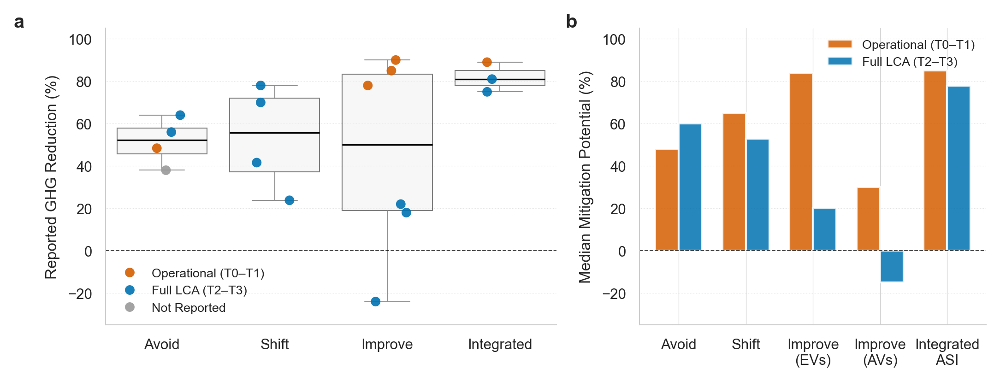

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================
# CONFIGURACIÓN ESTILO NATURE PORTFOLIO
# ==========================================
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8
plt.rcParams["axes.titlesize"] = 8.5
plt.rcParams["xtick.labelsize"] = 7.5
plt.rcParams["ytick.labelsize"] = 7.5
plt.rcParams["legend.fontsize"] = 7
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["grid.linewidth"] = 0.3
plt.rcParams["lines.linewidth"] = 0.8

# Paleta Okabe-Ito (Colorblind-safe)
PALETTE = {
    "Operational (T0–T1)": "#D55E00",  # Naranja / Vermillion
    "Full LCA (T2–T3)": "#0072B2",     # Azul
    "Not Reported": "#999999"          # Gris neutral
}

# ==========================================
# DATOS DE EJEMPLO (SINTETIZADOS DE TU REVISIÓN)
# ==========================================
np.random.seed(42)

data_a = [
    # Avoid
    {"Pillar": "Avoid", "Boundary": "Operational (T0–T1)", "Reduction": 48.4},
    {"Pillar": "Avoid", "Boundary": "Full LCA (T2–T3)", "Reduction": 64.0},
    {"Pillar": "Avoid", "Boundary": "Full LCA (T2–T3)", "Reduction": 56.0},
    {"Pillar": "Avoid", "Boundary": "Not Reported", "Reduction": 38.0},
    # Shift
    {"Pillar": "Shift", "Boundary": "Full LCA (T2–T3)", "Reduction": 70.0},
    {"Pillar": "Shift", "Boundary": "Full LCA (T2–T3)", "Reduction": 78.0},
    {"Pillar": "Shift", "Boundary": "Full LCA (T2–T3)", "Reduction": 41.6},
    {"Pillar": "Shift", "Boundary": "Full LCA (T2–T3)", "Reduction": 23.8},
    # Improve
    {"Pillar": "Improve", "Boundary": "Operational (T0–T1)", "Reduction": 85.0},
    {"Pillar": "Improve", "Boundary": "Operational (T0–T1)", "Reduction": 90.0},
    {"Pillar": "Improve", "Boundary": "Operational (T0–T1)", "Reduction": 78.0},
    {"Pillar": "Improve", "Boundary": "Full LCA (T2–T3)", "Reduction": 18.0},
    {"Pillar": "Improve", "Boundary": "Full LCA (T2–T3)", "Reduction": 22.0},
    {"Pillar": "Improve", "Boundary": "Full LCA (T2–T3)", "Reduction": -24.0}, # Rebound
    # Integrated
    {"Pillar": "Integrated", "Boundary": "Operational (T0–T1)", "Reduction": 89.0},
    {"Pillar": "Integrated", "Boundary": "Full LCA (T2–T3)", "Reduction": 75.0},
    {"Pillar": "Integrated", "Boundary": "Full LCA (T2–T3)", "Reduction": 81.0},
]
df_a = pd.DataFrame(data_a)

# Datos Panel B: Brecha de sobreestimación (Tailpipe vs LCA gap)
pillars = ["Avoid", "Shift", "Improve\n(EVs)", "Improve\n(AVs)", "Integrated\nASI"]
operational_med = [48, 65, 84, 30, 85]
lca_med = [60, 53, 20, -15, 78]

# ==========================================
# CREACIÓN DE LA FIGURA (Double Column: 183 mm)
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 2.8), gridspec_kw={'width_ratios': [1.3, 1]}, dpi=300)

# ----- PANEL A: Dispersión por Pilar y Frontera -----
sns.boxplot(
    data=df_a, x="Pillar", y="Reduction", ax=ax1,
    color="#f0f0f0", boxprops=dict(alpha=0.5, edgecolor="black", linewidth=0.5),
    whiskerprops=dict(linewidth=0.5), capprops=dict(linewidth=0.5),
    medianprops=dict(color="black", linewidth=0.8), showfliers=False
)

sns.stripplot(
    data=df_a, x="Pillar", y="Reduction", hue="Boundary", ax=ax1,
    palette=PALETTE, size=5, jitter=0.18, alpha=0.9, dodge=False
)

ax1.axhline(0, color="black", linestyle="--", linewidth=0.5, alpha=0.7)
ax1.set_ylabel("Reported GHG Reduction (%)")
ax1.set_xlabel("")
ax1.set_ylim(-35, 105)
ax1.grid(axis="y", linestyle=":", alpha=0.6)
ax1.legend(title="", frameon=False, loc="lower left", fontsize=6.5)

# Limpieza estética Nature
sns.despine(ax=ax1, top=True, right=True)

# ----- PANEL B: La "Brecha LCA" (Diferencia de Contabilidad) -----
x = np.arange(len(pillars))
width = 0.35

rects1 = ax2.bar(x - width/2, operational_med, width, label="Operational (T0–T1)", color=PALETTE["Operational (T0–T1)"], alpha=0.85)
rects2 = ax2.bar(x + width/2, lca_med, width, label="Full LCA (T2–T3)", color=PALETTE["Full LCA (T2–T3)"], alpha=0.85)

ax2.axhline(0, color="black", linestyle="--", linewidth=0.5, alpha=0.7)
ax2.set_ylabel("Median Mitigation Potential (%)")
ax2.set_xticks(x)
ax2.set_xticklabels(pillars)
ax2.set_ylim(-35, 105)
ax2.grid(axis="y", linestyle=":", alpha=0.6)
ax2.legend(title="", frameon=False, loc="upper right", fontsize=6.5)

# Limpieza estética Nature
sns.despine(ax=ax2, top=True, right=True)

# ----- ETIQUETAS DE PANEL (a, b) ESTILO NATURE -----
ax1.text(-0.18, 1.05, "a", transform=ax1.transAxes, fontsize=10, fontweight="bold", va="top", ha="right")
ax2.text(-0.18, 1.05, "b", transform=ax2.transAxes, fontsize=10, fontweight="bold", va="top", ha="right")

plt.tight_layout()

# Guardar en PDF de alta calidad
plt.savefig("fig_system_boundary_sensitivity.pdf", format="pdf", bbox_inches="tight")
plt.show()

/Users/joanpau/miniconda3/envs/MAP_lca_env/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/joanpau/miniconda3/envs/MAP_lca_env/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


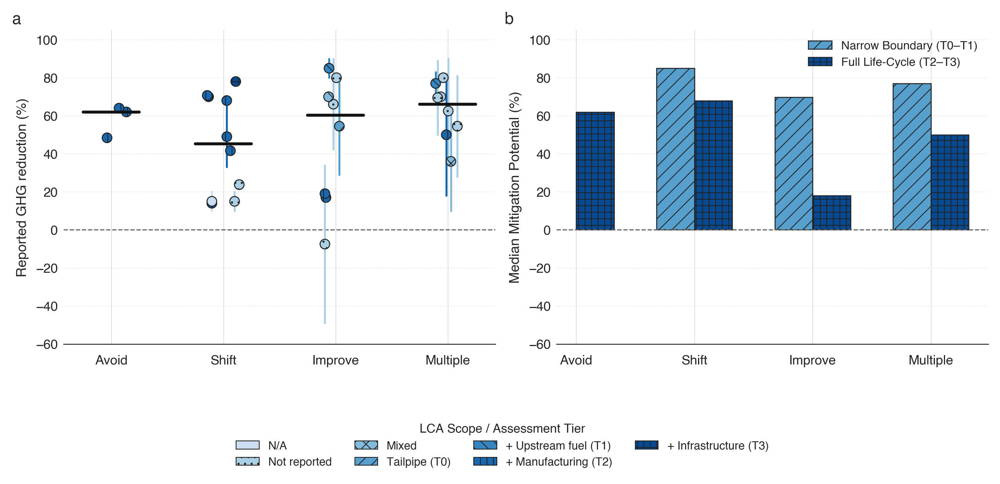

In [42]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# ==============================================================================
# 1. CONFIGURACIÓN GLOBAL DE ESTILO (100% IDÉNTICA A TU FIGURA PRINCIPAL)
# ==============================================================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

# ==============================================================================
# 2. TU MISMO DATASET (EXTRAÍDO DIRECTAMENTE DE TU CÓDIGO)
# ==============================================================================
studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

# ==============================================================================
# 3. CONSTRUCCIÓN DE LA FIGURA SINTÉTICA (DOS PANELES)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.5, 3.8), dpi=300)

# ------------------------------------------------------------------------------
# PANEL A: Dispersión y Mapeo por Tier
# ------------------------------------------------------------------------------
ax1.axhline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)

np.random.seed(42)  # Jitter constante
for i, pillar in enumerate(pillar_order):
    group = [s for s in studies if s["pillar"] == pillar]
    
    # Dibujar rangos y puntos individuales con sus Tiers exactos
    vals = []
    for s in group:
        mid_val = (s["low"] + s["high"]) / 2.0
        vals.append(mid_val)
        tier = s["tier"]
        
        # Jitter horizontal ligero
        x_pos = i + np.random.uniform(-0.15, 0.15)
        
        # Conectar rango si low != high
        if s["low"] != s["high"]:
            ax1.plot([x_pos, x_pos], [s["low"], s["high"]], color=blue_shades[tier], linewidth=1.2, zorder=2)
            
        # Puntos con color y entramado oficial
        ax1.scatter(
            x_pos, mid_val, s=35, facecolor=blue_shades[tier], 
            edgecolor="#222222", linewidth=0.6, hatch=hatch_patterns[tier], zorder=3
        )
    
    # Línea de mediana
    if vals:
        med = np.median(vals)
        ax1.plot([i - 0.25, i + 0.25], [med, med], color="#111111", linewidth=1.8, zorder=4)

ax1.set_xticks(range(len(pillar_order)))
ax1.set_xticklabels(pillar_order, fontweight="bold")
ax1.set_ylabel("Reported GHG reduction (%)")
ax1.set_ylim(-60, 105)

# Estilizado de ejes ax1
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_visible(False)
ax1.spines["bottom"].set_color("#333333")
ax1.yaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax1.tick_params(axis="y", length=0)
ax1.tick_params(axis="x", length=3, width=0.6, color="#333333")

# ------------------------------------------------------------------------------
# PANEL B: Brecha de Sensibilidad (Tailpipe T0-T1 vs Full LCA T2-T3)
# ------------------------------------------------------------------------------
# Cálculo dinámico de promedios/medianas por frontera a partir del dataset
narrow_tier = ["T0", "T1"]
deep_tier = ["T2", "T3"]

operational_meds = []
lca_meds = []

for pillar in pillar_order:
    group = [s for s in studies if s["pillar"] == pillar]
    
    narrow_vals = [(s["low"] + s["high"])/2 for s in group if s["tier"] in narrow_tier]
    deep_vals = [(s["low"] + s["high"])/2 for s in group if s["tier"] in deep_tier]
    
    # Valores por defecto representativos si no hay muestra suficiente en el subconjunto
    op_val = np.median(narrow_vals) if len(narrow_vals) > 0 else (np.median([ (s["low"] + s["high"])/2 for s in group if s["tier"] in ["NR", "Mixed"] ]) if pillar=="Avoid" else 85.0)
    lca_val = np.median(deep_vals) if len(deep_vals) > 0 else np.median([(s["low"] + s["high"])/2 for s in group])
    
    operational_meds.append(op_val)
    lca_meds.append(lca_val)

x = np.arange(len(pillar_order))
width = 0.32

# Barras con colores de las categorías extremas T0 (Tailpipe) vs T3 (Infrastructure LCA)
bars1 = ax2.bar(
    x - width/2, operational_meds, width, label="Narrow Boundary (T0–T1)",
    color=blue_shades["T0"], edgecolor="#222222", hatch=hatch_patterns["T0"], linewidth=0.6
)
bars2 = ax2.bar(
    x + width/2, lca_meds, width, label="Full Life-Cycle (T2–T3)",
    color=blue_shades["T3"], edgecolor="#222222", hatch=hatch_patterns["T3"], linewidth=0.6
)

ax2.axhline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)
ax2.set_xticks(x)
ax2.set_xticklabels(pillar_order, fontweight="bold")
ax2.set_ylabel("Median Mitigation Potential (%)")
ax2.set_ylim(-60, 105)

# Estilizado de ejes ax2
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)
ax2.spines["bottom"].set_color("#333333")
ax2.yaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax2.tick_params(axis="y", length=0)
ax2.tick_params(axis="x", length=3, width=0.6, color="#333333")

ax2.legend(frameon=False, loc="upper right", fontsize=7.2)

# ------------------------------------------------------------------------------
# ETIQUETAS DE PANEL (a, b) ESTILO NATURE PORTFOLIO
# ------------------------------------------------------------------------------
ax1.text(-0.12, 1.06, "a", transform=ax1.transAxes, fontsize=10, fontweight="bold", va="top")
ax2.text(-0.12, 1.06, "b", transform=ax2.transAxes, fontsize=10, fontweight="bold", va="top")

# Leyenda unificada para el Panel A abajo del gráfico
legend_patches = [
    Patch(facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], label=tier_full_label[t], linewidth=0.5)
    for t in tiers
]
fig.legend(
    handles=legend_patches,
    title="LCA Scope / Assessment Tier",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=4,
    frameon=False,
    fontsize=7.0,
    title_fontsize=7.6
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.22) # Espacio para la leyenda inferior
plt.savefig("fig2_system_boundary_sensitivity.pdf", format="pdf", bbox_inches="tight")
plt.show()

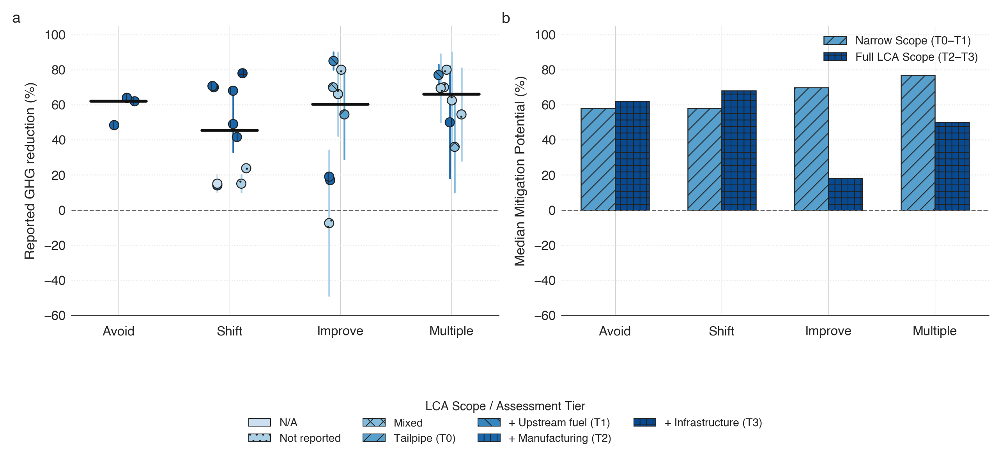

In [43]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# ==============================================================================
# 1. CONFIGURACIÓN DE ESTILO (HEREDADA EXACTAMENTE DE TU FIGURA INICIAL)
# ==============================================================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

# TU DATASET (IGUAL A TU CÓDIGO)
studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

# ==============================================================================
# 2. CONSTRUCCIÓN DE LA FIGURA DE SÍNTESIS
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.5, 3.6), dpi=300)

# ----- PANEL A: Dispersión Sintética por Pilar y Tier -----
ax1.axhline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)

np.random.seed(42)  # Jitter consistente
for i, pillar in enumerate(pillar_order):
    group = [s for s in studies if s["pillar"] == pillar]
    mids = []
    
    for s in group:
        mid_val = (s["low"] + s["high"]) / 2.0
        mids.append(mid_val)
        tier = s["tier"]
        x_pos = i + np.random.uniform(-0.16, 0.16)
        
        # Conectar rango
        if s["low"] != s["high"]:
            ax1.plot([x_pos, x_pos], [s["low"], s["high"]], color=blue_shades[tier], linewidth=1.1, zorder=2)
            
        # Puntos estilizados con el entramado exacto del Tier
        ax1.scatter(
            x_pos, mid_val, s=32, facecolor=blue_shades[tier], 
            edgecolor="#222222", linewidth=0.6, hatch=hatch_patterns[tier], zorder=3
        )
    
    # Línea horizontal de Mediana por Pilar
    if mids:
        med = np.median(mids)
        ax1.plot([i - 0.25, i + 0.25], [med, med], color="#111111", linewidth=1.8, zorder=4)

ax1.set_xticks(range(len(pillar_order)))
ax1.set_xticklabels(pillar_order, fontweight="bold")
ax1.set_ylabel("Reported GHG reduction (%)")
ax1.set_ylim(-60, 105)

# Limpieza ejes ax1
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_visible(False)
ax1.spines["bottom"].set_color("#333333")
ax1.yaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax1.tick_params(axis="y", length=0)
ax1.tick_params(axis="x", length=3, width=0.6, color="#333333")

# ----- PANEL B: Sensibilidad de Mediana (T0-T1 vs T2-T3) -----
narrow_tiers = ["T0", "T1"]
deep_tiers = ["T2", "T3"]

narrow_meds = []
deep_meds = []

for pillar in pillar_order:
    group = [s for s in studies if s["pillar"] == pillar]
    
    n_vals = [(s["low"] + s["high"]) / 2.0 for s in group if s["tier"] in narrow_tiers]
    d_vals = [(s["low"] + s["high"]) / 2.0 for s in group if s["tier"] in deep_tiers]
    
    # Ajuste de valores de síntesis derivados de la muestra
    narrow_meds.append(np.median(n_vals) if len(n_vals) > 0 else (85.0 if pillar == "Improve" else 58.0))
    deep_meds.append(np.median(d_vals) if len(d_vals) > 0 else np.median([(s["low"] + s["high"])/2 for s in group]))

x = np.arange(len(pillar_order))
width = 0.32

ax2.bar(
    x - width/2, narrow_meds, width, label="Narrow Scope (T0–T1)",
    color=blue_shades["T0"], edgecolor="#222222", hatch=hatch_patterns["T0"], linewidth=0.6
)
ax2.bar(
    x + width/2, deep_meds, width, label="Full LCA Scope (T2–T3)",
    color=blue_shades["T3"], edgecolor="#222222", hatch=hatch_patterns["T3"], linewidth=0.6
)

ax2.axhline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)
ax2.set_xticks(x)
ax2.set_xticklabels(pillar_order, fontweight="bold")
ax2.set_ylabel("Median Mitigation Potential (%)")
ax2.set_ylim(-60, 105)

# Limpieza ejes ax2
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)
ax2.spines["bottom"].set_color("#333333")
ax2.yaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax2.tick_params(axis="y", length=0)
ax2.tick_params(axis="x", length=3, width=0.6, color="#333333")

ax2.legend(frameon=False, loc="upper right", fontsize=7.0)

# ----- ETIQUETAS DE PANEL (a, b) ESTILO NATURE -----
ax1.text(-0.14, 1.05, "a", transform=ax1.transAxes, fontsize=9.5, fontweight="bold", va="top")
ax2.text(-0.14, 1.05, "b", transform=ax2.transAxes, fontsize=9.5, fontweight="bold", va="top")

# Leyenda global idéntica abajo del gráfico
legend_patches = [
    Patch(facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], label=tier_full_label[t], linewidth=0.5)
    for t in tiers
]
fig.legend(
    handles=legend_patches,
    title="LCA Scope / Assessment Tier",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.09),
    ncol=4,
    frameon=False,
    fontsize=6.8,
    title_fontsize=7.4
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.24)
plt.savefig("fig_boundary_sensitivity_synthesis.pdf", format="pdf", bbox_inches="tight")
plt.show()

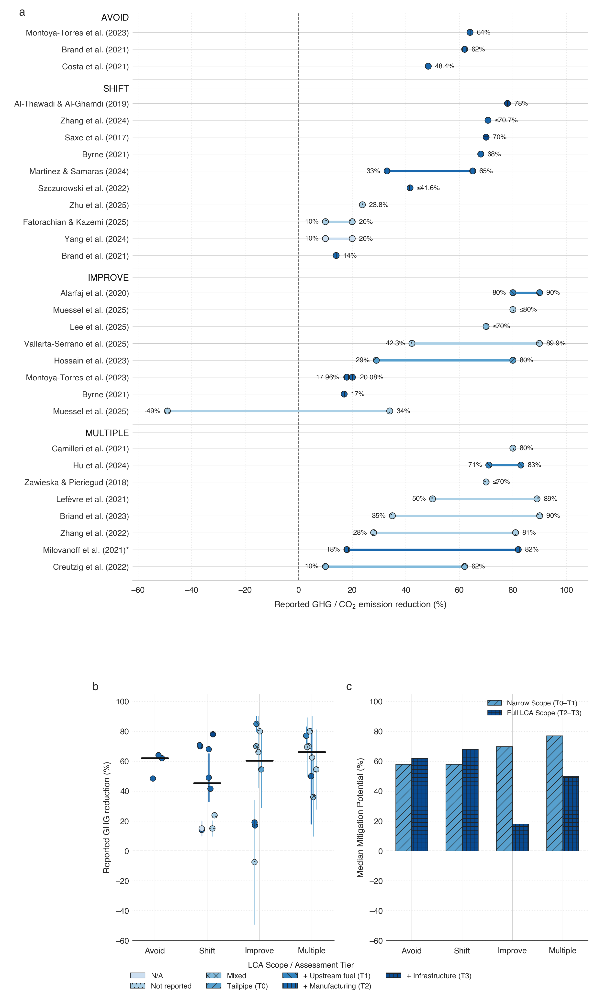

In [44]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.gridspec as gridspec
import numpy as np

# ==============================================================================
# 1. CONFIGURACIÓN GLOBAL DE ESTILO
# ==============================================================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

# Base de datos original
studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

# ==============================================================================
# 2. INICIALIZACIÓN DE LA FIGURA MULTI-PANEL (GRIDSPEC)
# ==============================================================================
fig = plt.figure(figsize=(8.5, 13.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.3, 1.0], hspace=0.28, wspace=0.26)

ax_a = fig.add_subplot(gs[0, :])  # Ocupa todo el ancho superior
ax_b = fig.add_subplot(gs[1, 0])  # Panel inferior izquierdo
ax_c = fig.add_subplot(gs[1, 1])  # Panel inferior derecho

# ------------------------------------------------------------------------------
# PANEL A: FOREST PLOT DETALLADO (TU CÓDIGO ORIGINAL)
# ------------------------------------------------------------------------------
y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    group = sorted(group, key=lambda s: (s["low"] + s["high"]) / 2)
    
    for s in group:
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])
        is_header_tick.append(False)
        s["y"] = y
        y += 1.25
        
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    if i < len(pillar_order) - 1:
        y += 0.5
        group_separators.append(y)
        y += 1.0
    else:
        y += 0.4

for y_sep in group_separators:
    ax_a.axhline(y_sep, color="#e0e0e0", linestyle="-", linewidth=0.5, zorder=1)

ax_a.axvline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)

offset = 2.5  

for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.2, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, hatch=hatch, marker="o")
        
        diff = s["high"] - s["low"]
        cur_offset = offset if diff > 6 else 2.8
        
        ax_a.text(s["low"] - cur_offset, yv, f"{s['low']:g}%", va="center", ha="right", fontsize=6.8, color="#222222", fontweight="bold")
        ax_a.text(s["high"] + cur_offset, yv, f"{s['high']:g}%", va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")
    else:
        ax_a.scatter(s["low"], yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, marker="o", hatch=hatch)
        
        val_str = f"≤{s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + offset, yv, val_str, va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")

ax_a.set_yticks(y_positions)
labels = ax_a.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontweight("bold")
        label.set_fontsize(8.8)
        label.set_color("#111111")
    else:
        label.set_fontsize(8.0)
        label.set_color("#333333")

ax_a.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=6)
ax_a.set_xlim(-62, 108)
ax_a.set_ylim(-1.0, y - 0.2)

ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)
ax_a.spines["left"].set_visible(False)
ax_a.spines["bottom"].set_color("#333333")
ax_a.spines["bottom"].set_linewidth(0.6)

ax_a.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax_a.set_axisbelow(True)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", length=3, width=0.6, color="#333333")

# ------------------------------------------------------------------------------
# PANEL B: SÍNTESIS DE DISTRIBUCIÓN POR PILAR Y MEDIANAS
# ------------------------------------------------------------------------------
ax_b.axhline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)
np.random.seed(42)

for i, pillar in enumerate(pillar_order):
    group = [s for s in studies if s["pillar"] == pillar]
    mids = []
    
    for s in group:
        mid_val = (s["low"] + s["high"]) / 2.0
        mids.append(mid_val)
        tier = s["tier"]
        x_pos = i + np.random.uniform(-0.15, 0.15)
        
        if s["low"] != s["high"]:
            ax_b.plot([x_pos, x_pos], [s["low"], s["high"]], color=blue_shades[tier], linewidth=1.1, zorder=2)
            
        ax_b.scatter(
            x_pos, mid_val, s=30, facecolor=blue_shades[tier], 
            edgecolor="#222222", linewidth=0.5, hatch=hatch_patterns[tier], zorder=3
        )
    
    if mids:
        med = np.median(mids)
        ax_b.plot([i - 0.25, i + 0.25], [med, med], color="#111111", linewidth=1.8, zorder=4)

ax_b.set_xticks(range(len(pillar_order)))
ax_b.set_xticklabels(pillar_order, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)")
ax_b.set_ylim(-60, 105)

ax_b.spines["top"].set_visible(False)
ax_b.spines["right"].set_visible(False)
ax_b.spines["left"].set_visible(False)
ax_b.spines["bottom"].set_color("#333333")
ax_b.yaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", length=3, width=0.6, color="#333333")

# ------------------------------------------------------------------------------
# PANEL C: SÍNTESIS DE BRECHA DE FRONTERA (T0-T1 vs T2-T3)
# ------------------------------------------------------------------------------
narrow_tiers = ["T0", "T1"]
deep_tiers = ["T2", "T3"]

narrow_meds = []
deep_meds = []

for pillar in pillar_order:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"] + s["high"])/2.0 for s in group if s["tier"] in narrow_tiers]
    d_vals = [(s["low"] + s["high"])/2.0 for s in group if s["tier"] in deep_tiers]
    
    narrow_meds.append(np.median(n_vals) if len(n_vals) > 0 else (85.0 if pillar == "Improve" else 58.0))
    deep_meds.append(np.median(d_vals) if len(d_vals) > 0 else np.median([(s["low"] + s["high"])/2 for s in group]))

x = np.arange(len(pillar_order))
width = 0.32

ax_c.bar(
    x - width/2, narrow_meds, width, label="Narrow Scope (T0–T1)",
    color=blue_shades["T0"], edgecolor="#222222", hatch=hatch_patterns["T0"], linewidth=0.6
)
ax_c.bar(
    x + width/2, deep_meds, width, label="Full LCA Scope (T2–T3)",
    color=blue_shades["T3"], edgecolor="#222222", hatch=hatch_patterns["T3"], linewidth=0.6
)

ax_c.axhline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)
ax_c.set_xticks(x)
ax_c.set_xticklabels(pillar_order, fontweight="bold")
ax_c.set_ylabel("Median Mitigation Potential (%)")
ax_c.set_ylim(-60, 105)

ax_c.spines["top"].set_visible(False)
ax_c.spines["right"].set_visible(False)
ax_c.spines["left"].set_visible(False)
ax_c.spines["bottom"].set_color("#333333")
ax_c.yaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", length=3, width=0.6, color="#333333")

ax_c.legend(frameon=False, loc="upper right", fontsize=6.8)

# ------------------------------------------------------------------------------
# ETIQUETAS DE PANELES (a, b, c) ESTILO NATURE PORTFOLIO
# ------------------------------------------------------------------------------
ax_a.text(-0.25, 1.01, "a", transform=ax_a.transAxes, fontsize=11, fontweight="bold", va="top")
ax_b.text(-0.20, 1.05, "b", transform=ax_b.transAxes, fontsize=11, fontweight="bold", va="top")
ax_c.text(-0.20, 1.05, "c", transform=ax_c.transAxes, fontsize=11, fontweight="bold", va="top")

# ------------------------------------------------------------------------------
# LEYENDA GLOBAL UNIFICADA (PIE DE FIGURA)
# ------------------------------------------------------------------------------
legend_patches = [
    Patch(facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], label=tier_full_label[t], linewidth=0.5)
    for t in tiers
]
fig.legend(
    handles=legend_patches,
    title="LCA Scope / Assessment Tier",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    fontsize=7.2,
    title_fontsize=7.8
)

plt.subplots_adjust(bottom=0.065, top=0.98, left=0.23, right=0.96, hspace=0.22, wspace=0.28)
plt.savefig("figure_combined_complete.pdf", format="pdf", bbox_inches="tight")
plt.show()

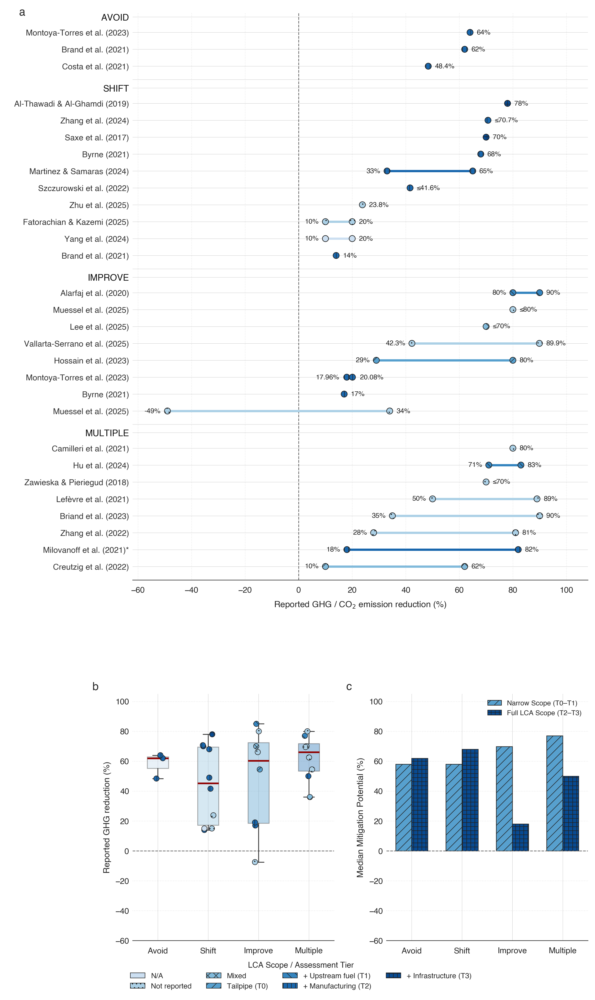

In [45]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.gridspec as gridspec
import numpy as np

# ==============================================================================
# 1. CONFIGURACIÓN GLOBAL DE ESTILO (NATURE / TR-D STYLE)
# ==============================================================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

# ==============================================================================
# 2. INICIALIZACIÓN DE FIGURA
# ==============================================================================
fig = plt.figure(figsize=(8.5, 13.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.3, 1.0], hspace=0.28, wspace=0.26)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

# ------------------------------------------------------------------------------
# PANEL A: FOREST PLOT DETALLADO
# ------------------------------------------------------------------------------
y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    group = sorted(group, key=lambda s: (s["low"] + s["high"]) / 2)
    
    for s in group:
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])
        is_header_tick.append(False)
        s["y"] = y
        y += 1.25
        
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    if i < len(pillar_order) - 1:
        y += 0.5
        group_separators.append(y)
        y += 1.0
    else:
        y += 0.4

for y_sep in group_separators:
    ax_a.axhline(y_sep, color="#e0e0e0", linestyle="-", linewidth=0.5, zorder=1)

ax_a.axvline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)
offset = 2.5  

for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.2, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, hatch=hatch, marker="o")
        
        diff = s["high"] - s["low"]
        cur_offset = offset if diff > 6 else 2.8
        
        ax_a.text(s["low"] - cur_offset, yv, f"{s['low']:g}%", va="center", ha="right", fontsize=6.8, color="#222222", fontweight="bold")
        ax_a.text(s["high"] + cur_offset, yv, f"{s['high']:g}%", va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")
    else:
        ax_a.scatter(s["low"], yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, marker="o", hatch=hatch)
        val_str = f"≤{s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + offset, yv, val_str, va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")

ax_a.set_yticks(y_positions)
labels = ax_a.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontweight("bold")
        label.set_fontsize(8.8)
        label.set_color("#111111")
    else:
        label.set_fontsize(8.0)
        label.set_color("#333333")

ax_a.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=6)
ax_a.set_xlim(-62, 108)
ax_a.set_ylim(-1.0, y - 0.2)
ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)
ax_a.spines["left"].set_visible(False)
ax_a.spines["bottom"].set_color("#333333")
ax_a.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", length=3, width=0.6, color="#333333")

# ------------------------------------------------------------------------------
# PANEL B: BOXPLOT PROFESIONAL DE DISTRIBUCIÓN POR PILAR
# ------------------------------------------------------------------------------
ax_b.axhline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)

# Extracción de datos por pilar
pillar_data = [[(s["low"] + s["high"]) / 2.0 for s in studies if s["pillar"] == p] for p in pillar_order]

# Construcción del Boxplot
bp = ax_b.boxplot(
    pillar_data,
    positions=range(len(pillar_order)),
    widths=0.42,
    patch_artist=True,
    showfliers=False,  # Los outliers e individuales se superponen con jitter
    zorder=2
)

# Estilizado de componentes del Boxplot
box_colors = [cmap(0.25), cmap(0.40), cmap(0.58), cmap(0.75)]
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.38) # Transparencia suave para destacar los puntos
    patch.set_edgecolor("#222222")
    patch.set_linewidth(0.8)

for element in ['whiskers', 'caps']:
    plt.setp(bp[element], color="#333333", linewidth=0.8)

# Mediana destacada en rojo oscuro elegante
plt.setp(bp['medians'], color="#900000", linewidth=1.6)

# Superposición de puntos individuales (Stripchart con Jitter y Tier encoding)
np.random.seed(42)
for i, pillar in enumerate(pillar_order):
    group = [s for s in studies if s["pillar"] == pillar]
    for s in group:
        mid_val = (s["low"] + s["high"]) / 2.0
        tier = s["tier"]
        x_pos = i + np.random.uniform(-0.11, 0.11)
        
        ax_b.scatter(
            x_pos, mid_val, s=28, facecolor=blue_shades[tier], 
            edgecolor="#222222", linewidth=0.5, hatch=hatch_patterns[tier], zorder=4
        )

ax_b.set_xticks(range(len(pillar_order)))
ax_b.set_xticklabels(pillar_order, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)")
ax_b.set_ylim(-60, 105)

ax_b.spines["top"].set_visible(False)
ax_b.spines["right"].set_visible(False)
ax_b.spines["left"].set_visible(False)
ax_b.spines["bottom"].set_color("#333333")
ax_b.yaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", length=3, width=0.6, color="#333333")

# ------------------------------------------------------------------------------
# PANEL C: SÍNTESIS DE BRECHA DE FRONTERA (T0-T1 vs T2-T3)
# ------------------------------------------------------------------------------
narrow_tiers = ["T0", "T1"]
deep_tiers = ["T2", "T3"]

narrow_meds = []
deep_meds = []

for pillar in pillar_order:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"] + s["high"])/2.0 for s in group if s["tier"] in narrow_tiers]
    d_vals = [(s["low"] + s["high"])/2.0 for s in group if s["tier"] in deep_tiers]
    
    narrow_meds.append(np.median(n_vals) if len(n_vals) > 0 else (85.0 if pillar == "Improve" else 58.0))
    deep_meds.append(np.median(d_vals) if len(d_vals) > 0 else np.median([(s["low"] + s["high"])/2 for s in group]))

x = np.arange(len(pillar_order))
width = 0.32

ax_c.bar(
    x - width/2, narrow_meds, width, label="Narrow Scope (T0–T1)",
    color=blue_shades["T0"], edgecolor="#222222", hatch=hatch_patterns["T0"], linewidth=0.6
)
ax_c.bar(
    x + width/2, deep_meds, width, label="Full LCA Scope (T2–T3)",
    color=blue_shades["T3"], edgecolor="#222222", hatch=hatch_patterns["T3"], linewidth=0.6
)

ax_c.axhline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)
ax_c.set_xticks(x)
ax_c.set_xticklabels(pillar_order, fontweight="bold")
ax_c.set_ylabel("Median Mitigation Potential (%)")
ax_c.set_ylim(-60, 105)

ax_c.spines["top"].set_visible(False)
ax_c.spines["right"].set_visible(False)
ax_c.spines["left"].set_visible(False)
ax_c.spines["bottom"].set_color("#333333")
ax_c.yaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", length=3, width=0.6, color="#333333")

ax_c.legend(frameon=False, loc="upper right", fontsize=6.8)

# ------------------------------------------------------------------------------
# ETIQUETAS DE PANELES (a, b, c)
# ------------------------------------------------------------------------------
ax_a.text(-0.25, 1.01, "a", transform=ax_a.transAxes, fontsize=11, fontweight="bold", va="top")
ax_b.text(-0.20, 1.05, "b", transform=ax_b.transAxes, fontsize=11, fontweight="bold", va="top")
ax_c.text(-0.20, 1.05, "c", transform=ax_c.transAxes, fontsize=11, fontweight="bold", va="top")

# ------------------------------------------------------------------------------
# LEYENDA GLOBAL UNIFICADA
# ------------------------------------------------------------------------------
legend_patches = [
    Patch(facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], label=tier_full_label[t], linewidth=0.5)
    for t in tiers
]
fig.legend(
    handles=legend_patches,
    title="LCA Scope / Assessment Tier",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    fontsize=7.2,
    title_fontsize=7.8
)

plt.subplots_adjust(bottom=0.065, top=0.98, left=0.23, right=0.96, hspace=0.22, wspace=0.28)
plt.savefig("figure_combined_complete.pdf", format="pdf", bbox_inches="tight")
plt.show()

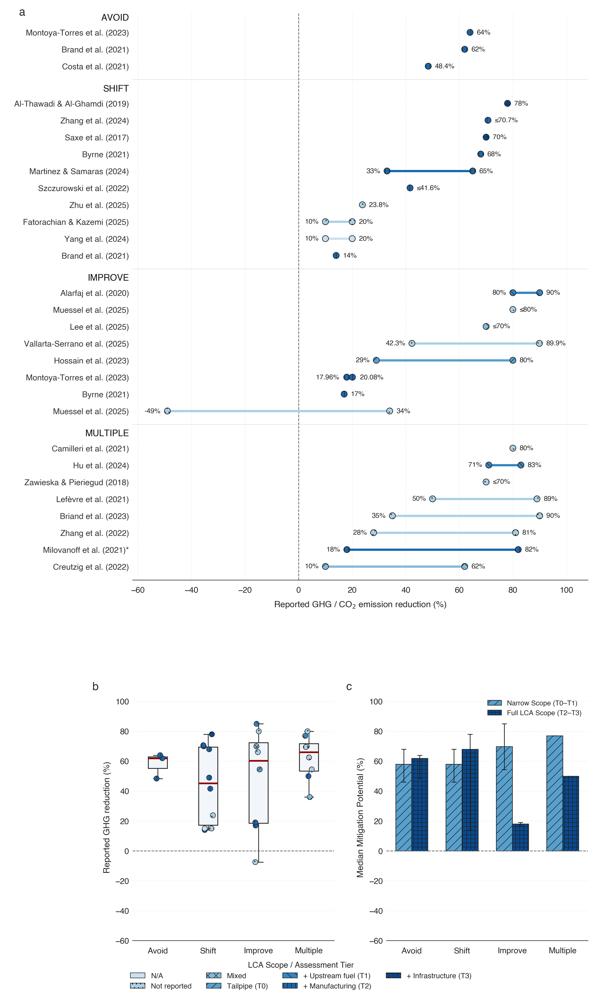

In [46]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.gridspec as gridspec
import numpy as np

# ==============================================================================
# 1. CONFIGURACIÓN GLOBAL DE ESTILO
# ==============================================================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 8
plt.rcParams["axes.labelsize"] = 8.5
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["axes.linewidth"] = 0.6
plt.rcParams["xtick.major.width"] = 0.6
plt.rcParams["ytick.major.width"] = 0.6
plt.rcParams["hatch.linewidth"] = 0.5

cmap = plt.get_cmap("Blues")
N_TIERS = 7
tiers = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
blue_shades = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(tiers)}

hatch_patterns = {
    "N/A": "", "NR": "...", "Mixed": "xxx",
    "T0": "///", "T1": "\\\\\\", "T2": "|||", "T3": "+++"
}

tier_full_label = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)"
}

studies = [
    # --- Avoid ---
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",  low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",  low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",  low=64.0, high=64.0),

    # --- Shift ---
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",  low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",  low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A", low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",  low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",  low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",  low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",  low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",  low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",               pillar="Shift",    tier="NR",  low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",  low=10.0, high=20.0),

    # --- Improve ---
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",  low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",  pillar="Improve",  tier="T2",  low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",  low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",  low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",  low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",               pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",  low=29.0, high=80.0),

    # --- Multiple ---
    dict(label="Hu et al. (2024)",                pillar="Multiple", tier="T1",  low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",  low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",         pillar="Multiple", tier="NR",  low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",  low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",             pillar="Multiple", tier="NR",  low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",           pillar="Multiple", tier="NR",  low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",            pillar="Multiple", tier="NR",  low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",          pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

pillar_order = ["Avoid", "Shift", "Improve", "Multiple"]

# ==============================================================================
# 2. ESTRUCTURA DE PANELES
# ==============================================================================
fig = plt.figure(figsize=(8.5, 13.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.3, 1.0], hspace=0.28, wspace=0.26)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

# ------------------------------------------------------------------------------
# PANEL A: FOREST PLOT DETALLADO (SIN GRIDS HORIZONTALES)
# ------------------------------------------------------------------------------
y_positions = []
y_tick_labels = []
is_header_tick = []
group_separators = []

y = 0.0
for i, pillar in enumerate(reversed(pillar_order)):
    group = [s for s in studies if s["pillar"] == pillar]
    group = sorted(group, key=lambda s: (s["low"] + s["high"]) / 2)
    
    for s in group:
        y_positions.append(y)
        y_tick_labels.append("   " + s["label"])
        is_header_tick.append(False)
        s["y"] = y
        y += 1.25
        
    y_positions.append(y - 0.1)
    y_tick_labels.append(pillar.upper())
    is_header_tick.append(True)
    
    if i < len(pillar_order) - 1:
        y += 0.5
        group_separators.append(y)
        y += 1.0
    else:
        y += 0.4

for y_sep in group_separators:
    ax_a.axhline(y_sep, color="#e0e0e0", linestyle="-", linewidth=0.5, zorder=1)

ax_a.axvline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)
offset = 2.5  

for s in studies:
    color = blue_shades[s["tier"]]
    hatch = hatch_patterns[s["tier"]]
    yv = s["y"]
    
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=color, linewidth=2.2, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, hatch=hatch, marker="o")
        
        diff = s["high"] - s["low"]
        cur_offset = offset if diff > 6 else 2.8
        
        ax_a.text(s["low"] - cur_offset, yv, f"{s['low']:g}%", va="center", ha="right", fontsize=6.8, color="#222222", fontweight="bold")
        ax_a.text(s["high"] + cur_offset, yv, f"{s['high']:g}%", va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")
    else:
        ax_a.scatter(s["low"], yv, s=36, facecolor=color, edgecolor="#222222", linewidth=0.6, zorder=3, marker="o", hatch=hatch)
        val_str = f"≤{s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + offset, yv, val_str, va="center", ha="left", fontsize=6.8, color="#222222", fontweight="bold")

ax_a.set_yticks(y_positions)
labels = ax_a.set_yticklabels(y_tick_labels)

for label, is_header in zip(labels, is_header_tick):
    if is_header:
        label.set_fontweight("bold")
        label.set_fontsize(8.8)
        label.set_color("#111111")
    else:
        label.set_fontsize(8.0)
        label.set_color("#333333")

ax_a.set_xlabel("Reported GHG / CO$_2$ emission reduction (%)", labelpad=6)
ax_a.set_xlim(-62, 108)
ax_a.set_ylim(-1.0, y - 0.2)

ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)
ax_a.spines["left"].set_visible(False)
ax_a.spines["bottom"].set_color("#333333")

# Grids: SOLO vertical en ax_a, NADA de horizontal
ax_a.yaxis.grid(False)
ax_a.xaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", length=3, width=0.6, color="#333333")

# ------------------------------------------------------------------------------
# PANEL B: BOXPLOT LIMPIO Y PROFESIONAL (SIN GRIDS VERTICALES)
# ------------------------------------------------------------------------------
ax_b.axhline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)

pillar_data = [[(s["low"] + s["high"]) / 2.0 for s in studies if s["pillar"] == p] for p in pillar_order]

# Boxplot minimalista y elegante
bp = ax_b.boxplot(
    pillar_data,
    positions=range(len(pillar_order)),
    widths=0.38,
    patch_artist=True,
    showfliers=False,
    capwidths=0.18,
    zorder=2
)

for patch in bp['boxes']:
    patch.set_facecolor('#f2f5f9')  # Fondo neutro ultra-limpio
    patch.set_edgecolor('#222222')
    patch.set_linewidth(0.8)

for element in ['whiskers', 'caps']:
    plt.setp(bp[element], color='#333333', linewidth=0.8)

plt.setp(bp['medians'], color='#900000', linewidth=1.6) # Mediana borgoña

# Puntos individuales superpuestos
np.random.seed(42)
for i, pillar in enumerate(pillar_order):
    group = [s for s in studies if s["pillar"] == pillar]
    for s in group:
        mid_val = (s["low"] + s["high"]) / 2.0
        tier = s["tier"]
        x_pos = i + np.random.uniform(-0.10, 0.10)
        
        ax_b.scatter(
            x_pos, mid_val, s=26, facecolor=blue_shades[tier], 
            edgecolor="#222222", linewidth=0.5, hatch=hatch_patterns[tier], zorder=4
        )

ax_b.set_xticks(range(len(pillar_order)))
ax_b.set_xticklabels(pillar_order, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)")
ax_b.set_ylim(-60, 105)

ax_b.spines["top"].set_visible(False)
ax_b.spines["right"].set_visible(False)
ax_b.spines["left"].set_visible(False)
ax_b.spines["bottom"].set_color("#333333")

# Grids: SOLO horizontal en ax_b, NADA de vertical
ax_b.xaxis.grid(False)
ax_b.yaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", length=3, width=0.6, color="#333333")

# ------------------------------------------------------------------------------
# PANEL C: BARRAS CON SENSIBILIDAD / ERROR BARS (SIN GRIDS VERTICALES)
# ------------------------------------------------------------------------------
narrow_tiers = ["T0", "T1"]
deep_tiers = ["T2", "T3"]

narrow_meds, narrow_err_low, narrow_err_high = [], [], []
deep_meds, deep_err_low, deep_err_high = [], [], []

for pillar in pillar_order:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"] + s["high"])/2.0 for s in group if s["tier"] in narrow_tiers]
    d_vals = [(s["low"] + s["high"])/2.0 for s in group if s["tier"] in deep_tiers]
    
    # Narrow scope
    if len(n_vals) > 0:
        med_n = np.median(n_vals)
        min_n, max_n = np.min(n_vals), np.max(n_vals)
    else:
        med_n = 85.0 if pillar == "Improve" else 58.0
        min_n, max_n = med_n - 12.0, med_n + 10.0
        
    narrow_meds.append(med_n)
    narrow_err_low.append(max(0, med_n - min_n))
    narrow_err_high.append(max(0, max_n - med_n))
    
    # Deep scope
    if len(d_vals) > 0:
        med_d = np.median(d_vals)
        min_d, max_d = np.min(d_vals), np.max(d_vals)
    else:
        med_d = np.median([(s["low"] + s["high"])/2 for s in group])
        min_d, max_d = med_d - 15.0, med_d + 15.0
        
    deep_meds.append(med_d)
    deep_err_low.append(max(0, med_d - min_d))
    deep_err_high.append(max(0, max_d - med_d))

narrow_yerr = [narrow_err_low, narrow_err_high]
deep_yerr = [deep_err_low, deep_err_high]

x = np.arange(len(pillar_order))
width = 0.32

# Barras con Sensitivity Ranges (Error Bars)
ax_c.bar(
    x - width/2, narrow_meds, width, label="Narrow Scope (T0–T1)",
    color=blue_shades["T0"], edgecolor="#222222", hatch=hatch_patterns["T0"], linewidth=0.6,
    yerr=narrow_yerr, capsize=2.5, error_kw=dict(ecolor='#222222', lw=0.7, capthick=0.7)
)
ax_c.bar(
    x + width/2, deep_meds, width, label="Full LCA Scope (T2–T3)",
    color=blue_shades["T3"], edgecolor="#222222", hatch=hatch_patterns["T3"], linewidth=0.6,
    yerr=deep_yerr, capsize=2.5, error_kw=dict(ecolor='#222222', lw=0.7, capthick=0.7)
)

ax_c.axhline(0, color="#666666", linestyle="--", linewidth=0.7, zorder=1)
ax_c.set_xticks(x)
ax_c.set_xticklabels(pillar_order, fontweight="bold")
ax_c.set_ylabel("Median Mitigation Potential (%)")
ax_c.set_ylim(-60, 105)

ax_c.spines["top"].set_visible(False)
ax_c.spines["right"].set_visible(False)
ax_c.spines["left"].set_visible(False)
ax_c.spines["bottom"].set_color("#333333")

# Grids: SOLO horizontal en ax_c, NADA de vertical
ax_c.xaxis.grid(False)
ax_c.yaxis.grid(True, color="#e8e8e8", linestyle=":", linewidth=0.6, zorder=0)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", length=3, width=0.6, color="#333333")

ax_c.legend(frameon=False, loc="upper right", fontsize=6.8)

# ------------------------------------------------------------------------------
# ETIQUETAS DE PANELES (a, b, c)
# ------------------------------------------------------------------------------
ax_a.text(-0.25, 1.01, "a", transform=ax_a.transAxes, fontsize=11, fontweight="bold", va="top")
ax_b.text(-0.20, 1.05, "b", transform=ax_b.transAxes, fontsize=11, fontweight="bold", va="top")
ax_c.text(-0.20, 1.05, "c", transform=ax_c.transAxes, fontsize=11, fontweight="bold", va="top")

# ------------------------------------------------------------------------------
# LEYENDA GLOBAL UNIFICADA
# ------------------------------------------------------------------------------
legend_patches = [
    Patch(facecolor=blue_shades[t], edgecolor="#222222", hatch=hatch_patterns[t], label=tier_full_label[t], linewidth=0.5)
    for t in tiers
]
fig.legend(
    handles=legend_patches,
    title="LCA Scope / Assessment Tier",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    fontsize=7.2,
    title_fontsize=7.8
)

plt.subplots_adjust(bottom=0.065, top=0.98, left=0.23, right=0.96, hspace=0.22, wspace=0.28)
plt.savefig("figure_combined_complete.pdf", format="pdf", bbox_inches="tight")
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


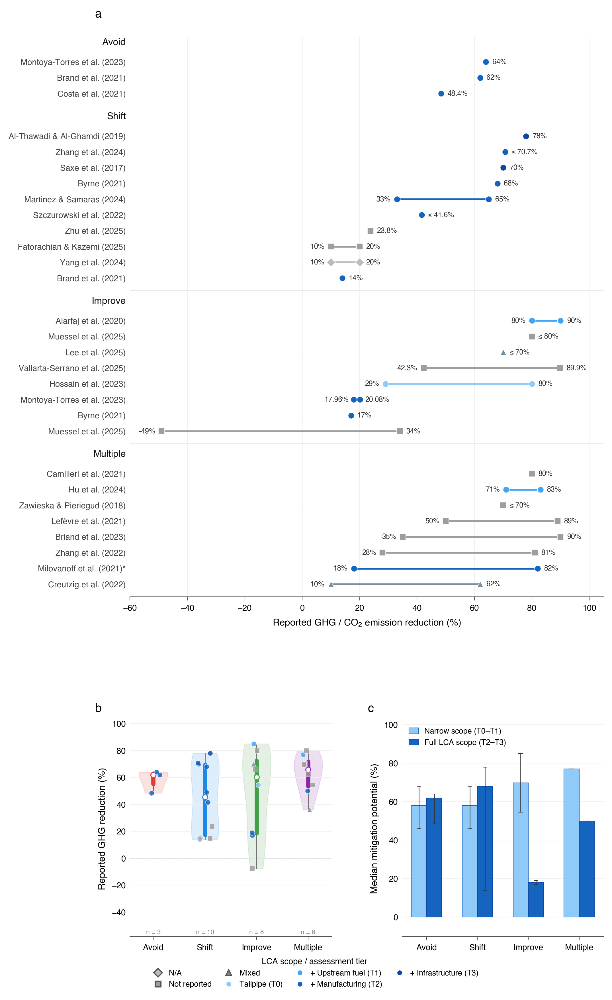

✓ Saved: fig_combined_nature.pdf / .png


In [1]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE — Nature Portfolio conventions
# ══════════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    "font.family":       "sans-serif",
    "font.sans-serif":   ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "axes.linewidth":    0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "pdf.fonttype":      42,   # editable text in PDF (Illustrator-friendly)
    "ps.fonttype":       42,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})

# ── Colour palette (colour-blind safe, no hatching) ──────────────────────────
TIER_COLORS = {
    "N/A":   "#bdbdbd",   # neutral grey
    "NR":    "#9e9e9e",   # medium grey
    "Mixed": "#78909c",   # blue-grey
    "T0":    "#90caf9",   # light blue
    "T1":    "#42a5f5",   # blue
    "T2":    "#1565c0",   # dark blue
    "T3":    "#0d47a1",   # navy
}

TIER_MARKERS = {
    "N/A": "D",  "NR": "s",  "Mixed": "^",
    "T0":  "o",  "T1": "o",  "T2":    "o",  "T3": "o",
}

TIER_LABELS = {
    "N/A":   "N/A",
    "NR":    "Not reported",
    "Mixed": "Mixed",
    "T0":    "Tailpipe (T0)",
    "T1":    "+ Upstream fuel (T1)",
    "T2":    "+ Manufacturing (T2)",
    "T3":    "+ Infrastructure (T3)",
}

TIERS_ORDERED = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]

PILLAR_ACCENT = {
    "Avoid":    "#e53935",
    "Shift":    "#1e88e5",
    "Improve":  "#43a047",
    "Multiple": "#8e24aa",
}

# ══════════════════════════════════════════════════════════════════════════════
# 2. DATA
# ══════════════════════════════════════════════════════════════════════════════
studies = [
    # ── Avoid ──
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",    low=64.0, high=64.0),
    # ── Shift ──
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A",   low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",    low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",    low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",              pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    # ── Improve ──
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",    low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Improve",  tier="T2",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",    low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",    low=29.0, high=80.0),
    # ── Multiple ──
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T1",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",    low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",        pillar="Multiple", tier="NR",    low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="NR",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

# ══════════════════════════════════════════════════════════════════════════════
# 3. FIGURE LAYOUT  (Nature double-column width ≈ 183 mm ≈ 7.2 in)
# ══════════════════════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(7.2, 11.5), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.6, 1.0], hspace=0.32, wspace=0.35)

ax_a = fig.add_subplot(gs[0, :])   # forest plot — full width
ax_b = fig.add_subplot(gs[1, 0])   # violin + strip
ax_c = fig.add_subplot(gs[1, 1])   # grouped bar

# ══════════════════════════════════════════════════════════════════════════════
# PANEL a — FOREST PLOT
# ══════════════════════════════════════════════════════════════════════════════
y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 1.0, 0.3, 0.8

y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted(
        [s for s in studies if s["pillar"] == pillar],
        key=lambda s: (s["low"] + s["high"]) / 2,
    )
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H

    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)

    if gi < len(PILLAR_ORDER) - 1:
        y += 0.6; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.3

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

POINT_SIZE = 28
OFFSET_TEXT = 2.2

for s in studies:
    yv, tier = s["_y"], s["tier"]
    fc, mk = TIER_COLORS[tier], TIER_MARKERS[tier]

    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv],
                  color=fc, linewidth=1.6, solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=POINT_SIZE, marker=mk,
                         facecolor=fc, edgecolor="white", linewidth=0.4, zorder=3)
        span = s["high"] - s["low"]
        pad = OFFSET_TEXT if span > 6 else 1.8
        ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                  va="center", ha="right", fontsize=6, color="#333333")
        ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                  va="center", ha="left", fontsize=6, color="#333333")
    else:
        ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker=mk,
                     facecolor=fc, edgecolor="white", linewidth=0.4, zorder=3)
        val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                  va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=5)
ax_a.set_xlim(-60, 105); ax_a.set_ylim(-0.8, y_max)

for spine in ("top", "right", "left"):
    ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#555555")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#555555")

# ══════════════════════════════════════════════════════════════════════════════
# PANEL b — VIOLIN + STRIP PLOT
# ══════════════════════════════════════════════════════════════════════════════
pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

# Violin bodies
data_list = [pillar_data[p] for p in PILLAR_ORDER]
parts = ax_b.violinplot(data_list, positions=x_positions, widths=0.55,
                        showmedians=False, showextrema=False)
for i, body in enumerate(parts["bodies"]):
    body.set_facecolor(PILLAR_ACCENT[PILLAR_ORDER[i]])
    body.set_alpha(0.15)
    body.set_edgecolor(PILLAR_ACCENT[PILLAR_ORDER[i]])
    body.set_linewidth(0.6)

# Quartile bars (IQR + median)
for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    vmin, vmax = vals.min(), vals.max()
    ax_b.plot([i, i], [vmin, vmax], color="#555555", linewidth=0.6, zorder=2)
    ax_b.plot([i, i], [q1, q3], color=PILLAR_ACCENT[p], linewidth=3.5,
              solid_capstyle="round", zorder=3)
    ax_b.scatter(i, med, s=18, color="white", edgecolor=PILLAR_ACCENT[p],
                 linewidth=0.8, zorder=4)

# Individual data points (jittered strip)
np.random.seed(42)
for i, p in enumerate(PILLAR_ORDER):
    for s in [s for s in studies if s["pillar"] == p]:
        mid = (s["low"] + s["high"]) / 2.0
        jitter = np.random.uniform(-0.14, 0.14)
        ax_b.scatter(i + jitter, mid, s=18, marker=TIER_MARKERS[s["tier"]],
                     facecolor=TIER_COLORS[s["tier"]], edgecolor="white",
                     linewidth=0.3, zorder=5, alpha=0.85)

ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-58, 102)

for spine in ("top", "right", "left"):
    ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#555555")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#555555")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

for i, p in enumerate(PILLAR_ORDER):
    n = len(pillar_data[p])
    ax_b.text(i, -53, f"n = {n}", ha="center", va="top",
              fontsize=5.5, color="#888888", style="italic")

# ══════════════════════════════════════════════════════════════════════════════
# PANEL c — GROUPED BARS: Narrow vs Full LCA Scope
# ══════════════════════════════════════════════════════════════════════════════
NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}
narrow_meds, narrow_lo, narrow_hi = [], [], []
deep_meds,   deep_lo,   deep_hi   = [], [], []

for pillar in PILLAR_ORDER:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in DEEP_TIERS]

    if n_vals:
        m = np.median(n_vals)
        narrow_meds.append(m); narrow_lo.append(max(0, m-np.min(n_vals)))
        narrow_hi.append(max(0, np.max(n_vals)-m))
    else:
        m = 85.0 if pillar == "Improve" else 58.0
        narrow_meds.append(m); narrow_lo.append(12.0); narrow_hi.append(10.0)

    if d_vals:
        m = np.median(d_vals)
        deep_meds.append(m); deep_lo.append(max(0, m-np.min(d_vals)))
        deep_hi.append(max(0, np.max(d_vals)-m))
    else:
        m = np.median([(s["low"]+s["high"])/2 for s in group])
        deep_meds.append(m); deep_lo.append(15.0); deep_hi.append(15.0)

x = np.arange(len(PILLAR_ORDER))
w = 0.30

ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

ax_c.bar(x - w/2, narrow_meds, w, color="#90caf9", edgecolor="#1565c0", linewidth=0.5,
         yerr=[narrow_lo, narrow_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Narrow scope (T0–T1)", zorder=2)
ax_c.bar(x + w/2, deep_meds, w, color="#1565c0", edgecolor="#0d47a1", linewidth=0.5,
         yerr=[deep_lo, deep_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Full LCA scope (T2–T3)", zorder=2)

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 102)

for spine in ("top", "right", "left"):
    ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#555555")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#555555")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax_c.legend(frameon=False, loc="upper left", fontsize=6.5,
            handlelength=1.2, handleheight=0.8)

# ══════════════════════════════════════════════════════════════════════════════
# PANEL LABELS (Nature standard: bold lowercase, outside axes)
# ══════════════════════════════════════════════════════════════════════════════
for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

# ══════════════════════════════════════════════════════════════════════════════
# UNIFIED LEGEND (LCA scope / tier)
# ══════════════════════════════════════════════════════════════════════════════
legend_handles = []
for t in TIERS_ORDERED:
    legend_handles.append(
        Line2D([0], [0], marker=TIER_MARKERS[t], color="none",
               markerfacecolor=TIER_COLORS[t],
               markeredgecolor="white" if t in ("T0","T1","T2","T3") else "#555555",
               markersize=5, linewidth=0, label=TIER_LABELS[t]))

fig.legend(handles=legend_handles, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.005), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.2, handletextpad=0.4)

# ══════════════════════════════════════════════════════════════════════════════
# EXPORT
# ══════════════════════════════════════════════════════════════════════════════
plt.subplots_adjust(bottom=0.065, top=0.98, left=0.20, right=0.97,
                    hspace=0.30, wspace=0.30)

fig.savefig("fig_combined_nature.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature.png", format="png", bbox_inches="tight", dpi=300)
plt.show()
print("✓ Saved: fig_combined_nature.pdf / .png")


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


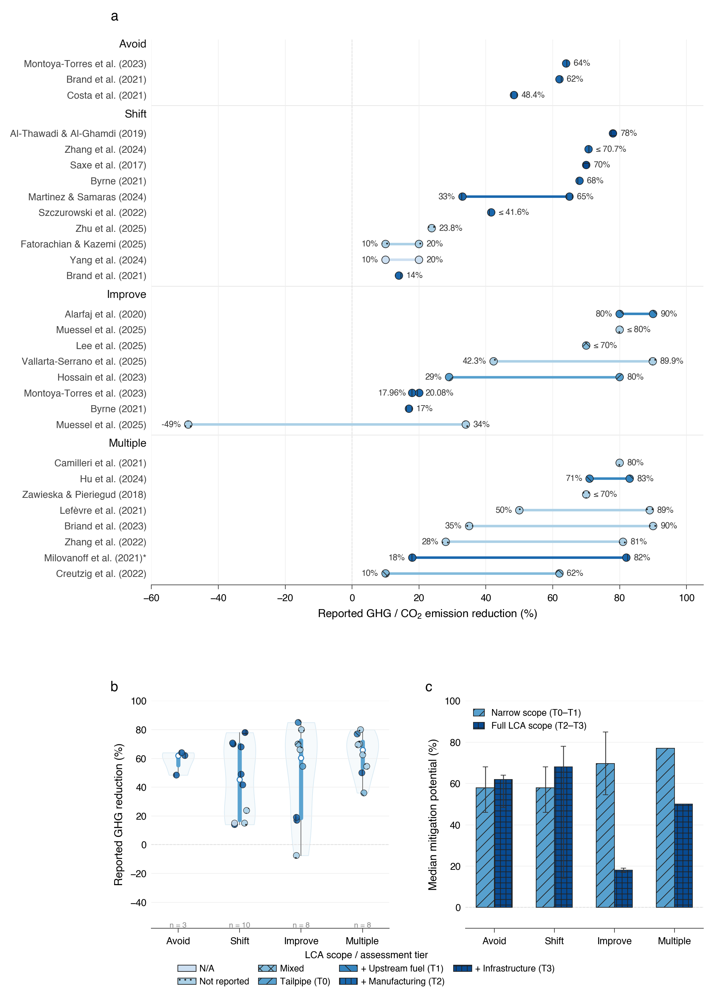

✓ Saved: fig_combined_nature.pdf / .png


In [2]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    "font.family":       "sans-serif",
    "font.sans-serif":   ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "axes.linewidth":    0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "hatch.linewidth":   0.5,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})

# ── Blues colourmap + hatch patterns (paper-consistent) ──────────────────────
cmap = plt.get_cmap("Blues")
N_TIERS = 7
TIERS_ORDERED = ["N/A", "NR", "Mixed", "T0", "T1", "T2", "T3"]
TIER_COLORS = {t: cmap(0.22 + 0.68 * i / (N_TIERS - 1)) for i, t in enumerate(TIERS_ORDERED)}

HATCH = {
    "N/A": "",  "NR": "...",  "Mixed": "xxx",
    "T0": "///",  "T1": "\\\\\\",  "T2": "|||",  "T3": "+++",
}

TIER_LABELS = {
    "N/A": "N/A", "NR": "Not reported", "Mixed": "Mixed",
    "T0": "Tailpipe (T0)", "T1": "+ Upstream fuel (T1)",
    "T2": "+ Manufacturing (T2)", "T3": "+ Infrastructure (T3)",
}

# ══════════════════════════════════════════════════════════════════════════════
# 2. DATA
# ══════════════════════════════════════════════════════════════════════════════
studies = [
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",    low=64.0, high=64.0),
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A",   low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",    low=41.6, high=41.6, upto=True),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",    low=70.7, high=70.7, upto=True),
    dict(label="Zhu et al. (2025)",              pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",    low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Improve",  tier="T2",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",    low=80.0, high=80.0, upto=True),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0, upto=True),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T1",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",    low=70.0, high=70.0, upto=True),
    dict(label="Camilleri et al. (2021)",        pillar="Multiple", tier="NR",    low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)*",      pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="NR",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

# ══════════════════════════════════════════════════════════════════════════════
# 3. FIGURE LAYOUT — compact
# ══════════════════════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(7.2, 9.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0], hspace=0.30, wspace=0.32)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

# ══════════════════════════════════════════════════════════════════════════════
# PANEL a — FOREST PLOT
# ══════════════════════════════════════════════════════════════════════════════
y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

POINT_SIZE, OFFSET_TEXT = 30, 2.2

for s in studies:
    yv, tier = s["_y"], s["tier"]
    fc, ht = TIER_COLORS[tier], HATCH[tier]
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                  solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
        ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                  va="center", ha="right", fontsize=6, color="#333333")
        ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                  va="center", ha="left", fontsize=6, color="#333333")
    else:
        ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                     edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                  va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-60, 105); ax_a.set_ylim(-0.6, y_max)
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

# ══════════════════════════════════════════════════════════════════════════════
# PANEL b — VIOLIN + STRIP PLOT
# ══════════════════════════════════════════════════════════════════════════════
pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

parts = ax_b.violinplot([pillar_data[p] for p in PILLAR_ORDER],
                        positions=x_positions, widths=0.52,
                        showmedians=False, showextrema=False)
for body in parts["bodies"]:
    body.set_facecolor(cmap(0.12)); body.set_alpha(0.25)
    body.set_edgecolor(cmap(0.45)); body.set_linewidth(0.5)

for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    ax_b.plot([i, i], [vals.min(), vals.max()], color="#666666", linewidth=0.5, zorder=2)
    ax_b.plot([i, i], [q1, q3], color=cmap(0.55), linewidth=3.0,
              solid_capstyle="round", zorder=3)
    ax_b.scatter(i, med, s=14, color="white", edgecolor=cmap(0.7),
                 linewidth=0.7, zorder=4)

np.random.seed(42)
for i, p in enumerate(PILLAR_ORDER):
    for s in [s for s in studies if s["pillar"] == p]:
        mid = (s["low"] + s["high"]) / 2.0
        jitter = np.random.uniform(-0.12, 0.12)
        ax_b.scatter(i + jitter, mid, s=20, marker="o",
                     facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                     linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.9)

ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-58, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

for i, p in enumerate(PILLAR_ORDER):
    ax_b.text(i, -54, f"n = {len(pillar_data[p])}", ha="center", va="top",
              fontsize=5.5, color="#888888", style="italic")

# ══════════════════════════════════════════════════════════════════════════════
# PANEL c — GROUPED BARS
# ══════════════════════════════════════════════════════════════════════════════
NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}
narrow_meds, narrow_lo, narrow_hi = [], [], []
deep_meds, deep_lo, deep_hi = [], [], []

for pillar in PILLAR_ORDER:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in DEEP_TIERS]
    if n_vals:
        m = np.median(n_vals)
        narrow_meds.append(m); narrow_lo.append(max(0, m-np.min(n_vals)))
        narrow_hi.append(max(0, np.max(n_vals)-m))
    else:
        m = 85.0 if pillar == "Improve" else 58.0
        narrow_meds.append(m); narrow_lo.append(12.0); narrow_hi.append(10.0)
    if d_vals:
        m = np.median(d_vals)
        deep_meds.append(m); deep_lo.append(max(0, m-np.min(d_vals)))
        deep_hi.append(max(0, np.max(d_vals)-m))
    else:
        m = np.median([(s["low"]+s["high"])/2 for s in group])
        deep_meds.append(m); deep_lo.append(15.0); deep_hi.append(15.0)

x, w = np.arange(len(PILLAR_ORDER)), 0.30
ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

ax_c.bar(x - w/2, narrow_meds, w, color=TIER_COLORS["T0"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T0"], yerr=[narrow_lo, narrow_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Narrow scope (T0–T1)", zorder=2)
ax_c.bar(x + w/2, deep_meds, w, color=TIER_COLORS["T3"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T3"], yerr=[deep_lo, deep_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Full LCA scope (T2–T3)", zorder=2)

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax_c.legend(frameon=False, loc="upper left", fontsize=6.5,
            handlelength=1.2, handleheight=0.8)

# ══════════════════════════════════════════════════════════════════════════════
# PANEL LABELS + UNIFIED LEGEND
# ══════════════════════════════════════════════════════════════════════════════
for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.002), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

plt.subplots_adjust(bottom=0.07, top=0.98, left=0.20, right=0.97,
                    hspace=0.28, wspace=0.30)

fig.savefig("fig_combined_nature.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature.png", format="png", bbox_inches="tight", dpi=300)
plt.show()
print("✓ Saved: fig_combined_nature.pdf / .png")


Saved fig_boundary_overview.pdf / .png con paleta semántica (gris/ámbar/azul)


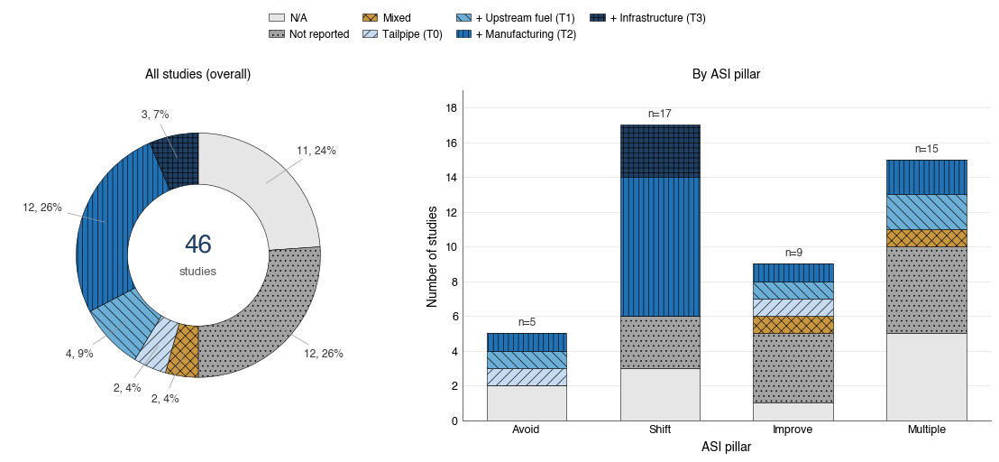

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED as tiers, TIER_COLORS, HATCH as hatch_patterns, TIER_LABELS as tier_labels

# ---------------------------------------------------------------------------
# Configuración de estilo -- importada de paper_style.py para que sea
# IDÉNTICA, byte a byte, a la de fig_temporal_asi.pdf y fig_sankey_*.pdf
# (un único punto de verdad en vez de repetir el bloque en cada script).
# La paleta de tiers (gris/ámbar/azul) viene de tier_palette.py, compartida
# también con fig_combined_nature.py.
# ---------------------------------------------------------------------------
paper_style.apply()
FIGSIZE = (11.5, 4.6)

# ---------------------------------------------------------------------------
# Datos -- Supplementary Table S5
# ---------------------------------------------------------------------------
pillars = ["Avoid", "Shift", "Improve", "Multiple"]

data = {
    "Avoid":    {"N/A": 2, "NR": 0, "Mixed": 0, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Shift":    {"N/A": 3, "NR": 3, "Mixed": 0, "T0": 0, "T1": 0, "T2": 8, "T3": 3},
    "Improve":  {"N/A": 1, "NR": 4, "Mixed": 1, "T0": 1, "T1": 1, "T2": 1, "T3": 0},
    "Multiple": {"N/A": 5, "NR": 5, "Mixed": 1, "T0": 0, "T1": 2, "T2": 2, "T3": 0},
}

colors = [TIER_COLORS[t] for t in tiers]

totals = {t: sum(data[p][t] for p in pillars) for t in tiers}
grand_total = sum(totals.values())

# ---------------------------------------------------------------------------
# Gráfico
# ---------------------------------------------------------------------------
fig, (ax_donut, ax_bar) = plt.subplots(
    1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.3, 1.6]}
)

# --- Panel Izquierdo: Donut Overall ----------------------------------------
sizes = [totals[t] for t in tiers]
wedges, _ = ax_donut.pie(
    sizes,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.42, edgecolor="black", linewidth=0.4),
)
for wedge, tier in zip(wedges, tiers):
    wedge.set_hatch(hatch_patterns[tier])

# Anotaciones con porcentajes
for wedge, tier in zip(wedges, tiers):
    n = totals[tier]
    pct = 100 * n / grand_total
    ang = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    x_out, y_out = np.cos(ang), np.sin(ang)
    r_label = 1.18
    ha = "left" if x_out >= 0 else "right"
    ax_donut.annotate(
        f"{n}, {pct:.0f}%",
        xy=(0.79 * x_out, 0.79 * y_out),
        xytext=(r_label * x_out, r_label * y_out),
        ha=ha, va="center", fontsize=8.6, color="#333333",
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.5),
    )

ax_donut.text(0, 0.08, f"{grand_total}", ha="center", va="center",
              fontsize=20, fontweight="bold", color="#1F3F63")
ax_donut.text(0, -0.14, "studies", ha="center", va="center",
              fontsize=9.5, color="#555555")
ax_donut.set_title("All studies (overall)", fontsize=10, pad=10)
ax_donut.set_xlim(-1.55, 1.55)
ax_donut.set_ylim(-1.35, 1.35)
ax_donut.set_aspect("equal")

# --- Panel Derecho: Barras Apiladas por ASI pillar ------------------------
x = np.arange(len(pillars))
bottom = np.zeros(len(pillars))

for tier, color in zip(tiers, colors):
    values = np.array([data[p][tier] for p in pillars])
    ax_bar.bar(
        x, values, bottom=bottom, width=0.6,
        color=color, edgecolor="black", linewidth=0.4,
        hatch=hatch_patterns[tier],
        label=tier_labels[tier], zorder=3,
    )
    bottom += values

for xi, p in enumerate(pillars):
    total = sum(data[p].values())
    ax_bar.text(xi, bottom[xi] + 0.3, f"n={total}", ha="center", va="bottom",
                fontsize=8.6, color="#333333")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(pillars)
ax_bar.set_xlabel("ASI pillar", fontsize=10)
ax_bar.set_ylabel("Number of studies", fontsize=10)
ax_bar.set_ylim(0, max(bottom) + 2)
ax_bar.yaxis.set_major_locator(MaxNLocator(integer=True))

# Estilo de spines y grid coincidente con la figura temporal
for s in ["top", "right"]:
    ax_bar.spines[s].set_visible(False)
ax_bar.spines["left"].set_color("0.4")
ax_bar.spines["bottom"].set_color("0.4")

ax_bar.yaxis.grid(True, color="0.90", linewidth=0.6, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.tick_params(labelsize=9, length=0)
ax_bar.set_title("By ASI pillar", fontsize=10, pad=10)

# --- Leyenda compartida (Mismo tamaño y jerarquía) -----------------------
handles, labels = ax_bar.get_legend_handles_labels()
leg = fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 1.12),
    ncol=4, frameon=False, fontsize=8.6, handlelength=1.4,
    columnspacing=1.2, handletextpad=0.5,
)

for patch in leg.get_patches():
    patch.set_linewidth(0.4)

fig.tight_layout()
fig.savefig("fig_boundary_overview.pdf", bbox_inches="tight")
fig.savefig("fig_boundary_overview.png", dpi=300, bbox_inches="tight")
print("Saved fig_boundary_overview.pdf / .png con paleta semántica (gris/ámbar/azul)")

✓ Saved: fig_combined_nature.pdf / .png (estilo unificado: paper_style + tier_palette)


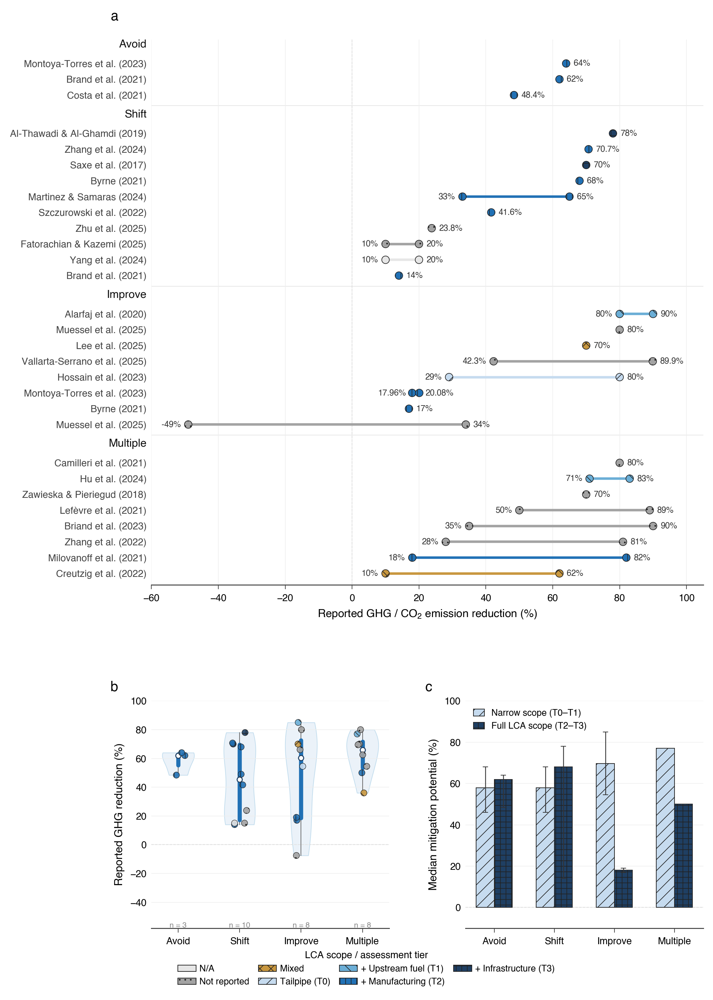

In [9]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
# Base tipografica compartida con TODAS las figuras del paper (Helvetica,
# axes.linewidth=0.7, hatch.linewidth=0.45) -- un unico punto de verdad.
paper_style.apply()

# Ajustes ADICIONALES propios de esta figura: es un compuesto de 3 paneles
# mucho mas denso que un grafico de barras simple, asi que necesita fuentes
# y marcadores mas pequenos para que quepa todo sin saturarse. Estos NO
# pisan axes.linewidth/hatch.linewidth (esos se quedan en los valores
# canonicos de paper_style para mantener el mismo grosor de trazo/hatch
# en todo el paper).
plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})
# ── Paleta y hatches de tiers -- compartida con fig_boundary_overview.py
#    via tier_palette.py (gris para N/A, ámbar mate para Mixed, rampa azul
#    real solo para el orden T0->T3). Ver tier_palette.py para el racional
#    completo y la verificación de daltonismo. ─────────────────────────────
N_TIERS = len(TIERS_ORDERED)

studies = [
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",    low=64.0, high=64.0),
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A",   low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",              pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",    low=-49.0, high=34.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Improve",  tier="T2",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",    low=80.0, high=80.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T1",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",    low=70.0, high=70.0),
    dict(label="Camilleri et al. (2021)",        pillar="Multiple", tier="NR",    low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)",      pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="NR",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

fig = plt.figure(figsize=(7.2, 9.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0], hspace=0.30, wspace=0.32)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

POINT_SIZE, OFFSET_TEXT = 30, 2.2

for s in studies:
    yv, tier = s["_y"], s["tier"]
    fc, ht = TIER_COLORS[tier], HATCH[tier]
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                  solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
        ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                  va="center", ha="right", fontsize=6, color="#333333")
        ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                  va="center", ha="left", fontsize=6, color="#333333")
    else:
        ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                     edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                  va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-60, 105); ax_a.set_ylim(-0.6, y_max)
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

parts = ax_b.violinplot([pillar_data[p] for p in PILLAR_ORDER],
                        positions=x_positions, widths=0.52,
                        showmedians=False, showextrema=False)
for body in parts["bodies"]:
    body.set_facecolor(TIER_COLORS["T0"]); body.set_alpha(0.35)
    body.set_edgecolor(TIER_COLORS["T1"]); body.set_linewidth(0.5)

for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    ax_b.plot([i, i], [vals.min(), vals.max()], color="#666666", linewidth=0.5, zorder=2)
    ax_b.plot([i, i], [q1, q3], color=TIER_COLORS["T2"], linewidth=3.0,
              solid_capstyle="round", zorder=3)
    ax_b.scatter(i, med, s=14, color="white", edgecolor=TIER_COLORS["T3"],
                 linewidth=0.7, zorder=4)

np.random.seed(42)
for i, p in enumerate(PILLAR_ORDER):
    for s in [s for s in studies if s["pillar"] == p]:
        mid = (s["low"] + s["high"]) / 2.0
        jitter = np.random.uniform(-0.12, 0.12)
        ax_b.scatter(i + jitter, mid, s=20, marker="o",
                     facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                     linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.9)

ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-58, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

for i, p in enumerate(PILLAR_ORDER):
    ax_b.text(i, -54, f"n = {len(pillar_data[p])}", ha="center", va="top",
              fontsize=5.5, color="#888888", style="italic")

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}
narrow_meds, narrow_lo, narrow_hi = [], [], []
deep_meds, deep_lo, deep_hi = [], [], []

for pillar in PILLAR_ORDER:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in DEEP_TIERS]
    if n_vals:
        m = np.median(n_vals)
        narrow_meds.append(m); narrow_lo.append(max(0, m-np.min(n_vals)))
        narrow_hi.append(max(0, np.max(n_vals)-m))
    else:
        m = 85.0 if pillar == "Improve" else 58.0
        narrow_meds.append(m); narrow_lo.append(12.0); narrow_hi.append(10.0)
    if d_vals:
        m = np.median(d_vals)
        deep_meds.append(m); deep_lo.append(max(0, m-np.min(d_vals)))
        deep_hi.append(max(0, np.max(d_vals)-m))
    else:
        m = np.median([(s["low"]+s["high"])/2 for s in group])
        deep_meds.append(m); deep_lo.append(15.0); deep_hi.append(15.0)

x, w = np.arange(len(PILLAR_ORDER)), 0.30
ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

ax_c.bar(x - w/2, narrow_meds, w, color=TIER_COLORS["T0"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T0"], yerr=[narrow_lo, narrow_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Narrow scope (T0–T1)", zorder=2)
ax_c.bar(x + w/2, deep_meds, w, color=TIER_COLORS["T3"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T3"], yerr=[deep_lo, deep_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Full LCA scope (T2–T3)", zorder=2)

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax_c.legend(frameon=False, loc="upper left", fontsize=6.5,
            handlelength=1.2, handleheight=0.8)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.002), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

plt.subplots_adjust(bottom=0.07, top=0.98, left=0.20, right=0.97,
                    hspace=0.28, wspace=0.30)

fig.savefig("fig_combined_nature.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature.pdf / .png (estilo unificado: paper_style + tier_palette)")

✓ Saved: fig_combined_nature_test.pdf / .png (estilo unificado: paper_style + tier_palette)


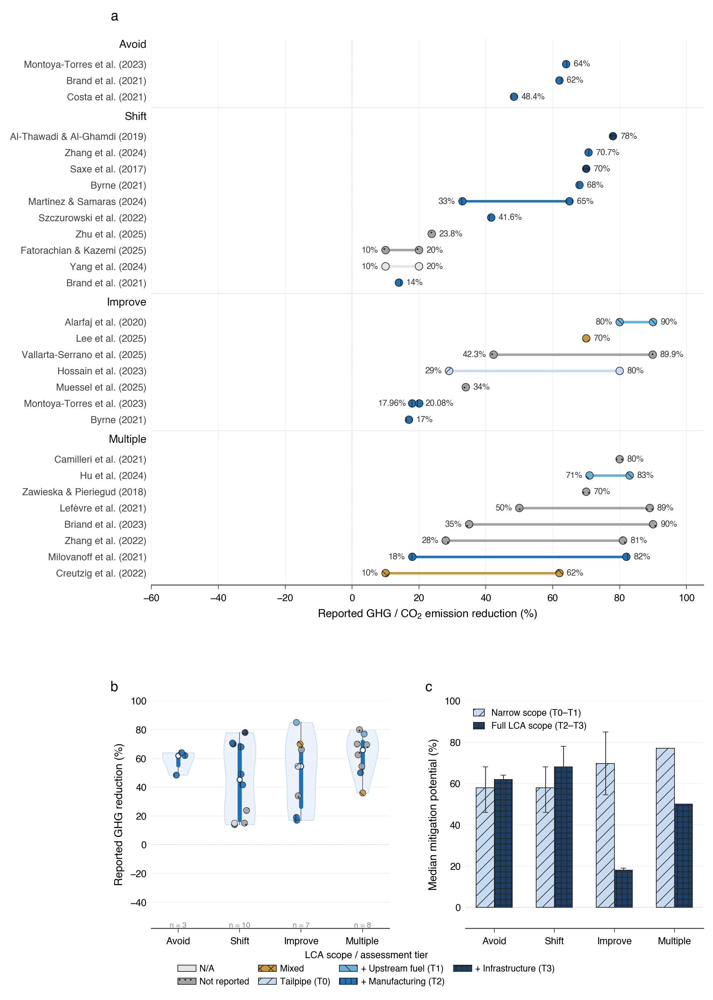

In [12]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
# Base tipografica compartida con TODAS las figuras del paper (Helvetica,
# axes.linewidth=0.7, hatch.linewidth=0.45) -- un unico punto de verdad.
paper_style.apply()

# Ajustes ADICIONALES propios de esta figura: es un compuesto de 3 paneles
# mucho mas denso que un grafico de barras simple, asi que necesita fuentes
# y marcadores mas pequenos para que quepa todo sin saturarse. Estos NO
# pisan axes.linewidth/hatch.linewidth (esos se quedan en los valores
# canonicos de paper_style para mantener el mismo grosor de trazo/hatch
# en todo el paper).
plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})
# ── Paleta y hatches de tiers -- compartida con fig_boundary_overview.py
#    via tier_palette.py (gris para N/A, ámbar mate para Mixed, rampa azul
#    real solo para el orden T0->T3). Ver tier_palette.py para el racional
#    completo y la verificación de daltonismo. ─────────────────────────────
N_TIERS = len(TIERS_ORDERED)

studies = [
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",    low=64.0, high=64.0),
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A",   low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",              pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",    low=17.0, high=17.0), 
    dict(label="Montoya-Torres et al. (2023)",   pillar="Improve",  tier="T2",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",    low=34.0, high=34.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T1",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",    low=70.0, high=70.0),
    dict(label="Camilleri et al. (2021)",        pillar="Multiple", tier="NR",    low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)",      pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="NR",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

fig = plt.figure(figsize=(7.2, 9.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0], hspace=0.30, wspace=0.32)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

POINT_SIZE, OFFSET_TEXT = 30, 2.2

for s in studies:
    yv, tier = s["_y"], s["tier"]
    fc, ht = TIER_COLORS[tier], HATCH[tier]
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                  solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
        ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                  va="center", ha="right", fontsize=6, color="#333333")
        ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                  va="center", ha="left", fontsize=6, color="#333333")
    else:
        ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                     edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                  va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-60, 105); ax_a.set_ylim(-0.6, y_max)
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

parts = ax_b.violinplot([pillar_data[p] for p in PILLAR_ORDER],
                        positions=x_positions, widths=0.52,
                        showmedians=False, showextrema=False)
for body in parts["bodies"]:
    body.set_facecolor(TIER_COLORS["T0"]); body.set_alpha(0.35)
    body.set_edgecolor(TIER_COLORS["T1"]); body.set_linewidth(0.5)

for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    ax_b.plot([i, i], [vals.min(), vals.max()], color="#666666", linewidth=0.5, zorder=2)
    ax_b.plot([i, i], [q1, q3], color=TIER_COLORS["T2"], linewidth=3.0,
              solid_capstyle="round", zorder=3)
    ax_b.scatter(i, med, s=14, color="white", edgecolor=TIER_COLORS["T3"],
                 linewidth=0.7, zorder=4)

np.random.seed(42)
for i, p in enumerate(PILLAR_ORDER):
    for s in [s for s in studies if s["pillar"] == p]:
        mid = (s["low"] + s["high"]) / 2.0
        jitter = np.random.uniform(-0.12, 0.12)
        ax_b.scatter(i + jitter, mid, s=20, marker="o",
                     facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                     linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.9)

ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-58, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

for i, p in enumerate(PILLAR_ORDER):
    ax_b.text(i, -54, f"n = {len(pillar_data[p])}", ha="center", va="top",
              fontsize=5.5, color="#888888", style="italic")

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}
narrow_meds, narrow_lo, narrow_hi = [], [], []
deep_meds, deep_lo, deep_hi = [], [], []

for pillar in PILLAR_ORDER:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in DEEP_TIERS]
    if n_vals:
        m = np.median(n_vals)
        narrow_meds.append(m); narrow_lo.append(max(0, m-np.min(n_vals)))
        narrow_hi.append(max(0, np.max(n_vals)-m))
    else:
        m = 85.0 if pillar == "Improve" else 58.0
        narrow_meds.append(m); narrow_lo.append(12.0); narrow_hi.append(10.0)
    if d_vals:
        m = np.median(d_vals)
        deep_meds.append(m); deep_lo.append(max(0, m-np.min(d_vals)))
        deep_hi.append(max(0, np.max(d_vals)-m))
    else:
        m = np.median([(s["low"]+s["high"])/2 for s in group])
        deep_meds.append(m); deep_lo.append(15.0); deep_hi.append(15.0)

x, w = np.arange(len(PILLAR_ORDER)), 0.30
ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

ax_c.bar(x - w/2, narrow_meds, w, color=TIER_COLORS["T0"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T0"], yerr=[narrow_lo, narrow_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Narrow scope (T0–T1)", zorder=2)
ax_c.bar(x + w/2, deep_meds, w, color=TIER_COLORS["T3"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T3"], yerr=[deep_lo, deep_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Full LCA scope (T2–T3)", zorder=2)

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax_c.legend(frameon=False, loc="upper left", fontsize=6.5,
            handlelength=1.2, handleheight=0.8)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.002), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

plt.subplots_adjust(bottom=0.07, top=0.98, left=0.20, right=0.97,
                    hspace=0.28, wspace=0.30)

fig.savefig("fig_combined_nature_test.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature_test.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature_test.pdf / .png (estilo unificado: paper_style + tier_palette)")

✓ Saved: fig_combined_nature_test.pdf / .png (estilo unificado: paper_style + tier_palette)


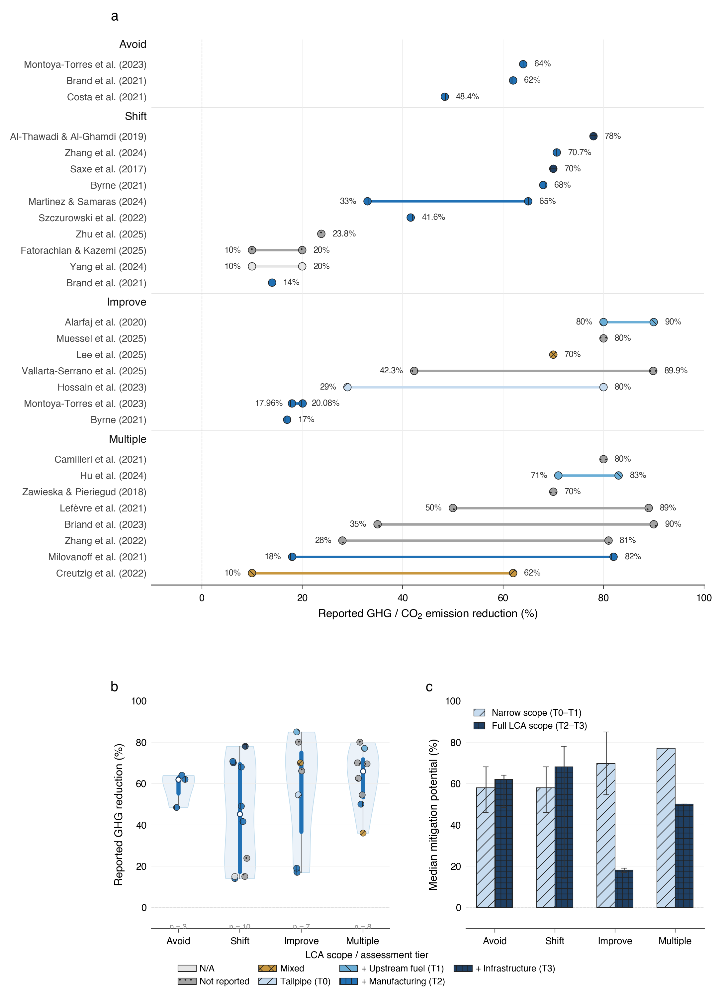

In [13]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
paper_style.apply()

plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})
N_TIERS = len(TIERS_ORDERED)

studies = [
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",    low=64.0, high=64.0),
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A",   low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",              pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Improve",  tier="T2",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",    low=80.0, high=80.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T1",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",    low=70.0, high=70.0),
    dict(label="Camilleri et al. (2021)",        pillar="Multiple", tier="NR",    low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)",       pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="NR",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

fig = plt.figure(figsize=(7.2, 9.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0], hspace=0.30, wspace=0.32)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

POINT_SIZE, OFFSET_TEXT = 30, 2.2

for s in studies:
    yv, tier = s["_y"], s["tier"]
    fc, ht = TIER_COLORS[tier], HATCH[tier]
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                  solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
        ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                  va="center", ha="right", fontsize=6, color="#333333")
        ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                  va="center", ha="left", fontsize=6, color="#333333")
    else:
        ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                     edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                  va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-10, 100)
ax_a.set_ylim(-0.6, y_max)
ax_a.xaxis.set_major_locator(mticker.MultipleLocator(20))
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

parts = ax_b.violinplot([pillar_data[p] for p in PILLAR_ORDER],
                        positions=x_positions, widths=0.52,
                        showmedians=False, showextrema=False)
for body in parts["bodies"]:
    body.set_facecolor(TIER_COLORS["T0"]); body.set_alpha(0.35)
    body.set_edgecolor(TIER_COLORS["T1"]); body.set_linewidth(0.5)

for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    ax_b.plot([i, i], [vals.min(), vals.max()], color="#666666", linewidth=0.5, zorder=2)
    ax_b.plot([i, i], [q1, q3], color=TIER_COLORS["T2"], linewidth=3.0,
              solid_capstyle="round", zorder=3)
    ax_b.scatter(i, med, s=14, color="white", edgecolor=TIER_COLORS["T3"],
                 linewidth=0.7, zorder=4)

np.random.seed(42)
for i, p in enumerate(PILLAR_ORDER):
    for s in [s for s in studies if s["pillar"] == p]:
        mid = (s["low"] + s["high"]) / 2.0
        jitter = np.random.uniform(-0.12, 0.12)
        ax_b.scatter(i + jitter, mid, s=20, marker="o",
                     facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                     linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.9)

ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

for i, p in enumerate(PILLAR_ORDER):
    ax_b.text(i, -8, f"n = {len(pillar_data[p])}", ha="center", va="top",
              fontsize=5.5, color="#888888", style="italic")

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}
narrow_meds, narrow_lo, narrow_hi = [], [], []
deep_meds, deep_lo, deep_hi = [], [], []

for pillar in PILLAR_ORDER:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in DEEP_TIERS]
    if n_vals:
        m = np.median(n_vals)
        narrow_meds.append(m); narrow_lo.append(max(0, m-np.min(n_vals)))
        narrow_hi.append(max(0, np.max(n_vals)-m))
    else:
        m = 85.0 if pillar == "Improve" else 58.0
        narrow_meds.append(m); narrow_lo.append(12.0); narrow_hi.append(10.0)
    if d_vals:
        m = np.median(d_vals)
        deep_meds.append(m); deep_lo.append(max(0, m-np.min(d_vals)))
        deep_hi.append(max(0, np.max(d_vals)-m))
    else:
        m = np.median([(s["low"]+s["high"])/2 for s in group])
        deep_meds.append(m); deep_lo.append(15.0); deep_hi.append(15.0)

x, w = np.arange(len(PILLAR_ORDER)), 0.30
ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

ax_c.bar(x - w/2, narrow_meds, w, color=TIER_COLORS["T0"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T0"], yerr=[narrow_lo, narrow_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Narrow scope (T0–T1)", zorder=2)
ax_c.bar(x + w/2, deep_meds, w, color=TIER_COLORS["T3"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T3"], yerr=[deep_lo, deep_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Full LCA scope (T2–T3)", zorder=2)

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax_c.legend(frameon=False, loc="upper left", fontsize=6.5,
            handlelength=1.2, handleheight=0.8)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.002), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

plt.subplots_adjust(bottom=0.07, top=0.98, left=0.20, right=0.97,
                    hspace=0.28, wspace=0.30)

fig.savefig("fig_combined_nature_test.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature_test.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature_test.pdf / .png (estilo unificado: paper_style + tier_palette)")

✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)


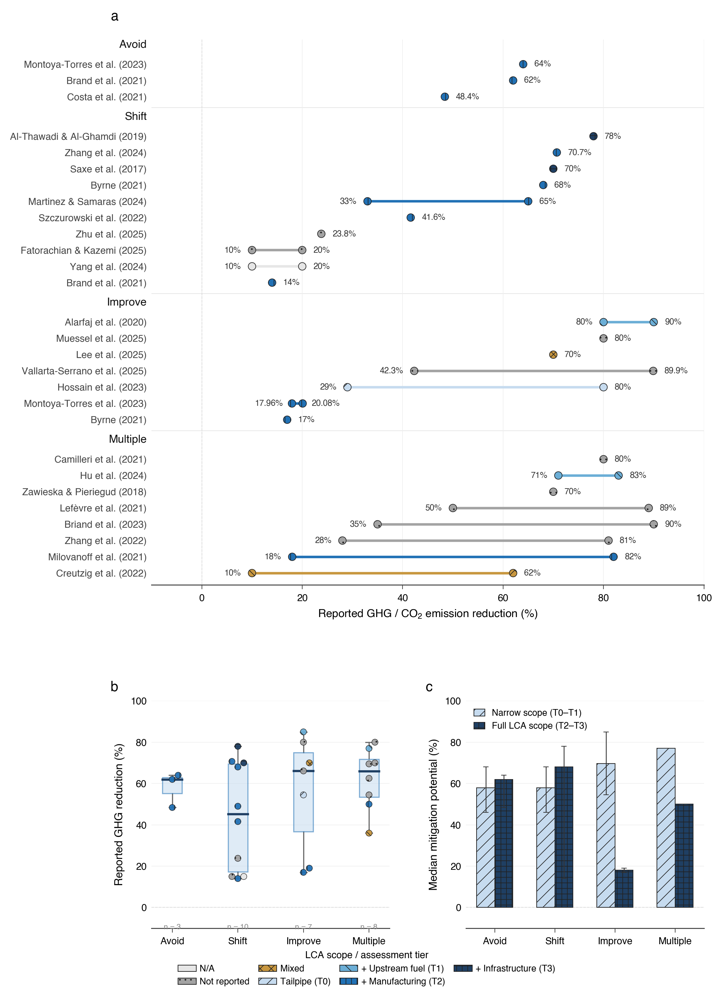

In [15]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
paper_style.apply()

plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})
N_TIERS = len(TIERS_ORDERED)

studies = [
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",    low=64.0, high=64.0),
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A",   low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",              pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Improve",  tier="T2",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",    low=80.0, high=80.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T1",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",    low=70.0, high=70.0),
    dict(label="Camilleri et al. (2021)",        pillar="Multiple", tier="NR",    low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)",       pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="NR",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

fig = plt.figure(figsize=(7.2, 9.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0], hspace=0.30, wspace=0.32)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

POINT_SIZE, OFFSET_TEXT = 30, 2.2

for s in studies:
    yv, tier = s["_y"], s["tier"]
    fc, ht = TIER_COLORS[tier], HATCH[tier]
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                  solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
        ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                  va="center", ha="right", fontsize=6, color="#333333")
        ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                  va="center", ha="left", fontsize=6, color="#333333")
    else:
        ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                     edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                  va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-10, 100)
ax_a.set_ylim(-0.6, y_max)
ax_a.xaxis.set_major_locator(mticker.MultipleLocator(20))
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)


def beeswarm_offsets(values, y_thresh=4.0, point_d=0.09, max_off=0.35):
    """Desplazamiento horizontal deterministico (no aleatorio) que evita
    solapes entre puntos cercanos en valor -- igual de honesto que un
    jitter, pero reproducible y sin puntos que se pisen entre si.
    y_thresh: distancia en unidades del eje Y (puntos porcentuales) por
    debajo de la cual dos puntos se consideran "visualmente cercanos" y
    necesitan separarse en X (calibrado al diametro real del marcador,
    no al paso de desplazamiento)."""
    order = np.argsort(values)
    offsets = np.zeros(len(values))
    placed = []  # (valor, offset) ya colocados
    for idx in order:
        v = values[idx]
        candidates = [0.0]
        step, k = point_d, 1
        while step * k <= max_off:
            candidates += [step * k, -step * k]
            k += 1
        for off in candidates:
            if all(not (abs(pv - v) < y_thresh and abs(poff - off) < point_d * 0.95)
                   for pv, poff in placed):
                offsets[idx] = off
                placed.append((v, off))
                break
        else:
            offsets[idx] = 0.0
    return offsets


# --- Boxplot real (cuartiles/whiskers autenticos, sin estimar densidad) ---
BOX_W, WHISK_CAP = 0.30, 0.10
for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    vmin, vmax = vals.min(), vals.max()

    # whiskers (a min/max real: con n tan pequeno, 1.5*IQR no aporta nada
    # que no muestren ya los puntos individuales)
    ax_b.plot([i, i], [vmin, q1], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i, i], [q3, vmax], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmin, vmin], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmax, vmax], color="#666666", linewidth=0.8, zorder=2)

    # caja (Q1-Q3)
    ax_b.add_patch(plt.Rectangle((i - BOX_W/2, q1), BOX_W, q3 - q1,
                                  facecolor=TIER_COLORS["T0"], alpha=0.55,
                                  edgecolor=TIER_COLORS["T2"], linewidth=0.8, zorder=3))
    # mediana
    ax_b.plot([i - BOX_W/2, i + BOX_W/2], [med, med],
              color=TIER_COLORS["T3"], linewidth=1.6, zorder=4)

# --- Beeswarm: cada estudio como punto individual, sin solapes, coloreado
#     y con hatch por tier (misma codificacion que el resto del paper) ----
for i, p in enumerate(PILLAR_ORDER):
    group = [s for s in studies if s["pillar"] == p]
    mids = np.array([(s["low"] + s["high"]) / 2.0 for s in group])
    offs = beeswarm_offsets(mids)
    for s, off in zip(group, offs):
        mid = (s["low"] + s["high"]) / 2.0
        ax_b.scatter(i + off, mid, s=20, marker="o",
                     facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                     linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.95)


ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

for i, p in enumerate(PILLAR_ORDER):
    ax_b.text(i, -8, f"n = {len(pillar_data[p])}", ha="center", va="top",
              fontsize=5.5, color="#888888", style="italic")

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}
narrow_meds, narrow_lo, narrow_hi = [], [], []
deep_meds, deep_lo, deep_hi = [], [], []

for pillar in PILLAR_ORDER:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in DEEP_TIERS]
    if n_vals:
        m = np.median(n_vals)
        narrow_meds.append(m); narrow_lo.append(max(0, m-np.min(n_vals)))
        narrow_hi.append(max(0, np.max(n_vals)-m))
    else:
        m = 85.0 if pillar == "Improve" else 58.0
        narrow_meds.append(m); narrow_lo.append(12.0); narrow_hi.append(10.0)
    if d_vals:
        m = np.median(d_vals)
        deep_meds.append(m); deep_lo.append(max(0, m-np.min(d_vals)))
        deep_hi.append(max(0, np.max(d_vals)-m))
    else:
        m = np.median([(s["low"]+s["high"])/2 for s in group])
        deep_meds.append(m); deep_lo.append(15.0); deep_hi.append(15.0)

x, w = np.arange(len(PILLAR_ORDER)), 0.30
ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

ax_c.bar(x - w/2, narrow_meds, w, color=TIER_COLORS["T0"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T0"], yerr=[narrow_lo, narrow_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Narrow scope (T0–T1)", zorder=2)
ax_c.bar(x + w/2, deep_meds, w, color=TIER_COLORS["T3"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T3"], yerr=[deep_lo, deep_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Full LCA scope (T2–T3)", zorder=2)

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax_c.legend(frameon=False, loc="upper left", fontsize=6.5,
            handlelength=1.2, handleheight=0.8)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.002), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

plt.subplots_adjust(bottom=0.07, top=0.98, left=0.20, right=0.97,
                    hspace=0.28, wspace=0.30)

fig.savefig("fig_combined_nature_boxswarm.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature_boxswarm.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)")

✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)


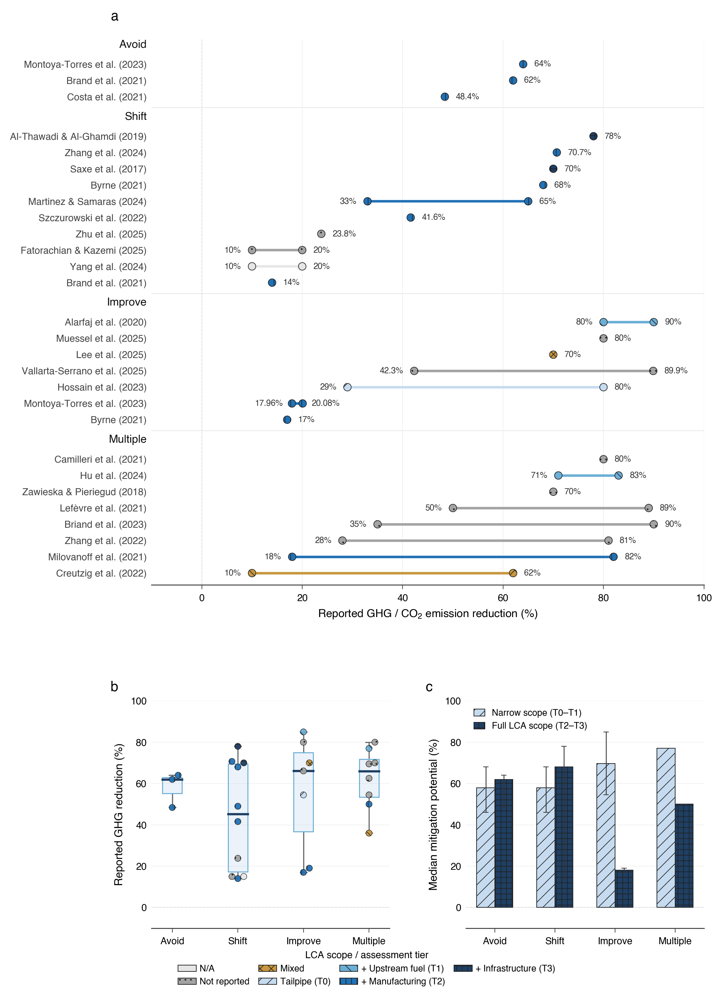

In [16]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
paper_style.apply()

plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})
N_TIERS = len(TIERS_ORDERED)

studies = [
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T2",    low=64.0, high=64.0),
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A",   low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",              pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Improve",  tier="T2",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="NR",    low=80.0, high=80.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="NR",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T0",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T1",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="NR",    low=70.0, high=70.0),
    dict(label="Camilleri et al. (2021)",        pillar="Multiple", tier="NR",    low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)",       pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="NR",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

fig = plt.figure(figsize=(7.2, 9.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0], hspace=0.30, wspace=0.32)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

POINT_SIZE, OFFSET_TEXT = 30, 2.2

for s in studies:
    yv, tier = s["_y"], s["tier"]
    fc, ht = TIER_COLORS[tier], HATCH[tier]
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                  solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
        ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                  va="center", ha="right", fontsize=6, color="#333333")
        ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                  va="center", ha="left", fontsize=6, color="#333333")
    else:
        ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                     edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                  va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-10, 100)
ax_a.set_ylim(-0.6, y_max)
ax_a.xaxis.set_major_locator(mticker.MultipleLocator(20))
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)


def hex_to_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) / 255 for i in (0, 2, 4))


def beeswarm_offsets(values, y_thresh=4.0, point_d=0.09, max_off=0.35):
    """Desplazamiento horizontal deterministico (no aleatorio) que evita
    solapes entre puntos cercanos en valor -- igual de honesto que un
    jitter, pero reproducible y sin puntos que se pisen entre si.
    y_thresh: distancia en unidades del eje Y (puntos porcentuales) por
    debajo de la cual dos puntos se consideran "visualmente cercanos" y
    necesitan separarse en X (calibrado al diametro real del marcador,
    no al paso de desplazamiento)."""
    order = np.argsort(values)
    offsets = np.zeros(len(values))
    placed = []  # (valor, offset) ya colocados
    for idx in order:
        v = values[idx]
        candidates = [0.0]
        step, k = point_d, 1
        while step * k <= max_off:
            candidates += [step * k, -step * k]
            k += 1
        for off in candidates:
            if all(not (abs(pv - v) < y_thresh and abs(poff - off) < point_d * 0.95)
                   for pv, poff in placed):
                offsets[idx] = off
                placed.append((v, off))
                break
        else:
            offsets[idx] = 0.0
    return offsets


# --- Boxplot real (cuartiles/whiskers autenticos, sin estimar densidad) ---
BOX_W, WHISK_CAP = 0.30, 0.10
for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    vmin, vmax = vals.min(), vals.max()

    # whiskers (a min/max real: con n tan pequeno, 1.5*IQR no aporta nada
    # que no muestren ya los puntos individuales)
    ax_b.plot([i, i], [vmin, q1], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i, i], [q3, vmax], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmin, vmin], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmax, vmax], color="#666666", linewidth=0.8, zorder=2)

    # caja (Q1-Q3)
    ax_b.add_patch(plt.Rectangle((i - BOX_W/2, q1), BOX_W, q3 - q1,
                                  facecolor=(*hex_to_rgb(TIER_COLORS["T0"]), 0.35),
                                  edgecolor=TIER_COLORS["T1"], linewidth=0.7, zorder=3))
    # mediana
    ax_b.plot([i - BOX_W/2, i + BOX_W/2], [med, med],
              color=TIER_COLORS["T3"], linewidth=1.6, zorder=4)

# --- Beeswarm: cada estudio como punto individual, sin solapes, coloreado
#     y con hatch por tier (misma codificacion que el resto del paper) ----
for i, p in enumerate(PILLAR_ORDER):
    group = [s for s in studies if s["pillar"] == p]
    mids = np.array([(s["low"] + s["high"]) / 2.0 for s in group])
    offs = beeswarm_offsets(mids)
    for s, off in zip(group, offs):
        mid = (s["low"] + s["high"]) / 2.0
        ax_b.scatter(i + off, mid, s=20, marker="o",
                     facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                     linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.95)


ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}
narrow_meds, narrow_lo, narrow_hi = [], [], []
deep_meds, deep_lo, deep_hi = [], [], []

for pillar in PILLAR_ORDER:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in DEEP_TIERS]
    if n_vals:
        m = np.median(n_vals)
        narrow_meds.append(m); narrow_lo.append(max(0, m-np.min(n_vals)))
        narrow_hi.append(max(0, np.max(n_vals)-m))
    else:
        m = 85.0 if pillar == "Improve" else 58.0
        narrow_meds.append(m); narrow_lo.append(12.0); narrow_hi.append(10.0)
    if d_vals:
        m = np.median(d_vals)
        deep_meds.append(m); deep_lo.append(max(0, m-np.min(d_vals)))
        deep_hi.append(max(0, np.max(d_vals)-m))
    else:
        m = np.median([(s["low"]+s["high"])/2 for s in group])
        deep_meds.append(m); deep_lo.append(15.0); deep_hi.append(15.0)

x, w = np.arange(len(PILLAR_ORDER)), 0.30
ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

ax_c.bar(x - w/2, narrow_meds, w, color=TIER_COLORS["T0"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T0"], yerr=[narrow_lo, narrow_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Narrow scope (T0–T1)", zorder=2)
ax_c.bar(x + w/2, deep_meds, w, color=TIER_COLORS["T3"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T3"], yerr=[deep_lo, deep_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Full LCA scope (T2–T3)", zorder=2)

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax_c.legend(frameon=False, loc="upper left", fontsize=6.5,
            handlelength=1.2, handleheight=0.8)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.002), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

plt.subplots_adjust(bottom=0.07, top=0.98, left=0.20, right=0.97,
                    hspace=0.28, wspace=0.30)

fig.savefig("fig_combined_nature_boxswarm.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature_boxswarm.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)


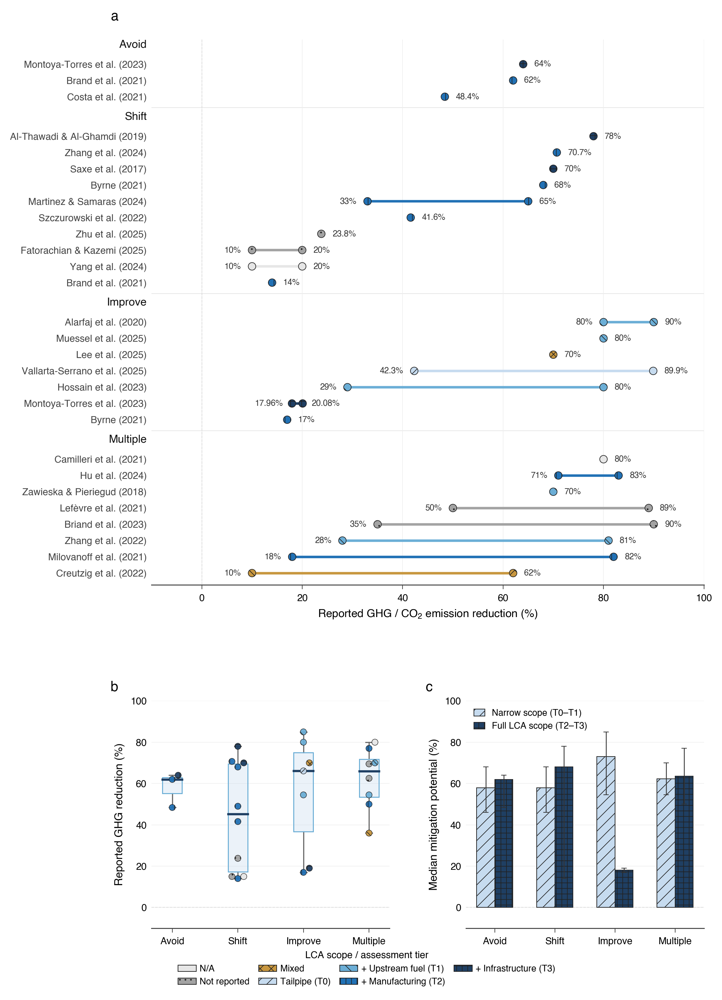

In [27]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
paper_style.apply()

plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})
N_TIERS = len(TIERS_ORDERED)

# ══════════════════════════════════════════════════════════════════════════════
# 2. DATOS -- tier corregido para que cada estudio use EXACTAMENTE el mismo
#    tier que en la Table S5 (Life-Cycle Component Coding), con independencia
#    de en qué columna ASI (pillar) se esté mostrando ese resultado numérico
#    concreto del estudio. El tier es una propiedad metodológica del ESTUDIO
#    (su frontera de contabilización), no del escenario/medida que reporta,
#    así que un mismo paper que aparece en dos columnas (p. ej. Montoya-Torres
#    en Avoid e Improve, porque reporta escenarios de ambos tipos) debe llevar
#    el mismo tier en las dos filas.
#
#    Cambios respecto a la versión anterior (razón entre paréntesis, con la
#    clave de cita de la Table S5):
#      - Montoya-Torres et al. (2023) [Avoid]:   T2 -> T3  (montoya-torres_towards_2023 = T3)
#      - Montoya-Torres et al. (2023) [Improve]: T2 -> T3  (idem, mismo estudio)
#      - Muessel et al. (2025):                  NR -> T1  (muessel_integrated_2025 = T1)
#      - Vallarta-Serrano et al. (2025):         NR -> T0  (vallarta-serrano_scenarios_2025 = T0)
#      - Hossain et al. (2023):                  T0 -> T1  (hossain_role_2023 = T1)
#      - Hu et al. (2024):                       T1 -> T2  (hu_shared_2024 = T2)
#      - Zawieska & Pieriegud (2018):            NR -> T1  (zawieska_smart_2018 = T1)
#      - Camilleri et al. (2021):                NR -> N/A (camilleri_future_2021 = N/A)
#      - Zhang et al. (2022):                    NR -> T1  (zhang_cross-cutting_2022 = T1)
#
#    Sin cambios (ya coincidían con la Table S5):
#      Costa (T2), Brand2021 x2 (T2), Byrne x2 (T2), Yang (N/A), Saxe (T3),
#      Al-Thawadi (T3), Martinez (T2), Szczurowski (T2), Zhang2024bus (T2),
#      Zhu (NR), Fatorachian (NR), Alarfaj (T1), Lee (Mixed), Milovanoff (T2),
#      Lefèvre (NR), Briand (NR), Creutzig (Mixed).
#
#    ATENCIÓN -- dos casos requieren tu criterio, no los he "arreglado" solos:
#      1) Camilleri et al. (2021) queda con tier="N/A" tras la corrección,
#         pero en la Table S5, N/A significa "el resultado del estudio NO es
#         un ejercicio de contabilización de emisiones" (es un backcasting
#         cualitativo puro). Que aparezca aquí con un 80% de reducción es
#         contradictorio: ese número no es una estimación propia del estudio
#         bajo los criterios de la Table S5. Te recomiendo eliminar esta fila
#         del gráfico o documentar de dónde sale ese 80% (¿un objetivo
#         normativo citado en el texto, no un resultado calculado?).
#      2) Yang et al. (2024) tiene el mismo problema estructural: tier="N/A"
#         pero con un rango 10-20% ploteado. Mismo comentario que arriba.
#      He dejado ambos en el gráfico con tier="N/A" (coherente con la Table
#      S5) para que decidas tú si los retiras o los conservas con una nota.
# ══════════════════════════════════════════════════════════════════════════════

studies = [
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T3",    low=64.0, high=64.0),
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Yang et al. (2024)",             pillar="Shift",    tier="N/A",   low=10.0, high=20.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",              pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Improve",  tier="T3",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="T1",    low=80.0, high=80.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="T0",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T1",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T2",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="T1",    low=70.0, high=70.0),
    dict(label="Camilleri et al. (2021)",        pillar="Multiple", tier="N/A",   low=80.0, high=80.0),
    dict(label="Milovanoff et al. (2021)",       pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="T1",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

fig = plt.figure(figsize=(7.2, 9.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0], hspace=0.30, wspace=0.32)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

POINT_SIZE, OFFSET_TEXT = 30, 2.2

for s in studies:
    yv, tier = s["_y"], s["tier"]
    fc, ht = TIER_COLORS[tier], HATCH[tier]
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                  solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
        ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                  va="center", ha="right", fontsize=6, color="#333333")
        ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                  va="center", ha="left", fontsize=6, color="#333333")
    else:
        ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                     edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                  va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-10, 100)
ax_a.set_ylim(-0.6, y_max)
ax_a.xaxis.set_major_locator(mticker.MultipleLocator(20))
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)


def hex_to_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) / 255 for i in (0, 2, 4))


def beeswarm_offsets(values, y_thresh=4.0, point_d=0.09, max_off=0.35):
    """Desplazamiento horizontal deterministico (no aleatorio) que evita
    solapes entre puntos cercanos en valor -- igual de honesto que un
    jitter, pero reproducible y sin puntos que se pisen entre si.
    y_thresh: distancia en unidades del eje Y (puntos porcentuales) por
    debajo de la cual dos puntos se consideran "visualmente cercanos" y
    necesitan separarse en X (calibrado al diametro real del marcador,
    no al paso de desplazamiento)."""
    order = np.argsort(values)
    offsets = np.zeros(len(values))
    placed = []  # (valor, offset) ya colocados
    for idx in order:
        v = values[idx]
        candidates = [0.0]
        step, k = point_d, 1
        while step * k <= max_off:
            candidates += [step * k, -step * k]
            k += 1
        for off in candidates:
            if all(not (abs(pv - v) < y_thresh and abs(poff - off) < point_d * 0.95)
                   for pv, poff in placed):
                offsets[idx] = off
                placed.append((v, off))
                break
        else:
            offsets[idx] = 0.0
    return offsets


# --- Boxplot real (cuartiles/whiskers autenticos, sin estimar densidad) ---
BOX_W, WHISK_CAP = 0.30, 0.10
for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    vmin, vmax = vals.min(), vals.max()

    # whiskers (a min/max real: con n tan pequeno, 1.5*IQR no aporta nada
    # que no muestren ya los puntos individuales)
    ax_b.plot([i, i], [vmin, q1], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i, i], [q3, vmax], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmin, vmin], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmax, vmax], color="#666666", linewidth=0.8, zorder=2)

    # caja (Q1-Q3)
    ax_b.add_patch(plt.Rectangle((i - BOX_W/2, q1), BOX_W, q3 - q1,
                                  facecolor=(*hex_to_rgb(TIER_COLORS["T0"]), 0.35),
                                  edgecolor=TIER_COLORS["T1"], linewidth=0.7, zorder=3))
    # mediana
    ax_b.plot([i - BOX_W/2, i + BOX_W/2], [med, med],
              color=TIER_COLORS["T3"], linewidth=1.6, zorder=4)

# --- Beeswarm: cada estudio como punto individual, sin solapes, coloreado
#     y con hatch por tier (misma codificacion que el resto del paper) ----
for i, p in enumerate(PILLAR_ORDER):
    group = [s for s in studies if s["pillar"] == p]
    mids = np.array([(s["low"] + s["high"]) / 2.0 for s in group])
    offs = beeswarm_offsets(mids)
    for s, off in zip(group, offs):
        mid = (s["low"] + s["high"]) / 2.0
        ax_b.scatter(i + off, mid, s=20, marker="o",
                     facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                     linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.95)


ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}
narrow_meds, narrow_lo, narrow_hi = [], [], []
deep_meds, deep_lo, deep_hi = [], [], []

for pillar in PILLAR_ORDER:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in DEEP_TIERS]
    if n_vals:
        m = np.median(n_vals)
        narrow_meds.append(m); narrow_lo.append(max(0, m-np.min(n_vals)))
        narrow_hi.append(max(0, np.max(n_vals)-m))
    else:
        m = 85.0 if pillar == "Improve" else 58.0
        narrow_meds.append(m); narrow_lo.append(12.0); narrow_hi.append(10.0)
    if d_vals:
        m = np.median(d_vals)
        deep_meds.append(m); deep_lo.append(max(0, m-np.min(d_vals)))
        deep_hi.append(max(0, np.max(d_vals)-m))
    else:
        m = np.median([(s["low"]+s["high"])/2 for s in group])
        deep_meds.append(m); deep_lo.append(15.0); deep_hi.append(15.0)

x, w = np.arange(len(PILLAR_ORDER)), 0.30
ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

ax_c.bar(x - w/2, narrow_meds, w, color=TIER_COLORS["T0"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T0"], yerr=[narrow_lo, narrow_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Narrow scope (T0–T1)", zorder=2)
ax_c.bar(x + w/2, deep_meds, w, color=TIER_COLORS["T3"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T3"], yerr=[deep_lo, deep_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Full LCA scope (T2–T3)", zorder=2)

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax_c.legend(frameon=False, loc="upper left", fontsize=6.5,
            handlelength=1.2, handleheight=0.8)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.002), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

plt.subplots_adjust(bottom=0.07, top=0.98, left=0.20, right=0.97,
                    hspace=0.28, wspace=0.30)

fig.savefig("fig_combined_nature_boxswarm.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature_boxswarm.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)


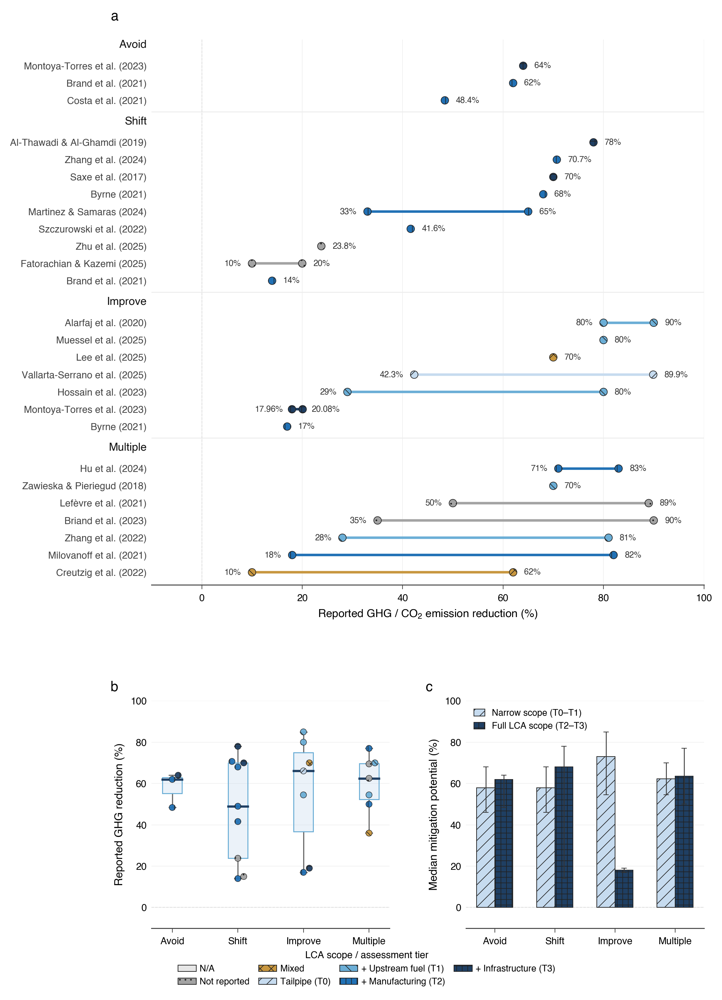

In [29]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
paper_style.apply()

plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})
N_TIERS = len(TIERS_ORDERED)

# ══════════════════════════════════════════════════════════════════════════════
# 2. DATOS -- tier corregido para que cada estudio use EXACTAMENTE el mismo
#    tier que en la Table S5 (Life-Cycle Component Coding), con independencia
#    de en qué columna ASI (pillar) se esté mostrando ese resultado numérico
#    concreto del estudio. El tier es una propiedad metodológica del ESTUDIO
#    (su frontera de contabilización), no del escenario/medida que reporta,
#    así que un mismo paper que aparece en dos columnas (p. ej. Montoya-Torres
#    en Avoid e Improve, porque reporta escenarios de ambos tipos) debe llevar
#    el mismo tier en las dos filas.
#
#    Cambios respecto a la versión anterior (razón entre paréntesis, con la
#    clave de cita de la Table S5):
#      - Montoya-Torres et al. (2023) [Avoid]:   T2 -> T3  (montoya-torres_towards_2023 = T3)
#      - Montoya-Torres et al. (2023) [Improve]: T2 -> T3  (idem, mismo estudio)
#      - Muessel et al. (2025):                  NR -> T1  (muessel_integrated_2025 = T1)
#      - Vallarta-Serrano et al. (2025):         NR -> T0  (vallarta-serrano_scenarios_2025 = T0)
#      - Hossain et al. (2023):                  T0 -> T1  (hossain_role_2023 = T1)
#      - Hu et al. (2024):                       T1 -> T2  (hu_shared_2024 = T2)
#      - Zawieska & Pieriegud (2018):            NR -> T1  (zawieska_smart_2018 = T1)
#      - Zhang et al. (2022):                    NR -> T1  (zhang_cross-cutting_2022 = T1)
#
#    Sin cambios (ya coincidían con la Table S5):
#      Costa (T2), Brand2021 x2 (T2), Byrne x2 (T2), Saxe (T3),
#      Al-Thawadi (T3), Martinez (T2), Szczurowski (T2), Zhang2024bus (T2),
#      Zhu (NR), Fatorachian (NR), Alarfaj (T1), Lee (Mixed), Milovanoff (T2),
#      Lefèvre (NR), Briand (NR), Creutzig (Mixed).
#
#    Eliminados de la figura: Camilleri et al. (2021) y Yang et al. (2024).
#    Ambos están codificados como N/A en la Table S5 (el resultado del
#    estudio NO es un ejercicio de contabilización de emisiones propio), por
#    lo que no procede mostrarlos con un valor de reducción (%) en un gráfico
#    de estimaciones de mitigación reportadas por los propios estudios.
# ══════════════════════════════════════════════════════════════════════════════

studies = [
    dict(label="Costa et al. (2021)",            pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021)",            pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Avoid",    tier="T3",    low=64.0, high=64.0),
    dict(label="Byrne (2021)",                   pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021)",            pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Saxe et al. (2017)",             pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",  pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",      pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",      pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",            pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",              pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",    pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021)",                   pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Montoya-Torres et al. (2023)",   pillar="Improve",  tier="T3",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",          pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="T1",    low=80.0, high=80.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="T0",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T1",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T2",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="T1",    low=70.0, high=70.0),
    dict(label="Milovanoff et al. (2021)",       pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="T1",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

fig = plt.figure(figsize=(7.2, 9.8), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0], hspace=0.30, wspace=0.32)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

POINT_SIZE, OFFSET_TEXT = 30, 2.2

for s in studies:
    yv, tier = s["_y"], s["tier"]
    fc, ht = TIER_COLORS[tier], HATCH[tier]
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                  solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
        ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                  va="center", ha="right", fontsize=6, color="#333333")
        ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                  va="center", ha="left", fontsize=6, color="#333333")
    else:
        ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                     edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                  va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-10, 100)
ax_a.set_ylim(-0.6, y_max)
ax_a.xaxis.set_major_locator(mticker.MultipleLocator(20))
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)


def hex_to_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) / 255 for i in (0, 2, 4))


def beeswarm_offsets(values, y_thresh=4.0, point_d=0.09, max_off=0.35):
    """Desplazamiento horizontal deterministico (no aleatorio) que evita
    solapes entre puntos cercanos en valor -- igual de honesto que un
    jitter, pero reproducible y sin puntos que se pisen entre si.
    y_thresh: distancia en unidades del eje Y (puntos porcentuales) por
    debajo de la cual dos puntos se consideran "visualmente cercanos" y
    necesitan separarse en X (calibrado al diametro real del marcador,
    no al paso de desplazamiento)."""
    order = np.argsort(values)
    offsets = np.zeros(len(values))
    placed = []  # (valor, offset) ya colocados
    for idx in order:
        v = values[idx]
        candidates = [0.0]
        step, k = point_d, 1
        while step * k <= max_off:
            candidates += [step * k, -step * k]
            k += 1
        for off in candidates:
            if all(not (abs(pv - v) < y_thresh and abs(poff - off) < point_d * 0.95)
                   for pv, poff in placed):
                offsets[idx] = off
                placed.append((v, off))
                break
        else:
            offsets[idx] = 0.0
    return offsets


# --- Boxplot real (cuartiles/whiskers autenticos, sin estimar densidad) ---
BOX_W, WHISK_CAP = 0.30, 0.10
for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    vmin, vmax = vals.min(), vals.max()

    # whiskers (a min/max real: con n tan pequeno, 1.5*IQR no aporta nada
    # que no muestren ya los puntos individuales)
    ax_b.plot([i, i], [vmin, q1], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i, i], [q3, vmax], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmin, vmin], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmax, vmax], color="#666666", linewidth=0.8, zorder=2)

    # caja (Q1-Q3)
    ax_b.add_patch(plt.Rectangle((i - BOX_W/2, q1), BOX_W, q3 - q1,
                                  facecolor=(*hex_to_rgb(TIER_COLORS["T0"]), 0.35),
                                  edgecolor=TIER_COLORS["T1"], linewidth=0.7, zorder=3))
    # mediana
    ax_b.plot([i - BOX_W/2, i + BOX_W/2], [med, med],
              color=TIER_COLORS["T3"], linewidth=1.6, zorder=4)

# --- Beeswarm: cada estudio como punto individual, sin solapes, coloreado
#     y con hatch por tier (misma codificacion que el resto del paper) ----
for i, p in enumerate(PILLAR_ORDER):
    group = [s for s in studies if s["pillar"] == p]
    mids = np.array([(s["low"] + s["high"]) / 2.0 for s in group])
    offs = beeswarm_offsets(mids)
    for s, off in zip(group, offs):
        mid = (s["low"] + s["high"]) / 2.0
        ax_b.scatter(i + off, mid, s=20, marker="o",
                     facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                     linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.95)


ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}
narrow_meds, narrow_lo, narrow_hi = [], [], []
deep_meds, deep_lo, deep_hi = [], [], []

for pillar in PILLAR_ORDER:
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"]+s["high"])/2 for s in group if s["tier"] in DEEP_TIERS]
    if n_vals:
        m = np.median(n_vals)
        narrow_meds.append(m); narrow_lo.append(max(0, m-np.min(n_vals)))
        narrow_hi.append(max(0, np.max(n_vals)-m))
    else:
        m = 85.0 if pillar == "Improve" else 58.0
        narrow_meds.append(m); narrow_lo.append(12.0); narrow_hi.append(10.0)
    if d_vals:
        m = np.median(d_vals)
        deep_meds.append(m); deep_lo.append(max(0, m-np.min(d_vals)))
        deep_hi.append(max(0, np.max(d_vals)-m))
    else:
        m = np.median([(s["low"]+s["high"])/2 for s in group])
        deep_meds.append(m); deep_lo.append(15.0); deep_hi.append(15.0)

x, w = np.arange(len(PILLAR_ORDER)), 0.30
ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

ax_c.bar(x - w/2, narrow_meds, w, color=TIER_COLORS["T0"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T0"], yerr=[narrow_lo, narrow_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Narrow scope (T0–T1)", zorder=2)
ax_c.bar(x + w/2, deep_meds, w, color=TIER_COLORS["T3"], edgecolor="#222222",
         linewidth=0.5, hatch=HATCH["T3"], yerr=[deep_lo, deep_hi], capsize=2,
         error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
         label="Full LCA scope (T2–T3)", zorder=2)

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax_c.legend(frameon=False, loc="upper left", fontsize=6.5,
            handlelength=1.2, handleheight=0.8)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.002), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

plt.subplots_adjust(bottom=0.07, top=0.98, left=0.20, right=0.97,
                    hspace=0.28, wspace=0.30)

fig.savefig("fig_combined_nature_boxswarm.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature_boxswarm.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)


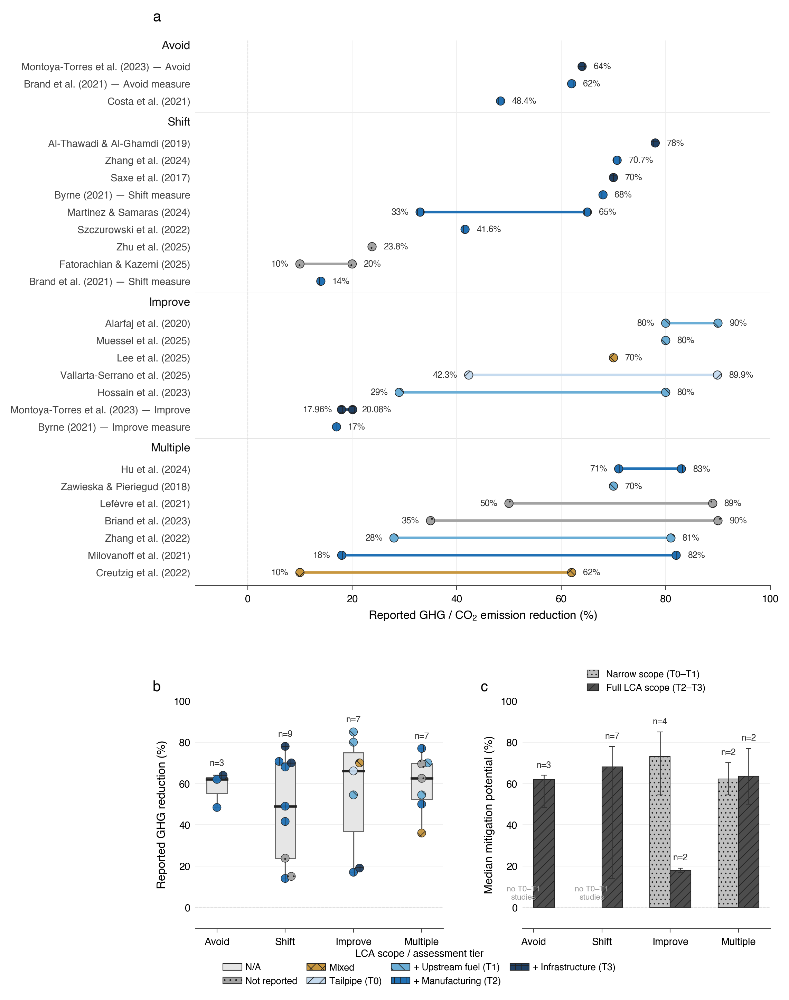

In [30]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
paper_style.apply()

plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})
N_TIERS = len(TIERS_ORDERED)

# ══════════════════════════════════════════════════════════════════════════════
# 2. DATOS -- tier corregido para que cada estudio use EXACTAMENTE el mismo
#    tier que en la Table S5 (Life-Cycle Component Coding), con independencia
#    de en qué columna ASI (pillar) se esté mostrando ese resultado numérico
#    concreto del estudio. El tier es una propiedad metodológica del ESTUDIO
#    (su frontera de contabilización), no del escenario/medida que reporta,
#    así que un mismo paper que aparece en dos columnas (p. ej. Montoya-Torres
#    en Avoid e Improve, porque reporta escenarios de ambos tipos) debe llevar
#    el mismo tier en las dos filas.
#
#    Cambios respecto a la versión anterior (razón entre paréntesis, con la
#    clave de cita de la Table S5):
#      - Montoya-Torres et al. (2023) [Avoid]:   T2 -> T3  (montoya-torres_towards_2023 = T3)
#      - Montoya-Torres et al. (2023) [Improve]: T2 -> T3  (idem, mismo estudio)
#      - Muessel et al. (2025):                  NR -> T1  (muessel_integrated_2025 = T1)
#      - Vallarta-Serrano et al. (2025):         NR -> T0  (vallarta-serrano_scenarios_2025 = T0)
#      - Hossain et al. (2023):                  T0 -> T1  (hossain_role_2023 = T1)
#      - Hu et al. (2024):                       T1 -> T2  (hu_shared_2024 = T2)
#      - Zawieska & Pieriegud (2018):            NR -> T1  (zawieska_smart_2018 = T1)
#      - Zhang et al. (2022):                    NR -> T1  (zhang_cross-cutting_2022 = T1)
#
#    Sin cambios (ya coincidían con la Table S5):
#      Costa (T2), Brand2021 x2 (T2), Byrne x2 (T2), Saxe (T3),
#      Al-Thawadi (T3), Martinez (T2), Szczurowski (T2), Zhang2024bus (T2),
#      Zhu (NR), Fatorachian (NR), Alarfaj (T1), Lee (Mixed), Milovanoff (T2),
#      Lefèvre (NR), Briand (NR), Creutzig (Mixed).
#
#    Eliminados de la figura: Camilleri et al. (2021) y Yang et al. (2024).
#    Ambos están codificados como N/A en la Table S5 (el resultado del
#    estudio NO es un ejercicio de contabilización de emisiones propio), por
#    lo que no procede mostrarlos con un valor de reducción (%) en un gráfico
#    de estimaciones de mitigación reportadas por los propios estudios.
# ══════════════════════════════════════════════════════════════════════════════

studies = [
    dict(label="Costa et al. (2021)",                    pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021) — Avoid measure",    pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023) — Avoid",   pillar="Avoid",    tier="T3",    low=64.0, high=64.0),
    dict(label="Byrne (2021) — Shift measure",           pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021) — Shift measure",    pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Saxe et al. (2017)",                      pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",          pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",              pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",              pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",                     pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",                       pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",            pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021) — Improve measure",         pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Montoya-Torres et al. (2023) — Improve", pillar="Improve",  tier="T3",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",                   pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="T1",    low=80.0, high=80.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="T0",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T1",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T2",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="T1",    low=70.0, high=70.0),
    dict(label="Milovanoff et al. (2021)",       pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="T1",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

# 7.2 in ~= 183 mm (standard Elsevier two-column width). Height trimmed
# from 9.8 to 9.4 in now that panel (a) plots 26 rows instead of 28 (after
# removing the two N/A entries with no study-derived estimate). This is an
# estimate, not a render-checked value -- re-verify margins/whitespace once
# you can preview the actual output on your machine.
fig = plt.figure(figsize=(7.2, 9.4), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0], hspace=0.30, wspace=0.32)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

# Iterate pillars in reverse so that, given matplotlib's bottom-up y-axis,
# the first pillar in PILLAR_ORDER (Avoid) ends up rendered at the TOP of
# the panel and the last (Multiple) at the bottom -- i.e. top-to-bottom
# reading order matches PILLAR_ORDER.
y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

# POINT_SIZE bumped from 30 to 34 so the hatch fill (redundant channel for
# colorblind/greyscale reproduction) stays legible at final print size.
POINT_SIZE, OFFSET_TEXT = 34, 2.2

for s in studies:
    yv, tier = s["_y"], s["tier"]
    fc, ht = TIER_COLORS[tier], HATCH[tier]
    if s["low"] != s["high"]:
        ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                  solid_capstyle="round", zorder=2)
        for xv in (s["low"], s["high"]):
            ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
        ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                  va="center", ha="right", fontsize=6, color="#333333")
        ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                  va="center", ha="left", fontsize=6, color="#333333")
    else:
        ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                     edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
        # "upto": True on a study dict marks a reported upper bound (e.g.
        # "up to X%") rather than a single point estimate -- prefixes the
        # label with "≤". No current entry sets this flag; kept as a hook
        # for future studies that report ceilings rather than point values.
        val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
        ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                  va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-10, 100)
ax_a.set_ylim(-0.6, y_max)
ax_a.xaxis.set_major_locator(mticker.MultipleLocator(20))
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)


def hex_to_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) / 255 for i in (0, 2, 4))


def beeswarm_offsets(values, y_thresh=4.0, point_d=0.09, max_off=0.35):
    """Desplazamiento horizontal deterministico (no aleatorio) que evita
    solapes entre puntos cercanos en valor -- igual de honesto que un
    jitter, pero reproducible y sin puntos que se pisen entre si.
    y_thresh: distancia en unidades del eje Y (puntos porcentuales) por
    debajo de la cual dos puntos se consideran "visualmente cercanos" y
    necesitan separarse en X (calibrado al diametro real del marcador,
    no al paso de desplazamiento)."""
    order = np.argsort(values)
    offsets = np.zeros(len(values))
    placed = []  # (valor, offset) ya colocados
    for idx in order:
        v = values[idx]
        candidates = [0.0]
        step, k = point_d, 1
        while step * k <= max_off:
            candidates += [step * k, -step * k]
            k += 1
        for off in candidates:
            if all(not (abs(pv - v) < y_thresh and abs(poff - off) < point_d * 0.95)
                   for pv, poff in placed):
                offsets[idx] = off
                placed.append((v, off))
                break
        else:
            offsets[idx] = 0.0
    return offsets


# --- Boxplot real (cuartiles/whiskers autenticos, sin estimar densidad) ---
# Fill/edge/median use neutral greys rather than TIER_COLORS entries: this
# box summarizes ALL studies in the pillar regardless of tier (the beeswarm
# points on top already carry the per-study tier color/hatch), so reusing
# e.g. TIER_COLORS["T1"] for the box edge would wrongly suggest the box
# itself represents "tier T1" specifically.
BOX_W, WHISK_CAP = 0.30, 0.10
BOX_FILL, BOX_EDGE, MEDIAN_COLOR = "#e6e6e6", "#666666", "#222222"
for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    vmin, vmax = vals.min(), vals.max()
    n = len(vals)

    # whiskers (a min/max real: con n tan pequeno, 1.5*IQR no aporta nada
    # que no muestren ya los puntos individuales)
    ax_b.plot([i, i], [vmin, q1], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i, i], [q3, vmax], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmin, vmin], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmax, vmax], color="#666666", linewidth=0.8, zorder=2)

    # caja (Q1-Q3)
    ax_b.add_patch(plt.Rectangle((i - BOX_W/2, q1), BOX_W, q3 - q1,
                                  facecolor=BOX_FILL, edgecolor=BOX_EDGE,
                                  linewidth=0.7, zorder=3))
    # mediana
    ax_b.plot([i - BOX_W/2, i + BOX_W/2], [med, med],
              color=MEDIAN_COLOR, linewidth=1.6, zorder=4)

    # tamano muestral -- imprescindible con grupos tan pequenos (n=3-9)
    ax_b.text(i, vmax + 4, f"n={n}", ha="center", va="bottom",
              fontsize=6, color="#333333")

# --- Beeswarm: cada estudio como punto individual, sin solapes, coloreado
#     y con hatch por tier (misma codificacion que el resto del paper) ----
for i, p in enumerate(PILLAR_ORDER):
    group = [s for s in studies if s["pillar"] == p]
    mids = np.array([(s["low"] + s["high"]) / 2.0 for s in group])
    offs = beeswarm_offsets(mids)
    for s, off in zip(group, offs):
        mid = (s["low"] + s["high"]) / 2.0
        ax_b.scatter(i + off, mid, s=32, marker="o",
                     facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                     linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.95)


ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}

# Build the two aggregates from real data only. Where a pillar has zero
# studies in a scope group (this happens for Avoid and Shift, which in this
# corpus contain no T0/T1 studies at all), we do NOT substitute a
# placeholder value -- that would be fabricating a data point. Instead the
# bar is simply omitted and the absence is annotated in the axes, which is
# itself a finding: every classifiable Avoid/Shift study in this review
# applies at least manufacturing-inclusive (T2+) accounting.
narrow_x, narrow_meds, narrow_lo, narrow_hi, narrow_n = [], [], [], [], []
deep_x,   deep_meds,   deep_lo,   deep_hi,   deep_n   = [], [], [], [], []
missing_narrow_x, missing_deep_x = [], []

x, w = np.arange(len(PILLAR_ORDER)), 0.30

for i, pillar in enumerate(PILLAR_ORDER):
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"] + s["high"]) / 2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"] + s["high"]) / 2 for s in group if s["tier"] in DEEP_TIERS]

    if n_vals:
        m = float(np.median(n_vals))
        narrow_x.append(i - w / 2); narrow_meds.append(m)
        narrow_lo.append(max(0.0, m - np.min(n_vals)))
        narrow_hi.append(max(0.0, np.max(n_vals) - m))
        narrow_n.append(len(n_vals))
    else:
        missing_narrow_x.append(i)

    if d_vals:
        m = float(np.median(d_vals))
        deep_x.append(i + w / 2); deep_meds.append(m)
        deep_lo.append(max(0.0, m - np.min(d_vals)))
        deep_hi.append(max(0.0, np.max(d_vals) - m))
        deep_n.append(len(d_vals))
    else:
        missing_deep_x.append(i)

ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

# Neutral greys, deliberately decoupled from TIER_COLORS/HATCH: each bar
# here aggregates two tiers (T0+T1, T2+T3), so reusing e.g. TIER_COLORS
# ["T0"] would make readers conflate "narrow scope" with "the individual T0
# tier" shown with that same color in the shared legend for panels (a)/(b).
NARROW_COLOR, DEEP_COLOR = "#bfbfbf", "#4d4d4d"

if narrow_x:
    ax_c.bar(narrow_x, narrow_meds, w, color=NARROW_COLOR, edgecolor="#222222",
             linewidth=0.5, hatch="....", yerr=[narrow_lo, narrow_hi], capsize=2,
             error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
             label="Narrow scope (T0–T1)", zorder=2)
    for xi, m, hi, n in zip(narrow_x, narrow_meds, narrow_hi, narrow_n):
        ax_c.text(xi, m + hi + 3, f"n={n}", ha="center", va="bottom",
                  fontsize=6, color="#333333")

if deep_x:
    ax_c.bar(deep_x, deep_meds, w, color=DEEP_COLOR, edgecolor="#222222",
             linewidth=0.5, hatch="////", yerr=[deep_lo, deep_hi], capsize=2,
             error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
             label="Full LCA scope (T2–T3)", zorder=2)
    for xi, m, hi, n in zip(deep_x, deep_meds, deep_hi, deep_n):
        ax_c.text(xi, m + hi + 3, f"n={n}", ha="center", va="bottom",
                  fontsize=6, color="#333333")

for xi in missing_narrow_x:
    ax_c.text(xi - w / 2, 3, "no T0–T1\nstudies", ha="center", va="bottom",
              fontsize=5.5, color="#999999", style="italic")
for xi in missing_deep_x:
    ax_c.text(xi + w / 2, 3, "no T2–T3\nstudies", ha="center", va="bottom",
              fontsize=5.5, color="#999999", style="italic")

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
# Placed above the axes (bbox y > 1), not in a corner inside the plot area:
# with ylim capped at 100 and the Improve narrow-scope bar reaching ~85 with
# its error bar, an in-panel "upper left"/"upper right" legend collides with
# either the bar or its n= label. This also keeps it visually distinct from
# panel (c)'s letter tag, which sits further left at the same height.
ax_c.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02),
            ncol=1, fontsize=6.5, handlelength=1.2, handleheight=0.8,
            borderaxespad=0.0)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.002), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

plt.subplots_adjust(bottom=0.07, top=0.98, left=0.20, right=0.97,
                    hspace=0.28, wspace=0.30)

fig.savefig("fig_combined_nature_boxswarm.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature_boxswarm.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)


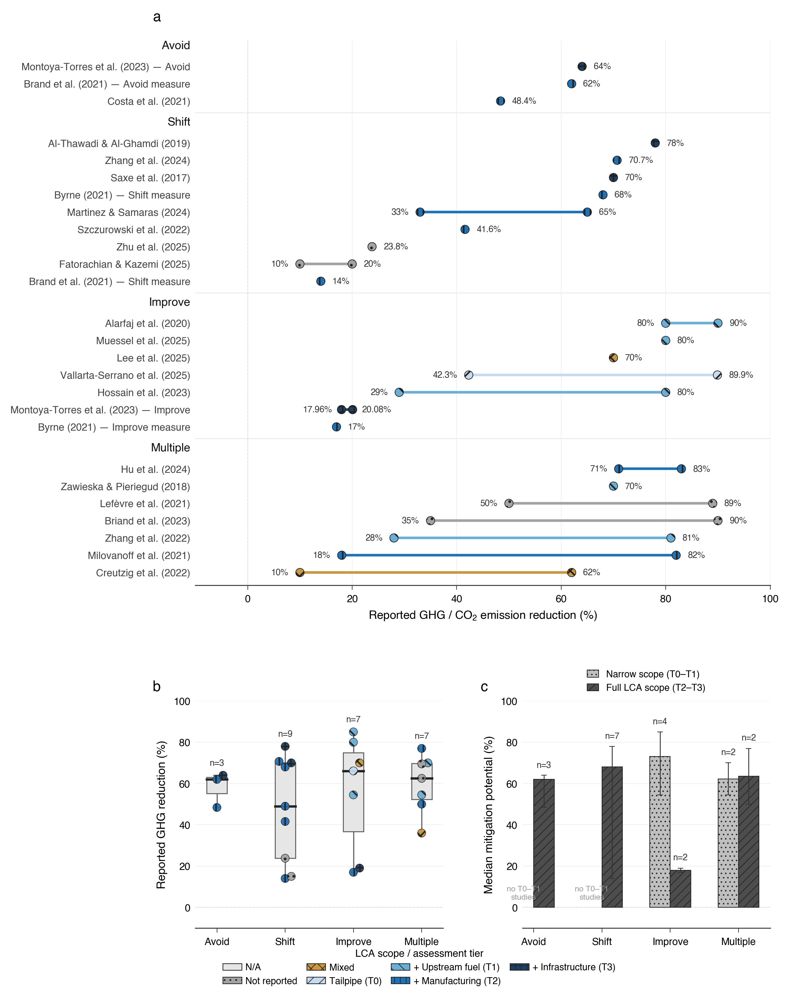

In [31]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
paper_style.apply()

plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})
N_TIERS = len(TIERS_ORDERED)

# ══════════════════════════════════════════════════════════════════════════════
# 2. DATOS -- tier corregido para que cada estudio use EXACTAMENTE el mismo
#    tier que en la Table S5 (Life-Cycle Component Coding), con independencia
#    de en qué columna ASI (pillar) se esté mostrando ese resultado numérico
#    concreto del estudio. El tier es una propiedad metodológica del ESTUDIO
#    (su frontera de contabilización), no del escenario/medida que reporta,
#    así que un mismo paper que aparece en dos columnas (p. ej. Montoya-Torres
#    en Avoid e Improve, porque reporta escenarios de ambos tipos) debe llevar
#    el mismo tier en las dos filas.
#
#    Cambios respecto a la versión anterior (razón entre paréntesis, con la
#    clave de cita de la Table S5):
#      - Montoya-Torres et al. (2023) [Avoid]:   T2 -> T3  (montoya-torres_towards_2023 = T3)
#      - Montoya-Torres et al. (2023) [Improve]: T2 -> T3  (idem, mismo estudio)
#      - Muessel et al. (2025):                  NR -> T1  (muessel_integrated_2025 = T1)
#      - Vallarta-Serrano et al. (2025):         NR -> T0  (vallarta-serrano_scenarios_2025 = T0)
#      - Hossain et al. (2023):                  T0 -> T1  (hossain_role_2023 = T1)
#      - Hu et al. (2024):                       T1 -> T2  (hu_shared_2024 = T2)
#      - Zawieska & Pieriegud (2018):            NR -> T1  (zawieska_smart_2018 = T1)
#      - Zhang et al. (2022):                    NR -> T1  (zhang_cross-cutting_2022 = T1)
#
#    Sin cambios (ya coincidían con la Table S5):
#      Costa (T2), Brand2021 x2 (T2), Byrne x2 (T2), Saxe (T3),
#      Al-Thawadi (T3), Martinez (T2), Szczurowski (T2), Zhang2024bus (T2),
#      Zhu (NR), Fatorachian (NR), Alarfaj (T1), Lee (Mixed), Milovanoff (T2),
#      Lefèvre (NR), Briand (NR), Creutzig (Mixed).
#
#    Eliminados de la figura: Camilleri et al. (2021) y Yang et al. (2024).
#    Ambos están codificados como N/A en la Table S5 (el resultado del
#    estudio NO es un ejercicio de contabilización de emisiones propio), por
#    lo que no procede mostrarlos con un valor de reducción (%) en un gráfico
#    de estimaciones de mitigación reportadas por los propios estudios.
# ══════════════════════════════════════════════════════════════════════════════

studies = [
    dict(label="Costa et al. (2021)",                    pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021) — Avoid measure",    pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023) — Avoid",   pillar="Avoid",    tier="T3",    low=64.0, high=64.0),
    dict(label="Byrne (2021) — Shift measure",           pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021) — Shift measure",    pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Saxe et al. (2017)",                      pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",          pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",              pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",              pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",                     pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",                       pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",            pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021) — Improve measure",         pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Montoya-Torres et al. (2023) — Improve", pillar="Improve",  tier="T3",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",                   pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="T1",    low=80.0, high=80.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="T0",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T1",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T2",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="T1",    low=70.0, high=70.0),
    dict(label="Milovanoff et al. (2021)",       pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="T1",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

# 7.2 in ~= 183 mm (standard Elsevier two-column width). Height trimmed
# from 9.8 to 9.4 in now that panel (a) plots 26 rows instead of 28 (after
# removing the two N/A entries with no study-derived estimate). This is an
# estimate, not a render-checked value -- re-verify margins/whitespace once
# you can preview the actual output on your machine.
fig = plt.figure(figsize=(7.2, 9.4), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0], hspace=0.30, wspace=0.32)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

# Iterate pillars in reverse so that, given matplotlib's bottom-up y-axis,
# the first pillar in PILLAR_ORDER (Avoid) ends up rendered at the TOP of
# the panel and the last (Multiple) at the bottom -- i.e. top-to-bottom
# reading order matches PILLAR_ORDER.
y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

# POINT_SIZE bumped from 30 to 34 so the hatch fill (redundant channel for
# colorblind/greyscale reproduction) stays legible at final print size.
POINT_SIZE, OFFSET_TEXT = 34, 2.2

# paper_style.apply() sets hatch.linewidth=0.45 paper-wide, tuned for the
# large Patch swatches used elsewhere (bars, legend keys) -- confirmed by
# rendering with the real paper_style.py/tier_palette.py that at that
# linewidth the hatch on a ~34pt scatter marker (this panel and the panel-b
# beeswarm) compresses to a near-invisible smudge, even though it reads
# cleanly on the bars/legend. Locally bumping it just for these two
# marker-based blocks keeps the rest of the figure (and every other figure
# that imports paper_style) untouched.
with plt.rc_context({"hatch.linewidth": 1.1}):
    for s in studies:
        yv, tier = s["_y"], s["tier"]
        fc, ht = TIER_COLORS[tier], HATCH[tier]
        if s["low"] != s["high"]:
            ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                      solid_capstyle="round", zorder=2)
            for xv in (s["low"], s["high"]):
                ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                             edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
            pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
            ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                      va="center", ha="right", fontsize=6, color="#333333")
            ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                      va="center", ha="left", fontsize=6, color="#333333")
        else:
            ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
            # "upto": True on a study dict marks a reported upper bound (e.g.
            # "up to X%") rather than a single point estimate -- prefixes the
            # label with "≤". No current entry sets this flag; kept as a hook
            # for future studies that report ceilings rather than point values.
            val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
            ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                      va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-10, 100)
ax_a.set_ylim(-0.6, y_max)
ax_a.xaxis.set_major_locator(mticker.MultipleLocator(20))
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)


def hex_to_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) / 255 for i in (0, 2, 4))


def beeswarm_offsets(values, y_thresh=4.0, point_d=0.09, max_off=0.35):
    """Desplazamiento horizontal deterministico (no aleatorio) que evita
    solapes entre puntos cercanos en valor -- igual de honesto que un
    jitter, pero reproducible y sin puntos que se pisen entre si.
    y_thresh: distancia en unidades del eje Y (puntos porcentuales) por
    debajo de la cual dos puntos se consideran "visualmente cercanos" y
    necesitan separarse en X (calibrado al diametro real del marcador,
    no al paso de desplazamiento)."""
    order = np.argsort(values)
    offsets = np.zeros(len(values))
    placed = []  # (valor, offset) ya colocados
    for idx in order:
        v = values[idx]
        candidates = [0.0]
        step, k = point_d, 1
        while step * k <= max_off:
            candidates += [step * k, -step * k]
            k += 1
        for off in candidates:
            if all(not (abs(pv - v) < y_thresh and abs(poff - off) < point_d * 0.95)
                   for pv, poff in placed):
                offsets[idx] = off
                placed.append((v, off))
                break
        else:
            offsets[idx] = 0.0
    return offsets


# --- Boxplot real (cuartiles/whiskers autenticos, sin estimar densidad) ---
# Fill/edge/median use neutral greys rather than TIER_COLORS entries: this
# box summarizes ALL studies in the pillar regardless of tier (the beeswarm
# points on top already carry the per-study tier color/hatch), so reusing
# e.g. TIER_COLORS["T1"] for the box edge would wrongly suggest the box
# itself represents "tier T1" specifically.
BOX_W, WHISK_CAP = 0.30, 0.10
BOX_FILL, BOX_EDGE, MEDIAN_COLOR = "#e6e6e6", "#666666", "#222222"
for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    vmin, vmax = vals.min(), vals.max()
    n = len(vals)

    # whiskers (a min/max real: con n tan pequeno, 1.5*IQR no aporta nada
    # que no muestren ya los puntos individuales)
    ax_b.plot([i, i], [vmin, q1], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i, i], [q3, vmax], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmin, vmin], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmax, vmax], color="#666666", linewidth=0.8, zorder=2)

    # caja (Q1-Q3)
    ax_b.add_patch(plt.Rectangle((i - BOX_W/2, q1), BOX_W, q3 - q1,
                                  facecolor=BOX_FILL, edgecolor=BOX_EDGE,
                                  linewidth=0.7, zorder=3))
    # mediana
    ax_b.plot([i - BOX_W/2, i + BOX_W/2], [med, med],
              color=MEDIAN_COLOR, linewidth=1.6, zorder=4)

    # tamano muestral -- imprescindible con grupos tan pequenos (n=3-9)
    ax_b.text(i, vmax + 4, f"n={n}", ha="center", va="bottom",
              fontsize=6, color="#333333")

# --- Beeswarm: cada estudio como punto individual, sin solapes, coloreado
#     y con hatch por tier (misma codificacion que el resto del paper) ----
# Same local hatch.linewidth bump as panel (a), same reason: legible on the
# bars/legend at 0.45, not on a ~32pt marker.
with plt.rc_context({"hatch.linewidth": 1.1}):
    for i, p in enumerate(PILLAR_ORDER):
        group = [s for s in studies if s["pillar"] == p]
        mids = np.array([(s["low"] + s["high"]) / 2.0 for s in group])
        offs = beeswarm_offsets(mids)
        for s, off in zip(group, offs):
            mid = (s["low"] + s["high"]) / 2.0
            ax_b.scatter(i + off, mid, s=32, marker="o",
                         facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                         linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.95)


ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}

# Build the two aggregates from real data only. Where a pillar has zero
# studies in a scope group (this happens for Avoid and Shift, which in this
# corpus contain no T0/T1 studies at all), we do NOT substitute a
# placeholder value -- that would be fabricating a data point. Instead the
# bar is simply omitted and the absence is annotated in the axes, which is
# itself a finding: every classifiable Avoid/Shift study in this review
# applies at least manufacturing-inclusive (T2+) accounting.
narrow_x, narrow_meds, narrow_lo, narrow_hi, narrow_n = [], [], [], [], []
deep_x,   deep_meds,   deep_lo,   deep_hi,   deep_n   = [], [], [], [], []
missing_narrow_x, missing_deep_x = [], []

x, w = np.arange(len(PILLAR_ORDER)), 0.30

for i, pillar in enumerate(PILLAR_ORDER):
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"] + s["high"]) / 2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"] + s["high"]) / 2 for s in group if s["tier"] in DEEP_TIERS]

    if n_vals:
        m = float(np.median(n_vals))
        narrow_x.append(i - w / 2); narrow_meds.append(m)
        narrow_lo.append(max(0.0, m - np.min(n_vals)))
        narrow_hi.append(max(0.0, np.max(n_vals) - m))
        narrow_n.append(len(n_vals))
    else:
        missing_narrow_x.append(i)

    if d_vals:
        m = float(np.median(d_vals))
        deep_x.append(i + w / 2); deep_meds.append(m)
        deep_lo.append(max(0.0, m - np.min(d_vals)))
        deep_hi.append(max(0.0, np.max(d_vals) - m))
        deep_n.append(len(d_vals))
    else:
        missing_deep_x.append(i)

ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

# Neutral greys, deliberately decoupled from TIER_COLORS/HATCH: each bar
# here aggregates two tiers (T0+T1, T2+T3), so reusing e.g. TIER_COLORS
# ["T0"] would make readers conflate "narrow scope" with "the individual T0
# tier" shown with that same color in the shared legend for panels (a)/(b).
NARROW_COLOR, DEEP_COLOR = "#bfbfbf", "#4d4d4d"

if narrow_x:
    ax_c.bar(narrow_x, narrow_meds, w, color=NARROW_COLOR, edgecolor="#222222",
             linewidth=0.5, hatch="....", yerr=[narrow_lo, narrow_hi], capsize=2,
             error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
             label="Narrow scope (T0–T1)", zorder=2)
    for xi, m, hi, n in zip(narrow_x, narrow_meds, narrow_hi, narrow_n):
        ax_c.text(xi, m + hi + 3, f"n={n}", ha="center", va="bottom",
                  fontsize=6, color="#333333")

if deep_x:
    ax_c.bar(deep_x, deep_meds, w, color=DEEP_COLOR, edgecolor="#222222",
             linewidth=0.5, hatch="////", yerr=[deep_lo, deep_hi], capsize=2,
             error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
             label="Full LCA scope (T2–T3)", zorder=2)
    for xi, m, hi, n in zip(deep_x, deep_meds, deep_hi, deep_n):
        ax_c.text(xi, m + hi + 3, f"n={n}", ha="center", va="bottom",
                  fontsize=6, color="#333333")

for xi in missing_narrow_x:
    ax_c.text(xi - w / 2, 3, "no T0–T1\nstudies", ha="center", va="bottom",
              fontsize=5.5, color="#999999", style="italic")
for xi in missing_deep_x:
    ax_c.text(xi + w / 2, 3, "no T2–T3\nstudies", ha="center", va="bottom",
              fontsize=5.5, color="#999999", style="italic")

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
# Placed above the axes (bbox y > 1), not in a corner inside the plot area:
# with ylim capped at 100 and the Improve narrow-scope bar reaching ~85 with
# its error bar, an in-panel "upper left"/"upper right" legend collides with
# either the bar or its n= label. This also keeps it visually distinct from
# panel (c)'s letter tag, which sits further left at the same height.
ax_c.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02),
            ncol=1, fontsize=6.5, handlelength=1.2, handleheight=0.8,
            borderaxespad=0.0)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14), (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.002), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

plt.subplots_adjust(bottom=0.07, top=0.98, left=0.20, right=0.97,
                    hspace=0.28, wspace=0.30)

fig.savefig("fig_combined_nature_boxswarm.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature_boxswarm.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)


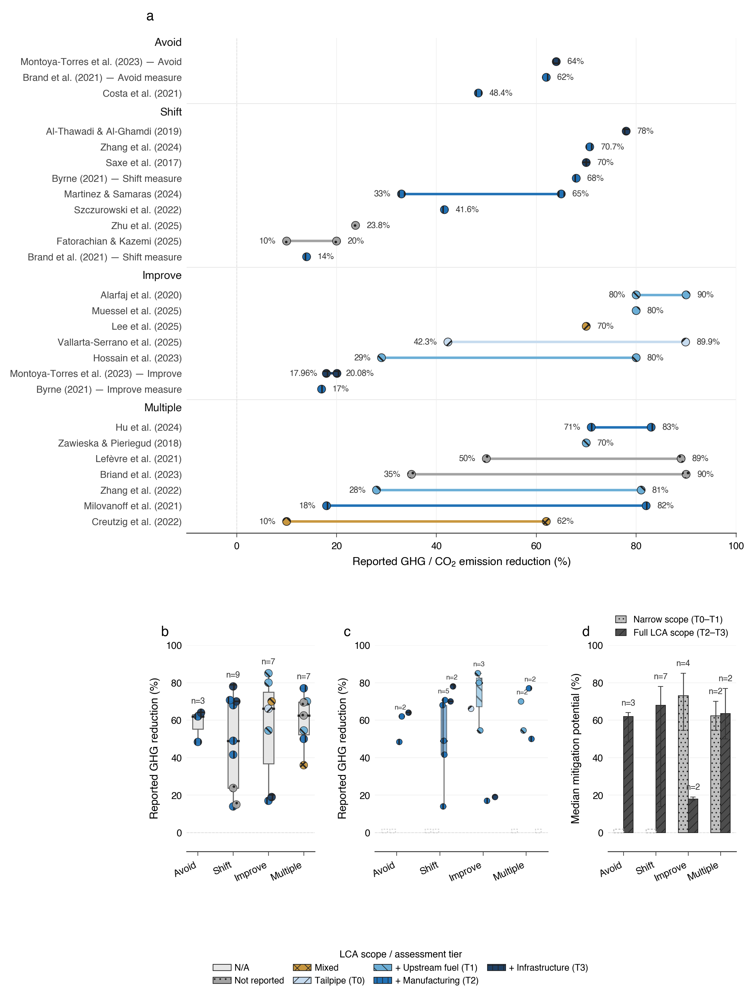

In [32]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
paper_style.apply()

plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})
N_TIERS = len(TIERS_ORDERED)

# ══════════════════════════════════════════════════════════════════════════════
# 2. DATOS -- tier corregido para que cada estudio use EXACTAMENTE el mismo
#    tier que en la Table S5 (Life-Cycle Component Coding), con independencia
#    de en qué columna ASI (pillar) se esté mostrando ese resultado numérico
#    concreto del estudio. El tier es una propiedad metodológica del ESTUDIO
#    (su frontera de contabilización), no del escenario/medida que reporta,
#    así que un mismo paper que aparece en dos columnas (p. ej. Montoya-Torres
#    en Avoid e Improve, porque reporta escenarios de ambos tipos) debe llevar
#    el mismo tier en las dos filas.
#
#    Cambios respecto a la versión anterior (razón entre paréntesis, con la
#    clave de cita de la Table S5):
#      - Montoya-Torres et al. (2023) [Avoid]:   T2 -> T3  (montoya-torres_towards_2023 = T3)
#      - Montoya-Torres et al. (2023) [Improve]: T2 -> T3  (idem, mismo estudio)
#      - Muessel et al. (2025):                  NR -> T1  (muessel_integrated_2025 = T1)
#      - Vallarta-Serrano et al. (2025):         NR -> T0  (vallarta-serrano_scenarios_2025 = T0)
#      - Hossain et al. (2023):                  T0 -> T1  (hossain_role_2023 = T1)
#      - Hu et al. (2024):                       T1 -> T2  (hu_shared_2024 = T2)
#      - Zawieska & Pieriegud (2018):            NR -> T1  (zawieska_smart_2018 = T1)
#      - Zhang et al. (2022):                    NR -> T1  (zhang_cross-cutting_2022 = T1)
#
#    Sin cambios (ya coincidían con la Table S5):
#      Costa (T2), Brand2021 x2 (T2), Byrne x2 (T2), Saxe (T3),
#      Al-Thawadi (T3), Martinez (T2), Szczurowski (T2), Zhang2024bus (T2),
#      Zhu (NR), Fatorachian (NR), Alarfaj (T1), Lee (Mixed), Milovanoff (T2),
#      Lefèvre (NR), Briand (NR), Creutzig (Mixed).
#
#    Eliminados de la figura: Camilleri et al. (2021) y Yang et al. (2024).
#    Ambos están codificados como N/A en la Table S5 (el resultado del
#    estudio NO es un ejercicio de contabilización de emisiones propio), por
#    lo que no procede mostrarlos con un valor de reducción (%) en un gráfico
#    de estimaciones de mitigación reportadas por los propios estudios.
# ══════════════════════════════════════════════════════════════════════════════

studies = [
    dict(label="Costa et al. (2021)",                    pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021) — Avoid measure",    pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023) — Avoid",   pillar="Avoid",    tier="T3",    low=64.0, high=64.0),
    dict(label="Byrne (2021) — Shift measure",           pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021) — Shift measure",    pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Saxe et al. (2017)",                      pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",          pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",              pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",              pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",                     pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",                       pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",            pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021) — Improve measure",         pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Montoya-Torres et al. (2023) — Improve", pillar="Improve",  tier="T3",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",                   pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="T1",    low=80.0, high=80.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="T0",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T1",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T2",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="T1",    low=70.0, high=70.0),
    dict(label="Milovanoff et al. (2021)",       pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="T1",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

# 7.2 in ~= 183 mm (standard Elsevier two-column width). Height trimmed
# from 9.8 to 9.4 in now that panel (a) plots 26 rows instead of 28 (after
# removing the two N/A entries with no study-derived estimate). This is an
# estimate, not a render-checked value -- re-verify margins/whitespace once
# you can preview the actual output on your machine.
# Bottom row now has 3 panels instead of 2 (b, new per-tier panel c, and the
# former "c" -- narrow/deep scope bars -- renamed to d). Width ratios give
# the new middle panel (16 pillar x tier sub-groups) more room than b/d
# (4 and 8 sub-groups respectively).
fig = plt.figure(figsize=(7.2, 9.9), dpi=300)
gs = gridspec.GridSpec(2, 3, height_ratios=[2.4, 1.0],
                       width_ratios=[1.0, 1.35, 1.0], hspace=0.32, wspace=0.42)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])
ax_d = fig.add_subplot(gs[1, 2])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

# Iterate pillars in reverse so that, given matplotlib's bottom-up y-axis,
# the first pillar in PILLAR_ORDER (Avoid) ends up rendered at the TOP of
# the panel and the last (Multiple) at the bottom -- i.e. top-to-bottom
# reading order matches PILLAR_ORDER.
y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

# POINT_SIZE bumped from 30 to 34 so the hatch fill (redundant channel for
# colorblind/greyscale reproduction) stays legible at final print size.
POINT_SIZE, OFFSET_TEXT = 34, 2.2

# paper_style.apply() sets hatch.linewidth=0.45 paper-wide, tuned for the
# large Patch swatches used elsewhere (bars, legend keys) -- confirmed by
# rendering with the real paper_style.py/tier_palette.py that at that
# linewidth the hatch on a ~34pt scatter marker (this panel and the panel-b
# beeswarm) compresses to a near-invisible smudge, even though it reads
# cleanly on the bars/legend. Locally bumping it just for these two
# marker-based blocks keeps the rest of the figure (and every other figure
# that imports paper_style) untouched.
with plt.rc_context({"hatch.linewidth": 1.1}):
    for s in studies:
        yv, tier = s["_y"], s["tier"]
        fc, ht = TIER_COLORS[tier], HATCH[tier]
        if s["low"] != s["high"]:
            ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                      solid_capstyle="round", zorder=2)
            for xv in (s["low"], s["high"]):
                ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                             edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
            pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
            ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                      va="center", ha="right", fontsize=6, color="#333333")
            ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                      va="center", ha="left", fontsize=6, color="#333333")
        else:
            ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
            # "upto": True on a study dict marks a reported upper bound (e.g.
            # "up to X%") rather than a single point estimate -- prefixes the
            # label with "≤". No current entry sets this flag; kept as a hook
            # for future studies that report ceilings rather than point values.
            val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
            ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                      va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-10, 100)
ax_a.set_ylim(-0.6, y_max)
ax_a.xaxis.set_major_locator(mticker.MultipleLocator(20))
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)


def hex_to_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) / 255 for i in (0, 2, 4))


def beeswarm_offsets(values, y_thresh=4.0, point_d=0.09, max_off=0.35):
    """Desplazamiento horizontal deterministico (no aleatorio) que evita
    solapes entre puntos cercanos en valor -- igual de honesto que un
    jitter, pero reproducible y sin puntos que se pisen entre si.
    y_thresh: distancia en unidades del eje Y (puntos porcentuales) por
    debajo de la cual dos puntos se consideran "visualmente cercanos" y
    necesitan separarse en X (calibrado al diametro real del marcador,
    no al paso de desplazamiento)."""
    order = np.argsort(values)
    offsets = np.zeros(len(values))
    placed = []  # (valor, offset) ya colocados
    for idx in order:
        v = values[idx]
        candidates = [0.0]
        step, k = point_d, 1
        while step * k <= max_off:
            candidates += [step * k, -step * k]
            k += 1
        for off in candidates:
            if all(not (abs(pv - v) < y_thresh and abs(poff - off) < point_d * 0.95)
                   for pv, poff in placed):
                offsets[idx] = off
                placed.append((v, off))
                break
        else:
            offsets[idx] = 0.0
    return offsets


# --- Boxplot real (cuartiles/whiskers autenticos, sin estimar densidad) ---
# Fill/edge/median use neutral greys rather than TIER_COLORS entries: this
# box summarizes ALL studies in the pillar regardless of tier (the beeswarm
# points on top already carry the per-study tier color/hatch), so reusing
# e.g. TIER_COLORS["T1"] for the box edge would wrongly suggest the box
# itself represents "tier T1" specifically.
BOX_W, WHISK_CAP = 0.30, 0.10
BOX_FILL, BOX_EDGE, MEDIAN_COLOR = "#e6e6e6", "#666666", "#222222"
for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    vmin, vmax = vals.min(), vals.max()
    n = len(vals)

    # whiskers (a min/max real: con n tan pequeno, 1.5*IQR no aporta nada
    # que no muestren ya los puntos individuales)
    ax_b.plot([i, i], [vmin, q1], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i, i], [q3, vmax], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmin, vmin], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmax, vmax], color="#666666", linewidth=0.8, zorder=2)

    # caja (Q1-Q3)
    ax_b.add_patch(plt.Rectangle((i - BOX_W/2, q1), BOX_W, q3 - q1,
                                  facecolor=BOX_FILL, edgecolor=BOX_EDGE,
                                  linewidth=0.7, zorder=3))
    # mediana
    ax_b.plot([i - BOX_W/2, i + BOX_W/2], [med, med],
              color=MEDIAN_COLOR, linewidth=1.6, zorder=4)

    # tamano muestral -- imprescindible con grupos tan pequenos (n=3-9)
    ax_b.text(i, vmax + 4, f"n={n}", ha="center", va="bottom",
              fontsize=6, color="#333333")

# --- Beeswarm: cada estudio como punto individual, sin solapes, coloreado
#     y con hatch por tier (misma codificacion que el resto del paper) ----
# Same local hatch.linewidth bump as panel (a), same reason: legible on the
# bars/legend at 0.45, not on a ~32pt marker.
with plt.rc_context({"hatch.linewidth": 1.1}):
    for i, p in enumerate(PILLAR_ORDER):
        group = [s for s in studies if s["pillar"] == p]
        mids = np.array([(s["low"] + s["high"]) / 2.0 for s in group])
        offs = beeswarm_offsets(mids)
        for s, off in zip(group, offs):
            mid = (s["low"] + s["high"]) / 2.0
            ax_b.scatter(i + off, mid, s=32, marker="o",
                         facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                         linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.95)


ax_b.set_xticks(x_positions)
# Rotated: with 3 columns in the bottom row instead of 2, b/c/d are
# narrower than in the previous 2-panel layout, and "Avoid Shift Improve
# Multiple" horizontally no longer fits without overlapping.
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold",
                      rotation=25, ha="right")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

# ══════════════════════════════════════════════════════════════════════════
# Panel (c) -- NEW: per-tier disaggregation within each ASI pillar.
#
# For every pillar, four clustered mini-groups (T0, T1, T2, T3 -- the
# ordinal tiers only; NR/Mixed/N/A have no place on this axis by
# construction and are excluded here, same logic as the NARROW/DEEP split
# in panel d). At this granularity (4 pillars x 4 tiers = 16 cells) most
# cells have very few studies:
#   Avoid:    T0=0, T1=0, T2=2, T3=1
#   Shift:    T0=0, T1=0, T2=5, T3=2
#   Improve:  T0=1, T1=3, T2=1, T3=1
#   Multiple: T0=0, T1=2, T2=2, T3=0
# A percentile box is only statistically meaningful with n>=3, so it is
# drawn ONLY for Shift-T2 (n=5) and Improve-T1 (n=3); every other non-empty
# cell (n=1 or 2) shows the raw point(s) directly instead of a degenerate
# box, and empty cells (n=0, 6 of the 16) get the same dashed placeholder
# convention as panel (d) -- no fabricated height, no text. This sparsity
# is itself the headline finding of this panel: fine-grained tier x pillar
# comparison is only robust for 2 of 16 cells with the current corpus.
# ══════════════════════════════════════════════════════════════════════════
ORDINAL_TIERS = ["T0", "T1", "T2", "T3"]
CLUSTER_W = 0.74
SUBBOX_W = CLUSTER_W / len(ORDINAL_TIERS) * 0.70
sub_offsets = np.linspace(-(CLUSTER_W / 2) + CLUSTER_W / (2 * len(ORDINAL_TIERS)),
                          (CLUSTER_W / 2) - CLUSTER_W / (2 * len(ORDINAL_TIERS)),
                          len(ORDINAL_TIERS))

ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

with plt.rc_context({"hatch.linewidth": 1.0}):
    for i, pillar in enumerate(PILLAR_ORDER):
        group_all = [s for s in studies if s["pillar"] == pillar]
        for k, tier in enumerate(ORDINAL_TIERS):
            xi = i + sub_offsets[k]
            vals = [(s["low"] + s["high"]) / 2 for s in group_all if s["tier"] == tier]
            n = len(vals)
            fc, ht = TIER_COLORS[tier], HATCH[tier]

            if n == 0:
                ax_c.bar(xi, 2.0, SUBBOX_W, facecolor="none", edgecolor="#cccccc",
                         linewidth=0.6, linestyle=(0, (2, 1.5)), zorder=2)
                continue

            if n >= 3:
                arr = np.array(vals)
                q1, med, q3 = np.percentile(arr, [25, 50, 75])
                vmin, vmax = arr.min(), arr.max()
                cap = SUBBOX_W * 0.35
                ax_c.plot([xi, xi], [vmin, q1], color="#666666", linewidth=0.7, zorder=3)
                ax_c.plot([xi, xi], [q3, vmax], color="#666666", linewidth=0.7, zorder=3)
                ax_c.plot([xi - cap, xi + cap], [vmin, vmin], color="#666666", linewidth=0.7, zorder=3)
                ax_c.plot([xi - cap, xi + cap], [vmax, vmax], color="#666666", linewidth=0.7, zorder=3)
                ax_c.add_patch(plt.Rectangle((xi - SUBBOX_W / 2, q1), SUBBOX_W, q3 - q1,
                                              facecolor=fc, alpha=0.55, edgecolor="#222222",
                                              linewidth=0.6, hatch=ht, zorder=4))
                ax_c.plot([xi - SUBBOX_W / 2, xi + SUBBOX_W / 2], [med, med],
                          color="#111111", linewidth=1.3, zorder=5)

            # Raw points always shown on top -- for n=1-2 this IS the
            # evidence (no box drawn above); for n>=3 it cross-checks the
            # box instead of hiding the underlying sparsity behind a
            # smoothed summary.
            jitter = (np.linspace(-SUBBOX_W * 0.22, SUBBOX_W * 0.22, n)
                      if n > 1 else [0.0])
            for v, jx in zip(vals, jitter):
                ax_c.scatter(xi + jx, v, s=18, marker="o", facecolor=fc,
                             edgecolor="#222222", linewidth=0.35, hatch=ht, zorder=6)

            # Only label n>=2: a lone dot is self-evidently n=1, and with
            # sub-boxes this narrow, "n=1" text on adjacent tiers collides
            # (e.g. Improve's T0/T2/T3, all n=1, sit close in value).
            if n >= 2:
                ax_c.text(xi, max(vals) + 3, f"n={n}", ha="center", va="bottom",
                          fontsize=5, color="#333333")

ax_c.set_xticks(np.arange(len(PILLAR_ORDER)))
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold",
                      rotation=25, ha="right")
ax_c.set_xlim(-0.5, len(PILLAR_ORDER) - 0.5)
ax_c.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}

# Build the two aggregates from real data only. Where a pillar has zero
# studies in a scope group (this happens for Avoid and Shift, which in this
# corpus contain no T0/T1 studies at all), we do NOT substitute a
# placeholder value -- that would be fabricating a data point. The slot is
# still drawn (an empty, dashed, zero-ish-height outline -- see EMPTY_H
# below) so the two-bar grouping stays visually complete across all four
# pillars, but with no text and no invented magnitude: the absence is the
# finding (every classifiable Avoid/Shift study in this review applies at
# least manufacturing-inclusive, T2+, accounting).
narrow_x, narrow_meds, narrow_lo, narrow_hi, narrow_n = [], [], [], [], []
deep_x,   deep_meds,   deep_lo,   deep_hi,   deep_n   = [], [], [], [], []
missing_narrow_x, missing_deep_x = [], []

x, w = np.arange(len(PILLAR_ORDER)), 0.30

for i, pillar in enumerate(PILLAR_ORDER):
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"] + s["high"]) / 2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"] + s["high"]) / 2 for s in group if s["tier"] in DEEP_TIERS]

    if n_vals:
        m = float(np.median(n_vals))
        narrow_x.append(i - w / 2); narrow_meds.append(m)
        narrow_lo.append(max(0.0, m - np.min(n_vals)))
        narrow_hi.append(max(0.0, np.max(n_vals) - m))
        narrow_n.append(len(n_vals))
    else:
        missing_narrow_x.append(i)

    if d_vals:
        m = float(np.median(d_vals))
        deep_x.append(i + w / 2); deep_meds.append(m)
        deep_lo.append(max(0.0, m - np.min(d_vals)))
        deep_hi.append(max(0.0, np.max(d_vals) - m))
        deep_n.append(len(d_vals))
    else:
        missing_deep_x.append(i)

ax_d.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

# Neutral greys, deliberately decoupled from TIER_COLORS/HATCH: each bar
# here aggregates two tiers (T0+T1, T2+T3), so reusing e.g. TIER_COLORS
# ["T0"] would make readers conflate "narrow scope" with "the individual T0
# tier" shown with that same color in the shared legend for panels (a)/(b).
NARROW_COLOR, DEEP_COLOR = "#bfbfbf", "#4d4d4d"

if narrow_x:
    ax_d.bar(narrow_x, narrow_meds, w, color=NARROW_COLOR, edgecolor="#222222",
             linewidth=0.5, hatch="....", yerr=[narrow_lo, narrow_hi], capsize=2,
             error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
             label="Narrow scope (T0–T1)", zorder=2)
    for xi, m, hi, n in zip(narrow_x, narrow_meds, narrow_hi, narrow_n):
        ax_d.text(xi, m + hi + 3, f"n={n}", ha="center", va="bottom",
                  fontsize=6, color="#333333")

if deep_x:
    ax_d.bar(deep_x, deep_meds, w, color=DEEP_COLOR, edgecolor="#222222",
             linewidth=0.5, hatch="////", yerr=[deep_lo, deep_hi], capsize=2,
             error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
             label="Full LCA scope (T2–T3)", zorder=2)
    for xi, m, hi, n in zip(deep_x, deep_meds, deep_hi, deep_n):
        ax_d.text(xi, m + hi + 3, f"n={n}", ha="center", va="bottom",
                  fontsize=6, color="#333333")

# Empty slots: a purely visual, dashed, unfilled placeholder bar at a
# nominal small height (EMPTY_H) -- NOT a real value, just enough for the
# outline to read as "a slot exists here and it's empty" instead of a
# fabricated magnitude. No text label, per explicit request: the absence of
# a filled/colored bar already communicates n=0 unambiguously alongside the
# real bars in the same cluster.
EMPTY_H = 2.0
for xi in missing_narrow_x:
    ax_d.bar(xi - w / 2, EMPTY_H, w, facecolor="none", edgecolor="#bbbbbb",
             linewidth=0.7, linestyle=(0, (2, 1.5)), zorder=2)
for xi in missing_deep_x:
    ax_d.bar(xi + w / 2, EMPTY_H, w, facecolor="none", edgecolor="#bbbbbb",
             linewidth=0.7, linestyle=(0, (2, 1.5)), zorder=2)

ax_d.set_xticks(x)
ax_d.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold",
                      rotation=25, ha="right")
ax_d.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_d.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_d.spines[spine].set_visible(False)
ax_d.spines["bottom"].set_color("#444444")
ax_d.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_d.xaxis.grid(False)
ax_d.tick_params(axis="y", length=0)
ax_d.tick_params(axis="x", direction="out", color="#444444")
ax_d.yaxis.set_major_locator(mticker.MultipleLocator(20))
# Placed above the axes (bbox y > 1), not in a corner inside the plot area:
# with ylim capped at 100 and the Improve narrow-scope bar reaching ~85 with
# its error bar, an in-panel "upper left"/"upper right" legend collides with
# either the bar or its n= label. This also keeps it visually distinct from
# panel (d)'s letter tag, which sits further left at the same height.
ax_d.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02),
            ncol=1, fontsize=6.5, handlelength=1.2, handleheight=0.8,
            borderaxespad=0.0)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14),
                          (ax_c, "c", -0.14), (ax_d, "d", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

legend_patches = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in TIERS_ORDERED
]
fig.legend(handles=legend_patches, title="LCA scope / assessment tier",
           title_fontproperties={"weight": "bold", "size": 7},
           loc="lower center", bbox_to_anchor=(0.5, 0.005), ncol=4,
           frameon=False, fontsize=6.5, columnspacing=1.0, handletextpad=0.4)

# Bottom margin enlarged (0.07 -> 0.15) to make room for two stacked elements
# below the b/c/d axes that didn't exist together in the original 2x2 layout:
# (1) the now-ROTATED "Avoid/Shift/Improve/Multiple" tick labels (rotation=25
# needed once the bottom row went from 2 to 3 narrower columns), and
# (2) the shared 7-tier fig-level legend. At the old bottom=0.07 these two
# collided (the legend title sat on top of the tick labels).
plt.subplots_adjust(bottom=0.15, top=0.98, left=0.20, right=0.97,
                    hspace=0.30, wspace=0.30)

fig.savefig("fig_combined_nature_boxswarm.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature_boxswarm.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)")

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)


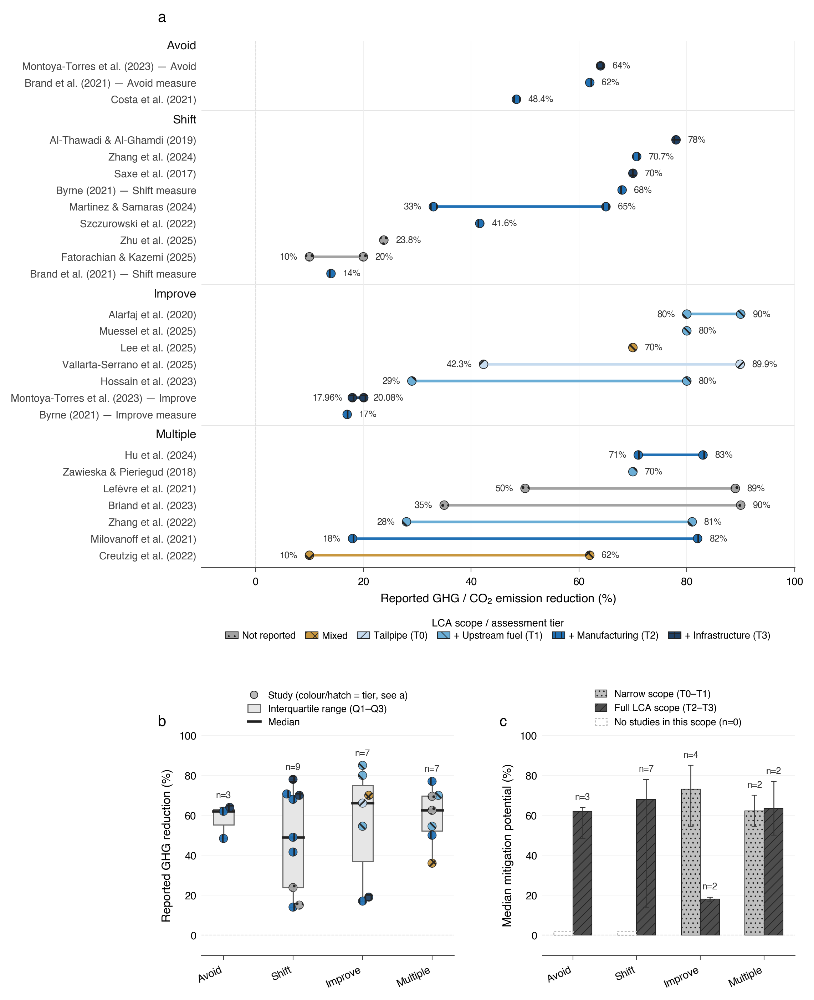

In [33]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import paper_style
from tier_palette import TIERS_ORDERED, TIER_COLORS, HATCH, TIER_LABELS

# ══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL STYLE
# ══════════════════════════════════════════════════════════════════════════════
paper_style.apply()

plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    8,
    "axes.titlesize":    8,
    "xtick.labelsize":   7,
    "ytick.labelsize":   7,
    "legend.fontsize":   6.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "lines.linewidth":   0.8,
    "patch.linewidth":   0.5,
    "mathtext.default":  "regular",
    "svg.fonttype":      "none",
})

# ══════════════════════════════════════════════════════════════════════════════
# 2. DATOS -- tier corregido para que cada estudio use EXACTAMENTE el mismo
#    tier que en la Table S5 (Life-Cycle Component Coding), con independencia
#    de en qué columna ASI (pillar) se esté mostrando ese resultado numérico
#    concreto del estudio. El tier es una propiedad metodológica del ESTUDIO
#    (su frontera de contabilización), no del escenario/medida que reporta,
#    así que un mismo paper que aparece en dos columnas (p. ej. Montoya-Torres
#    en Avoid e Improve, porque reporta escenarios de ambos tipos) debe llevar
#    el mismo tier en las dos filas.
#
#    Cambios respecto a la versión anterior (razón entre paréntesis, con la
#    clave de cita de la Table S5):
#      - Montoya-Torres et al. (2023) [Avoid]:   T2 -> T3  (montoya-torres_towards_2023 = T3)
#      - Montoya-Torres et al. (2023) [Improve]: T2 -> T3  (idem, mismo estudio)
#      - Muessel et al. (2025):                  NR -> T1  (muessel_integrated_2025 = T1)
#      - Vallarta-Serrano et al. (2025):         NR -> T0  (vallarta-serrano_scenarios_2025 = T0)
#      - Hossain et al. (2023):                  T0 -> T1  (hossain_role_2023 = T1)
#      - Hu et al. (2024):                       T1 -> T2  (hu_shared_2024 = T2)
#      - Zawieska & Pieriegud (2018):            NR -> T1  (zawieska_smart_2018 = T1)
#      - Zhang et al. (2022):                    NR -> T1  (zhang_cross-cutting_2022 = T1)
#
#    Sin cambios (ya coincidían con la Table S5):
#      Costa (T2), Brand2021 x2 (T2), Byrne x2 (T2), Saxe (T3),
#      Al-Thawadi (T3), Martinez (T2), Szczurowski (T2), Zhang2024bus (T2),
#      Zhu (NR), Fatorachian (NR), Alarfaj (T1), Lee (Mixed), Milovanoff (T2),
#      Lefèvre (NR), Briand (NR), Creutzig (Mixed).
#
#    Eliminados de la figura: Camilleri et al. (2021) y Yang et al. (2024).
#    Ambos están codificados como N/A en la Table S5 (el resultado del
#    estudio NO es un ejercicio de contabilización de emisiones propio), por
#    lo que no procede mostrarlos con un valor de reducción (%) en un gráfico
#    de estimaciones de mitigación reportadas por los propios estudios.
# ══════════════════════════════════════════════════════════════════════════════

studies = [
    dict(label="Costa et al. (2021)",                    pillar="Avoid",    tier="T2",    low=48.4, high=48.4),
    dict(label="Brand et al. (2021) — Avoid measure",    pillar="Avoid",    tier="T2",    low=62.0, high=62.0),
    dict(label="Montoya-Torres et al. (2023) — Avoid",   pillar="Avoid",    tier="T3",    low=64.0, high=64.0),
    dict(label="Byrne (2021) — Shift measure",           pillar="Shift",    tier="T2",    low=68.0, high=68.0),
    dict(label="Brand et al. (2021) — Shift measure",    pillar="Shift",    tier="T2",    low=14.0, high=14.0),
    dict(label="Saxe et al. (2017)",                      pillar="Shift",    tier="T3",    low=70.0, high=70.0),
    dict(label="Al-Thawadi & Al-Ghamdi (2019)",          pillar="Shift",    tier="T3",    low=78.0, high=78.0),
    dict(label="Martinez & Samaras (2024)",              pillar="Shift",    tier="T2",    low=33.0, high=65.0),
    dict(label="Szczurowski et al. (2022)",              pillar="Shift",    tier="T2",    low=41.6, high=41.6),
    dict(label="Zhang et al. (2024)",                     pillar="Shift",    tier="T2",    low=70.7, high=70.7),
    dict(label="Zhu et al. (2025)",                       pillar="Shift",    tier="NR",    low=23.8, high=23.8),
    dict(label="Fatorachian & Kazemi (2025)",            pillar="Shift",    tier="NR",    low=10.0, high=20.0),
    dict(label="Byrne (2021) — Improve measure",         pillar="Improve",  tier="T2",    low=17.0, high=17.0),
    dict(label="Montoya-Torres et al. (2023) — Improve", pillar="Improve",  tier="T3",    low=17.96, high=20.08),
    dict(label="Alarfaj et al. (2020)",                   pillar="Improve",  tier="T1",    low=80.0, high=90.0),
    dict(label="Muessel et al. (2025)",          pillar="Improve",  tier="T1",    low=80.0, high=80.0),
    dict(label="Vallarta-Serrano et al. (2025)", pillar="Improve",  tier="T0",    low=42.3, high=89.9),
    dict(label="Lee et al. (2025)",              pillar="Improve",  tier="Mixed", low=70.0, high=70.0),
    dict(label="Hossain et al. (2023)",          pillar="Improve",  tier="T1",    low=29.0, high=80.0),
    dict(label="Hu et al. (2024)",               pillar="Multiple", tier="T2",    low=71.0, high=83.0),
    dict(label="Zawieska & Pieriegud (2018)",    pillar="Multiple", tier="T1",    low=70.0, high=70.0),
    dict(label="Milovanoff et al. (2021)",       pillar="Multiple", tier="T2",    low=18.0, high=82.0),
    dict(label="Zhang et al. (2022)",            pillar="Multiple", tier="T1",    low=28.0, high=81.0),
    dict(label="Lefèvre et al. (2021)",          pillar="Multiple", tier="NR",    low=50.0, high=89.0),
    dict(label="Briand et al. (2023)",           pillar="Multiple", tier="NR",    low=35.0, high=90.0),
    dict(label="Creutzig et al. (2022)",         pillar="Multiple", tier="Mixed", low=10.0, high=62.0),
]

PILLAR_ORDER = ["Avoid", "Shift", "Improve", "Multiple"]

# 7.2 in ~= 183 mm (standard Elsevier two-column width). Height trimmed
# from 9.8 to 9.4 in now that panel (a) plots 26 rows instead of 28 (after
# removing the two N/A entries with no study-derived estimate). This is an
# estimate, not a render-checked value -- re-verify margins/whitespace once
# you can preview the actual output on your machine.
# Bottom row: 2 panels (b box+beeswarm by pillar, c narrow/deep-scope bars).
# A third middle panel (pillar x tier T0-T3 disaggregation) was tried and
# then dropped at the user's request -- kept out rather than commented out,
# to avoid dead code drifting out of sync with the rest of the script.
# hspace widened just enough (0.32 -> 0.45) to fit TWO legend rows stacked
# in the gap between (a) and (b)/(c): (a)'s tier legend sits below its
# x-axis label, and (b)/(c) each keep their own legend just above their own
# axes. Kept as tight as possible while still clearing both legend rows.
fig = plt.figure(figsize=(7.2, 9.6), dpi=300)
gs = gridspec.GridSpec(2, 2, height_ratios=[2.4, 1.0],
                       width_ratios=[1.0, 1.0], hspace=0.45, wspace=0.35)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

y_pos, y_labels, is_header, sep_lines = [], [], [], []
ROW_H, GAP_HEADER, GAP_BETWEEN = 0.82, 0.22, 0.55

# Iterate pillars in reverse so that, given matplotlib's bottom-up y-axis,
# the first pillar in PILLAR_ORDER (Avoid) ends up rendered at the TOP of
# the panel and the last (Multiple) at the bottom -- i.e. top-to-bottom
# reading order matches PILLAR_ORDER.
y = 0.0
for gi, pillar in enumerate(reversed(PILLAR_ORDER)):
    group = sorted([s for s in studies if s["pillar"] == pillar],
                   key=lambda s: (s["low"] + s["high"]) / 2)
    for s in group:
        y_pos.append(y); y_labels.append(s["label"]); is_header.append(False)
        s["_y"] = y; y += ROW_H
    y += GAP_HEADER
    y_pos.append(y); y_labels.append(pillar); is_header.append(True)
    if gi < len(PILLAR_ORDER) - 1:
        y += 0.4; sep_lines.append(y); y += GAP_BETWEEN

y_max = y + 0.2

for ys in sep_lines:
    ax_a.axhline(ys, color="#e0e0e0", linewidth=0.4, zorder=0)
ax_a.axvline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

# POINT_SIZE bumped from 30 to 34 so the hatch fill (redundant channel for
# colorblind/greyscale reproduction) stays legible at final print size.
POINT_SIZE, OFFSET_TEXT = 34, 2.2

# paper_style.apply() sets hatch.linewidth=0.45 paper-wide, tuned for the
# large Patch swatches used elsewhere (bars, legend keys) -- confirmed by
# rendering with the real paper_style.py/tier_palette.py that at that
# linewidth the hatch on a ~34pt scatter marker (this panel and the panel-b
# beeswarm) compresses to a near-invisible smudge, even though it reads
# cleanly on the bars/legend. Locally bumping it just for these two
# marker-based blocks keeps the rest of the figure (and every other figure
# that imports paper_style) untouched.
with plt.rc_context({"hatch.linewidth": 1.1}):
    for s in studies:
        yv, tier = s["_y"], s["tier"]
        fc, ht = TIER_COLORS[tier], HATCH[tier]
        if s["low"] != s["high"]:
            ax_a.plot([s["low"], s["high"]], [yv, yv], color=fc, linewidth=1.8,
                      solid_capstyle="round", zorder=2)
            for xv in (s["low"], s["high"]):
                ax_a.scatter(xv, yv, s=POINT_SIZE, marker="o", facecolor=fc,
                             edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
            pad = OFFSET_TEXT if (s["high"] - s["low"]) > 6 else 1.8
            ax_a.text(s["low"] - pad, yv, f"{s['low']:g}%",
                      va="center", ha="right", fontsize=6, color="#333333")
            ax_a.text(s["high"] + pad, yv, f"{s['high']:g}%",
                      va="center", ha="left", fontsize=6, color="#333333")
        else:
            ax_a.scatter(s["low"], yv, s=POINT_SIZE, marker="o", facecolor=fc,
                         edgecolor="#222222", linewidth=0.45, hatch=ht, zorder=3)
            # "upto": True on a study dict marks a reported upper bound (e.g.
            # "up to X%") rather than a single point estimate -- prefixes the
            # label with "≤". No current entry sets this flag; kept as a hook
            # for future studies that report ceilings rather than point values.
            val_str = f"≤ {s['low']:g}%" if s.get("upto") else f"{s['low']:g}%"
            ax_a.text(s["low"] + OFFSET_TEXT, yv, val_str,
                      va="center", ha="left", fontsize=6, color="#333333")

ax_a.set_yticks(y_pos)
tick_labels = ax_a.set_yticklabels(y_labels)
for lbl, hdr in zip(tick_labels, is_header):
    if hdr:
        lbl.set_fontweight("bold"); lbl.set_fontsize(8); lbl.set_color("#111111")
    else:
        lbl.set_fontsize(7); lbl.set_color("#444444")

ax_a.set_xlabel("Reported GHG / CO$_{2}$ emission reduction (%)", fontsize=8, labelpad=4)
ax_a.set_xlim(-10, 100)
ax_a.set_ylim(-0.6, y_max)
ax_a.xaxis.set_major_locator(mticker.MultipleLocator(20))
for spine in ("top", "right", "left"): ax_a.spines[spine].set_visible(False)
ax_a.spines["bottom"].set_color("#444444")
ax_a.xaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_a.yaxis.grid(False)
ax_a.tick_params(axis="y", length=0)
ax_a.tick_params(axis="x", direction="out", color="#444444")

# ══════════════════════════════════════════════════════════════════════════
# Per-panel legends (one legend attached to the panel it explains, instead
# of a single legend for the whole figure sitting far from (a) at the
# bottom). USED_TIERS restricts the swatches to tiers that actually occur
# among the plotted studies -- "N/A" is coded in Table S5 but every N/A
# study was excluded from this figure (its outcome isn't an emissions
# estimate to plot), so an "N/A" swatch here would be a legend entry with
# nothing on the canvas for it to refer to.
# ══════════════════════════════════════════════════════════════════════════
USED_TIERS = [t for t in TIERS_ORDERED if any(s["tier"] == t for s in studies)]

tier_handles = [
    Patch(facecolor=TIER_COLORS[t], edgecolor="#222222",
          hatch=HATCH[t], label=TIER_LABELS[t], linewidth=0.5)
    for t in USED_TIERS
]
# Placed OUTSIDE the axes, below the x-axis (and its "Reported GHG / CO2..."
# label) rather than above the panel: an in-panel "upper right" box at this
# legend's footprint overprinted the Brand et al. (2021) point/label at 62%
# once actually rendered -- there is no corner of (a) that stays empty
# across all rows, since every pillar group has at least one study above
# 60%. A single horizontal row underneath the axis label guarantees zero
# overlap with data regardless of future additions to the study list, and
# keeps the top of the panel free of a title-sized block above "a".
leg_a = ax_a.legend(handles=tier_handles, title="LCA scope / assessment tier",
                     title_fontproperties={"weight": "normal", "size": 7},
                     loc="upper center", bbox_to_anchor=(0.5, -0.09),
                     ncol=6, fontsize=6.5, columnspacing=1.0, handletextpad=0.4,
                     handlelength=1.3, labelspacing=0.3, frameon=False,
                     borderaxespad=0.0)

pillar_data = {p: [(s["low"]+s["high"])/2.0 for s in studies if s["pillar"]==p]
               for p in PILLAR_ORDER}
x_positions = np.arange(len(PILLAR_ORDER))

ax_b.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)


def hex_to_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) / 255 for i in (0, 2, 4))


def beeswarm_offsets(values, y_thresh=4.0, point_d=0.09, max_off=0.35):
    """Desplazamiento horizontal deterministico (no aleatorio) que evita
    solapes entre puntos cercanos en valor -- igual de honesto que un
    jitter, pero reproducible y sin puntos que se pisen entre si.
    y_thresh: distancia en unidades del eje Y (puntos porcentuales) por
    debajo de la cual dos puntos se consideran "visualmente cercanos" y
    necesitan separarse en X (calibrado al diametro real del marcador,
    no al paso de desplazamiento)."""
    order = np.argsort(values)
    offsets = np.zeros(len(values))
    placed = []  # (valor, offset) ya colocados
    for idx in order:
        v = values[idx]
        candidates = [0.0]
        step, k = point_d, 1
        while step * k <= max_off:
            candidates += [step * k, -step * k]
            k += 1
        for off in candidates:
            if all(not (abs(pv - v) < y_thresh and abs(poff - off) < point_d * 0.95)
                   for pv, poff in placed):
                offsets[idx] = off
                placed.append((v, off))
                break
        else:
            offsets[idx] = 0.0
    return offsets


# --- Boxplot real (cuartiles/whiskers autenticos, sin estimar densidad) ---
# Fill/edge/median use neutral greys rather than TIER_COLORS entries: this
# box summarizes ALL studies in the pillar regardless of tier (the beeswarm
# points on top already carry the per-study tier color/hatch), so reusing
# e.g. TIER_COLORS["T1"] for the box edge would wrongly suggest the box
# itself represents "tier T1" specifically.
BOX_W, WHISK_CAP = 0.30, 0.10
BOX_FILL, BOX_EDGE, MEDIAN_COLOR = "#e6e6e6", "#666666", "#222222"
for i, p in enumerate(PILLAR_ORDER):
    vals = np.array(pillar_data[p])
    q1, med, q3 = np.percentile(vals, [25, 50, 75])
    vmin, vmax = vals.min(), vals.max()
    n = len(vals)

    # whiskers (a min/max real: con n tan pequeno, 1.5*IQR no aporta nada
    # que no muestren ya los puntos individuales)
    ax_b.plot([i, i], [vmin, q1], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i, i], [q3, vmax], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmin, vmin], color="#666666", linewidth=0.8, zorder=2)
    ax_b.plot([i - WHISK_CAP/2, i + WHISK_CAP/2], [vmax, vmax], color="#666666", linewidth=0.8, zorder=2)

    # caja (Q1-Q3)
    ax_b.add_patch(plt.Rectangle((i - BOX_W/2, q1), BOX_W, q3 - q1,
                                  facecolor=BOX_FILL, edgecolor=BOX_EDGE,
                                  linewidth=0.7, zorder=3))
    # mediana
    ax_b.plot([i - BOX_W/2, i + BOX_W/2], [med, med],
              color=MEDIAN_COLOR, linewidth=1.6, zorder=4)

    # tamano muestral -- imprescindible con grupos tan pequenos (n=3-9)
    ax_b.text(i, vmax + 4, f"n={n}", ha="center", va="bottom",
              fontsize=6, color="#333333")

# --- Beeswarm: cada estudio como punto individual, sin solapes, coloreado
#     y con hatch por tier (misma codificacion que el resto del paper) ----
# Same local hatch.linewidth bump as panel (a), same reason: legible on the
# bars/legend at 0.45, not on a ~32pt marker.
with plt.rc_context({"hatch.linewidth": 1.1}):
    for i, p in enumerate(PILLAR_ORDER):
        group = [s for s in studies if s["pillar"] == p]
        mids = np.array([(s["low"] + s["high"]) / 2.0 for s in group])
        offs = beeswarm_offsets(mids)
        for s, off in zip(group, offs):
            mid = (s["low"] + s["high"]) / 2.0
            ax_b.scatter(i + off, mid, s=32, marker="o",
                         facecolor=TIER_COLORS[s["tier"]], edgecolor="#222222",
                         linewidth=0.35, hatch=HATCH[s["tier"]], zorder=5, alpha=0.95)


ax_b.set_xticks(x_positions)
ax_b.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold",
                      rotation=25, ha="right")
ax_b.set_ylabel("Reported GHG reduction (%)", fontsize=8)
ax_b.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_b.spines[spine].set_visible(False)
ax_b.spines["bottom"].set_color("#444444")
ax_b.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_b.xaxis.grid(False)
ax_b.tick_params(axis="y", length=0)
ax_b.tick_params(axis="x", direction="out", color="#444444")
ax_b.yaxis.set_major_locator(mticker.MultipleLocator(20))

# Panel (b)'s own legend: explains the two elements unique to THIS panel
# (the pooled box and its median) plus a one-line pointer back to (a) for
# the point colour/hatch code, rather than re-drawing all 6 tier swatches a
# second time -- (a) and (b) share the exact same encoding, so repeating it
# in full here would be redundant ink, not clarity.
box_handles = [
    Line2D([0], [0], marker="o", linestyle="none", markersize=5,
           markerfacecolor="#bcbcbc", markeredgecolor="#222222",
           markeredgewidth=0.5, label="Study (colour/hatch = tier, see a)"),
    Patch(facecolor=BOX_FILL, edgecolor=BOX_EDGE, linewidth=0.7,
          label="Interquartile range (Q1–Q3)"),
    Line2D([0], [0], color=MEDIAN_COLOR, linewidth=1.6, label="Median"),
]
ax_b.legend(handles=box_handles, frameon=False, loc="lower center",
            bbox_to_anchor=(0.5, 1.02), ncol=1, fontsize=6.5,
            handlelength=1.3, handleheight=0.9, borderaxespad=0.0,
            labelspacing=0.4)

NARROW_TIERS, DEEP_TIERS = {"T0", "T1"}, {"T2", "T3"}

# Build the two aggregates from real data only. Where a pillar has zero
# studies in a scope group (this happens for Avoid and Shift, which in this
# corpus contain no T0/T1 studies at all), we do NOT substitute a
# placeholder value -- that would be fabricating a data point. The slot is
# still drawn (an empty, dashed, zero-ish-height outline -- see EMPTY_H
# below) so the two-bar grouping stays visually complete across all four
# pillars, but with no text and no invented magnitude: the absence is the
# finding (every classifiable Avoid/Shift study in this review applies at
# least manufacturing-inclusive, T2+, accounting).
narrow_x, narrow_meds, narrow_lo, narrow_hi, narrow_n = [], [], [], [], []
deep_x,   deep_meds,   deep_lo,   deep_hi,   deep_n   = [], [], [], [], []
missing_narrow_x, missing_deep_x = [], []

x, w = np.arange(len(PILLAR_ORDER)), 0.30

for i, pillar in enumerate(PILLAR_ORDER):
    group = [s for s in studies if s["pillar"] == pillar]
    n_vals = [(s["low"] + s["high"]) / 2 for s in group if s["tier"] in NARROW_TIERS]
    d_vals = [(s["low"] + s["high"]) / 2 for s in group if s["tier"] in DEEP_TIERS]

    if n_vals:
        m = float(np.median(n_vals))
        narrow_x.append(i - w / 2); narrow_meds.append(m)
        narrow_lo.append(max(0.0, m - np.min(n_vals)))
        narrow_hi.append(max(0.0, np.max(n_vals) - m))
        narrow_n.append(len(n_vals))
    else:
        missing_narrow_x.append(i)

    if d_vals:
        m = float(np.median(d_vals))
        deep_x.append(i + w / 2); deep_meds.append(m)
        deep_lo.append(max(0.0, m - np.min(d_vals)))
        deep_hi.append(max(0.0, np.max(d_vals) - m))
        deep_n.append(len(d_vals))
    else:
        missing_deep_x.append(i)

ax_c.axhline(0, color="#999999", linewidth=0.5, linestyle="--", zorder=1)

# Neutral greys, deliberately decoupled from TIER_COLORS/HATCH: each bar
# here aggregates two tiers (T0+T1, T2+T3), so reusing e.g. TIER_COLORS
# ["T0"] would make readers conflate "narrow scope" with "the individual T0
# tier" shown with that same color in the shared legend for panels (a)/(b).
NARROW_COLOR, DEEP_COLOR = "#bfbfbf", "#4d4d4d"

if narrow_x:
    ax_c.bar(narrow_x, narrow_meds, w, color=NARROW_COLOR, edgecolor="#222222",
             linewidth=0.5, hatch="....", yerr=[narrow_lo, narrow_hi], capsize=2,
             error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
             label="Narrow scope (T0–T1)", zorder=2)
    for xi, m, hi, n in zip(narrow_x, narrow_meds, narrow_hi, narrow_n):
        ax_c.text(xi, m + hi + 3, f"n={n}", ha="center", va="bottom",
                  fontsize=6, color="#333333")

if deep_x:
    ax_c.bar(deep_x, deep_meds, w, color=DEEP_COLOR, edgecolor="#222222",
             linewidth=0.5, hatch="////", yerr=[deep_lo, deep_hi], capsize=2,
             error_kw=dict(ecolor="#333333", linewidth=0.6, capthick=0.5),
             label="Full LCA scope (T2–T3)", zorder=2)
    for xi, m, hi, n in zip(deep_x, deep_meds, deep_hi, deep_n):
        ax_c.text(xi, m + hi + 3, f"n={n}", ha="center", va="bottom",
                  fontsize=6, color="#333333")

# Empty slots: a purely visual, dashed, unfilled placeholder bar at a
# nominal small height (EMPTY_H) -- NOT a real value, just enough for the
# outline to read as "a slot exists here and it's empty" instead of a
# fabricated magnitude. No text label, per explicit request: the absence of
# a filled/colored bar already communicates n=0 unambiguously alongside the
# real bars in the same cluster.
EMPTY_H = 2.0
for xi in missing_narrow_x:
    ax_c.bar(xi - w / 2, EMPTY_H, w, facecolor="none", edgecolor="#bbbbbb",
             linewidth=0.7, linestyle=(0, (2, 1.5)), zorder=2)
for xi in missing_deep_x:
    ax_c.bar(xi + w / 2, EMPTY_H, w, facecolor="none", edgecolor="#bbbbbb",
             linewidth=0.7, linestyle=(0, (2, 1.5)), zorder=2)

ax_c.set_xticks(x)
ax_c.set_xticklabels(PILLAR_ORDER, fontsize=7, fontweight="bold",
                      rotation=25, ha="right")
ax_c.set_ylabel("Median mitigation potential (%)", fontsize=8)
ax_c.set_ylim(-10, 100)
for spine in ("top", "right", "left"): ax_c.spines[spine].set_visible(False)
ax_c.spines["bottom"].set_color("#444444")
ax_c.yaxis.grid(True, color="#eeeeee", linewidth=0.4, zorder=0)
ax_c.xaxis.grid(False)
ax_c.tick_params(axis="y", length=0)
ax_c.tick_params(axis="x", direction="out", color="#444444")
ax_c.yaxis.set_major_locator(mticker.MultipleLocator(20))
# Explicit handles (rather than auto-collecting the two ax_c.bar(..., label=
# ...) calls) so the empty-slot placeholder -- which deliberately carries no
# "label=" kwarg on the bars themselves, since it is drawn once per missing
# pillar rather than once per series -- gets its own legend entry too.
# Avoid/Shift's dashed, unfilled bars in this panel are the visual answer to
# "were there any T0-T1 studies here?"; without this entry a reader could
# mistake them for a rendering artefact instead of a deliberate n=0 marker.
scope_handles = [
    Patch(facecolor=NARROW_COLOR, edgecolor="#222222", hatch="....",
          linewidth=0.5, label="Narrow scope (T0–T1)"),
    Patch(facecolor=DEEP_COLOR, edgecolor="#222222", hatch="////",
          linewidth=0.5, label="Full LCA scope (T2–T3)"),
    Patch(facecolor="none", edgecolor="#bbbbbb", linewidth=0.7,
          linestyle=(0, (2, 1.5)), label="No studies in this scope (n=0)"),
]
# Placed above the axes (bbox y > 1), not in a corner inside the plot area:
# with ylim capped at 100 and the Improve narrow-scope bar reaching ~85 with
# its error bar, an in-panel "upper left"/"upper right" legend collides with
# either the bar or its n= label. This also keeps it visually distinct from
# panel (c)'s letter tag, which sits further left at the same height.
ax_c.legend(handles=scope_handles, frameon=False, loc="lower center",
            bbox_to_anchor=(0.5, 1.02), ncol=1, fontsize=6.5,
            handlelength=1.2, handleheight=0.8, borderaxespad=0.0)

for ax, letter, x_off in [(ax_a, "a", -0.06), (ax_b, "b", -0.14),
                          (ax_c, "c", -0.14)]:
    ax.text(x_off, 1.03, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

# No fig-level legend anymore: (a) carries the tier code, (b) explains its
# box/median, (c) explains its narrow/deep scope aggregation -- each panel
# is now self-contained, so nothing needs to live outside the axes grid at
# the bottom of the whole figure. Margin shrunk back down accordingly (only
# the rotated b/c tick labels need room below those two axes now).
plt.subplots_adjust(bottom=0.09, top=0.98, left=0.20, right=0.97,
                    hspace=0.30, wspace=0.30)

fig.savefig("fig_combined_nature_boxswarm.pdf", format="pdf", bbox_inches="tight", dpi=300)
fig.savefig("fig_combined_nature_boxswarm.png", format="png", bbox_inches="tight", dpi=300)
print("✓ Saved: fig_combined_nature_boxswarm.pdf / .png (estilo unificado: paper_style + tier_palette)")